# EDA


# Introducción e índice

## 1. Objetivo

> Identificar perfiles de clientes que abandonaron el paquete Premium a partir de su tenencia, uso y evolución de productos; cuantificar el valor económico asociado a cada perfil; y descubrir señales tempranas que puedan transformarse después en features predictivas.

No buscamos solamente clusters. Buscamos perfiles que sean:

- Reales y suficientemente numerosos.
- Estables entre períodos.
- Interpretables en términos bancarios.
- Económicamente relevantes.
- Asociables con una acción concreta.

## 2. Diseño central

Construiremos dos bases diferentes para no mezclar explicación con predicción:

| Base | Para qué sirve | Información permitida |
|---|---|---|
| `eventos_baja` | Perfilar a quienes abandonaron | Historia anterior hasta el último mes activo |
| `prediccion_t2` | Crear features para el modelo futuro | Solamente información disponible dos meses antes |

Esto evita usar información cercana a la baja para crear una feature que después pretendamos utilizar con dos meses de anticipación.

## 3. Etapas


### Etapa 1 — Construcción de la población de bajas

Reconstruir la presencia mensual de cada cliente y detectar:

- Primera ausencia observada.
- Último mes activo.
- Clientes que permanecen.
- Clientes que desaparecen y regresan.
- Bajas que no pueden confirmarse por terminar el dataset.
- Posibles eventos múltiples por cliente.

Crear una fila por evento de baja, sin duplicar al mismo abandono mediante `BAJA+1` y `BAJA+2`.

**Entregable:** tabla `eventos_baja` y diagrama de cómo se construyó.

**Criterio para avanzar:** poder explicar y reproducir exactamente cuántas bajas hay, en qué meses y qué tratamiento reciben intermitentes y casos censurados.

---

### Etapa 2 — Auditoría y EDA orientado por productos

Primero auditaremos calidad y semántica:

- Nulos versus ausencia de producto.
- Variables administrativas sospechosas.
- Cambios de definición o escala entre meses.
- Supuesto de que toda la base corresponde a Premium.
- Diferencias entre cohortes mensuales.

Después analizaremos cuatro dimensiones:

1. Tenencia de productos.
2. Intensidad de uso.
3. Evolución anterior a la baja.
4. Rentabilidad y valor.

El EDA comparará:

- Bajas contra clientes que continúan, dentro de meses comparables.
- Diferentes trayectorias entre los propios clientes que abandonan.
- Bajas VIP contra no VIP.
- Perfiles de alto y bajo valor económico.

**Entregable:** conjunto pequeño de tablas y gráficos que respondan preguntas concretas, más una lista de hipótesis confirmadas, rechazadas y pendientes.

**Criterio para avanzar:** tener entre tres y seis patrones de comportamiento respaldados por datos, no sólo intuiciones.

---

### Etapa 3 — Feature engineering de comportamiento

Construiremos features interpretables por familia de productos:

- **Tenencia:** tiene tarjeta, préstamo, payroll, inversión, seguro.
- **Profundidad:** cantidad de productos y familias activas.
- **Intensidad:** consumos, transacciones, saldos y utilización.
- **Trayectoria:** deltas, pendientes, caídas relativas y meses de inactividad.
- **Eventos:** perdió payroll, canceló crédito, dejó de invertir, dejó de consumir.
- **Valor:** rentabilidad reciente, rentabilidad anual y valor aproximado en riesgo.

No generaremos cientos de variables indiscriminadamente. Cada feature tendrá:

- Hipótesis.
- Interpretación.
- Momento en que está disponible.
- Riesgo de leakage.
- Uso descriptivo, predictivo o ambos.

**Entregable:** diccionario de features y tabla analítica por evento de baja.

**Criterio para avanzar:** cada variable utilizada en clustering debe poder explicarse comercialmente y no depender del futuro.

---

### Etapa 4 — Segmentación

Clusterizaremos solamente los eventos de baja. Los clientes que continúan funcionarán como referencia, no como miembros de los clusters.

Compararemos:

1. Un método sencillo e interpretable como referencia.
2. El método basado en Random Forest visto en clase, pero corrigiendo sus problemas metodológicos.

Probaremos distintas cantidades de clusters, sin fijar de antemano que deben ser cinco.

**Entregable:** soluciones candidatas de segmentación.

**Criterios de selección:**

- Estabilidad ante semillas y remuestreo de clientes.
- Consistencia entre cohortes mensuales.
- Tamaño suficiente.
- Diferencias sustantivas, no sólo significativas.
- Interpretación clara.
- Acción comercial distinta para cada perfil.

---

### Etapa 5 — Validación y descripción de perfiles

Cada cluster se convertirá en una ficha:

- Tamaño absoluto y porcentaje de bajas.
- Productos característicos.
- Trayectoria anterior al abandono.
- Diferencias contra clientes que continúan.
- Valor económico.
- Nivel de evidencia.
- Limitaciones.

Un cluster que no pueda resumirse en una frase de comportamiento no será aceptado como perfil.

**Entregable:** tres o cuatro perfiles defendibles.

---

### Etapa 6 — Priorización económica

Para cada perfil calcularemos:

- Rentabilidad perdida.
- Valor aproximado del cliente.
- Costo del estímulo.
- Efectividad mínima necesaria para que la acción alcance el punto de equilibrio.

No afirmaremos que un cliente es “retenible” sin datos de campañas. Diremos qué efectividad debería conseguir una intervención para ser rentable.

El resultado será una matriz como:

| Valor en riesgo | Acción plausible | Decisión |
|---|---|---|
| Alto | Clara y de bajo costo | Retención prioritaria |
| Alto | Compleja o incierta | Tratamiento especializado |
| Bajo | Acción barata | Retención automatizada |
| Bajo | Acción costosa | No priorizar estímulo |

**Entregable:** priorización de perfiles y justificación económica.

---

### Etapa 7 — Features para el modelo posterior

Tomaremos las señales encontradas y las recalcularemos estrictamente en `t−2`.

Por ejemplo, si detectamos que perder el payroll precede a la baja, construiremos una feature que sólo utilice información conocida dos meses antes. Su aporte predictivo se evaluará posteriormente contra un baseline y validación temporal.

**Entregable:** lista priorizada de features candidatas para la competencia.

Esta etapa produce hipótesis predictivas; no implica construir ahora todo el modelo.

---

### Etapa 8 — Traducción para Miranda

El video contendrá únicamente:

1. Magnitud y valor del problema.
2. Tres o cuatro perfiles.
3. Evidencia principal de cada perfil.
4. Acción propuesta.
5. Priorización económica.
6. Próximo paso experimental.

No aparecerán Random Forest, KMeans, métricas internas ni detalles de implementación.

## 4. Qué tomamos de la guía de Claude

Conservamos:

- Hipótesis por familias de productos.
- Atención a nulos, leakage y temporalidad.
- Feature engineering temporal.
- Evaluación con varias semillas.
- Bitácora y reproducibilidad.
- Orientación hacia acciones comerciales.

Corregimos:

- La duplicación entre `BAJA+1` y `BAJA+2`.
- El uso de toda la historia sin alinearla con la baja.
- El clustering basado solamente en el último split del árbol.
- La validación por filas cliente-mes.
- La inferencia causal sobre las acciones.
- El uso de información futura mediante `lead()`.

Postergamos para la competencia:

- Optuna.
- Optimización completa de ganancia.
- Adversarial validation.
- Generación masiva de cientos de features.
- Desarrollo integral de LightGBM.

# Etapa 1

In [1]:
%pip install duckdb jupysql duckdb-engine pandas

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import duckdb
import pandas as pd
from pathlib import Path

%load_ext sql

%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False

%sql duckdb:///:memory:

In [3]:
#Ubicación del dataset:
dataset_path = Path(
    "/Users/manuelmarasco/Library/CloudStorage/"
    "GoogleDrive-hola@manuelmarasco.com/"
    "Mi unidad/DMEyF/2026/notebooks/data/"
)

dataset_file = "competencia_01_crudo.csv"

archivo_crudo = str(dataset_path / dataset_file)

In [4]:
%%sql
-- Cargo el dataset como una tabla --


CREATE OR REPLACE TABLE competencia_01_crudo AS
SELECT *
FROM read_csv_auto(
    '{{archivo_crudo}}',
    sample_size = -1
);

,Success


In [5]:
%%sql

SELECT
    (
        SELECT data_type
        FROM duckdb_columns()
        WHERE table_name = 'competencia_01_crudo'
          AND column_name = 'numero_de_cliente'
    ) AS tipo_actual,

    COUNT(*) FILTER (
        WHERE numero_de_cliente IS NULL
    ) AS ids_nulos,

    COUNT(*) FILTER (
        WHERE numero_de_cliente <> FLOOR(numero_de_cliente)
    ) AS ids_con_decimales,

    COUNT(*) FILTER (
        WHERE ABS(numero_de_cliente) > 9007199254740991
    ) AS ids_fuera_rango_exacto_double,

    MIN(numero_de_cliente) AS id_minimo,
    MAX(numero_de_cliente) AS id_maximo

FROM competencia_01_crudo;

,tipo_actual,ids_nulos,ids_con_decimales,ids_fuera_rango_exacto_double,id_minimo,id_maximo
0,DOUBLE,0,0,0,12159854.0,78254956.0


1. Definición del CTE (cliente_mes)
With crea una tabla temporal que agrupa la información por numero_de_cliente y foto_mes, contando cuántas filas (cantidad) existen para cada combinación única. Si un cliente tiene 1 sola fila en un mes dado, cantidad será 1; si tiene registros duplicados, será mayor a 1.
2. Consulta principal y métricas
Calcula cinco indicadores clave a partir del CTE y de la tabla original:
⚬	filas_originales: Total de registros que existen en la tabla competencia_01_crudo sin ningún tipo de filtro.
⚬	pares_cliente_mes: Cantidad de combinaciones únicas entre cliente y mes que se encontraron.
⚬	clientes: Cantidad de clientes distintos presentes en toda la base.
⚬	meses: Cantidad de periodos o meses distintos evaluados.
⚬	duplicados_cliente_mes: Suma la cantidad de filas sobrantes por combinación. Si un cliente tiene 3 registros en un mismo mes (cantidad = 3), la fórmula hace ‭$3 - 1 = 2$‬‭‬‭‬, sumando 2 al total de duplicados.
¿Para qué sirve en la práctica?
Permite saber si la clave primaria (numero_de_cliente, foto_mes) se cumple. Si el campo duplicados_cliente_mes da como resultado 0, significa que no hay filas repetidas para ningún cliente en un mismo mes. Si da mayor a 0, indica exactamente cuántas filas de más hay que depurar antes de procesar los datos.

In [6]:
%%sql

WITH cliente_mes AS (
    SELECT
        numero_de_cliente,
        foto_mes,
        COUNT(*) AS cantidad
    FROM competencia_01_crudo
    GROUP BY numero_de_cliente, foto_mes
)

SELECT
    (SELECT COUNT(*) FROM competencia_01_crudo) AS filas_originales,
    COUNT(*) AS pares_cliente_mes,
    COUNT(DISTINCT numero_de_cliente) AS clientes,
    COUNT(DISTINCT foto_mes) AS meses,
    SUM(
        CASE
            WHEN cantidad > 1 THEN cantidad - 1
            ELSE 0
        END
    ) AS duplicados_cliente_mes
FROM cliente_mes;

,filas_originales,pares_cliente_mes,clientes,meses,duplicados_cliente_mes
0,983061,983061,169727,6,0.0


#Bloque 1B — Tamaño de cada foto mensual

In [7]:
%%sql

SELECT
    foto_mes,
    COUNT(*) AS filas,
    COUNT(DISTINCT numero_de_cliente) AS clientes
FROM competencia_01_crudo
GROUP BY foto_mes
ORDER BY foto_mes;

,foto_mes,filas,clientes
0,202103,162900,162900
1,202104,163284,163284
2,202105,163768,163768
3,202106,164114,164114
4,202107,164348,164348
5,202108,164647,164647


Bloque 1C — Cantidad de meses observados por cliente

In [8]:
%%sql
WITH historia_cliente AS (
    SELECT
        numero_de_cliente,
        COUNT(DISTINCT foto_mes) AS meses_presente
    FROM competencia_01_crudo
    GROUP BY numero_de_cliente
)

SELECT
    meses_presente,
    COUNT(*) AS clientes,
    ROUND(
        100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
        2
    ) AS porcentaje_clientes
FROM historia_cliente
GROUP BY meses_presente
ORDER BY meses_presente;

,meses_presente,clientes,porcentaje_clientes
0,1,2425,1.43
1,2,2061,1.21
2,3,2611,1.54
3,4,2306,1.36
4,5,2487,1.47
5,6,157837,92.99


Interpretación:
- Hay 169.727 clientes distintos.
- 157.837 estuvieron presentes los seis meses.
- 11.890, el 7,01%, faltaron al menos un mes.
- 2.425 clientes aparecen una sola vez en toda la base.
Pero todavía no podemos decir que esos 11.890 se dieron de baja. Un cliente presente tres meses podría:
- Haber estado al principio y después irse: 111000.
- Haber ingresado tarde: 000111.
- Entrar y salir: 010100.

In [9]:
%%sql

WITH meses AS (
    SELECT DISTINCT foto_mes
    FROM competencia_01_crudo
),

clientes AS (
    SELECT DISTINCT numero_de_cliente
    FROM competencia_01_crudo
),

panel AS (
    SELECT
        c.numero_de_cliente,
        m.foto_mes,
        CASE
            WHEN d.numero_de_cliente IS NULL THEN 0
            ELSE 1
        END AS presente
    FROM clientes AS c
    CROSS JOIN meses AS m
    LEFT JOIN competencia_01_crudo AS d
        ON c.numero_de_cliente = d.numero_de_cliente
       AND m.foto_mes = d.foto_mes
),

patrones AS (
    SELECT
        numero_de_cliente,
        STRING_AGG(
            CAST(presente AS VARCHAR),
            '' ORDER BY foto_mes
        ) AS patron_presencia
    FROM panel
    GROUP BY numero_de_cliente
),

distribucion AS (
    SELECT
        patron_presencia,
        COUNT(*) AS clientes
    FROM patrones
    GROUP BY patron_presencia
)

SELECT
    patron_presencia,
    clientes,
    ROUND(
        100.0 * clientes / SUM(clientes) OVER (),
        3
    ) AS porcentaje_clientes
FROM distribucion
ORDER BY clientes DESC;

,patron_presencia,clientes,porcentaje_clientes
0,111111,157837,92.995
1,000111,1475,0.869
2,001111,1436,0.846
3,000001,1395,0.822
4,011111,1384,0.815
5,111000,1129,0.665
6,000011,1097,0.646
7,111110,1088,0.641
8,100000,1013,0.597
9,110000,951,0.560


Cada posición representa un mes, desde marzo hasta agosto:
- 111111: presente siempre.
- 111000: estuvo tres meses y después desapareció.
- 000111: ingresó en junio y continuó.
- 110111: faltó un mes y regresó.


El patrón es simplemente una forma corta de escribir en qué meses apareció un cliente.
Tenemos seis meses:
Posición	1	2	3	4	5	6
Mes	Marzo	Abril	Mayo	Junio	Julio	Agosto


Para cada cliente ponemos:
- 1 si aparece en la base ese mes.
- 0 si no aparece.
Ejemplo 1
Marzo	Abril	Mayo	Junio	Julio	Agosto
1	1	1	0	0	0


Juntando los números queda:
111000
Significa: estuvo en marzo, abril y mayo; desde junio dejó de aparecer.
Ejemplo 2
Marzo	Abril	Mayo	Junio	Julio	Agosto
0	0	0	1	1	1


El patrón es:
000111
Significa: no aparecía al comienzo y empezó a aparecer en junio.
Ejemplo 3
Marzo	Abril	Mayo	Junio	Julio	Agosto
1	1	0	1	1	1


El patrón es:
110111
Significa: estuvo en marzo y abril, faltó en mayo y reapareció en junio.

- 157.837 clientes (92,995%) aparecen los seis meses.
- 6.787 ingresan durante la ventana y continúan hasta agosto.
- 5.080 terminan con una ausencia y no regresan dentro de la ventana.
- 23 desaparecen y posteriormente reaparecen.
Dentro de los 5.080 que terminan ausentes, hay 1.103 cuyo único mes ausente es agosto. Son patrones como 111110. Sabemos que desaparecieron en agosto, pero no podemos observar septiembre para comprobar si la ausencia fue definitiva: son casos con censura a derecha.
Hay 15 clientes con un único mes intermedio de ausencia, correspondientes a:
- 110111: 7.
- 111011: 4.
- 111101: 3.
- 101111: 1.

In [10]:
%%sql

CREATE OR REPLACE TABLE panel_presencia AS

WITH meses AS (
    SELECT DISTINCT foto_mes
    FROM competencia_01_crudo
),

clientes AS (
    SELECT DISTINCT numero_de_cliente
    FROM competencia_01_crudo
)

SELECT
    c.numero_de_cliente,
    m.foto_mes,
    CASE
        WHEN d.numero_de_cliente IS NULL THEN 0
        ELSE 1
    END AS presente
FROM clientes AS c
CROSS JOIN meses AS m
LEFT JOIN competencia_01_crudo AS d
    ON c.numero_de_cliente = d.numero_de_cliente
   AND m.foto_mes = d.foto_mes
ORDER BY c.numero_de_cliente, m.foto_mes;

,Success


In [11]:
%%sql

CREATE OR REPLACE TABLE eventos_baja AS

WITH secuencia AS (
    SELECT
        numero_de_cliente,
        foto_mes,
        presente,

        LEAD(foto_mes, 1) OVER (
            PARTITION BY numero_de_cliente
            ORDER BY foto_mes
        ) AS primer_mes_ausente,

        LEAD(presente, 1) OVER (
            PARTITION BY numero_de_cliente
            ORDER BY foto_mes
        ) AS presente_mes_siguiente,

        COALESCE(
            MAX(presente) OVER (
                PARTITION BY numero_de_cliente
                ORDER BY foto_mes
                ROWS BETWEEN 2 FOLLOWING AND UNBOUNDED FOLLOWING
            ),
            0
        ) AS vuelve_mas_adelante,

        COUNT(*) OVER (
            PARTITION BY numero_de_cliente
            ORDER BY foto_mes
            ROWS BETWEEN 1 FOLLOWING AND UNBOUNDED FOLLOWING
        ) AS meses_observables_despues

    FROM panel_presencia
),

transiciones AS (
    SELECT
        numero_de_cliente,
        foto_mes AS ultimo_mes_activo,
        primer_mes_ausente,
        vuelve_mas_adelante,
        meses_observables_despues
    FROM secuencia
    WHERE presente = 1
      AND presente_mes_siguiente = 0
)

SELECT
    numero_de_cliente,
    ultimo_mes_activo,
    primer_mes_ausente,

    ROW_NUMBER() OVER (
        PARTITION BY numero_de_cliente
        ORDER BY ultimo_mes_activo
    ) AS numero_evento,

    vuelve_mas_adelante,
    meses_observables_despues,

    CASE
        WHEN vuelve_mas_adelante = 1
            THEN 'intermitente'

        WHEN meses_observables_despues = 1
            THEN 'salida_censurada_derecha'

        ELSE 'salida_sin_retorno_observado'
    END AS tipo_evento

FROM transiciones;

,Success


In [12]:
%%sql

SELECT
    tipo_evento,
    COUNT(*) AS eventos,
    COUNT(DISTINCT numero_de_cliente) AS clientes
FROM eventos_baja
GROUP BY tipo_evento
ORDER BY eventos DESC;

,tipo_evento,eventos,clientes
0,salida_sin_retorno_observado,3977,3977
1,salida_censurada_derecha,1103,1103
2,intermitente,23,23


- 3.977: salida observada y al menos dos meses posteriores sin retorno.
- 1.103: desaparecen en el último mes; podrían ser bajas reales, pero no vemos septiembre.
- 23: desaparecen y regresan.


Para Miranda utilizaremos como población principal los 3.977 clientes con salida estricta: observamos su ausencia y contamos con al menos dos meses posteriores sin retorno. Los 1.103 casos censurados se incorporarán posteriormente en un análisis de sensibilidad, formando una población ampliada de 5.080 clientes. Los 23 intermitentes se analizarán por separado.


Se trabajará con tres cohortes:
Cohorte	Clientes	Uso
Estricta	3.977	Salida sin retorno observado y con al menos dos meses de seguimiento
Ampliada	5.080	Cohorte estricta + 1.103 salidas censuradas
Intermitentes	23	Análisis separado de clientes que desaparecen y regresan


Análisis con y sin censura
Primero se analizará los 3.977 de la cohorte estricta. Después se repetirá los resultados principales incluyendo los 1.103 censurados.
Se comparará:
- Distribución de productos.
- Intensidad de uso.
- Rentabilidad.
- Trayectorias anteriores.
- Tamaño y características de los clusters.
- Proporción de clientes en cada perfil.
Para el clustering, lo más sólido será:
1. Construir los perfiles con los 3.977.
2. Repetir el clustering con los 5.080.
3. Comparar si los clientes compartidos mantienen perfiles parecidos.
4. Ver si los 1.103 censurados crean un perfil artificial o se integran en los existentes.
Si los resultados cambian poco, podremos decir:
Los perfiles son robustos a incluir las bajas del último mes.

Si cambian mucho, la censura es parte del resultado y habrá que mostrarlo.
Apartado de intermitentes


Los 23 intermitentes no entrarán en el clustering principal, pero sí tendrán un análisis propio:
- Qué productos tenían.
- Cómo venían usando el banco antes de desaparecer.
- Cuánto tiempo estuvieron ausentes.
- Qué cambió cuando regresaron.
- A cuál de los perfiles de baja se parecen.
- Si eran clientes económicamente valiosos.
Por ser sólo 23, no se harán afirmaciones estadísticas fuertes. Se tratarán como casos observados de abandono y regreso, no como prueba de que una acción comercial los recuperó.

Introducimos la clase ternaria (uploaded zulip) y comparo con los resultados anteriores. 

In [13]:
%%sql
create or replace table competencia_01 as
with periodos as (select distinct foto_mes from competencia_01_crudo),
clientes as (select distinct numero_de_cliente from competencia_01_crudo),
todo as (select numero_de_cliente, foto_mes from clientes cross join periodos),

clasificador as (
select
c.*,
if(c.numero_de_cliente is null, 0, 1) as mes_0,
case
when lead(mes_0, 1) over (partition by t.numero_de_cliente order by t.foto_mes) = 0 then 'BAJA+1'
when lead(mes_0, 1) over (partition by t.numero_de_cliente order by t.foto_mes) = 1 and lead(mes_0, 2) over (partition by t.numero_de_cliente order by t.foto_mes) = 0 then 'BAJA+2'
when lead(mes_0, 1) over (partition by t.numero_de_cliente order by t.foto_mes) = 1 and lead(mes_0, 2) over (partition by t.numero_de_cliente order by t.foto_mes) = 1 then 'CONTINUA'
else null
end as clase_ternaria
from todo t
left join competencia_01_crudo c using (numero_de_cliente, foto_mes)
)

select *
from clasificador
where mes_0 = 1
order by foto_mes

,Success


In [14]:
%%sql

SELECT
    foto_mes,
    COALESCE(clase_ternaria, 'SIN_ETIQUETA') AS clase,
    COUNT(*) AS clientes
FROM competencia_01
GROUP BY foto_mes, clase
ORDER BY foto_mes, clase;

,foto_mes,clase,clientes
0,202103,BAJA+1,1019
1,202103,BAJA+2,960
2,202103,CONTINUA,160921
3,202104,BAJA+1,964
4,202104,BAJA+2,1139
5,202104,CONTINUA,161181
6,202105,BAJA+1,1143
7,202105,BAJA+2,870
8,202105,CONTINUA,161755
9,202106,BAJA+1,874


Por qué aparecen SIN_ETIQUETA
- En julio, sólo podemos identificar BAJA+1: vemos si está o no en agosto.
- No podemos distinguir BAJA+2 de CONTINUA porque necesitaríamos septiembre.
- En agosto no podemos construir ninguna clase porque no tenemos septiembre.

In [15]:
%%sql

WITH marcas_cliente AS (
    SELECT
        numero_de_cliente,

        MAX(
            CASE
                WHEN clase_ternaria = 'BAJA+1' THEN 1
                ELSE 0
            END
        ) AS tiene_baja_1,

        MAX(
            CASE
                WHEN clase_ternaria = 'BAJA+2' THEN 1
                ELSE 0
            END
        ) AS tiene_baja_2

    FROM competencia_01
    GROUP BY numero_de_cliente
)

SELECT
    tiene_baja_1,
    tiene_baja_2,
    COUNT(*) AS clientes
FROM marcas_cliente
GROUP BY tiene_baja_1, tiene_baja_2
ORDER BY tiene_baja_1, tiene_baja_2;

,tiene_baja_1,tiene_baja_2,clientes
0,0,0,164624
1,1,0,1036
2,1,1,4067


clase_ternaria clasifica una fila cliente-mes, no clasifica al cliente para siempre.

Supongamos este cliente:
Mes	Presente	Clase
Marzo	1	BAJA+2
Abril	1	BAJA+1
Mayo	0	No tiene fila

En marzo faltan dos meses para su desaparición:
- Está en marzo.
- Sigue en abril.
- Desaparece en mayo.
- Por eso marzo es BAJA+2.
Cuando llega abril, falta solamente un mes:
- Está en abril.
- Desaparece en mayo.
- Por eso abril es BAJA+1.


Avance temporal BAJA+2 -> BAJA+1 -> ausencia. ¿Entonces quiénes son los 1.036 que sólo tienen BAJA+1?
Son clientes para los que no existe una fotografía válida dos meses antes. También puede suceder con clientes que ingresaron durante la ventana, estuvieron un solo mes y volvieron a desaparecer.

Hay cero clientes que tengan BAJA+2 sin tener también BAJA+1 -> O sea que BAJA+2 es un subconjunto de BAJA+1

En notación de conjuntos:
- \(A\): clientes que alguna vez fueron BAJA+1.
- \(B\): clientes que alguna vez fueron BAJA+2.
Los resultados dicen:
- \(B \cap A = 4.067\).
- \(B - A = 0\).
Por lo tanto:
\[
B \subseteq A
\]Los 1.036 que sólo tienen BAJA+1 son bajas para las que no tenemos una fotografía válida dos meses antes. Por eso BAJA+1 contiene todos los eventos observados y BAJA+2 sólo la parte con suficiente historia previa.

Población para el análisis para Miranda

In [16]:
%%sql

CREATE OR REPLACE TABLE poblacion_miranda AS

SELECT
    numero_de_cliente,
    numero_evento,
    ultimo_mes_activo,
    primer_mes_ausente,
    vuelve_mas_adelante,
    meses_observables_despues,
    tipo_evento,

    CASE
        WHEN tipo_evento = 'salida_sin_retorno_observado'
            THEN 'estricta'

        WHEN tipo_evento = 'salida_censurada_derecha'
            THEN 'censurada'

        WHEN tipo_evento = 'intermitente'
            THEN 'intermitente'
    END AS grupo_evento,

    CASE
        WHEN tipo_evento = 'salida_sin_retorno_observado'
            THEN 1
        ELSE 0
    END AS incluir_analisis_estricto,

    CASE
        WHEN tipo_evento IN (
            'salida_sin_retorno_observado',
            'salida_censurada_derecha'
        )
            THEN 1
        ELSE 0
    END AS incluir_analisis_ampliado

FROM eventos_baja;

,Success


El primer bloque toma eventos_baja, que ya construimos, y crea una tabla más cómoda llamada poblacion_miranda. No detecta bajas nuevas. Solamente clasifica y organiza las que ya encontramos. Crea la tabla. Si ya existía, la reemplaza.
Después conserva la información del evento:
numero_de_cliente,
numero_evento,
ultimo_mes_activo,
primer_mes_ausente,
vuelve_mas_adelante,
meses_observables_despues,
tipo_evento

numero_evento está porque, conceptualmente, un cliente podría irse, regresar y volver a irse. Aunque ahora tengamos un evento por cliente, el diseño permite más de uno.
grupo_evento 

Cambia nombres técnicos por tres grupos simples:
- estricta
- censurada
- intermitente

Marca con 1 únicamente los 3.977 casos estrictos.


La ventaja de estos indicadores es que no borramos nada. Podemos ejecutar el mismo análisis cambiando solamente el filtro.
Segundo bloque: medir cuánta historia tiene cada evento
Este bloque responde:
¿Cuántos meses observamos a cada cliente antes de que desaparezca?

historia_evento Crea un resultado temporal. No queda guardado como tabla. Para cada evento busca todas las filas anteriores o iguales al último mes activo. El resultado final no muestra clientes individuales. Agrupa clientes según cuántos meses de historia tienen. Para hacer determinadas features necesitamos cierta cantidad de meses:
- Un mes disponible: sólo podemos mirar el nivel.
- Dos meses: podemos calcular un cambio.
- Tres meses: podemos observar una trayectoria corta.
- Cuatro meses: podemos estimar una tendencia más estable.
La tabla nos dirá cuántos clientes podemos usar para cada tipo de feature.

In [17]:
%%sql

WITH historia_evento AS (
    SELECT
        p.numero_de_cliente,
        p.numero_evento,
        p.grupo_evento,
        COUNT(DISTINCT d.foto_mes) AS meses_historia_disponible
    FROM poblacion_miranda AS p
    JOIN competencia_01_crudo AS d
        ON p.numero_de_cliente = d.numero_de_cliente
       AND d.foto_mes <= p.ultimo_mes_activo
    GROUP BY
        p.numero_de_cliente,
        p.numero_evento,
        p.grupo_evento
)

SELECT
    grupo_evento,
    meses_historia_disponible,
    COUNT(*) AS eventos,
    ROUND(
        100.0 * COUNT(*)
        / SUM(COUNT(*)) OVER (PARTITION BY grupo_evento),
        2
    ) AS porcentaje_del_grupo
FROM historia_evento
GROUP BY
    grupo_evento,
    meses_historia_disponible
ORDER BY
    grupo_evento,
    meses_historia_disponible;

,grupo_evento,meses_historia_disponible,eventos,porcentaje_del_grupo
0,censurada,1,5,0.45
1,censurada,2,1,0.09
2,censurada,3,2,0.18
3,censurada,4,7,0.63
4,censurada,5,1088,98.64
5,estricta,1,1025,25.77
6,estricta,2,961,24.16
7,estricta,3,1132,28.46
8,estricta,4,859,21.60
9,intermitente,1,6,26.09


Un evento es una transición del cliente de presente a ausente. La profundidad histórica no es homogénea. Mientras que las bajas censuradas (La censurada es aquella para la que observamos la primera ausencia, pero no podemos mirar qué ocurre después) concentran cinco meses de observación, las bajas estrictas (las que vemos los dos meses siguientes) se distribuyen entre uno y cuatro meses. Por este motivo, el perfil del último mes activo se analizará sobre toda la población, mientras que las tendencias y variaciones temporales se evaluarán sólo en los casos con historia suficiente. La cantidad de meses observados no será utilizada como variable de segmentación porque está determinada por la posición temporal del evento dentro del dataset.

In [18]:
%%sql

CREATE OR REPLACE TABLE historia_pre_baja AS

WITH calendario AS (
    SELECT
        foto_mes,
        ROW_NUMBER() OVER (ORDER BY foto_mes) AS indice_mes
    FROM (
        SELECT DISTINCT foto_mes
        FROM competencia_01_crudo
    )
)

SELECT
    p.numero_de_cliente,
    p.numero_evento,
    p.grupo_evento,
    p.ultimo_mes_activo,
    p.primer_mes_ausente,
    d.foto_mes AS foto_mes_observada,

    calendario_dato.indice_mes
        - calendario_evento.indice_mes AS mes_relativo,

    d.* EXCLUDE (numero_de_cliente, foto_mes)

FROM poblacion_miranda AS p

JOIN calendario AS calendario_evento
    ON p.ultimo_mes_activo = calendario_evento.foto_mes

JOIN competencia_01_crudo AS d
    ON p.numero_de_cliente = d.numero_de_cliente
   AND d.foto_mes <= p.ultimo_mes_activo

JOIN calendario AS calendario_dato
    ON d.foto_mes = calendario_dato.foto_mes;

,Success


In [19]:
%%sql

SELECT
    grupo_evento,
    COUNT(*) AS filas_historicas,
    COUNT(DISTINCT numero_de_cliente) AS clientes,
    MIN(mes_relativo) AS mes_relativo_minimo,
    MAX(mes_relativo) AS mes_relativo_maximo
FROM historia_pre_baja
GROUP BY grupo_evento
ORDER BY grupo_evento;

,grupo_evento,filas_historicas,clientes,mes_relativo_minimo,mes_relativo_maximo
0,censurada,5481,1103,-4,0
1,estricta,9779,3977,-3,0
2,intermitente,51,23,-3,0


# Etapa 2

1. Verificar estructura, nulos.




In [20]:
%%sql

SELECT
    COUNT(*) AS filas,
    COUNT(DISTINCT numero_de_cliente) AS clientes,
    COUNT(DISTINCT foto_mes) AS meses,
    MIN(foto_mes) AS primer_mes,
    MAX(foto_mes) AS ultimo_mes,
    COUNT(*) - COUNT(numero_de_cliente) AS ids_nulos
FROM competencia_01_crudo;

,filas,clientes,meses,primer_mes,ultimo_mes,ids_nulos
0,983061,169727,6,202103,202108,0


Esto nos dice:
- Cuántas filas tiene la base.
- Cuántos clientes diferentes hay.
- Cuántos meses contiene.
- Cuál es el período observado.
- Si existen filas sin identificador de cliente.

In [21]:
%%sql

WITH esquema AS (
    SELECT
        column_index AS posicion,
        column_name AS variable,
        data_type AS tipo
    FROM duckdb_columns()
    WHERE table_name = 'competencia_01_crudo'
),

conteos AS (
    SELECT
        COUNT(*) AS total_filas,
        COUNT(*) - COUNT(COLUMNS(*))
    FROM competencia_01_crudo
),

nulos AS (
    UNPIVOT conteos
    ON COLUMNS(* EXCLUDE (total_filas))
    INTO
        NAME variable
        VALUE cantidad_nulos
)

SELECT
    e.posicion,
    e.variable,
    e.tipo,
    n.cantidad_nulos,
    ROUND(
        100.0 * n.cantidad_nulos / n.total_filas,
        2
    ) AS porcentaje_nulos
FROM esquema AS e
JOIN nulos AS n
    ON e.variable = n.variable
WHERE e.posicion BETWEEN 1 AND 40
ORDER BY e.posicion;

,posicion,variable,tipo,cantidad_nulos,porcentaje_nulos
0,1,numero_de_cliente,DOUBLE,0,0.0
1,2,foto_mes,BIGINT,0,0.0
2,3,active_quarter,BIGINT,0,0.0
3,4,cliente_vip,BIGINT,0,0.0
4,5,internet,BIGINT,0,0.0
5,6,cliente_edad,BIGINT,0,0.0
6,7,cliente_antiguedad,BIGINT,0,0.0
7,8,mrentabilidad,DOUBLE,0,0.0
8,9,mrentabilidad_annual,DOUBLE,0,0.0
9,10,mcomisiones,DOUBLE,0,0.0


In [22]:
%%sql

WITH esquema AS (
    SELECT
        column_index AS posicion,
        column_name AS variable,
        data_type AS tipo
    FROM duckdb_columns()
    WHERE table_name = 'competencia_01_crudo'
),

conteos AS (
    SELECT
        COUNT(*) AS total_filas,
        COUNT(*) - COUNT(COLUMNS(*))
    FROM competencia_01_crudo
),

nulos AS (
    UNPIVOT conteos
    ON COLUMNS(* EXCLUDE (total_filas))
    INTO
        NAME variable
        VALUE cantidad_nulos
)

SELECT
    e.posicion,
    e.variable,
    e.tipo,
    n.cantidad_nulos,
    ROUND(
        100.0 * n.cantidad_nulos / n.total_filas,
        2
    ) AS porcentaje_nulos
FROM esquema AS e
JOIN nulos AS n
    ON e.variable = n.variable
WHERE e.posicion BETWEEN 41 AND 80
ORDER BY e.posicion;

,posicion,variable,tipo,cantidad_nulos,porcentaje_nulos
0,41,mplazo_fijo_pesos,DOUBLE,0,0.00
1,42,cinversion1,BIGINT,0,0.00
2,43,minversion1_pesos,DOUBLE,0,0.00
3,44,minversion1_dolares,DOUBLE,0,0.00
4,45,cinversion2,BIGINT,0,0.00
5,46,minversion2,DOUBLE,0,0.00
6,47,cseguro_vida,BIGINT,0,0.00
7,48,cseguro_auto,BIGINT,0,0.00
8,49,cseguro_vivienda,BIGINT,0,0.00
9,50,cseguro_accidentes_personales,BIGINT,0,0.00


In [23]:
%%sql

WITH esquema AS (
    SELECT
        column_index AS posicion,
        column_name AS variable,
        data_type AS tipo
    FROM duckdb_columns()
    WHERE table_name = 'competencia_01_crudo'
),

conteos AS (
    SELECT
        COUNT(*) AS total_filas,
        COUNT(*) - COUNT(COLUMNS(*))
    FROM competencia_01_crudo
),

nulos AS (
    UNPIVOT conteos
    ON COLUMNS(* EXCLUDE (total_filas))
    INTO
        NAME variable
        VALUE cantidad_nulos
)

SELECT
    e.posicion,
    e.variable,
    e.tipo,
    n.cantidad_nulos,
    ROUND(
        100.0 * n.cantidad_nulos / n.total_filas,
        2
    ) AS porcentaje_nulos
FROM esquema AS e
JOIN nulos AS n
    ON e.variable = n.variable
WHERE e.posicion BETWEEN 81 AND 120
ORDER BY e.posicion;

,posicion,variable,tipo,cantidad_nulos,porcentaje_nulos
0,81,ctransferencias_recibidas,BIGINT,0,0.00
1,82,mtransferencias_recibidas,DOUBLE,0,0.00
2,83,ctransferencias_emitidas,BIGINT,0,0.00
3,84,mtransferencias_emitidas,DOUBLE,0,0.00
4,85,cextraccion_autoservicio,BIGINT,0,0.00
5,86,mextraccion_autoservicio,DOUBLE,0,0.00
6,87,ccheques_depositados,BIGINT,0,0.00
7,88,mcheques_depositados,DOUBLE,0,0.00
8,89,ccheques_emitidos,BIGINT,0,0.00
9,90,mcheques_emitidos,DOUBLE,0,0.00


In [24]:
%%sql

WITH esquema AS (
    SELECT
        column_index AS posicion,
        column_name AS variable,
        data_type AS tipo
    FROM duckdb_columns()
    WHERE table_name = 'competencia_01_crudo'
),

conteos AS (
    SELECT
        COUNT(*) AS total_filas,
        COUNT(*) - COUNT(COLUMNS(*))
    FROM competencia_01_crudo
),

nulos AS (
    UNPIVOT conteos
    ON COLUMNS(* EXCLUDE (total_filas))
    INTO
        NAME variable
        VALUE cantidad_nulos
)

SELECT
    e.posicion,
    e.variable,
    e.tipo,
    n.cantidad_nulos,
    ROUND(
        100.0 * n.cantidad_nulos / n.total_filas,
        2
    ) AS porcentaje_nulos
FROM esquema AS e
JOIN nulos AS n
    ON e.variable = n.variable
WHERE e.posicion BETWEEN 121 AND 154
ORDER BY e.posicion;

,posicion,variable,tipo,cantidad_nulos,porcentaje_nulos
0,121,Master_mlimitecompra,DOUBLE,99644,10.14
1,122,Master_madelantopesos,DOUBLE,579470,58.95
2,123,Master_madelantodolares,DOUBLE,579470,58.95
3,124,Master_fultimo_cierre,BIGINT,100127,10.19
4,125,Master_mpagado,DOUBLE,99644,10.14
5,126,Master_mpagospesos,DOUBLE,579470,58.95
6,127,Master_mpagosdolares,DOUBLE,579470,58.95
7,128,Master_fechaalta,BIGINT,99644,10.14
8,129,Master_mconsumototal,DOUBLE,579470,58.95
9,130,Master_cconsumos,BIGINT,579470,58.95


In [25]:
%%sql

WITH resumen_ancho AS (
    SELECT
        COUNT(*) AS total_filas,
        COUNT(*) - COUNT(COLUMNS(*))
    FROM competencia_01_crudo
),

resumen_largo AS (
    UNPIVOT resumen_ancho
    ON COLUMNS(* EXCLUDE (total_filas))
    INTO
        NAME variable
        VALUE cantidad_nulos
)

SELECT
    variable,
    cantidad_nulos,
    ROUND(
        100.0 * cantidad_nulos / total_filas,
        2
    ) AS porcentaje_nulos
FROM resumen_largo
ORDER BY
    cantidad_nulos DESC,
    variable
LIMIT 30;

,variable,cantidad_nulos,porcentaje_nulos
0,Master_Finiciomora,978240,99.51
1,Visa_Finiciomora,969739,98.64
2,Master_cadelantosefectivo,579470,58.95
3,Master_cconsumos,579470,58.95
4,Master_madelantodolares,579470,58.95
5,Master_madelantopesos,579470,58.95
6,Master_mconsumosdolares,579470,58.95
7,Master_mconsumospesos,579470,58.95
8,Master_mconsumototal,579470,58.95
9,Master_mpagosdolares,579470,58.95


Hipótesis: no todos los nulos significan lo mismo.
- Finiciomora parece una variable de evento. Su nulo probablemente significa “sin inicio de mora registrado”, no un dato perdido. Si el cliente nunca entró en mora, no existe una fecha para registrar.
- Mater: 
  - Las variables transaccionales de Master tienen exactamente 58,95% de nulos. Eso sugiere que se cargan como un bloque.
  - Las variables contractuales de Master, como el límite, tienen sólo 10,14%. Por lo tanto, puede haber clientes con tarjeta Master pero sin información transaccional.
Entonces, si ambos nulos significaran únicamente “el cliente no tiene Master”, esperaríamos porcentajes parecidos. La diferencia puede deberse a que el cliente tiene master pero no tuvo consumos. 
- Todavía no se debería reemplazar estos nulos por cero.


En general podría pensar que null es sin evento y no un error de carga 

In [26]:
%%sql

SELECT
    foto_mes,
    COUNT(*) AS filas,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE Master_mlimitecompra IS NULL
        )) / COUNT(*),
        2
    ) AS master_limite_nulo_pct,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE Master_mconsumototal IS NULL
        )) / COUNT(*),
        2
    ) AS master_consumo_nulo_pct,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE Master_mlimitecompra IS NOT NULL
              AND Master_mconsumototal IS NULL
        )) / COUNT(*),
        2
    ) AS master_con_limite_sin_consumo_pct,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE Visa_mlimitecompra IS NULL
        )) / COUNT(*),
        2
    ) AS visa_limite_nulo_pct,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE Visa_mconsumototal IS NULL
        )) / COUNT(*),
        2
    ) AS visa_consumo_nulo_pct,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE Visa_mlimitecompra IS NOT NULL
              AND Visa_mconsumototal IS NULL
        )) / COUNT(*),
        2
    ) AS visa_con_limite_sin_consumo_pct

FROM competencia_01_crudo
GROUP BY foto_mes
ORDER BY foto_mes;

,foto_mes,filas,master_limite_nulo_pct,master_consumo_nulo_pct,master_con_limite_sin_consumo_pct,visa_limite_nulo_pct,visa_consumo_nulo_pct,visa_con_limite_sin_consumo_pct
0,202103,162900,10.34,59.85,49.51,4.85,13.46,8.61
1,202104,163284,10.30,59.84,49.53,4.89,13.34,8.45
2,202105,163768,10.23,59.38,49.16,4.91,13.21,8.30
3,202106,164114,10.11,58.41,48.30,4.95,12.94,7.99
4,202107,164348,9.69,57.90,48.21,4.40,12.29,7.89
5,202108,164647,10.15,58.30,48.16,4.81,12.74,7.93


Este código en SQL sirve para analizar la presencia de valores nulos (faltantes) en los límites de compra y consumos de tarjetas Mastercard y Visa, agrupando los resultados mes a mes (foto_mes) y calculando porcentajes redondeados a dos decimales.
Desglose paso a paso
1. Agrupamiento y conteo base (foto_mes, COUNT(*))
⚬ foto_mes: Es la variable de agrupación (el periodo o fecha de corte del reporte).
⚬ COUNT(*) AS filas: Cuenta el total de registros u observaciones que existen en la tabla para cada mes.
2. Uso de la cláusula FILTER
La sintaxis COUNT(*) FILTER (WHERE condición) es propia de PostgreSQL (y motores compatibles). Permite contar únicamente las filas que cumplen la condición especificada dentro del FILTER.
3. Fórmula del porcentaje y redondeo (ROUND)
Todas las métricas calculadas siguen esta misma estructura matemática:

$$\text{Porcentaje} = \text{ROUND} \left( 100.0 \times \frac{\text{Filas filtradas}}{\text{Total de filas}}, 2 \right)$$
⚬ El 100.0 (con decimal) fuerza a que la división sea en formato flotante/decimal para evitar divisiones enteras que den 0.
⚬ El , 2 al final de ROUND recorta el resultado a 2 decimales.
Métrica por métrica
⚬ master_limite_nulo_pct: Porcentaje de clientes/filas con el límite de compra de Mastercard nulo (NULL).
⚬ master_consumo_nulo_pct: Porcentaje de clientes/filas con el consumo total de Mastercard nulo (NULL).
⚬ master_con_limite_sin_consumo_pct: Porcentaje de clientes que sí tienen límite asignado pero no registran consumo en Mastercard (poseen la tarjeta activa/habilitada pero no la usaron).
⚬ visa_limite_nulo_pct: Porcentaje de clientes/filas con el límite de compra de Visa nulo (NULL).
⚬ visa_consumo_nulo_pct: Porcentaje de clientes/filas con el consumo total de Visa nulo (NULL).
⚬ visa_con_limite_sin_consumo_pct: Porcentaje de clientes que sí tienen límite asignado pero no registran consumo en Visa.
Origen y ordenamiento
⚬ FROM competencia_01_crudo: Extrae la información de la tabla competencia_01_crudo.
⚬ GROUP BY foto_mes: Aplica todos los conteos y porcentajes divididos por cada mes presente en los datos.
⚬ ORDER BY foto_mes: Ordena el resultado final de forma cronológica/secuencial según el mes.

Los datos respaldarían la idea de null = no ocurrencia del evento. 

Por ejemplo: 

Master consumo nulo:                  59,85%
= límite nulo:                        10,34%
+ límite presente pero consumo nulo: 49,51%

En Visa sucede algo parecido. Además, los porcentajes son bastante estables durante los seis meses. Eso hace poco probable que estemos frente a un error puntual de carga, aunque que el porcentaje sea estable descarta un fallo aislado de un mes, pero no descarta un error sistemático de carga.
Podría haber dos explicaciones:
1. Regla de negocio: el sistema deja NULL cuando no hubo consumos.
2. Regla técnica: cierto sistema, canal o segmento nunca informa esos consumos.
En el segundo caso cometeríamos un error si interpretamos NULL = cero: podríamos concluir “este cliente no usa la tarjeta” cuando en realidad “no recibimos sus datos”. Eso sesgaría el perfil de baja.
La conclusión correcta por ahora sería:
Los nulos son sistemáticos e informativos, pero todavía no conocemos con certeza su causa.

Podemos buscar una pista comprobando si el sistema utiliza tanto NULL como cero para representar ausencia de consumos:

In [27]:
%%sql

WITH auditoria AS (

    SELECT
        'Master' AS tarjeta,

        COUNT(*) FILTER (
            WHERE Master_mlimitecompra IS NOT NULL
        ) AS registros_con_limite,

        COUNT(*) FILTER (
            WHERE Master_mlimitecompra IS NOT NULL
              AND Master_cconsumos IS NULL
        ) AS consumos_nulos,

        COUNT(*) FILTER (
            WHERE Master_mlimitecompra IS NOT NULL
              AND Master_cconsumos = 0
        ) AS consumos_cero,

        COUNT(*) FILTER (
            WHERE Master_mlimitecompra IS NOT NULL
              AND Master_cconsumos > 0
        ) AS consumos_positivos,

        COUNT(*) FILTER (
            WHERE Master_mlimitecompra IS NOT NULL
              AND Master_cconsumos < 0
        ) AS consumos_negativos

    FROM competencia_01_crudo

    UNION ALL

    SELECT
        'Visa',

        COUNT(*) FILTER (
            WHERE Visa_mlimitecompra IS NOT NULL
        ),

        COUNT(*) FILTER (
            WHERE Visa_mlimitecompra IS NOT NULL
              AND Visa_cconsumos IS NULL
        ),

        COUNT(*) FILTER (
            WHERE Visa_mlimitecompra IS NOT NULL
              AND Visa_cconsumos = 0
        ),

        COUNT(*) FILTER (
            WHERE Visa_mlimitecompra IS NOT NULL
              AND Visa_cconsumos > 0
        ),

        COUNT(*) FILTER (
            WHERE Visa_mlimitecompra IS NOT NULL
              AND Visa_cconsumos < 0
        )

    FROM competencia_01_crudo
)

SELECT
    *,
    ROUND(100.0 * consumos_nulos / registros_con_limite, 2)
        AS porcentaje_nulo,

    ROUND(100.0 * consumos_cero / registros_con_limite, 2)
        AS porcentaje_cero,

    ROUND(100.0 * consumos_positivos / registros_con_limite, 2)
        AS porcentaje_positivo

FROM auditoria;

,tarjeta,registros_con_limite,consumos_nulos,consumos_cero,consumos_positivos,consumos_negativos,porcentaje_nulo,porcentaje_cero,porcentaje_positivo
0,Master,883417,479826,135210,268381,0,54.31,15.31,30.38
1,Visa,935875,80574,89159,766142,0,8.61,9.53,81.86


Este resultado debilita la hipótesis simple de que NULL = no hubo consumo.
Entre los registros con límite Master informado:
- 54,31% tiene cconsumos = NULL.
- 15,31% tiene cconsumos = 0.
- 30,38% tiene consumos positivos.
Por lo tanto, el sistema diferencia entre NULL y cero. Una interpretación posible es:
- 0: el dato fue procesado y no hubo consumos.
- NULL: no se generó el bloque transaccional, quizá por tarjeta inactiva, producto no vigente o falta sistemática de información.
En Visa sucede lo mismo, aunque los nulos son mucho menores. Eso también podría indicar diferencias en cómo se administran o cargan ambas marcas.
No podemos afirmar todavía que sea un error, pero sí podemos concluir:
No debemos reemplazar automáticamente estos nulos por cero.

Además, mlimitecompra es sólo un indicador aproximado de tenencia: podría conservar información de una tarjeta inactiva o cerrada.

In [28]:
%%sql

SELECT
    column_index AS posicion,
    column_name AS variable,
    data_type AS tipo
FROM duckdb_columns()
WHERE table_name = 'competencia_01_crudo'
  AND LOWER(column_name) LIKE '%tarjeta%'
  AND NOT starts_with(column_name, 'Master_')
  AND NOT starts_with(column_name, 'Visa_')
ORDER BY column_index;

,posicion,variable,tipo
0,24,ctarjeta_debito,BIGINT
1,25,ctarjeta_debito_transacciones,BIGINT
2,27,ctarjeta_visa,BIGINT
3,28,ctarjeta_visa_transacciones,BIGINT
4,29,mtarjeta_visa_consumo,DOUBLE
5,30,ctarjeta_master,BIGINT
6,31,ctarjeta_master_transacciones,BIGINT
7,32,mtarjeta_master_consumo,DOUBLE
8,58,ctarjeta_visa_debitos_automaticos,BIGINT
9,59,mttarjeta_visa_debitos_automaticos,DOUBLE


In [29]:
%%sql

WITH conteos AS (
    SELECT
        COUNT(*) AS total_filas,
        COUNT(*) - COUNT(COLUMNS(*))
    FROM competencia_01_crudo
),

nulos_por_variable AS (
    UNPIVOT conteos
    ON COLUMNS(* EXCLUDE (total_filas))
    INTO
        NAME variable
        VALUE cantidad_nulos
)

SELECT
    variable,
    cantidad_nulos,
    ROUND(
        100.0 * cantidad_nulos / total_filas,
        2
    ) AS porcentaje_nulos
FROM nulos_por_variable
WHERE cantidad_nulos > 0
  AND NOT starts_with(variable, 'Master_')
  AND NOT starts_with(variable, 'Visa_')
ORDER BY porcentaje_nulos DESC;

,variable,cantidad_nulos,porcentaje_nulos
0,mtarjeta_master_descuentos,29178,2.97
1,mtarjeta_visa_descuentos,20694,2.11


In [30]:
%%sql

SELECT
    'Master' AS tarjeta,

    COUNT(*) FILTER (
        WHERE mtarjeta_master_descuentos IS NULL
          AND ctarjeta_master_descuentos = 0
    ) AS monto_nulo_sin_descuentos,

    COUNT(*) FILTER (
        WHERE mtarjeta_master_descuentos IS NULL
          AND ctarjeta_master_descuentos > 0
    ) AS monto_nulo_con_descuentos,

    COUNT(*) FILTER (
        WHERE mtarjeta_master_descuentos IS NOT NULL
          AND ctarjeta_master_descuentos = 0
    ) AS monto_informado_sin_descuentos

FROM competencia_01_crudo

UNION ALL

SELECT
    'Visa',

    COUNT(*) FILTER (
        WHERE mtarjeta_visa_descuentos IS NULL
          AND ctarjeta_visa_descuentos = 0
    ),

    COUNT(*) FILTER (
        WHERE mtarjeta_visa_descuentos IS NULL
          AND ctarjeta_visa_descuentos > 0
    ),

    COUNT(*) FILTER (
        WHERE mtarjeta_visa_descuentos IS NOT NULL
          AND ctarjeta_visa_descuentos = 0
    )

FROM competencia_01_crudo;

,tarjeta,monto_nulo_sin_descuentos,monto_nulo_con_descuentos,monto_informado_sin_descuentos
0,Master,0,29178,936557
1,Visa,0,20694,923581


In [31]:
%%sql

SELECT
    foto_mes,

    COUNT(*) FILTER (
        WHERE ctarjeta_master_descuentos > 0
    ) AS master_con_descuentos,

    COUNT(*) FILTER (
        WHERE ctarjeta_master_descuentos > 0
          AND mtarjeta_master_descuentos IS NULL
    ) AS master_monto_nulo,

    ROUND(
        100.0 *
        (COUNT(*) FILTER (
            WHERE ctarjeta_master_descuentos > 0
              AND mtarjeta_master_descuentos IS NULL
        ))
        /
        NULLIF(
            COUNT(*) FILTER (
                WHERE ctarjeta_master_descuentos > 0
            ),
            0
        ),
        2
    ) AS master_pct_nulo,

    COUNT(*) FILTER (
        WHERE ctarjeta_visa_descuentos > 0
    ) AS visa_con_descuentos,

    COUNT(*) FILTER (
        WHERE ctarjeta_visa_descuentos > 0
          AND mtarjeta_visa_descuentos IS NULL
    ) AS visa_monto_nulo,

    ROUND(
        100.0 *
        (COUNT(*) FILTER (
            WHERE ctarjeta_visa_descuentos > 0
              AND mtarjeta_visa_descuentos IS NULL
        ))
        /
        NULLIF(
            COUNT(*) FILTER (
                WHERE ctarjeta_visa_descuentos > 0
            ),
            0
        ),
        2
    ) AS visa_pct_nulo

FROM competencia_01_crudo
GROUP BY foto_mes
ORDER BY foto_mes;

,foto_mes,master_con_descuentos,master_monto_nulo,master_pct_nulo,visa_con_descuentos,visa_monto_nulo,visa_pct_nulo
0,202103,7421,4790,64.55,12105,3681,30.41
1,202104,7551,5298,70.16,9394,2790,29.70
2,202105,7106,4852,68.28,9510,3661,38.50
3,202106,7368,4271,57.97,10513,3070,29.20
4,202107,8760,4319,49.30,10031,4401,43.87
5,202108,8298,5648,68.06,7927,3091,38.99


In [32]:
%%sql

WITH conteos AS (
    SELECT
        COUNT(*) AS total_filas,
        COUNT(*) - COUNT(COLUMNS(*))
    FROM competencia_01_crudo
),

nulos AS (
    UNPIVOT conteos
    ON COLUMNS(* EXCLUDE (total_filas))
    INTO
        NAME variable
        VALUE cantidad_nulos
),

clasificacion AS (
    SELECT
        variable,
        total_filas,
        cantidad_nulos,

        CASE
            WHEN starts_with(variable, 'Master_') THEN 'Master'
            WHEN starts_with(variable, 'Visa_')   THEN 'Visa'
            WHEN variable LIKE '%tarjeta%'        THEN 'Tarjetas agregadas'
            ELSE 'Otras'
        END AS familia

    FROM nulos
)

SELECT
    familia,
    cantidad_nulos,
    ROUND(
        100.0 * cantidad_nulos / total_filas,
        2
    ) AS porcentaje_nulos,
    COUNT(*) AS cantidad_variables,
    STRING_AGG(
        variable,
        ', ' ORDER BY variable
    ) AS variables

FROM clasificacion
WHERE cantidad_nulos > 0
GROUP BY
    familia,
    cantidad_nulos,
    total_filas
ORDER BY
    cantidad_nulos DESC,
    familia;

,familia,cantidad_nulos,porcentaje_nulos,cantidad_variables,variables
0,Master,978240,99.51,1,Master_Finiciomora
1,Visa,969739,98.64,1,Visa_Finiciomora
2,Master,579470,58.95,9,"Master_cadelantosefectivo, Master_cconsumos, M..."
3,Visa,127760,13.00,9,"Visa_cadelantosefectivo, Visa_cconsumos, Visa_..."
4,Master,100127,10.19,1,Master_fultimo_cierre
5,Master,99644,10.14,11,"Master_Fvencimiento, Master_delinquency, Maste..."
6,Visa,47536,4.84,1,Visa_fultimo_cierre
7,Visa,47186,4.80,11,"Visa_Fvencimiento, Visa_delinquency, Visa_fech..."
8,Tarjetas agregadas,29178,2.97,1,mtarjeta_master_descuentos
9,Tarjetas agregadas,20694,2.11,1,mtarjeta_visa_descuentos


El mapa completo muestra diez patrones y confirma que todos los NULL están relacionados con tarjetas.
Se distinguen cuatro mecanismos posibles:
1. Evento excepcional: Finiciomora, con 98–99% de nulos.
2. Bloque transaccional: nueve variables de consumos, pagos y adelantos.
3. Información de la tarjeta: estado, límite, saldo, fecha de alta, etc.
4. Monto de descuentos faltante: aunque sabemos que hubo descuentos.
Ya comprobamos que los bloques de información y consumo son estables entre meses. Falta revisar las fechas de mora, cierre y descuentos:

In [33]:
%%sql

SELECT
    foto_mes,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE Master_Finiciomora IS NOT NULL
        )) / COUNT(*),
        2
    ) AS master_con_inicio_mora_pct,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE Visa_Finiciomora IS NOT NULL
        )) / COUNT(*),
        2
    ) AS visa_con_inicio_mora_pct,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE Master_fultimo_cierre IS NULL
        )) / COUNT(*),
        2
    ) AS master_cierre_nulo_pct,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE Visa_fultimo_cierre IS NULL
        )) / COUNT(*),
        2
    ) AS visa_cierre_nulo_pct,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE ctarjeta_master_descuentos > 0
              AND mtarjeta_master_descuentos IS NULL
        ))
        / NULLIF(
            COUNT(*) FILTER (
                WHERE ctarjeta_master_descuentos > 0
            ),
            0
        ),
        2
    ) AS master_monto_descuento_nulo_pct,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE ctarjeta_visa_descuentos > 0
              AND mtarjeta_visa_descuentos IS NULL
        ))
        / NULLIF(
            COUNT(*) FILTER (
                WHERE ctarjeta_visa_descuentos > 0
            ),
            0
        ),
        2
    ) AS visa_monto_descuento_nulo_pct

FROM competencia_01_crudo
GROUP BY foto_mes
ORDER BY foto_mes;

,foto_mes,master_con_inicio_mora_pct,visa_con_inicio_mora_pct,master_cierre_nulo_pct,visa_cierre_nulo_pct,master_monto_descuento_nulo_pct,visa_monto_descuento_nulo_pct
0,202103,0.69,0.91,10.37,4.86,64.55,30.41
1,202104,0.60,0.87,10.34,4.92,70.16,29.70
2,202105,0.50,2.65,10.31,4.97,68.28,38.50
3,202106,0.40,0.57,10.14,4.97,57.97,29.20
4,202107,0.42,0.60,9.71,4.42,49.30,43.87
5,202108,0.34,2.53,10.25,4.88,68.06,38.99


La conclusión es que los nulos tienen significados diferentes.
| Patrón | Evidencia | Tratamiento |
|---|---|---|
| Información general de Master/Visa | Porcentajes estables por mes | Mantener `NULL` y crear flags de tenencia |
| Variables transaccionales | Patrón estable, pero existen ceros y nulos | No reemplazar automáticamente por cero |
| `Finiciomora` | Sólo aparece en una proporción muy pequeña | Interpretar como evento; crear flag `tuvo_mora` |
| Montos de descuentos | Faltan aunque sabemos que hubo descuentos | No imputar cero; conservar cantidad y flag de monto faltante |




Hallazgos concretos:
- Todos los NULL están vinculados con tarjetas.
- Los cierres faltantes son estables: aproximadamente 10% en Master y 5% en Visa. No parece una rotura puntual.
- Finiciomora funciona como variable de evento. Visa presenta picos en mayo y agosto que conviene marcar como sospechosos, pero no bloquean el EDA.
- Los montos de descuentos tienen un faltante real y considerable:
  - Master: entre 49% y 70% de los casos con descuentos.
  - Visa: entre 29% y 44%.
- No debemos eliminar filas ni imputar todos los nulos con cero.
- Cuando agreguemos Visa y Master podremos usar COALESCE(..., 0), pero conservando por separado las variables de tenencia y ausencia.
Podés dejar esta conclusión en una celda Markdown:
La auditoría mostró que los valores nulos se concentran exclusivamente en variables relacionadas con tarjetas. No responden a un único mecanismo: algunos representan ausencia del producto o de actividad, otros corresponden a eventos poco frecuentes —como el inicio de mora— y los montos de descuentos presentan faltantes aun cuando el evento ocurrió. Por ese motivo no se realizará una imputación general ni se eliminarán registros. Se conservarán los nulos, se crearán indicadores de tenencia, actividad y ausencia de información, y sólo se utilizará cero en agregaciones donde su interpretación sea explícita. Los montos de descuentos no serán tratados como cero cuando estén ausentes.

### Cliente VIP 

Probemos la hipótesis de que toda la base representa una cartera Premium/renta alta y cliente_vip identifica a los “top customers” dentro de ella.

La consulta busca cuatro evidencias:
- Si los VIP son una minoría, probablemente representan el nivel “top” dentro de la cartera.
- Si casi todos tienen varios productos, la base parece una cartera previamente seleccionada.
- Una penetración alta de tarjetas de crédito también sería consistente con renta alta.
- Payroll mide qué proporción acredita ingresos en el banco.
Esto aporta evidencia, pero la denominación exacta “renta alta” o “Premium” seguirá siendo un supuesto respaldado por la consigna hasta encontrar el diccionario. Pasame la salida completa.

In [34]:
%%sql

SELECT
    foto_mes,
    COUNT(*) AS clientes,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE cliente_vip = 1
        )) / COUNT(*),
        2
    ) AS porcentaje_vip,

    MIN(cproductos) AS productos_minimo,

    ROUND(
        QUANTILE_CONT(cproductos, 0.05),
        2
    ) AS productos_p5,

    ROUND(
        QUANTILE_CONT(cproductos, 0.25),
        2
    ) AS productos_p25,

    ROUND(
        MEDIAN(cproductos),
        2
    ) AS productos_mediana,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE ctarjeta_visa + ctarjeta_master > 0
        )) / COUNT(*),
        2
    ) AS porcentaje_con_tarjeta_credito,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE cpayroll_trx > 0
        )) / COUNT(*),
        2
    ) AS porcentaje_con_payroll

FROM competencia_01_crudo
GROUP BY foto_mes
ORDER BY foto_mes;

,foto_mes,clientes,porcentaje_vip,productos_minimo,productos_p5,productos_p25,productos_mediana,porcentaje_con_tarjeta_credito,porcentaje_con_payroll
0,202103,162900,0.26,3,6.0,7.0,7.0,95.73,54.03
1,202104,163284,0.26,3,6.0,7.0,7.0,95.60,54.10
2,202105,163768,0.27,3,6.0,7.0,7.0,95.59,54.96
3,202106,164114,0.56,3,6.0,7.0,7.0,95.68,55.27
4,202107,164348,0.27,3,6.0,7.0,7.0,95.57,55.17
5,202108,164647,0.28,3,6.0,7.0,7.0,95.35,55.75


La evidencia apoya la hipótesis:
- El cliente con menos productos tiene 3.
- El 95% tiene al menos 6 productos.
- El 75% tiene 7 productos o más.
- Aproximadamente 95,5% tiene tarjeta de crédito.
- Cerca del 55% acredita payroll.
Eso no parece una cartera bancaria general: parece una población previamente seleccionada, multiproducto y de alta vinculación. Podemos trabajar con el supuesto:
La base representa una cartera Premium/renta alta.

Además, cliente_vip aparece sólo en aproximadamente 0,27% de la cartera. Eso es consistente con una categoría “top customer” dentro de Premium.
Pero junio tiene una anomalía: el porcentaje VIP sube de 0,27% a 0,56% y después vuelve a bajar. Prácticamente se duplica durante un solo mes.   

¿Será efecto del aguinaldo? 

Antes de utilizar cliente_vip, veamos sus transiciones:

In [35]:
%%sql

WITH historia_vip AS (
    SELECT
        numero_de_cliente,
        foto_mes,
        cliente_vip,

        LAG(foto_mes) OVER (
            PARTITION BY numero_de_cliente
            ORDER BY foto_mes
        ) AS mes_anterior,

        LAG(cliente_vip) OVER (
            PARTITION BY numero_de_cliente
            ORDER BY foto_mes
        ) AS vip_anterior

    FROM competencia_01_crudo
)

SELECT
    foto_mes,

    COUNT(*) AS clientes_comparables,

    COUNT(*) FILTER (
        WHERE vip_anterior = 0
          AND cliente_vip = 1
    ) AS pasan_a_vip,

    COUNT(*) FILTER (
        WHERE vip_anterior = 1
          AND cliente_vip = 0
    ) AS dejan_de_ser_vip,

    COUNT(*) FILTER (
        WHERE vip_anterior = 1
          AND cliente_vip = 1
    ) AS permanecen_vip

FROM historia_vip
WHERE mes_anterior IS NOT NULL
  AND foto_mes - mes_anterior = 1
GROUP BY foto_mes
ORDER BY foto_mes;

,foto_mes,clientes_comparables,pasan_a_vip,dejan_de_ser_vip,permanecen_vip
0,202104,161881,3,0,423
1,202105,162320,12,0,425
2,202106,162625,483,0,436
3,202107,163240,7,479,440
4,202108,163245,11,0,447


La evidencia es muy particular:
- En junio, 483 clientes pasan a VIP.
- En julio, 479 dejan de ser VIP.
- Es decir, aproximadamente el 99% de los nuevos VIP de junio parece haber recibido una clasificación temporal de un mes.
Eso es compatible con clientes que superaron un umbral de ingresos, rentabilidad o movimientos debido al aguinaldo. Pero también podría ser:
- Una campaña comercial temporal.
- Una reclasificación de cierre trimestral.
- Un cambio administrativo.
- Un error de carga.
Podemos probar la hipótesis del aguinaldo siguiendo exclusivamente a quienes hicieron:

Si en junio aumentan mpayroll o la cantidad de transacciones de payroll y vuelven a bajar en julio, la hipótesis del aguinaldo gana bastante evidencia. Si permanecen estables, tendremos que buscar la explicación en rentabilidad, consumo o una regla administrativa.

In [36]:
%%sql

WITH vip_por_cliente AS (
    SELECT
        numero_de_cliente,

        MAX(
            CASE WHEN foto_mes = 202105
                 THEN cliente_vip END
        ) AS vip_mayo,

        MAX(
            CASE WHEN foto_mes = 202106
                 THEN cliente_vip END
        ) AS vip_junio,

        MAX(
            CASE WHEN foto_mes = 202107
                 THEN cliente_vip END
        ) AS vip_julio

    FROM competencia_01_crudo
    GROUP BY numero_de_cliente
),

vip_temporal_junio AS (
    SELECT numero_de_cliente
    FROM vip_por_cliente
    WHERE vip_mayo = 0
      AND vip_junio = 1
      AND vip_julio = 0
)

SELECT
    d.foto_mes,
    COUNT(*) AS clientes,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE d.cpayroll_trx > 0
        )) / COUNT(*),
        2
    ) AS porcentaje_con_payroll,

    ROUND(
        MEDIAN(d.mpayroll) FILTER (
            WHERE d.mpayroll > 0
        ),
        2
    ) AS mediana_payroll_positivo,

    ROUND(
        AVG(d.cpayroll_trx),
        2
    ) AS promedio_transacciones_payroll,

    ROUND(
        MEDIAN(d.mrentabilidad),
        2
    ) AS mediana_rentabilidad

FROM competencia_01_crudo AS d

JOIN vip_temporal_junio AS v
    ON d.numero_de_cliente = v.numero_de_cliente

WHERE d.foto_mes BETWEEN 202105 AND 202107

GROUP BY d.foto_mes
ORDER BY d.foto_mes;

,foto_mes,clientes,porcentaje_con_payroll,mediana_payroll_positivo,promedio_transacciones_payroll,mediana_rentabilidad
0,202105,478,42.05,262159.64,0.68,9750.48
1,202106,478,42.05,393493.18,0.85,10351.99
2,202107,478,41.21,263915.61,0.74,19214.90


La hipótesis del aguinaldo queda fuertemente respaldada:
- La proporción con payroll permanece igual: 42,05% en mayo y junio.
- No aparecen nuevos clientes cobrando sueldo; aumentó el monto de quienes ya cobraban.
- La mediana pasa de $262.160 a $393.493: 

393.493 / 262.160 ≈ 1,50

Es prácticamente salario más medio salario de aguinaldo.
- En julio vuelve a $263.916.
- 478 de los 483 nuevos VIP de junio vuelven a no-VIP en julio.
- La rentabilidad es mayor en julio, cuando pierden la categoría, por lo que no parece ser la explicación directa.
Conclusión defendible:
cliente_vip es una categoría dinámica. En junio de 2021, prácticamente todos los ingresos extraordinarios a VIP coinciden con un incremento del payroll cercano al 50%, compatible con el aguinaldo. Por eso el indicador bruto contiene estacionalidad y no debe interpretarse como una condición estable del cliente.

No parece un error de carga. Parece una regla comercial basada, al menos parcialmente, en ingresos mensuales.

Veamos si después de Junio los VIP son los de más valor. Sacamos junio de la consulta. 

In [37]:
%%sql

SELECT
    cliente_vip,
    COUNT(*) AS filas_cliente_mes,

    ROUND(
        MEDIAN(mrentabilidad),
        2
    ) AS mediana_rentabilidad_mensual,

    ROUND(
        MEDIAN(mrentabilidad_annual),
        2
    ) AS mediana_rentabilidad_anual,

    ROUND(
        MEDIAN(mcuentas_saldo),
        2
    ) AS mediana_saldo,

    ROUND(
        MEDIAN(cproductos),
        2
    ) AS mediana_productos

FROM competencia_01_crudo
WHERE foto_mes <> 202106
GROUP BY cliente_vip
ORDER BY cliente_vip;

,cliente_vip,filas_cliente_mes,mediana_rentabilidad_mensual,mediana_rentabilidad_anual,mediana_saldo,mediana_productos
0,0,816756,1424.01,13312.98,36571.95,7.0
1,1,2191,5958.07,80393.98,697287.64,9.0


Esto confirma que cliente_vip representa una elite económica dentro de una cartera ya seleccionada:
- Rentabilidad mensual mediana: 4,2 veces mayor.
- Rentabilidad anual: 6 veces mayor.
- Saldo: 19 veces mayor.
- Productos: 9 contra 7.
Conclusión:
La base es consistente con una cartera Premium/renta alta. cliente_vip identifica a los “top customers”, aunque su clasificación puede cambiar temporalmente por ingresos extraordinarios como el aguinaldo.

Compararemos cada baja estricta con clientes que, en ese mismo mes, fueron clasificados como CONTINUA. Así evitamos confundir diferencias de calendario o inflación con diferencias de comportamiento.

In [38]:
%%sql

WITH bajas AS (
    SELECT
        ultimo_mes_activo AS foto_mes,
        COUNT(*) AS bajas_estrictas,
        COUNT(DISTINCT numero_de_cliente) AS clientes_baja

    FROM poblacion_miranda
    WHERE grupo_evento = 'estricta'
    GROUP BY ultimo_mes_activo
),

continuadores AS (
    SELECT
        foto_mes,
        COUNT(*) AS continuadores,
        COUNT(DISTINCT numero_de_cliente) AS clientes_continuadores

    FROM competencia_01
    WHERE clase_ternaria = 'CONTINUA'
    GROUP BY foto_mes
)

SELECT
    b.foto_mes,
    b.bajas_estrictas,
    b.clientes_baja,
    c.continuadores,
    c.clientes_continuadores

FROM bajas AS b

JOIN continuadores AS c
    ON b.foto_mes = c.foto_mes

ORDER BY b.foto_mes;

,foto_mes,bajas_estrictas,clientes_baja,continuadores,clientes_continuadores
0,202103,1013,1013,160921,160921
1,202104,955,955,161181,161181
2,202105,1138,1138,161755,161755
3,202106,871,871,162142,162142


La tabla cierra perfectamente:
- Las bajas estrictas suman 1.013 + 955 + 1.138 + 871 = 3.977.
- Cada baja corresponde a un cliente distinto.
- La diferencia respecto de los BAJA+1 mensuales son exactamente los 23 intermitentes.
- Tenemos continuadores comparables en los mismos cuatro meses.
La diferencia de tamaños no es un problema para calcular porcentajes y medianas. No vamos a incluir a los continuadores en el clustering.
Ahora creamos una base común en el último mes activo, t = 0:

In [39]:
%%sql

CREATE OR REPLACE TABLE base_comparacion_t0 AS

SELECT
    p.numero_de_cliente,
    p.numero_evento,
    p.ultimo_mes_activo AS foto_mes_ancla,
    'baja_estricta' AS grupo,
    1 AS es_baja,

    d.* EXCLUDE (
        numero_de_cliente,
        foto_mes
    )

FROM poblacion_miranda AS p

JOIN competencia_01_crudo AS d
    ON p.numero_de_cliente = d.numero_de_cliente
   AND p.ultimo_mes_activo = d.foto_mes

WHERE p.grupo_evento = 'estricta'

UNION ALL

SELECT
    c.numero_de_cliente,
    NULL::BIGINT AS numero_evento,
    c.foto_mes AS foto_mes_ancla,
    'continua' AS grupo,
    0 AS es_baja,

    d.* EXCLUDE (
        numero_de_cliente,
        foto_mes
    )

FROM competencia_01 AS c

JOIN competencia_01_crudo AS d
    ON c.numero_de_cliente = d.numero_de_cliente
   AND c.foto_mes = d.foto_mes

WHERE c.clase_ternaria = 'CONTINUA';

,Success


In [40]:
%%sql

SELECT
    foto_mes_ancla,
    grupo,
    COUNT(*) AS filas,
    COUNT(DISTINCT numero_de_cliente) AS clientes
FROM base_comparacion_t0
GROUP BY foto_mes_ancla, grupo
ORDER BY foto_mes_ancla, grupo;

,foto_mes_ancla,grupo,filas,clientes
0,202103,baja_estricta,1013,1013
1,202103,continua,160921,160921
2,202104,baja_estricta,955,955
3,202104,continua,161181,161181
4,202105,baja_estricta,1138,1138
5,202105,continua,161755,161755
6,202106,baja_estricta,871,871
7,202106,continua,162142,162142


No hay duplicados

Esta próxima salida sí responderá si, justo antes de desaparecer, las bajas tenían menos productos, menos payroll, menor rentabilidad o una proporción VIP diferente que los clientes que continuaron.

In [41]:
%%sql

SELECT
    foto_mes_ancla,
    grupo,
    COUNT(*) AS clientes,

    ROUND(
        MEDIAN(cproductos),
        2
    ) AS mediana_productos,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE cpayroll_trx > 0
        )) / COUNT(*),
        2
    ) AS porcentaje_con_payroll,

    ROUND(
        MEDIAN(mrentabilidad),
        2
    ) AS mediana_rentabilidad,

    ROUND(
        MEDIAN(mrentabilidad_annual),
        2
    ) AS mediana_rentabilidad_anual,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE cliente_vip = 1
        )) / COUNT(*),
        2
    ) AS porcentaje_vip

FROM base_comparacion_t0

GROUP BY
    foto_mes_ancla,
    grupo

ORDER BY
    foto_mes_ancla,
    grupo;

,foto_mes_ancla,grupo,clientes,mediana_productos,porcentaje_con_payroll,mediana_rentabilidad,mediana_rentabilidad_anual,porcentaje_vip
0,202103,baja_estricta,1013,6.0,4.24,1755.33,8048.82,0.00
1,202103,continua,160921,7.0,54.63,1239.26,12985.34,0.26
2,202104,baja_estricta,955,6.0,4.61,1733.09,9313.76,0.10
3,202104,continua,161181,7.0,54.72,1112.37,12842.80,0.26
4,202105,baja_estricta,1138,6.0,5.80,1823.28,10896.27,0.09
5,202105,continua,161755,7.0,55.56,1211.22,12969.43,0.27
6,202106,baja_estricta,871,6.0,5.74,1769.30,11988.70,0.23
7,202106,continua,162142,7.0,55.86,1350.80,13303.27,0.57


Qué vemos
1. Menor vinculación
Las bajas tienen una mediana de 6 productos; los continuadores, 7. La diferencia aparece en los cuatro meses.
2. Payroll es la señal más fuerte
Todavía no sabemos si las bajas:
- Nunca tuvieron payroll.
- Lo perdieron antes de irse.
La segunda posibilidad sería mucho más accionable.
3. Rentabilidad contradictoria
Las bajas tienen mayor rentabilidad mensual justo antes de desaparecer, pero menor rentabilidad anual. No debemos concluir todavía que son más rentables: el último mes podría incluir comisiones, cargos o movimientos extraordinarios.
4. VIP
Hay muy pocos VIP entre las bajas. Los números son demasiado chicos para concluir todavía.

Veamos Payroll hacia atrás

In [42]:
%%sql

WITH calendario AS (
    SELECT
        foto_mes,
        ROW_NUMBER() OVER (
            ORDER BY foto_mes
        ) AS indice_mes
    FROM (
        SELECT DISTINCT foto_mes
        FROM competencia_01_crudo
    )
),

historia AS (
    SELECT
        b.numero_de_cliente,
        b.foto_mes_ancla,
        b.grupo,

        calendario_dato.indice_mes
            - calendario_ancla.indice_mes AS mes_relativo,

        d.cpayroll_trx,
        d.mpayroll

    FROM base_comparacion_t0 AS b

    JOIN calendario AS calendario_ancla
        ON b.foto_mes_ancla = calendario_ancla.foto_mes

    JOIN competencia_01_crudo AS d
        ON b.numero_de_cliente = d.numero_de_cliente
       AND d.foto_mes <= b.foto_mes_ancla

    JOIN calendario AS calendario_dato
        ON d.foto_mes = calendario_dato.foto_mes
)

SELECT
    foto_mes_ancla,
    mes_relativo,
    grupo,

    COUNT(DISTINCT numero_de_cliente) AS clientes,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE cpayroll_trx > 0
        )) / COUNT(*),
        2
    ) AS porcentaje_con_payroll,

    ROUND(
        MEDIAN(mpayroll) FILTER (
            WHERE mpayroll > 0
        ),
        2
    ) AS mediana_payroll_positivo

FROM historia
WHERE mes_relativo >= -3

GROUP BY
    foto_mes_ancla,
    mes_relativo,
    grupo

ORDER BY
    foto_mes_ancla,
    mes_relativo,
    grupo;

,foto_mes_ancla,mes_relativo,grupo,clientes,porcentaje_con_payroll,mediana_payroll_positivo
0,202103,0,baja_estricta,1013,4.24,32025.24
1,202103,0,continua,160921,54.63,98130.83
2,202104,-1,baja_estricta,951,7.57,55175.84
3,202104,-1,continua,159787,54.95,98170.83
4,202104,0,baja_estricta,955,4.61,49136.97
5,202104,0,continua,161181,54.72,101477.40
6,202105,-2,baja_estricta,1129,9.21,64599.77
7,202105,-2,continua,158926,55.19,98187.12
8,202105,-1,baja_estricta,1134,8.47,60821.89
9,202105,-1,continua,160316,54.97,101493.30


Por lo tanto, hay dos fenómenos:
1. La mayoría de quienes se van ya estaba poco vinculada por payroll varios meses antes.
2. Dentro de esa minoría vinculada, algunos dejan de recibir payroll antes de abandonar.
Esto sugiere dos perfiles distintos:
- Cliente que nunca utilizó al banco para cobrar su sueldo.
- Cliente que cobraba su sueldo y dejó de hacerlo: este segundo es más accionable.
Ahora los separamos explícitamente. Usaremos mayo y junio porque permiten observar al menos dos meses anteriores completos:

Esto cuantificará cuántos abandonaron después de perder el payroll y cuántos nunca lo tuvieron durante la historia disponible.

In [43]:
%%sql

WITH calendario AS (
    SELECT
        foto_mes,
        ROW_NUMBER() OVER (
            ORDER BY foto_mes
        ) AS indice_mes
    FROM (
        SELECT DISTINCT foto_mes
        FROM competencia_01_crudo
    )
),

historia AS (
    SELECT
        b.numero_de_cliente,
        b.foto_mes_ancla,
        b.grupo,

        calendario_dato.indice_mes
            - calendario_ancla.indice_mes AS mes_relativo,

        d.cpayroll_trx

    FROM base_comparacion_t0 AS b

    JOIN calendario AS calendario_ancla
        ON b.foto_mes_ancla = calendario_ancla.foto_mes

    JOIN competencia_01_crudo AS d
        ON b.numero_de_cliente = d.numero_de_cliente
       AND d.foto_mes <= b.foto_mes_ancla

    JOIN calendario AS calendario_dato
        ON d.foto_mes = calendario_dato.foto_mes

    WHERE b.foto_mes_ancla IN (202105, 202106)
),

estado_cliente AS (
    SELECT
        numero_de_cliente,
        foto_mes_ancla,
        grupo,
        COUNT(*) AS meses_observados,

        MAX(
            CASE
                WHEN mes_relativo < 0
                 AND cpayroll_trx > 0
                THEN 1 ELSE 0
            END
        ) AS tuvo_payroll_antes,

        MAX(
            CASE
                WHEN mes_relativo = 0
                 AND cpayroll_trx > 0
                THEN 1 ELSE 0
            END
        ) AS tiene_payroll_t0

    FROM historia
    GROUP BY
        numero_de_cliente,
        foto_mes_ancla,
        grupo
),

clasificacion AS (
    SELECT
        *,

        CASE
            WHEN tuvo_payroll_antes = 0
             AND tiene_payroll_t0 = 0
                THEN 'sin_payroll_observado'

            WHEN tuvo_payroll_antes = 1
             AND tiene_payroll_t0 = 0
                THEN 'perdio_payroll'

            WHEN tuvo_payroll_antes = 1
             AND tiene_payroll_t0 = 1
                THEN 'mantuvo_payroll'

            WHEN tuvo_payroll_antes = 0
             AND tiene_payroll_t0 = 1
                THEN 'incorporo_payroll'
        END AS estado_payroll

    FROM estado_cliente

    WHERE meses_observados =
        CASE
            WHEN foto_mes_ancla = 202105 THEN 3
            WHEN foto_mes_ancla = 202106 THEN 4
        END
)

SELECT
    foto_mes_ancla,
    grupo,
    estado_payroll,
    COUNT(*) AS clientes,

    ROUND(
        100.0 * COUNT(*)
        / SUM(COUNT(*)) OVER (
            PARTITION BY foto_mes_ancla, grupo
        ),
        2
    ) AS porcentaje_grupo

FROM clasificacion

GROUP BY
    foto_mes_ancla,
    grupo,
    estado_payroll

ORDER BY
    foto_mes_ancla,
    grupo,
    clientes DESC;

,foto_mes_ancla,grupo,estado_payroll,clientes,porcentaje_grupo
0,202105,baja_estricta,sin_payroll_observado,1009,89.37
1,202105,baja_estricta,mantuvo_payroll,60,5.31
2,202105,baja_estricta,perdio_payroll,56,4.96
3,202105,baja_estricta,incorporo_payroll,4,0.35
4,202105,continua,mantuvo_payroll,86672,54.54
5,202105,continua,sin_payroll_observado,67996,42.78
6,202105,continua,perdio_payroll,3027,1.90
7,202105,continua,incorporo_payroll,1230,0.77
8,202106,baja_estricta,sin_payroll_observado,760,88.47
9,202106,baja_estricta,perdio_payroll,54,6.29


Acá aparece nuestro primer patrón sólido.
Patrón 1 — Desvinculación de payroll
Entre las bajas:
- 88%–89% no tuvo payroll durante toda la ventana observada.
- 5%–6% tuvo payroll y lo perdió.
- Sólo 4%–5% lo mantuvo.
Entre los continuadores:
- Aproximadamente 55% mantuvo payroll.
- Sólo 2%–3% lo perdió.

Perder payroll está asociado con una tasa de salida muy superior a mantenerlo. No prueba causalidad, pero sí ofrece una señal observable y una posible ventana de acción.
Acciones candidatas:
- Detectar la interrupción de la acreditación.
- Contactar antes de la baja formal.
- Ofrecer migración de haberes o bonificación temporal.
- Para quienes nunca tuvieron payroll, buscar otros mecanismos de vinculación.
Ahora dejamos payroll y recorremos las demás familias de productos en el último mes activo:


In [44]:
%%sql

WITH familias AS (
    SELECT
        foto_mes_ancla,
        grupo,

        CASE
            WHEN ctarjeta_visa + ctarjeta_master > 0
            THEN 1 ELSE 0
        END AS tiene_tarjeta_credito,

        CASE
            WHEN cprestamos_personales
               + cprestamos_prendarios
               + cprestamos_hipotecarios > 0
            THEN 1 ELSE 0
        END AS tiene_credito,

        CASE
            WHEN cplazo_fijo
               + cinversion1
               + cinversion2
               + cforex > 0
            THEN 1 ELSE 0
        END AS tiene_inversion,

        CASE
            WHEN ccuenta_debitos_automaticos
               + ctarjeta_visa_debitos_automaticos
               + ctarjeta_master_debitos_automaticos > 0
            THEN 1 ELSE 0
        END AS tiene_debitos_automaticos,

        CASE
            WHEN cseguro_vida
               + cseguro_auto
               + cseguro_vivienda
               + cseguro_accidentes_personales > 0
            THEN 1 ELSE 0
        END AS tiene_seguros,

        CASE
            WHEN cpagodeservicios + cpagomiscuentas > 0
            THEN 1 ELSE 0
        END AS paga_servicios,

        CASE
            WHEN chomebanking_transacciones + cmobile_app_trx > 0
            THEN 1 ELSE 0
        END AS usa_canales_digitales

    FROM base_comparacion_t0
)

SELECT
    foto_mes_ancla,
    grupo,
    COUNT(*) AS clientes,

    ROUND(100.0 * AVG(tiene_tarjeta_credito), 2)
        AS porcentaje_tarjeta,

    ROUND(100.0 * AVG(tiene_credito), 2)
        AS porcentaje_credito,

    ROUND(100.0 * AVG(tiene_inversion), 2)
        AS porcentaje_inversion,

    ROUND(100.0 * AVG(tiene_debitos_automaticos), 2)
        AS porcentaje_debitos_automaticos,

    ROUND(100.0 * AVG(tiene_seguros), 2)
        AS porcentaje_seguros,

    ROUND(100.0 * AVG(paga_servicios), 2)
        AS porcentaje_pago_servicios,

    ROUND(100.0 * AVG(usa_canales_digitales), 2)
        AS porcentaje_canales_digitales

FROM familias

GROUP BY
    foto_mes_ancla,
    grupo

ORDER BY
    foto_mes_ancla,
    grupo;

,foto_mes_ancla,grupo,clientes,porcentaje_tarjeta,porcentaje_credito,porcentaje_inversion,porcentaje_debitos_automaticos,porcentaje_seguros,porcentaje_pago_servicios,porcentaje_canales_digitales
0,202103,baja_estricta,1013,72.95,6.32,5.43,40.57,17.57,12.34,68.61
1,202103,continua,160921,95.98,23.64,19.80,77.42,31.61,50.21,94.28
2,202104,baja_estricta,955,68.17,7.54,4.71,43.04,17.80,15.60,69.21
3,202104,continua,161181,95.93,23.80,19.73,80.26,31.56,49.87,94.30
4,202105,baja_estricta,1138,65.99,6.15,4.75,38.31,16.78,11.69,64.59
5,202105,continua,161755,95.87,23.59,19.89,79.97,31.39,49.84,94.45
6,202106,baja_estricta,871,77.27,9.41,6.43,43.17,17.22,14.12,75.43
7,202106,continua,162142,95.94,23.23,21.58,79.92,31.31,49.38,94.45


Acá aparece un segundo patrón: las bajas tienen mucha menor vinculación en todas las familias.

Algunas diferencias aproximadas:
- Tarjeta: 66%–77% contra 96%.
- Crédito: 6%–9% contra 23%.
- Inversión: 5%–6% contra 20%.
- Débitos automáticos: 38%–43% contra 77%–80%.
- Pago de servicios: 12%–16% contra 49%–50%.
- Canales digitales: 65%–75% contra 94%.

No son siete hallazgos independientes. Probablemente reflejen un mismo eje:
Clientes que utilizan al banco de manera menos profunda y tienen menos anclajes que dificulten la salida.
Podría convertirse en el perfil “desvinculado”. Pero antes debemos comprobar que la diferencia ya existía antes del último mes y no es simplemente parte del proceso administrativo de baja.
Miremos hacia atrás las variables más representativas:



In [45]:
%%sql

WITH calendario AS (
    SELECT
        foto_mes,
        ROW_NUMBER() OVER (
            ORDER BY foto_mes
        ) AS indice_mes
    FROM (
        SELECT DISTINCT foto_mes
        FROM competencia_01_crudo
    )
),

historia AS (
    SELECT
        b.numero_de_cliente,
        b.foto_mes_ancla,
        b.grupo,

        calendario_dato.indice_mes
            - calendario_ancla.indice_mes AS mes_relativo,

        d.cproductos,
        d.ctarjeta_visa,
        d.ctarjeta_master,
        d.ccuenta_debitos_automaticos,
        d.ctarjeta_visa_debitos_automaticos,
        d.ctarjeta_master_debitos_automaticos,
        d.cpagodeservicios,
        d.cpagomiscuentas,
        d.chomebanking_transacciones,
        d.cmobile_app_trx

    FROM base_comparacion_t0 AS b

    JOIN calendario AS calendario_ancla
        ON b.foto_mes_ancla = calendario_ancla.foto_mes

    JOIN competencia_01_crudo AS d
        ON b.numero_de_cliente = d.numero_de_cliente
       AND d.foto_mes <= b.foto_mes_ancla

    JOIN calendario AS calendario_dato
        ON d.foto_mes = calendario_dato.foto_mes
)

SELECT
    foto_mes_ancla,
    mes_relativo,
    grupo,
    COUNT(DISTINCT numero_de_cliente) AS clientes,

    ROUND(
        MEDIAN(cproductos),
        2
    ) AS mediana_productos,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE ctarjeta_visa + ctarjeta_master > 0
        )) / COUNT(*),
        2
    ) AS porcentaje_tarjeta,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE ccuenta_debitos_automaticos
                + ctarjeta_visa_debitos_automaticos
                + ctarjeta_master_debitos_automaticos > 0
        )) / COUNT(*),
        2
    ) AS porcentaje_debitos_automaticos,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE cpagodeservicios + cpagomiscuentas > 0
        )) / COUNT(*),
        2
    ) AS porcentaje_pago_servicios,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE chomebanking_transacciones
                + cmobile_app_trx > 0
        )) / COUNT(*),
        2
    ) AS porcentaje_digital

FROM historia
WHERE mes_relativo >= -3

GROUP BY
    foto_mes_ancla,
    mes_relativo,
    grupo

ORDER BY
    foto_mes_ancla,
    mes_relativo,
    grupo;

,foto_mes_ancla,mes_relativo,grupo,clientes,mediana_productos,porcentaje_tarjeta,porcentaje_debitos_automaticos,porcentaje_pago_servicios,porcentaje_digital
0,202103,0,baja_estricta,1013,6.0,72.95,40.57,12.34,68.61
1,202103,0,continua,160921,7.0,95.98,77.42,50.21,94.28
2,202104,-1,baja_estricta,951,6.0,78.02,43.74,16.82,67.40
3,202104,-1,continua,159787,7.0,96.11,77.68,50.47,94.49
4,202104,0,baja_estricta,955,6.0,68.17,43.04,15.60,69.21
5,202104,0,continua,161181,7.0,95.93,80.26,49.87,94.30
6,202105,-2,baja_estricta,1129,6.0,77.33,39.59,13.73,65.19
7,202105,-2,continua,158926,7.0,96.16,77.84,50.64,94.59
8,202105,-1,baja_estricta,1134,6.0,71.25,40.83,12.52,62.52
9,202105,-1,continua,160316,7.0,95.99,80.41,50.04,94.42


Patrón 2 — Desvinculación progresiva
Para la cohorte que se va en junio:
- Tarjeta: baja de 86,5% en t−3 a 77,3% en t0.
- Pago de servicios: baja de 19,4% a 14,1%.
- Productos: pasa de mediana 7 a 6.
- Los continuadores permanecen prácticamente estables.
La caída de tarjetas también se repite en otras cohortes:
Los canales digitales muestran otra cosa: las bajas los usan mucho menos que los continuadores, pero no caen claramente antes de salir. Parece una característica estructural, no una señal temporal.

Los clientes que abandonan ya presentan menor vinculación varios meses antes y, cerca de la salida, reducen todavía más su tenencia de tarjetas, pagos de servicios y cantidad de productos.

Ahora pasemos de “qué productos tienen” a “cuánto utilizan el banco”:

In [46]:
%%sql

WITH intensidad AS (
    SELECT
        foto_mes_ancla,
        grupo,
        ctrx_quarter,
        mcuentas_saldo,
        mtransferencias_emitidas,

        COALESCE(mtarjeta_visa_consumo, 0)
            + COALESCE(mtarjeta_master_consumo, 0)
            AS consumo_tarjetas

    FROM base_comparacion_t0
)

SELECT
    foto_mes_ancla,
    grupo,
    COUNT(*) AS clientes,

    ROUND(
        MEDIAN(ctrx_quarter),
        2
    ) AS mediana_transacciones_trimestre,

    ROUND(
        MEDIAN(mcuentas_saldo),
        2
    ) AS mediana_saldo_cuentas,

    ROUND(
        100.0 * (COUNT(*) FILTER (
            WHERE mtransferencias_emitidas > 0
        )) / COUNT(*),
        2
    ) AS porcentaje_emite_transferencias,

    ROUND(
        MEDIAN(mtransferencias_emitidas) FILTER (
            WHERE mtransferencias_emitidas > 0
        ),
        2
    ) AS mediana_transferencias_emitidas_positivas,

    ROUND(
        MEDIAN(consumo_tarjetas) FILTER (
            WHERE consumo_tarjetas > 0
        ),
        2
    ) AS mediana_consumo_tarjetas_positivo

FROM intensidad

GROUP BY
    foto_mes_ancla,
    grupo

ORDER BY
    foto_mes_ancla,
    grupo;

,foto_mes_ancla,grupo,clientes,mediana_transacciones_trimestre,mediana_saldo_cuentas,porcentaje_emite_transferencias,mediana_transferencias_emitidas_positivas,mediana_consumo_tarjetas_positivo
0,202103,baja_estricta,1013,18.0,-1751.24,22.61,15084.78,10492.56
1,202103,continua,160921,105.0,35036.93,60.94,31467.57,26724.50
2,202104,baja_estricta,955,18.0,-1935.35,23.56,17568.02,8722.42
3,202104,continua,161181,106.0,34084.74,60.36,29747.28,28387.10
4,202105,baja_estricta,1138,16.0,-2156.07,18.80,17615.53,10768.46
5,202105,continua,161755,106.0,33728.59,60.66,30018.24,29247.61
6,202106,baja_estricta,871,23.0,-1910.55,25.37,26823.28,10812.92
7,202106,continua,162142,106.0,49157.00,61.95,35002.32,33403.34


Acá aparece un patrón muy fuerte y consistente: quienes se dan de baja ya tienen una relación mucho menos activa con el banco en su último mes.
- Realizan apenas 16–23 transacciones trimestrales, frente a 105–106 de quienes continúan. Es aproximadamente un 80% menos.
- Su saldo mediano es negativo, alrededor de −$2.000, mientras que los continuadores mantienen entre +$34.000 y +$49.000.
- Solo 19–25% emite transferencias, contra 60–62% de los continuadores.
- Incluso entre quienes consumen con tarjeta, el consumo mediano es entre 61% y 69% menor.
- El resultado se repite en las cuatro cohortes, así que no parece depender de un mes particular.
Esto nos da el tercer patrón del EDA:
Los clientes que abandonan Premium presentan una desvinculación financiera general: tienen menos productos, realizan muchas menos transacciones, mantienen saldos bajos o negativos y usan menos al banco para transferencias y consumos.

Una precaución: todavía no sabemos si ese comportamiento aparece con anticipación o es simplemente consecuencia de que el cliente ya está cerrando su relación con el banco. Por eso, el próximo paso es mirar la evolución de estas variables antes de la baja.

Para no generar otra tabla enorme, analicemos primero la cohorte que se fue en junio, porque tiene cuatro meses completos de historia:

In [47]:
%%sql

WITH calendario AS (
    SELECT
        foto_mes,
        ROW_NUMBER() OVER (ORDER BY foto_mes) AS indice_mes
    FROM (
        SELECT DISTINCT foto_mes
        FROM competencia_01_crudo
    )
),

cohorte_junio AS (
    SELECT
        numero_de_cliente,
        grupo,
        foto_mes_ancla
    FROM base_comparacion_t0
    WHERE foto_mes_ancla = 202106
),

historia AS (
    SELECT
        c.grupo,
        calendario_dato.indice_mes
            - calendario_ancla.indice_mes AS mes_relativo,

        d.numero_de_cliente,
        d.ctrx_quarter,
        d.mcuentas_saldo,
        d.mtransferencias_emitidas,

        COALESCE(d.mtarjeta_visa_consumo, 0)
            + COALESCE(d.mtarjeta_master_consumo, 0)
            AS consumo_tarjetas

    FROM cohorte_junio AS c

    JOIN calendario AS calendario_ancla
        ON c.foto_mes_ancla = calendario_ancla.foto_mes

    JOIN competencia_01_crudo AS d
        ON c.numero_de_cliente = d.numero_de_cliente
        AND d.foto_mes <= c.foto_mes_ancla

    JOIN calendario AS calendario_dato
        ON d.foto_mes = calendario_dato.foto_mes
)

SELECT
    mes_relativo,
    grupo,
    COUNT(DISTINCT numero_de_cliente) AS clientes,

    ROUND(MEDIAN(ctrx_quarter), 2)
        AS mediana_transacciones_trimestre,

    ROUND(MEDIAN(mcuentas_saldo), 2)
        AS mediana_saldo_cuentas,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE mtransferencias_emitidas > 0
        ) / COUNT(*),
        2
    ) AS porcentaje_emite_transferencias,

    ROUND(
        MEDIAN(consumo_tarjetas) FILTER (
            WHERE consumo_tarjetas > 0
        ),
        2
    ) AS mediana_consumo_tarjetas_positivo

FROM historia
WHERE mes_relativo BETWEEN -3 AND 0
GROUP BY mes_relativo, grupo
ORDER BY mes_relativo, grupo;

,mes_relativo,grupo,clientes,mediana_transacciones_trimestre,mediana_saldo_cuentas,porcentaje_emite_transferencias,mediana_consumo_tarjetas_positivo
0,-3,baja_estricta,859,27.0,26.09,28.52,10890.66
1,-3,continua,157847,106.0,36801.59,61.63,26899.18
2,-2,baja_estricta,862,27.0,0.00,26.68,11545.36
3,-2,continua,159228,107.0,35159.09,60.79,28521.43
4,-1,baja_estricta,867,25.0,-137.73,25.72,11378.32
5,-1,continua,160658,106.0,34322.21,60.91,29331.55
6,0,baja_estricta,871,23.0,-1910.55,25.37,10812.92
7,0,continua,162142,106.0,49157.00,61.95,33403.34


En mes_relativo = -3 ya observamos:
- 27 transacciones contra 106.
- Solo 28,5% emite transferencias contra 61,6%.
- Consumo de tarjeta de $10.891 contra $26.899.
- Saldo prácticamente en cero frente a $36.802.
Por lo tanto, al menos tres meses antes ya estaban muy poco vinculados. Incluso podría haber empezado antes, pero la base no permite observarlo. Además, si ctrx_quarter resume los últimos tres meses, su valor bajo en -3 contiene señales todavía anteriores.

¿saldo negativo = comisiones?: el cliente podría haber vaciado la cuenta y el saldo negativo final podría ser el cargo de mantenimiento del paquete. Pero todavía debemos tratarlo como una hipótesis, porque también podría ser un descubierto u otro débito.
Podemos comprobarlo cruzando el saldo con la comisión de mantenimiento:

In [48]:
%%sql

SELECT
    mes_relativo,
    COUNT(*) AS clientes,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE mcuentas_saldo < 0
        ) / COUNT(*),
        2
    ) AS porcentaje_saldo_negativo,

    ROUND(MEDIAN(mcuentas_saldo), 2)
        AS mediana_saldo,

    ROUND(
        MEDIAN(mcuentas_saldo) FILTER (
            WHERE mcuentas_saldo < 0
        ),
        2
    ) AS mediana_saldo_entre_negativos,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE mcomisiones_mantenimiento > 0
        ) / COUNT(*),
        2
    ) AS porcentaje_con_cargo_mantenimiento,

    ROUND(
        MEDIAN(mcomisiones_mantenimiento) FILTER (
            WHERE mcomisiones_mantenimiento > 0
        ),
        2
    ) AS mediana_cargo_mantenimiento,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE mcuentas_saldo < 0
              AND mcomisiones_mantenimiento > 0
        ) / COUNT(*),
        2
    ) AS porcentaje_negativo_y_con_cargo

FROM historia_pre_baja

WHERE grupo_evento = 'estricta'
  AND ultimo_mes_activo = 202106
  AND mes_relativo BETWEEN -3 AND 0

GROUP BY mes_relativo
ORDER BY mes_relativo;

,mes_relativo,clientes,porcentaje_saldo_negativo,mediana_saldo,mediana_saldo_entre_negativos,porcentaje_con_cargo_mantenimiento,mediana_cargo_mantenimiento,porcentaje_negativo_y_con_cargo
0,-3,859,44.82,26.09,-3834.70,49.94,1774.04,32.83
1,-2,862,49.19,0.00,-4232.48,53.94,1774.04,38.40
2,-1,867,51.90,-137.73,-4793.92,58.02,1774.04,41.98
3,0,871,60.39,-1910.55,-4332.35,68.31,1774.04,50.06


La hipótesis queda bastante respaldada, aunque no explica todos los saldos negativos.
La secuencia es muy clara:
- Clientes con saldo negativo: 44,82% → 60,39%.
- Clientes con cargo positivo de mantenimiento: 49,94% → 68,31%.
- Clientes con saldo negativo y cargo positivo: 32,83% → 50,06%.
- En el último mes, aproximadamente 83% de quienes tienen saldo negativo también presentan un cargo positivo de mantenimiento.
- La comisión mediana es fija: $1.774.
- El saldo mediano final es −$1.911, muy cercano al importe de esa comisión.
Eso es compatible con esta historia:
El cliente ya utilizaba poco el banco, retiró prácticamente todo su dinero, pero el paquete continuó generando un cargo de mantenimiento que terminó dejando la cuenta en negativo.

Sin embargo, entre quienes tienen saldo negativo, la mediana es −$4.332, bastante mayor que una sola comisión. Por lo tanto, la comisión parece ser parte del problema, pero algunos clientes también podrían tener otros débitos, descubierto o cargos acumulados.
La interpretación más prudente sería:
La comisión probablemente no inicia por sí sola la desvinculación. La desvinculación ya existía; luego, al quedar la cuenta vacía, el costo del paquete se vuelve más visible y puede convertirse en el empujón final hacia la baja.

Esto también podría explicar algo que antes parecía extraño: los clientes que se van tenían una rentabilidad mensual algo mayor. Tal vez esa “rentabilidad” no provenga de una relación saludable, sino del cobro de comisiones.
Comprobémoslo:

In [49]:
%%sql

SELECT
    foto_mes_ancla,
    grupo,
    COUNT(*) AS clientes,

    ROUND(MEDIAN(mrentabilidad), 2)
        AS mediana_rentabilidad_mensual,

    ROUND(MEDIAN(mrentabilidad_annual), 2)
        AS mediana_rentabilidad_anual,

    ROUND(MEDIAN(mcomisiones), 2)
        AS mediana_comisiones_totales,

    ROUND(MEDIAN(mcomisiones_mantenimiento), 2)
        AS mediana_comision_mantenimiento,

    ROUND(
        MEDIAN(
            mrentabilidad
            - COALESCE(mcomisiones_mantenimiento, 0)
        ),
        2
    ) AS rentabilidad_sin_mantenimiento_aproximada

FROM base_comparacion_t0

GROUP BY foto_mes_ancla, grupo
ORDER BY foto_mes_ancla, grupo;

,foto_mes_ancla,grupo,clientes,mediana_rentabilidad_mensual,mediana_rentabilidad_anual,mediana_comisiones_totales,mediana_comision_mantenimiento,rentabilidad_sin_mantenimiento_aproximada
0,202103,baja_estricta,1013,1755.33,8048.82,1611.31,1774.04,74.19
1,202103,continua,160921,1239.26,12985.34,968.39,0.00,626.90
2,202104,baja_estricta,955,1733.09,9313.76,1592.20,1774.04,87.44
3,202104,continua,161181,1112.37,12842.80,902.34,0.00,580.22
4,202105,baja_estricta,1138,1823.28,10896.27,1592.20,1774.04,161.16
5,202105,continua,161755,1211.22,12969.43,901.20,0.00,668.08
6,202106,baja_estricta,871,1769.30,11988.70,1635.02,1774.04,76.64
7,202106,continua,162142,1350.80,13303.27,961.61,0.00,699.99


Los clientes que se van parecen más rentables mensualmente, pero esa rentabilidad está fuertemente asociada al cobro del mantenimiento.
En las bajas:
- Rentabilidad mensual observada: aproximadamente $1.700–$1.800.
- Comisión de mantenimiento: $1.774.
- Rentabilidad aproximada sin mantenimiento: apenas $74–$161.
En cambio, los continuadores conservan aproximadamente $580–$700 después de la resta.
Entonces aparece un perfil muy interesante:
Clientes con escasa actividad y saldos agotados que generan ingresos principalmente por cargos de mantenimiento, no por una relación bancaria activa.

Eso también explica por qué la rentabilidad anual de las bajas es menor, aunque la mensual pareciera mayor.
Una precaución metodológica: la resta es exploratoria. Como mcomisiones y mcomisiones_mantenimiento no parecen tener una relación contable simple, no deberíamos presentar los $74 como una rentabilidad exacta sin revisar el diccionario de variables. El patrón comparativo, sin embargo, es muy fuerte.
La consecuencia de negocio sería:
- Un cliente inactivo y de bajo valor histórico posiblemente no justifique un estímulo caro.
- Un cliente históricamente rentable que empieza a vaciar sus cuentas sí podría justificar una bonificación o contacto preventivo.
- Para el primero, quizá convenga ofrecer un paquete más barato antes que intentar conservarlo en Premium.
Ahora debemos mirar diferencias entre los propios clientes que se fueron, que es el centro de la consigna de Miranda. Vamos a separarlos según su rentabilidad anual dentro de cada mes:

In [50]:
%%sql

WITH bajas_ordenadas AS (
    SELECT
        *,

        NTILE(4) OVER (
            PARTITION BY foto_mes_ancla
            ORDER BY mrentabilidad_annual
        ) AS cuartil_valor,

        mrentabilidad
            - COALESCE(mcomisiones_mantenimiento, 0)
            AS rentabilidad_sin_mantenimiento_aprox

    FROM base_comparacion_t0
    WHERE grupo = 'baja_estricta'
),

perfiles AS (
    SELECT
        *,

        CASE
            WHEN cuartil_valor = 1 THEN 'valor_bajo'
            WHEN cuartil_valor = 4 THEN 'valor_alto'
            ELSE 'valor_medio'
        END AS perfil_valor

    FROM bajas_ordenadas
)

SELECT
    perfil_valor,
    COUNT(*) AS clientes,

    ROUND(MEDIAN(mrentabilidad_annual), 2)
        AS mediana_rentabilidad_anual,

    ROUND(MEDIAN(rentabilidad_sin_mantenimiento_aprox), 2)
        AS mediana_rentabilidad_sin_mantenimiento,

    ROUND(MEDIAN(cproductos), 2)
        AS mediana_productos,

    ROUND(MEDIAN(ctrx_quarter), 2)
        AS mediana_transacciones_trimestre,

    ROUND(MEDIAN(mcuentas_saldo), 2)
        AS mediana_saldo,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE cpayroll_trx > 0
        ) / COUNT(*),
        2
    ) AS porcentaje_con_payroll,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE mcuentas_saldo < 0
        ) / COUNT(*),
        2
    ) AS porcentaje_saldo_negativo,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE cliente_vip = 1
        ) / COUNT(*),
        2
    ) AS porcentaje_vip

FROM perfiles
GROUP BY perfil_valor
ORDER BY
    CASE perfil_valor
        WHEN 'valor_bajo' THEN 1
        WHEN 'valor_medio' THEN 2
        WHEN 'valor_alto' THEN 3
    END;

,perfil_valor,clientes,mediana_rentabilidad_anual,mediana_rentabilidad_sin_mantenimiento,mediana_productos,mediana_transacciones_trimestre,mediana_saldo,porcentaje_con_payroll,porcentaje_saldo_negativo,porcentaje_vip
0,valor_bajo,996,-391.25,-133.61,6.0,24.5,0.00,6.63,47.49,0.1
1,valor_medio,1989,9722.34,75.06,6.0,16.0,-2159.84,4.17,65.56,0.0
2,valor_alto,992,32071.99,1280.40,6.0,20.0,-2597.29,5.44,62.50,0.3


Acá ya aparecen diferencias reales entre quienes se fueron.
- Valor alto — 992 clientes (25%): rentabilidad anual mediana de $32.072 y rentabilidad mensual aproximada sin mantenimiento de $1.280. Son los candidatos más claros para retención.
- Valor medio — 1.989 clientes (50%): rentabilidad anual de $9.722, pero apenas $75 sin mantenimiento. Parecen clientes inactivos cuya rentabilidad reciente depende principalmente del paquete.
- Valor bajo — 996 clientes (25%): rentabilidad anual negativa y margen mensual aproximado también negativo. Un estímulo costoso probablemente no se justifique.
Hay tres descubrimientos metodológicos importantes:
1. Producto no es lo mismo que uso. Los tres perfiles tienen una mediana de seis productos, pero distinta rentabilidad y actividad.
2. Una variable que predice la baja no necesariamente segmenta las bajas. Payroll diferencia fuertemente bajas de continuadores, pero dentro de las bajas todos tienen porcentajes muy bajos.
3. VIP tampoco segmenta estas bajas: aparece en menos del 0,3%.
El grupo de valor alto tiene saldo negativo y baja actividad al abandonar. Eso puede representar clientes históricamente valiosos que ya retiraron sus fondos: posiblemente sean los que conviene detectar antes y recuperar.
Provisionalmente, las acciones serían:
- Valor alto: contacto prioritario y beneficio personalizado.
- Valor medio: bonificación limitada o migración a un paquete más barato.
- Valor bajo: evitar incentivos caros; facilitar una migración ordenada.
Todavía no es una decisión definitiva: la rentabilidad anual es histórica, no una estimación del valor futuro.
Antes de cerrar el EDA, comprobemos si el grupo de valor alto venía siendo más activo y cayó, o si también llevaba meses desvinculado. Usamos únicamente la cohorte de junio para que todos tengan cuatro meses comparables:

In [51]:
%%sql

WITH bajas_junio AS (
    SELECT
        numero_de_cliente,

        NTILE(4) OVER (
            ORDER BY mrentabilidad_annual
        ) AS cuartil_valor

    FROM base_comparacion_t0

    WHERE foto_mes_ancla = 202106
      AND grupo = 'baja_estricta'
),

perfiles AS (
    SELECT
        numero_de_cliente,

        CASE
            WHEN cuartil_valor = 1 THEN 'valor_bajo'
            WHEN cuartil_valor = 4 THEN 'valor_alto'
            ELSE 'valor_medio'
        END AS perfil_valor

    FROM bajas_junio
)

SELECT
    h.mes_relativo,
    p.perfil_valor,
    COUNT(*) AS clientes,

    ROUND(MEDIAN(h.ctrx_quarter), 2)
        AS mediana_transacciones_trimestre,

    ROUND(MEDIAN(h.mcuentas_saldo), 2)
        AS mediana_saldo,

    ROUND(
        MEDIAN(
            h.mrentabilidad
            - COALESCE(h.mcomisiones_mantenimiento, 0)
        ),
        2
    ) AS rentabilidad_sin_mantenimiento_aprox,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE h.mcuentas_saldo < 0
        ) / COUNT(*),
        2
    ) AS porcentaje_saldo_negativo,

    ROUND(MEDIAN(h.cproductos), 2)
        AS mediana_productos

FROM perfiles AS p

JOIN historia_pre_baja AS h
    ON p.numero_de_cliente = h.numero_de_cliente

WHERE h.grupo_evento = 'estricta'
  AND h.ultimo_mes_activo = 202106
  AND h.mes_relativo BETWEEN -3 AND 0

GROUP BY
    h.mes_relativo,
    p.perfil_valor

ORDER BY
    h.mes_relativo,
    CASE p.perfil_valor
        WHEN 'valor_bajo' THEN 1
        WHEN 'valor_medio' THEN 2
        WHEN 'valor_alto' THEN 3
    END;

,mes_relativo,perfil_valor,clientes,mediana_transacciones_trimestre,mediana_saldo,rentabilidad_sin_mantenimiento_aprox,porcentaje_saldo_negativo,mediana_productos
0,-3,valor_bajo,208,39.0,511.79,-298.40,28.37,7.0
1,-3,valor_medio,434,23.0,-27.93,120.63,51.15,7.0
2,-3,valor_alto,217,33.0,67.10,1723.99,47.93,7.0
3,-2,valor_bajo,211,37.0,308.01,-150.89,29.86,7.0
4,-2,valor_medio,434,22.0,-1743.44,152.71,57.83,7.0
5,-2,valor_alto,217,30.0,-460.16,1406.38,50.69,7.0
6,-1,valor_bajo,215,36.0,165.07,-51.95,33.95,7.0
7,-1,valor_medio,435,21.0,-2034.63,133.45,58.85,6.0
8,-1,valor_alto,217,29.0,-1180.03,1324.56,55.76,7.0
9,0,valor_bajo,218,29.0,0.00,-135.32,45.87,6.0


existen perfiles distintos entre quienes abandonan.
- Alto valor: eran rentables y relativamente activos, pero en tres meses bajan de 33 a 26 transacciones, el saldo pasa de $67 a −$2.211 y pierden un producto. Es el principal candidato a retención temprana.
- Valor medio: ya estaba casi inactivo tres meses antes. El saldo era negativo desde el comienzo y empeora. Parece el perfil más “dormido y sostenido por comisiones”.
- Valor bajo: realiza más transacciones que los demás, pero genera pérdidas. Esto demuestra que mucha actividad no implica necesariamente rentabilidad.
La segmentación parece tener dos dimensiones independientes:
Valor económico × Grado de desvinculación
Cierre de la Etapa 2
Hipótesis respaldadas:
1. Las bajas tienen menor vinculación que los continuadores.
2. La desvinculación comienza varios meses antes.
3. Payroll es un diferenciador fuerte frente a continuadores.
4. El saldo se vacía y el mantenimiento puede convertirse en una fricción final.
5. Existen bajas de alto, medio y bajo valor económico.
Hipótesis rechazadas o corregidas:
- Las bajas no son realmente más rentables por tener mayor rentabilidad mensual: esa comparación estaba influida por las comisiones.
- VIP, cantidad de productos y payroll sirven poco para diferenciar tipos de bajas por sí solos.

Distinguiremos entre:
- errores reales;
- valores extremos válidos;
- ceros legítimos;
- variables que necesitarán transformación para el clustering.

In [52]:
%%sql

WITH bajas AS (
    SELECT
        cliente_edad,
        cliente_antiguedad,
        mrentabilidad,
        mrentabilidad_annual,
        mcomisiones,
        mcomisiones_mantenimiento,
        cproductos,
        ctrx_quarter,
        mcuentas_saldo,
        mtransferencias_emitidas,
        mtarjeta_visa_consumo,
        mtarjeta_master_consumo

    FROM base_comparacion_t0
    WHERE grupo = 'baja_estricta'
),

total AS (
    SELECT COUNT(*) AS total_clientes
    FROM bajas
),

variables_largas AS (
    UNPIVOT bajas
    ON
        cliente_edad,
        cliente_antiguedad,
        mrentabilidad,
        mrentabilidad_annual,
        mcomisiones,
        mcomisiones_mantenimiento,
        cproductos,
        ctrx_quarter,
        mcuentas_saldo,
        mtransferencias_emitidas,
        mtarjeta_visa_consumo,
        mtarjeta_master_consumo
    INTO
        NAME variable
        VALUE valor
)

SELECT
    variable,
    COUNT(*) AS valores_informados,
    total_clientes - COUNT(*) AS nulos,

    ROUND(MIN(valor), 2) AS minimo,
    ROUND(QUANTILE_CONT(valor, 0.01), 2) AS percentil_1,
    ROUND(MEDIAN(valor), 2) AS mediana,
    ROUND(QUANTILE_CONT(valor, 0.99), 2) AS percentil_99,
    ROUND(MAX(valor), 2) AS maximo

FROM variables_largas
CROSS JOIN total

GROUP BY variable, total_clientes
ORDER BY variable;

,variable,valores_informados,nulos,minimo,percentil_1,mediana,percentil_99,maximo
0,cliente_antiguedad,3977,0,1.00,7.00,86.00,325.00,378.00
1,cliente_edad,3977,0,19.00,24.00,46.00,81.00,92.00
2,cproductos,3977,0,3.00,4.00,6.00,10.00,12.00
3,ctrx_quarter,3977,0,0.00,0.00,19.00,216.48,823.00
4,mcomisiones,3977,0,-10043.95,-1372.64,1593.01,5051.04,44051.93
5,mcomisiones_mantenimiento,3977,0,-11191.02,-2505.95,1774.04,3413.33,5286.34
6,mcuentas_saldo,3977,0,-1777746.61,-137677.33,-1984.25,469750.75,15074134.94
7,mrentabilidad,3977,0,-51730.80,-5479.96,1769.51,19850.73,160117.54
8,mrentabilidad_annual,3977,0,-210278.71,-35011.76,9700.61,172317.96,919537.76
9,mtarjeta_master_consumo,3977,0,0.00,0.00,0.00,36164.83,694375.53


- Edad: 19–92. Razonable.
- Antigüedad: 1–378 meses. Razonable.
- Productos: 3–12. Coherente con una cartera Premium.
- No hay nulos en estas variables.
- Los ceros en tarjetas y transferencias significan ausencia de actividad, no datos faltantes.
- Los montos presentan colas extremas: saldos de hasta $15 millones, transferencias de $4,5 millones, etc. En clientes Premium pueden ser reales.

No eliminaría esas filas. Para clustering:
- Aplicaremos transformaciones logarítmicas.
- Conservaremos indicadores como usa_tarjeta.
- Separaremos presencia de actividad del monto utilizado.
- Escalaremos las variables para que el saldo no domine al resto.
- Ajustaremos por mes para que la inflación, aguinaldo o estacionalidad no creen clusters artificiales.
Para un modelo de árboles probablemente usaríamos valores mucho más cercanos a los originales.

Hay un punto que sí debemos auditar: las comisiones de mantenimiento tienen valores positivos y negativos. Los negativos podrían ser devoluciones o bonificaciones, pero todavía no debemos asumirlo. Además, nuestra interpretación anterior depende de esta variable.

Las preguntas 2 y 3 se superponen: `usa_tarjeta` es un ejemplo concreto de separar **presencia** e **intensidad**.

1. ¿Por qué aplicar logaritmos?

Porque los montos tienen extremos enormes:

- Saldo mediano: aproximadamente −$2.000.
- Percentil 99: $469.751.
- Máximo: $15.074.135.

Sin transformación, ese máximo puede determinar casi por sí solo los clusters.

El logaritmo comprime las distancias:

```text
$10.000 → $100.000 → $1.000.000
```

Siguen estando ordenados, pero el millón deja de pesar cien veces más que $10.000.

Como existen negativos, usaríamos una transformación que conserve el signo:

```python
signo(x) * log(1 + abs(x))
```

No aplicaremos logaritmo a todo: edad, cantidad de productos y variables 0/1 no lo necesitan.

2. ¿Por qué conservar indicadores como `usa_tarjeta`?

Porque un monto igual a cero puede esconder situaciones diferentes:

| Cliente | Tiene tarjeta | La usa | Consumo |
|---|---:|---:|---:|
| A | No | No | $0 |
| B | Sí | No este mes | $0 |
| C | Sí | Sí | $10.000 |

Si solo usamos el monto, A y B parecen idénticos. Pero comercialmente no lo son: B ya posee el producto y puede ser reactivado.

Idealmente conservaríamos:

```text
tiene_tarjeta
usa_tarjeta
monto_consumido
```

Cada variable contesta una pregunta diferente.

3. ¿Por qué separar presencia y monto?

Porque representan comportamientos diferentes:

- Presencia: ¿utiliza el servicio?
- Intensidad: si lo utiliza, ¿cuánto?

Por ejemplo, emitir alguna transferencia muestra vinculación transaccional. El monto transferido muestra intensidad económica.

Además, tarjetas y transferencias tienen muchísimos ceros. Si usamos solamente el monto, los grandes importes pueden ocultar la diferencia fundamental entre usar y no usar.

4. ¿Por qué escalar?

Porque el clustering calcula distancias entre clientes.

Supongamos dos diferencias:

```text
Diferencia de productos: 1
Diferencia de saldo:     $100.000
```

Sin escalar, el algoritmo interpreta que la diferencia de saldo es cien mil veces más importante. Variables como:

- cantidad de productos: 3–12;
- payroll: 0–1;
- saldo: −$1.777.746 a $15.074.135;

no pueden compararse directamente.

Escalar significa llevarlas a unidades comparables. Así, productos, actividad, rentabilidad y saldos pueden participar en la formación de los clusters.

Eso no implica que tengan que tener la misma importancia de negocio. Después podemos seleccionar o ponderar variables conscientemente.

5. ¿Por qué ajustar por mes?

Porque queremos clusters de **clientes**, no clusters de **meses**.

Ya encontramos un ejemplo real:

```text
Payroll mediano mayo:  $262.160
Payroll mediano junio: $393.493
Payroll mediano julio: $263.916
```

El salto de junio parece responder al aguinaldo. Sin ajuste, el algoritmo podría interpretar que un cliente observado en junio tiene mayor intensidad que uno idéntico observado en mayo.

También pueden intervenir:

- inflación;
- aguinaldo;
- cambios de escala;
- campañas comerciales;
- estacionalidad.

Compararemos cada cliente con la población de su mismo mes. Así distinguimos “monto alto respecto de sus contemporáneos” de “monto alto porque ese mes todos cobraron más”.

En una frase:

```text
Logaritmo   → controla extremos.
Indicadores → conserva el significado de usar o no usar.
Separación  → distingue adopción de intensidad.
Escalado    → evita que una unidad domine todo.
Ajuste mes  → evita clusters formados por el calendario.
```

Los valores originales se conservan para interpretar y presentar los perfiles. Las transformaciones se utilizan en una copia preparada específicamente para el clustering.

In [53]:
%%sql

SELECT
    foto_mes_ancla,
    grupo,
    COUNT(*) AS clientes,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE mcomisiones_mantenimiento < 0
        ) / COUNT(*),
        2
    ) AS porcentaje_comision_negativa,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE mcomisiones_mantenimiento = 0
        ) / COUNT(*),
        2
    ) AS porcentaje_sin_comision,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE mcomisiones_mantenimiento > 0
        ) / COUNT(*),
        2
    ) AS porcentaje_comision_positiva,

    ROUND(
        MEDIAN(mcomisiones_mantenimiento) FILTER (
            WHERE mcomisiones_mantenimiento > 0
        ),
        2
    ) AS mediana_comision_positiva,

    ROUND(
        MEDIAN(ABS(mcomisiones_mantenimiento)) FILTER (
            WHERE mcomisiones_mantenimiento < 0
        ),
        2
    ) AS mediana_comision_negativa_absoluta

FROM base_comparacion_t0

GROUP BY foto_mes_ancla, grupo
ORDER BY foto_mes_ancla, grupo;

,foto_mes_ancla,grupo,clientes,porcentaje_comision_negativa,porcentaje_sin_comision,porcentaje_comision_positiva,mediana_comision_positiva,mediana_comision_negativa_absoluta
0,202103,baja_estricta,1013,1.38,26.75,71.87,1774.04,2320.80
1,202103,continua,160921,0.74,67.89,31.37,1774.04,1928.17
2,202104,baja_estricta,955,3.66,28.27,68.06,1774.04,2505.95
3,202104,continua,161181,2.75,66.88,30.38,1774.04,2505.95
4,202105,baja_estricta,1138,3.08,29.53,67.40,1774.04,2505.95
5,202105,continua,161755,2.75,69.34,27.91,1774.04,2505.95
6,202106,baja_estricta,871,0.69,31.00,68.31,1774.04,2593.69
7,202106,continua,162142,0.80,68.70,30.50,1947.36,2505.95


Esto confirma que la comisión no es un error de carga.
- Entre 67% y 72% de las bajas paga comisión positiva.
- Entre los continuadores solo la paga 28%–31%.
- La comisión típica es casi siempre exactamente $1.774, señal de una tarifa establecida.
- Las comisiones negativas son poco frecuentes y también aparecen en continuadores. Probablemente sean devoluciones o ajustes, no valores corruptos.
La hipótesis de negocio queda así:
Menor actividad/payroll
        ↓
Pérdida de bonificación
        ↓
Cobro de mantenimiento
        ↓
Cuenta vacía o negativa
        ↓
Mayor fricción y posible abandono

Es una asociación fuerte, pero no una causa demostrada:
- No es suficiente: alrededor del 30% de los continuadores también paga.
- No es necesaria: alrededor del 30% de las bajas no paga.
Para feature engineering, el indicador cobra_mantenimiento probablemente sea más útil que el monto: el monto casi siempre es el mismo, mientras que lo verdaderamente distintivo es si se cobra o no.
Decisiones de limpieza:
- No eliminamos ninguna fila.
- 0 significa sin comisión.
- Positivo significa cobro.
- Negativo se conserva como ajuste, devolución o bonificación pendiente de confirmar.
- No mezclaremos positivos y negativos en un único monto para el clustering.
- Los montos extremos se transformarán posteriormente, sin borrar clientes.

## Feature Engineering 

In [98]:
%%sql

CREATE OR REPLACE TABLE features_baja_3m_wide AS

WITH historia_3m AS (
    SELECT *
    FROM historia_pre_baja

    WHERE grupo_evento = 'estricta'
      AND mes_relativo BETWEEN -2 AND 0
),

historia_pivoteada AS (
    SELECT
        CAST(numero_de_cliente AS BIGINT)
            AS numero_de_cliente,

        numero_evento,
        ultimo_mes_activo AS foto_mes_ancla,

        COUNT(DISTINCT mes_relativo)
            AS meses_completos,

        -- Transacciones
        MAX(ctrx_quarter) FILTER (
            WHERE mes_relativo = 0
        ) AS trx_t0,

        MAX(ctrx_quarter) FILTER (
            WHERE mes_relativo = -1
        ) AS trx_tm1,

        MAX(ctrx_quarter) FILTER (
            WHERE mes_relativo = -2
        ) AS trx_tm2,

        -- Saldo
        MAX(mcuentas_saldo) FILTER (
            WHERE mes_relativo = 0
        ) AS saldo_t0,

        MAX(mcuentas_saldo) FILTER (
            WHERE mes_relativo = -1
        ) AS saldo_tm1,

        MAX(mcuentas_saldo) FILTER (
            WHERE mes_relativo = -2
        ) AS saldo_tm2,

        -- Productos
        MAX(cproductos) FILTER (
            WHERE mes_relativo = 0
        ) AS productos_t0,

        MAX(cproductos) FILTER (
            WHERE mes_relativo = -1
        ) AS productos_tm1,

        MAX(cproductos) FILTER (
            WHERE mes_relativo = -2
        ) AS productos_tm2,

        -- Rentabilidad
        MAX(mrentabilidad) FILTER (
            WHERE mes_relativo = 0
        ) AS rentabilidad_t0,

        MAX(mrentabilidad) FILTER (
            WHERE mes_relativo = -1
        ) AS rentabilidad_tm1,

        MAX(mrentabilidad) FILTER (
            WHERE mes_relativo = -2
        ) AS rentabilidad_tm2,

        -- Mantenimiento
        MAX(mcomisiones_mantenimiento) FILTER (
            WHERE mes_relativo = 0
        ) AS mantenimiento_t0,

        MAX(mcomisiones_mantenimiento) FILTER (
            WHERE mes_relativo = -1
        ) AS mantenimiento_tm1,

        MAX(mcomisiones_mantenimiento) FILTER (
            WHERE mes_relativo = -2
        ) AS mantenimiento_tm2

    FROM historia_3m

    GROUP BY
        numero_de_cliente,
        numero_evento,
        ultimo_mes_activo
)

SELECT * EXCLUDE (meses_completos)

FROM historia_pivoteada

WHERE meses_completos = 3;

,Success


In [99]:
%%sql

SELECT
    foto_mes_ancla,
    COUNT(*) AS filas,
    COUNT(DISTINCT numero_de_cliente) AS clientes,

    COUNT(*) FILTER (
        WHERE trx_t0 IS NULL
           OR trx_tm1 IS NULL
           OR trx_tm2 IS NULL
           OR saldo_t0 IS NULL
           OR saldo_tm1 IS NULL
           OR saldo_tm2 IS NULL
           OR productos_t0 IS NULL
           OR productos_tm1 IS NULL
           OR productos_tm2 IS NULL
           OR rentabilidad_t0 IS NULL
           OR rentabilidad_tm1 IS NULL
           OR rentabilidad_tm2 IS NULL
           OR mantenimiento_t0 IS NULL
           OR mantenimiento_tm1 IS NULL
           OR mantenimiento_tm2 IS NULL
    ) AS filas_con_algun_nulo

FROM features_baja_3m_wide

GROUP BY foto_mes_ancla
ORDER BY foto_mes_ancla;

,foto_mes_ancla,filas,clientes,filas_con_algun_nulo
0,202105,1129,1129,0
1,202106,862,862,0


In [100]:
%%sql

CREATE OR REPLACE TABLE features_baja_3m_trx AS

WITH estadisticas AS (
    SELECT
        CAST(numero_de_cliente AS BIGINT)
            AS numero_de_cliente,

        numero_evento,
        ultimo_mes_activo AS foto_mes_ancla,

        AVG(ctrx_quarter)
            AS trx_media_3,

        MIN(ctrx_quarter)
            AS trx_minimo_3,

        MAX(ctrx_quarter)
            AS trx_maximo_3,

        REGR_SLOPE(
            ctrx_quarter,
            mes_relativo
        ) AS trx_pendiente_3

    FROM historia_pre_baja

    WHERE grupo_evento = 'estricta'
      AND mes_relativo BETWEEN -2 AND 0

    GROUP BY
        numero_de_cliente,
        numero_evento,
        ultimo_mes_activo

    HAVING COUNT(DISTINCT mes_relativo) = 3
)

SELECT
    w.numero_de_cliente,
    w.numero_evento,
    w.foto_mes_ancla,

    -- Pasado colocado en la fila
    w.trx_tm2,
    w.trx_tm1,
    w.trx_t0,

    -- Cambios recientes
    w.trx_t0 - w.trx_tm1
        AS trx_delta_1,

    w.trx_t0 - w.trx_tm2
        AS trx_delta_2,

    -- Resumen de la ventana
    e.trx_media_3,
    e.trx_minimo_3,
    e.trx_maximo_3,

    e.trx_maximo_3 - e.trx_minimo_3
        AS trx_rango_3,

    -- Tendencia temporal
    e.trx_pendiente_3

FROM features_baja_3m_wide AS w

JOIN estadisticas AS e
    USING (
        numero_de_cliente,
        numero_evento,
        foto_mes_ancla
    );

,Success


Esto aplica directamente:
- LAG conceptual mediante tm1 y tm2.
- Deltas.
- Media móvil.
- Mínimo y máximo.
- Rango.
- REGR_SLOPE.

In [101]:
%%sql

SELECT
    numero_de_cliente,
    foto_mes_ancla,
    trx_tm2,
    trx_tm1,
    trx_t0,
    trx_delta_1,
    trx_delta_2,
    ROUND(trx_media_3, 2) AS trx_media_3,
    trx_rango_3,
    ROUND(trx_pendiente_3, 2) AS trx_pendiente_3

FROM features_baja_3m_trx

ORDER BY numero_de_cliente
LIMIT 10;

,numero_de_cliente,foto_mes_ancla,trx_tm2,trx_tm1,trx_t0,trx_delta_1,trx_delta_2,trx_media_3,trx_rango_3,trx_pendiente_3
0,12176834,202105,6,3,3,0,-3,4.00,3,-1.5
1,12198564,202105,43,55,55,0,12,51.00,12,6.0
2,12245017,202106,116,106,102,-4,-14,108.00,14,-7.0
3,12296757,202106,59,55,56,1,-3,56.67,4,-1.5
4,12343612,202106,6,6,11,5,5,7.67,5,2.5
5,12350860,202105,6,6,6,0,0,6.00,0,0.0
6,12377842,202106,104,91,94,3,-10,96.33,13,-5.0
7,12392815,202106,16,14,14,0,-2,14.67,2,-1.0
8,12402952,202106,90,77,79,2,-11,82.00,13,-5.5
9,12410916,202105,47,43,54,11,7,48.00,11,3.5


In [102]:
%%sql

SELECT
    foto_mes_ancla,
    COUNT(*) AS clientes,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE trx_pendiente_3 < 0
        ) / COUNT(*),
        2
    ) AS porcentaje_trayectoria_descendente,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE trx_pendiente_3 = 0
        ) / COUNT(*),
        2
    ) AS porcentaje_trayectoria_estable,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE trx_pendiente_3 > 0
        ) / COUNT(*),
        2
    ) AS porcentaje_trayectoria_ascendente,

    ROUND(MEDIAN(trx_media_3), 2)
        AS mediana_nivel_transaccional,

    ROUND(MEDIAN(trx_delta_1), 2)
        AS mediana_cambio_ultimo_mes,

    ROUND(MEDIAN(trx_pendiente_3), 2)
        AS mediana_pendiente

FROM features_baja_3m_trx

GROUP BY foto_mes_ancla
ORDER BY foto_mes_ancla;

,foto_mes_ancla,clientes,porcentaje_trayectoria_descendente,porcentaje_trayectoria_estable,porcentaje_trayectoria_ascendente,mediana_nivel_transaccional,mediana_cambio_ultimo_mes,mediana_pendiente
0,202105,1129,48.63,15.50,35.87,17.67,0.0,0.0
1,202106,862,53.25,11.95,34.80,25.00,0.0,-0.5


In [103]:
%%sql

CREATE OR REPLACE TABLE features_baja_3m_core AS

WITH estadisticas AS (
    SELECT
        CAST(numero_de_cliente AS BIGINT)
            AS numero_de_cliente,

        numero_evento,
        ultimo_mes_activo AS foto_mes_ancla,

        -- Transacciones
        AVG(ctrx_quarter) AS trx_media_3,
        MIN(ctrx_quarter) AS trx_minimo_3,
        MAX(ctrx_quarter) AS trx_maximo_3,
        REGR_SLOPE(
            ctrx_quarter,
            mes_relativo
        ) AS trx_pendiente_3,

        -- Saldo
        AVG(mcuentas_saldo) AS saldo_media_3,
        MIN(mcuentas_saldo) AS saldo_minimo_3,
        MAX(mcuentas_saldo) AS saldo_maximo_3,
        REGR_SLOPE(
            mcuentas_saldo,
            mes_relativo
        ) AS saldo_pendiente_3,

        -- Productos
        AVG(cproductos) AS productos_media_3,
        MIN(cproductos) AS productos_minimo_3,
        MAX(cproductos) AS productos_maximo_3,
        REGR_SLOPE(
            cproductos,
            mes_relativo
        ) AS productos_pendiente_3,

        -- Rentabilidad
        AVG(mrentabilidad) AS rentabilidad_media_3,
        MIN(mrentabilidad) AS rentabilidad_minimo_3,
        MAX(mrentabilidad) AS rentabilidad_maximo_3,
        REGR_SLOPE(
            mrentabilidad,
            mes_relativo
        ) AS rentabilidad_pendiente_3

    FROM historia_pre_baja

    WHERE grupo_evento = 'estricta'
      AND mes_relativo BETWEEN -2 AND 0

    GROUP BY
        numero_de_cliente,
        numero_evento,
        ultimo_mes_activo

    HAVING COUNT(DISTINCT mes_relativo) = 3
)

SELECT
    w.numero_de_cliente,
    w.numero_evento,
    w.foto_mes_ancla,

    -- Actividad
    w.trx_t0,
    e.trx_media_3,
    w.trx_t0 - w.trx_tm1 AS trx_delta_1,
    e.trx_pendiente_3,
    e.trx_maximo_3 - e.trx_minimo_3 AS trx_rango_3,

    -- Fondos
    w.saldo_t0,
    e.saldo_media_3,
    w.saldo_t0 - w.saldo_tm1 AS saldo_delta_1,
    e.saldo_pendiente_3,
    e.saldo_maximo_3 - e.saldo_minimo_3 AS saldo_rango_3,

    CASE
        WHEN w.saldo_t0 < 0 THEN 1 ELSE 0
    END AS saldo_negativo_t0,

    (
        CASE WHEN w.saldo_tm2 < 0 THEN 1 ELSE 0 END
        + CASE WHEN w.saldo_tm1 < 0 THEN 1 ELSE 0 END
        + CASE WHEN w.saldo_t0 < 0 THEN 1 ELSE 0 END
    ) AS meses_saldo_negativo_3,

    CASE
        WHEN w.saldo_tm1 >= 0
         AND w.saldo_t0 < 0
        THEN 1 ELSE 0
    END AS paso_a_saldo_negativo_t0,

    -- Profundidad de productos
    w.productos_t0,
    e.productos_media_3,
    w.productos_t0 - w.productos_tm1
        AS productos_delta_1,
    e.productos_pendiente_3,
    e.productos_maximo_3 - e.productos_minimo_3
        AS productos_rango_3,

    GREATEST(
        w.productos_tm2,
        w.productos_tm1,
        w.productos_t0
    ) - w.productos_t0
        AS productos_perdidos_3,

    -- Valor económico
    w.rentabilidad_t0,
    e.rentabilidad_media_3,
    w.rentabilidad_t0 - w.rentabilidad_tm1
        AS rentabilidad_delta_1,
    e.rentabilidad_pendiente_3,
    e.rentabilidad_maximo_3
        - e.rentabilidad_minimo_3
        AS rentabilidad_rango_3,

    -- Mantenimiento: tratado como evento, no como tendencia
    w.mantenimiento_t0,

    CASE
        WHEN w.mantenimiento_t0 > 0 THEN 1 ELSE 0
    END AS cobra_mantenimiento_t0,

    CASE
        WHEN w.mantenimiento_t0 < 0 THEN 1 ELSE 0
    END AS ajuste_mantenimiento_t0,

    (
        CASE WHEN w.mantenimiento_tm2 > 0 THEN 1 ELSE 0 END
        + CASE WHEN w.mantenimiento_tm1 > 0 THEN 1 ELSE 0 END
        + CASE WHEN w.mantenimiento_t0 > 0 THEN 1 ELSE 0 END
    ) AS meses_con_cargo_3,

    CASE
        WHEN w.mantenimiento_tm1 <= 0
         AND w.mantenimiento_t0 > 0
        THEN 1 ELSE 0
    END AS aparece_cargo_t0

FROM features_baja_3m_wide AS w

JOIN estadisticas AS e
    USING (
        numero_de_cliente,
        numero_evento,
        foto_mes_ancla
    );

,Success


In [104]:
%%sql

SELECT
    foto_mes_ancla,
    COUNT(*) AS clientes,
    COUNT(DISTINCT numero_de_cliente) AS clientes_unicos,

    COUNT(*) FILTER (
        WHERE trx_media_3 IS NULL
           OR trx_pendiente_3 IS NULL
           OR saldo_media_3 IS NULL
           OR saldo_pendiente_3 IS NULL
           OR productos_media_3 IS NULL
           OR productos_pendiente_3 IS NULL
           OR rentabilidad_media_3 IS NULL
           OR rentabilidad_pendiente_3 IS NULL
    ) AS filas_con_nulos_inesperados

FROM features_baja_3m_core

GROUP BY foto_mes_ancla
ORDER BY foto_mes_ancla;

,foto_mes_ancla,clientes,clientes_unicos,filas_con_nulos_inesperados
0,202105,1129,1129,0
1,202106,862,862,0


odavía no transformamos ni escalamos. Esta es la tabla de features candidatos en unidades originales.

Antes de sumar productos y canales, aplicamos tu advertencia: primero auditamos los nulos de las variables que queremos combinar.

In [105]:
%%sql

WITH ventana_3m AS (
    SELECT h.*

    FROM historia_pre_baja AS h

    JOIN features_baja_3m_wide AS w
        ON CAST(h.numero_de_cliente AS BIGINT)
            = w.numero_de_cliente
       AND h.numero_evento = w.numero_evento

    WHERE h.grupo_evento = 'estricta'
      AND h.mes_relativo BETWEEN -2 AND 0
)

SELECT
    COUNT(*) AS filas_cliente_mes,

    COUNT(*) FILTER (
        WHERE cpayroll_trx IS NULL
           OR mpayroll IS NULL
    ) AS filas_con_nulos_payroll,

    COUNT(*) FILTER (
        WHERE ctarjeta_visa IS NULL
           OR ctarjeta_master IS NULL
           OR mtarjeta_visa_consumo IS NULL
           OR mtarjeta_master_consumo IS NULL
    ) AS filas_con_nulos_tarjetas,

    COUNT(*) FILTER (
        WHERE mtransferencias_emitidas IS NULL
    ) AS filas_con_nulos_transferencias,

    COUNT(*) FILTER (
        WHERE ccuenta_debitos_automaticos IS NULL
           OR ctarjeta_visa_debitos_automaticos IS NULL
           OR ctarjeta_master_debitos_automaticos IS NULL
    ) AS filas_con_nulos_debitos_automaticos,

    COUNT(*) FILTER (
        WHERE cpagodeservicios IS NULL
           OR cpagomiscuentas IS NULL
    ) AS filas_con_nulos_pago_servicios,

    COUNT(*) FILTER (
        WHERE chomebanking_transacciones IS NULL
           OR cmobile_app_trx IS NULL
    ) AS filas_con_nulos_canales_digitales,

    COUNT(*) FILTER (
        WHERE cprestamos_personales IS NULL
           OR cprestamos_prendarios IS NULL
           OR cprestamos_hipotecarios IS NULL
           OR cplazo_fijo IS NULL
           OR cinversion1 IS NULL
           OR cinversion2 IS NULL
           OR cforex IS NULL
           OR cseguro_vida IS NULL
           OR cseguro_auto IS NULL
           OR cseguro_vivienda IS NULL
           OR cseguro_accidentes_personales IS NULL
    ) AS filas_con_nulos_otras_familias

FROM ventana_3m;

,filas_cliente_mes,filas_con_nulos_payroll,filas_con_nulos_tarjetas,filas_con_nulos_transferencias,filas_con_nulos_debitos_automaticos,filas_con_nulos_pago_servicios,filas_con_nulos_canales_digitales,filas_con_nulos_otras_familias
0,5973,0,0,0,0,0,0,0


Perfecto: las variables agregadas que elegimos no tienen nulos dentro de la ventana temporal. Por eso podemos calcular sumas y comparaciones sin COALESCE.
Ahora crearemos primero una capa mensual de familias. Todavía no la resumimos a una fila por cliente; queremos poder revisarla antes.

In [106]:
%%sql

CREATE OR REPLACE TABLE historia_familias_3m AS

SELECT
    CAST(h.numero_de_cliente AS BIGINT)
        AS numero_de_cliente,

    h.numero_evento,
    h.ultimo_mes_activo AS foto_mes_ancla,
    h.mes_relativo,

    -- Payroll
    CASE
        WHEN h.cpayroll_trx > 0 THEN 1 ELSE 0
    END AS payroll_activo,

    h.mpayroll AS monto_payroll,

    -- Tarjetas: tenencia y uso son conceptos diferentes
    CASE
        WHEN h.ctarjeta_visa + h.ctarjeta_master > 0
        THEN 1 ELSE 0
    END AS tiene_tarjeta_credito,

    CASE
        WHEN h.mtarjeta_visa_consumo
           + h.mtarjeta_master_consumo > 0
        THEN 1 ELSE 0
    END AS usa_tarjeta_credito,

    h.mtarjeta_visa_consumo
        + h.mtarjeta_master_consumo
        AS consumo_tarjetas,

    -- Transferencias
    CASE
        WHEN h.mtransferencias_emitidas > 0
        THEN 1 ELSE 0
    END AS emite_transferencias,

    h.mtransferencias_emitidas
        AS monto_transferencias,

    -- Débitos automáticos
    CASE
        WHEN h.ccuenta_debitos_automaticos
           + h.ctarjeta_visa_debitos_automaticos
           + h.ctarjeta_master_debitos_automaticos > 0
        THEN 1 ELSE 0
    END AS usa_debitos_automaticos,

    -- Pago de servicios
    CASE
        WHEN h.cpagodeservicios
           + h.cpagomiscuentas > 0
        THEN 1 ELSE 0
    END AS paga_servicios,

    -- Canales digitales
    CASE
        WHEN h.chomebanking_transacciones
           + h.cmobile_app_trx > 0
        THEN 1 ELSE 0
    END AS usa_canales_digitales,

    -- Crédito
    CASE
        WHEN h.cprestamos_personales
           + h.cprestamos_prendarios
           + h.cprestamos_hipotecarios > 0
        THEN 1 ELSE 0
    END AS tiene_credito,

    -- Inversiones
    CASE
        WHEN h.cplazo_fijo
           + h.cinversion1
           + h.cinversion2
           + h.cforex > 0
        THEN 1 ELSE 0
    END AS tiene_inversion,

    -- Seguros
    CASE
        WHEN h.cseguro_vida
           + h.cseguro_auto
           + h.cseguro_vivienda
           + h.cseguro_accidentes_personales > 0
        THEN 1 ELSE 0
    END AS tiene_seguros

FROM historia_pre_baja AS h

JOIN features_baja_3m_wide AS w
    ON CAST(h.numero_de_cliente AS BIGINT)
        = w.numero_de_cliente
   AND h.numero_evento = w.numero_evento

WHERE h.grupo_evento = 'estricta'
  AND h.mes_relativo BETWEEN -2 AND 0;

,Success


Validamos que haya exactamente una fila por cliente y mes relativo:

In [107]:
%%sql

SELECT
    mes_relativo,
    COUNT(*) AS filas,
    COUNT(DISTINCT numero_de_cliente) AS clientes,

    COUNT(*) - COUNT(
        DISTINCT (
            numero_de_cliente,
            numero_evento,
            mes_relativo
        )
    ) AS duplicados,

    COUNT(*) FILTER (
        WHERE payroll_activo NOT IN (0, 1)
           OR tiene_tarjeta_credito NOT IN (0, 1)
           OR usa_tarjeta_credito NOT IN (0, 1)
           OR emite_transferencias NOT IN (0, 1)
           OR usa_debitos_automaticos NOT IN (0, 1)
           OR paga_servicios NOT IN (0, 1)
           OR usa_canales_digitales NOT IN (0, 1)
           OR tiene_credito NOT IN (0, 1)
           OR tiene_inversion NOT IN (0, 1)
           OR tiene_seguros NOT IN (0, 1)
    ) AS indicadores_invalidos

FROM historia_familias_3m

GROUP BY mes_relativo
ORDER BY mes_relativo;

,mes_relativo,filas,clientes,duplicados,indicadores_invalidos
0,-2,1991,1991,0,0
1,-1,1991,1991,0,0
2,0,1991,1991,0,0


In [108]:
%%sql

CREATE OR REPLACE TABLE features_baja_3m_vinculacion AS

WITH resumen AS (
    SELECT
        numero_de_cliente,
        numero_evento,
        foto_mes_ancla,

        -- Payroll
        MAX(payroll_activo) FILTER (
            WHERE mes_relativo = 0
        ) AS payroll_t0,

        SUM(payroll_activo)
            AS meses_payroll_3,

        MAX(monto_payroll) FILTER (
            WHERE mes_relativo = 0
        ) AS payroll_monto_t0,

        AVG(monto_payroll)
            AS payroll_monto_media_3,

        REGR_SLOPE(
            monto_payroll,
            mes_relativo
        ) AS payroll_monto_pendiente_3,

        -- Tenencia de tarjeta
        MAX(tiene_tarjeta_credito) FILTER (
            WHERE mes_relativo = 0
        ) AS tarjeta_tenencia_t0,

        SUM(tiene_tarjeta_credito)
            AS meses_con_tarjeta_3,

        -- Uso de tarjeta
        MAX(usa_tarjeta_credito) FILTER (
            WHERE mes_relativo = 0
        ) AS tarjeta_uso_t0,

        SUM(usa_tarjeta_credito)
            AS meses_uso_tarjeta_3,

        MAX(consumo_tarjetas) FILTER (
            WHERE mes_relativo = 0
        ) AS tarjeta_consumo_t0,

        AVG(consumo_tarjetas)
            AS tarjeta_consumo_media_3,

        REGR_SLOPE(
            consumo_tarjetas,
            mes_relativo
        ) AS tarjeta_consumo_pendiente_3,

        -- Transferencias
        MAX(emite_transferencias) FILTER (
            WHERE mes_relativo = 0
        ) AS transferencias_t0,

        SUM(emite_transferencias)
            AS meses_transferencias_3,

        MAX(monto_transferencias) FILTER (
            WHERE mes_relativo = 0
        ) AS transferencias_monto_t0,

        AVG(monto_transferencias)
            AS transferencias_monto_media_3,

        REGR_SLOPE(
            monto_transferencias,
            mes_relativo
        ) AS transferencias_monto_pendiente_3,

        -- Otros anclajes
        MAX(usa_debitos_automaticos) FILTER (
            WHERE mes_relativo = 0
        ) AS debitos_automaticos_t0,

        SUM(usa_debitos_automaticos)
            AS meses_debitos_automaticos_3,

        MAX(paga_servicios) FILTER (
            WHERE mes_relativo = 0
        ) AS pago_servicios_t0,

        SUM(paga_servicios)
            AS meses_pago_servicios_3,

        MAX(usa_canales_digitales) FILTER (
            WHERE mes_relativo = 0
        ) AS canales_digitales_t0,

        SUM(usa_canales_digitales)
            AS meses_canales_digitales_3,

        -- Otras familias
        MAX(tiene_credito) FILTER (
            WHERE mes_relativo = 0
        ) AS credito_t0,

        SUM(tiene_credito)
            AS meses_credito_3,

        MAX(tiene_inversion) FILTER (
            WHERE mes_relativo = 0
        ) AS inversion_t0,

        SUM(tiene_inversion)
            AS meses_inversion_3,

        MAX(tiene_seguros) FILTER (
            WHERE mes_relativo = 0
        ) AS seguros_t0,

        SUM(tiene_seguros)
            AS meses_seguros_3

    FROM historia_familias_3m

    GROUP BY
        numero_de_cliente,
        numero_evento,
        foto_mes_ancla
)

SELECT
    *,

    CASE
        WHEN payroll_t0 = 0
         AND meses_payroll_3 > 0
        THEN 1 ELSE 0
    END AS perdio_payroll_3,

    CASE
        WHEN tarjeta_tenencia_t0 = 0
         AND meses_con_tarjeta_3 > 0
        THEN 1 ELSE 0
    END AS perdio_tarjeta_3,

    CASE
        WHEN tarjeta_uso_t0 = 0
         AND meses_uso_tarjeta_3 > 0
        THEN 1 ELSE 0
    END AS dejo_usar_tarjeta_3,

    CASE
        WHEN transferencias_t0 = 0
         AND meses_transferencias_3 > 0
        THEN 1 ELSE 0
    END AS dejo_transferencias_3,

    CASE
        WHEN debitos_automaticos_t0 = 0
         AND meses_debitos_automaticos_3 > 0
        THEN 1 ELSE 0
    END AS dejo_debitos_automaticos_3,

    CASE
        WHEN pago_servicios_t0 = 0
         AND meses_pago_servicios_3 > 0
        THEN 1 ELSE 0
    END AS dejo_pago_servicios_3,

    CASE
        WHEN canales_digitales_t0 = 0
         AND meses_canales_digitales_3 > 0
        THEN 1 ELSE 0
    END AS dejo_canales_digitales_3,

    CASE
        WHEN credito_t0 = 0
         AND meses_credito_3 > 0
        THEN 1 ELSE 0
    END AS perdio_credito_3,

    CASE
        WHEN inversion_t0 = 0
         AND meses_inversion_3 > 0
        THEN 1 ELSE 0
    END AS perdio_inversion_3,

    CASE
        WHEN seguros_t0 = 0
         AND meses_seguros_3 > 0
        THEN 1 ELSE 0
    END AS perdio_seguros_3

FROM resumen;

,Success


In [109]:
%%sql

SELECT
    foto_mes_ancla,
    COUNT(*) AS clientes,
    COUNT(DISTINCT numero_de_cliente) AS clientes_unicos,

    COUNT(*) FILTER (
        WHERE meses_payroll_3 NOT BETWEEN 0 AND 3
           OR meses_con_tarjeta_3 NOT BETWEEN 0 AND 3
           OR meses_uso_tarjeta_3 NOT BETWEEN 0 AND 3
           OR meses_transferencias_3 NOT BETWEEN 0 AND 3
           OR meses_debitos_automaticos_3 NOT BETWEEN 0 AND 3
           OR meses_pago_servicios_3 NOT BETWEEN 0 AND 3
           OR meses_canales_digitales_3 NOT BETWEEN 0 AND 3
    ) AS filas_invalidas,

    ROUND(100.0 * AVG(perdio_payroll_3), 2)
        AS porcentaje_perdio_payroll,

    ROUND(100.0 * AVG(perdio_tarjeta_3), 2)
        AS porcentaje_perdio_tarjeta,

    ROUND(100.0 * AVG(dejo_usar_tarjeta_3), 2)
        AS porcentaje_dejo_usar_tarjeta,

    ROUND(100.0 * AVG(dejo_transferencias_3), 2)
        AS porcentaje_dejo_transferencias,

    ROUND(100.0 * AVG(dejo_debitos_automaticos_3), 2)
        AS porcentaje_dejo_debitos,

    ROUND(100.0 * AVG(dejo_pago_servicios_3), 2)
        AS porcentaje_dejo_pago_servicios

FROM features_baja_3m_vinculacion

GROUP BY foto_mes_ancla
ORDER BY foto_mes_ancla;

,foto_mes_ancla,clientes,clientes_unicos,filas_invalidas,porcentaje_perdio_payroll,porcentaje_perdio_tarjeta,porcentaje_dejo_usar_tarjeta,porcentaje_dejo_transferencias,porcentaje_dejo_debitos,porcentaje_dejo_pago_servicios
0,202105,1129,1129,0,4.96,11.60,10.81,9.57,5.58,4.34
1,202106,862,862,0,4.18,7.19,10.32,9.98,8.82,7.08


La tabla quedó bien construida:
- clientes = clientes_unicos: una fila por cliente.
- filas_invalidas = 0: los indicadores son coherentes.
- Los porcentajes tienen variación suficiente para ser útiles.
Interpretación sencilla:
- Cerca del 5% perdió payroll.
- Entre 7% y 12% dejó de tener tarjeta.
- Aproximadamente 10% conservó o tuvo tarjeta, pero dejó de usarla.
- Cerca del 10% dejó de hacer transferencias.
- Entre 6% y 9% dejó los débitos automáticos.
- Entre 4% y 7% dejó de pagar servicios.
Esto confirma que no existe una única forma de desvinculación. Algunos pierden productos; otros los conservan, pero dejan de utilizarlos. Esa diferencia es importante para los perfiles y para las acciones comerciales.
También cambian algunos porcentajes entre mayo y junio, así que más adelante ajustaremos las variables por mes.
Ahora unimos las variables económicas y las de vinculación en una única tabla:

In [110]:
%%sql

CREATE OR REPLACE TABLE features_baja_3m_candidatas AS

SELECT
    c.*,
    v.* EXCLUDE (
        numero_de_cliente,
        numero_evento,
        foto_mes_ancla
    )

FROM features_baja_3m_core AS c

INNER JOIN features_baja_3m_vinculacion AS v
    USING (
        numero_de_cliente,
        numero_evento,
        foto_mes_ancla
    );

,Success


In [111]:
%%sql

SELECT
    foto_mes_ancla,
    COUNT(*) AS filas,
    COUNT(DISTINCT numero_de_cliente) AS clientes,
    COUNT(*) - COUNT(DISTINCT numero_de_cliente) AS duplicados
FROM features_baja_3m_candidatas
GROUP BY foto_mes_ancla
ORDER BY foto_mes_ancla;

,foto_mes_ancla,filas,clientes,duplicados
0,202105,1129,1129,0
1,202106,862,862,0


In [112]:
%%sql

CREATE OR REPLACE TABLE features_baja_3m_modelado AS

WITH resumen AS (
    SELECT
        *,

        -- Tener tarjeta y utilizarla pertenecen a una misma familia.
        -- GREATEST evita contar dos veces el abandono de tarjetas.
        GREATEST(
            perdio_tarjeta_3,
            dejo_usar_tarjeta_3
        ) AS desvinculo_tarjetas_3

    FROM features_baja_3m_candidatas
)

SELECT
    *,

    perdio_payroll_3
    + desvinculo_tarjetas_3
    + dejo_transferencias_3
    + dejo_debitos_automaticos_3
    + dejo_pago_servicios_3
    + dejo_canales_digitales_3
    + perdio_credito_3
    + perdio_inversion_3
    + perdio_seguros_3
        AS cantidad_familias_abandonadas_3

FROM resumen;

,Success


In [113]:
%%sql

SELECT
    foto_mes_ancla,
    cantidad_familias_abandonadas_3,
    COUNT(*) AS clientes,
    ROUND(
        100.0 * COUNT(*)
        / SUM(COUNT(*)) OVER (
            PARTITION BY foto_mes_ancla
        ),
        2
    ) AS porcentaje_cohorte

FROM features_baja_3m_modelado

GROUP BY
    foto_mes_ancla,
    cantidad_familias_abandonadas_3

ORDER BY
    foto_mes_ancla,
    cantidad_familias_abandonadas_3;

,foto_mes_ancla,cantidad_familias_abandonadas_3,clientes,porcentaje_cohorte
0,202105,0,644,57.04
1,202105,1,329,29.14
2,202105,2,119,10.54
3,202105,3,24,2.13
4,202105,4,8,0.71
5,202105,5,4,0.35
6,202105,7,1,0.09
7,202106,0,499,57.89
8,202106,1,236,27.38
9,202106,2,93,10.79


Muy buen resultado:
- Aproximadamente 57% no abandonó completamente ninguna familia en esos tres meses.
- Cerca del 28% abandonó una.
- Alrededor del 14% abandonó dos o más.
- La distribución es casi idéntica en mayo y junio: no parece un accidente de una cohorte.


Importante: cero no significa “no se desvinculó”. Puede haber reducido mucho la intensidad, o ya estar poco vinculado desde antes.
Ahora ajustamos las variables continuas por mes usando PERCENT_RANK, método visto en la cátedra:

In [114]:
%%sql

CREATE OR REPLACE TABLE features_baja_3m_normalizadas AS

SELECT
    *,

    PERCENT_RANK() OVER (
        PARTITION BY foto_mes_ancla
        ORDER BY trx_media_3
    ) AS pct_nivel_actividad,

    PERCENT_RANK() OVER (
        PARTITION BY foto_mes_ancla
        ORDER BY trx_pendiente_3
    ) AS pct_tendencia_actividad,

    PERCENT_RANK() OVER (
        PARTITION BY foto_mes_ancla
        ORDER BY rentabilidad_media_3
    ) AS pct_valor_economico,

    PERCENT_RANK() OVER (
        PARTITION BY foto_mes_ancla
        ORDER BY saldo_media_3
    ) AS pct_nivel_saldo,

    PERCENT_RANK() OVER (
        PARTITION BY foto_mes_ancla
        ORDER BY productos_media_3
    ) AS pct_nivel_productos,

    cantidad_familias_abandonadas_3 / 9.0
        AS intensidad_abandono_3

FROM features_baja_3m_modelado;

,Success


¿Qué hace?
- Un cliente con pct_valor_economico = 0.90 está por encima del 90% de su cohorte.
- Mayo se compara con mayo y junio con junio.
- Reduce el efecto de inflación, aguinaldo y valores extremos.
- Deja las variables en una escala comparable entre 0 y 1.
- Conserva también todas las columnas originales para explicar los perfiles.


In [115]:
%%sql

SELECT
    foto_mes_ancla,
    COUNT(*) AS clientes,

    COUNT(*) FILTER (
        WHERE pct_nivel_actividad IS NULL
           OR pct_tendencia_actividad IS NULL
           OR pct_valor_economico IS NULL
           OR pct_nivel_saldo IS NULL
           OR pct_nivel_productos IS NULL
           OR intensidad_abandono_3 IS NULL
    ) AS filas_con_nulos,

    COUNT(DISTINCT pct_nivel_actividad)
        AS niveles_actividad_distintos,

    COUNT(DISTINCT pct_tendencia_actividad)
        AS tendencias_actividad_distintas,

    COUNT(DISTINCT pct_valor_economico)
        AS niveles_valor_distintos,

    COUNT(DISTINCT pct_nivel_saldo)
        AS niveles_saldo_distintos,

    COUNT(DISTINCT pct_nivel_productos)
        AS niveles_productos_distintos

FROM features_baja_3m_normalizadas

GROUP BY foto_mes_ancla
ORDER BY foto_mes_ancla;

,foto_mes_ancla,clientes,filas_con_nulos,niveles_actividad_distintos,tendencias_actividad_distintas,niveles_valor_distintos,niveles_saldo_distintos,niveles_productos_distintos
0,202105,1129,0,322,282,1127,1120,22
1,202106,862,0,325,249,857,852,23


La transformación quedó bien:
- Cero nulos.
- Actividad y tendencia tienen bastante variación.
- Rentabilidad y saldo son casi continuas.
- Productos tiene sólo 22–23 niveles porque originalmente es una cantidad discreta; es normal, no un error.
Ahora comprobamos si algunas dimensiones aportan prácticamente la misma información. Corré:

In [116]:
%%sql

WITH correlaciones AS (

    SELECT
        'actividad - tendencia_actividad' AS par,
        CORR(pct_nivel_actividad, pct_tendencia_actividad) AS correlacion
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'actividad - valor',
        CORR(pct_nivel_actividad, pct_valor_economico)
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'actividad - saldo',
        CORR(pct_nivel_actividad, pct_nivel_saldo)
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'actividad - productos',
        CORR(pct_nivel_actividad, pct_nivel_productos)
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'actividad - abandono',
        CORR(pct_nivel_actividad, intensidad_abandono_3)
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'tendencia_actividad - valor',
        CORR(pct_tendencia_actividad, pct_valor_economico)
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'tendencia_actividad - saldo',
        CORR(pct_tendencia_actividad, pct_nivel_saldo)
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'tendencia_actividad - productos',
        CORR(pct_tendencia_actividad, pct_nivel_productos)
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'tendencia_actividad - abandono',
        CORR(pct_tendencia_actividad, intensidad_abandono_3)
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'valor - saldo',
        CORR(pct_valor_economico, pct_nivel_saldo)
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'valor - productos',
        CORR(pct_valor_economico, pct_nivel_productos)
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'valor - abandono',
        CORR(pct_valor_economico, intensidad_abandono_3)
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'saldo - productos',
        CORR(pct_nivel_saldo, pct_nivel_productos)
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'saldo - abandono',
        CORR(pct_nivel_saldo, intensidad_abandono_3)
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'productos - abandono',
        CORR(pct_nivel_productos, intensidad_abandono_3)
    FROM features_baja_3m_normalizadas
)

SELECT
    par,
    ROUND(correlacion, 3) AS correlacion,
    CASE
        WHEN ABS(correlacion) >= 0.80 THEN 'muy alta'
        WHEN ABS(correlacion) >= 0.60 THEN 'alta'
        WHEN ABS(correlacion) >= 0.40 THEN 'moderada'
        ELSE 'baja'
    END AS intensidad

FROM correlaciones
ORDER BY ABS(correlacion) DESC;

,par,correlacion,intensidad
0,actividad - saldo,0.574,moderada
1,actividad - productos,0.413,moderada
2,saldo - productos,0.330,baja
3,valor - saldo,-0.280,baja
4,tendencia_actividad - abandono,-0.251,baja
5,actividad - abandono,0.204,baja
6,actividad - tendencia_actividad,-0.139,baja
7,actividad - valor,-0.122,baja
8,saldo - abandono,0.082,baja
9,productos - abandono,0.074,baja


No hay redundancia grave: ninguna correlación supera 0.60. Por ahora conservamos las seis dimensiones.
Lecturas interesantes:
- Actividad–saldo (0.574): quienes usan más el banco suelen mantener mayor saldo, pero no son la misma variable.
- Actividad–productos (0.413): tener más productos se relaciona con más actividad, aunque moderadamente.
- Tendencia–abandono (-0.251): abandonar familias se asocia con una trayectoria transaccional descendente.
- Valor–saldo (-0.280): dentro de quienes se van, mayor rentabilidad no necesariamente significa mayor saldo. Podrían intervenir cargos, intereses o crédito. Es una hipótesis para describir después, no una variable que debamos eliminar.
Ahora debemos comprobar cuánto peso tendría cada variable en el clustering:

In [117]:
%%sql

WITH variables_largas AS (

    SELECT
        'nivel_actividad' AS variable,
        pct_nivel_actividad AS valor
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'tendencia_actividad',
        pct_tendencia_actividad
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'valor_economico',
        pct_valor_economico
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'nivel_saldo',
        pct_nivel_saldo
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'nivel_productos',
        pct_nivel_productos
    FROM features_baja_3m_normalizadas

    UNION ALL

    SELECT
        'intensidad_abandono',
        intensidad_abandono_3
    FROM features_baja_3m_normalizadas
)

SELECT
    variable,
    ROUND(AVG(valor), 3) AS promedio,
    ROUND(STDDEV_POP(valor), 3) AS desvio,
    ROUND(QUANTILE_CONT(valor, 0.25), 3) AS p25,
    ROUND(MEDIAN(valor), 3) AS mediana,
    ROUND(QUANTILE_CONT(valor, 0.75), 3) AS p75,
    ROUND(MIN(valor), 3) AS minimo,
    ROUND(MAX(valor), 3) AS maximo

FROM variables_largas
GROUP BY variable
ORDER BY variable;

,variable,promedio,desvio,p25,mediana,p75,minimo,maximo
0,intensidad_abandono,0.070,0.101,0.000,0.000,0.111,0.0,0.778
1,nivel_actividad,0.494,0.296,0.247,0.499,0.749,0.0,1.000
2,nivel_productos,0.429,0.288,0.224,0.323,0.614,0.0,1.000
3,nivel_saldo,0.500,0.289,0.250,0.500,0.750,0.0,1.000
4,tendencia_actividad,0.485,0.286,0.248,0.487,0.743,0.0,1.000
5,valor_economico,0.500,0.289,0.250,0.500,0.750,0.0,1.000


Las cinco variables percentiladas tienen desvíos casi idénticos (≈0.29), así que no necesitan otro escalado.
La intensidad de abandono tiene menor dispersión (0.101) porque el 57% vale cero. No la estandarizaría: el cliente que abandonó siete familias quedaría aproximadamente a siete desvíos del promedio y podría generar un cluster artificial. La conservaremos con un peso secundario y luego compararemos clustering con y sin ella.
La matriz temporal queda metodológicamente así:
- nivel de actividad;
- tendencia de actividad;
- valor económico;
- nivel de saldo;
- nivel de productos;
- intensidad de abandono.
Pero cubre solamente 1.991 de las 3.977 bajas estrictas porque exige tres meses completos. Antes de hacer clustering debemos recuperar toda la población para no sesgar los perfiles hacia mayo y junio.

In [118]:
%%sql

CREATE OR REPLACE TABLE base_bajas_estrictas_t0 AS

SELECT
    * REPLACE (
        CAST(numero_de_cliente AS BIGINT)
            AS numero_de_cliente
    )

FROM historia_pre_baja

WHERE grupo_evento = 'estricta'
  AND mes_relativo = 0;

,Success


In [119]:
%%sql

SELECT
    COUNT(*) AS filas,
    COUNT(DISTINCT numero_de_cliente) AS clientes,
    COUNT(*) - COUNT(DISTINCT numero_de_cliente) AS duplicados,
    MIN(ultimo_mes_activo) AS primer_mes_baja,
    MAX(ultimo_mes_activo) AS ultimo_mes_baja

FROM base_bajas_estrictas_t0;

,filas,clientes,duplicados,primer_mes_baja,ultimo_mes_baja
0,3977,3977,0,202103,202106


In [120]:
%%sql

CREATE OR REPLACE TABLE features_baja_completa_t0 AS

WITH indicadores AS (
    SELECT
        *,

        CASE WHEN cpayroll_trx > 0
            THEN 1 ELSE 0
        END AS tiene_payroll_t0,

        CASE WHEN ctarjeta_visa + ctarjeta_master > 0
            THEN 1 ELSE 0
        END AS tiene_tarjeta_t0,

        CASE
            WHEN ctarjeta_visa_transacciones
               + ctarjeta_master_transacciones > 0
            THEN 1 ELSE 0
        END AS usa_tarjeta_t0,

        CASE
            WHEN cprestamos_personales
               + cprestamos_prendarios
               + cprestamos_hipotecarios > 0
            THEN 1 ELSE 0
        END AS tiene_credito_t0,

        CASE
            WHEN cplazo_fijo
               + cinversion1
               + cinversion2
               + cforex > 0
            THEN 1 ELSE 0
        END AS tiene_inversion_t0,

        CASE
            WHEN ccuenta_debitos_automaticos
               + ctarjeta_visa_debitos_automaticos
               + ctarjeta_master_debitos_automaticos > 0
            THEN 1 ELSE 0
        END AS tiene_debitos_automaticos_t0,

        CASE
            WHEN cseguro_vida
               + cseguro_auto
               + cseguro_vivienda
               + cseguro_accidentes_personales > 0
            THEN 1 ELSE 0
        END AS tiene_seguros_t0,

        CASE WHEN cpagodeservicios + cpagomiscuentas > 0
            THEN 1 ELSE 0
        END AS paga_servicios_t0,

        CASE
            WHEN chomebanking_transacciones
               + cmobile_app_trx > 0
            THEN 1 ELSE 0
        END AS usa_digital_t0,

        CASE WHEN ctransferencias_emitidas > 0
            THEN 1 ELSE 0
        END AS usa_transferencias_t0,

        CASE WHEN mcuentas_saldo < 0
            THEN 1 ELSE 0
        END AS saldo_negativo_t0,

        CASE WHEN mcomisiones_mantenimiento > 0
            THEN 1 ELSE 0
        END AS tiene_cargo_mantenimiento_t0

    FROM base_bajas_estrictas_t0
)

SELECT
    *,

    tiene_payroll_t0
    + tiene_tarjeta_t0
    + tiene_credito_t0
    + tiene_inversion_t0
    + tiene_debitos_automaticos_t0
    + tiene_seguros_t0
    + paga_servicios_t0
    + usa_digital_t0
    + usa_transferencias_t0
        AS cantidad_familias_vinculadas_t0

FROM indicadores;

,Success


In [121]:
%%sql

SELECT
    ultimo_mes_activo AS foto_mes_ancla,
    COUNT(*) AS clientes,

    ROUND(
        MEDIAN(cantidad_familias_vinculadas_t0),
        1
    ) AS mediana_familias_vinculadas,

    ROUND(100.0 * AVG(tiene_payroll_t0), 2)
        AS porcentaje_payroll,

    ROUND(100.0 * AVG(tiene_tarjeta_t0), 2)
        AS porcentaje_tiene_tarjeta,

    ROUND(100.0 * AVG(usa_tarjeta_t0), 2)
        AS porcentaje_usa_tarjeta,

    ROUND(100.0 * AVG(usa_transferencias_t0), 2)
        AS porcentaje_transferencias,

    ROUND(100.0 * AVG(usa_digital_t0), 2)
        AS porcentaje_digital

FROM features_baja_completa_t0

GROUP BY ultimo_mes_activo
ORDER BY ultimo_mes_activo;

,foto_mes_ancla,clientes,mediana_familias_vinculadas,porcentaje_payroll,porcentaje_tiene_tarjeta,porcentaje_usa_tarjeta,porcentaje_transferencias,porcentaje_digital
0,202103,1013,2.0,4.24,72.95,43.83,22.61,68.61
1,202104,955,2.0,4.61,68.17,43.87,23.56,69.21
2,202105,1138,2.0,5.80,65.99,38.05,18.80,64.59
3,202106,871,3.0,5.74,77.27,48.34,25.37,75.43


In [122]:
%%sql

CREATE OR REPLACE TABLE features_baja_completa_normalizadas AS

SELECT
    *,

    CASE
        WHEN tiene_tarjeta_t0 = 1
         AND usa_tarjeta_t0 = 0
        THEN 1 ELSE 0
    END AS tarjeta_dormida_t0,

    mrentabilidad
        - CASE
            WHEN mcomisiones_mantenimiento > 0
            THEN mcomisiones_mantenimiento
            ELSE 0
          END
        AS rentabilidad_sin_mantenimiento_t0,

    PERCENT_RANK() OVER (
        PARTITION BY ultimo_mes_activo
        ORDER BY ctrx_quarter
    ) AS pct_actividad_t0,

    PERCENT_RANK() OVER (
        PARTITION BY ultimo_mes_activo
        ORDER BY mrentabilidad_annual
    ) AS pct_valor_economico_t0,

    PERCENT_RANK() OVER (
        PARTITION BY ultimo_mes_activo
        ORDER BY mcuentas_saldo
    ) AS pct_saldo_t0,

    PERCENT_RANK() OVER (
        PARTITION BY ultimo_mes_activo
        ORDER BY cproductos
    ) AS pct_productos_t0,

    PERCENT_RANK() OVER (
        PARTITION BY ultimo_mes_activo
        ORDER BY cantidad_familias_vinculadas_t0
    ) AS pct_vinculacion_t0

FROM features_baja_completa_t0;

,Success


In [123]:
%%sql

SELECT
    ultimo_mes_activo AS foto_mes_ancla,
    COUNT(*) AS clientes,

    COUNT(*) FILTER (
        WHERE pct_actividad_t0 IS NULL
           OR pct_valor_economico_t0 IS NULL
           OR pct_saldo_t0 IS NULL
           OR pct_productos_t0 IS NULL
           OR pct_vinculacion_t0 IS NULL
    ) AS filas_con_nulos,

    COUNT(DISTINCT pct_actividad_t0)
        AS niveles_actividad,

    COUNT(DISTINCT pct_valor_economico_t0)
        AS niveles_valor,

    COUNT(DISTINCT pct_saldo_t0)
        AS niveles_saldo,

    COUNT(DISTINCT pct_productos_t0)
        AS niveles_productos,

    COUNT(DISTINCT pct_vinculacion_t0)
        AS niveles_vinculacion

FROM features_baja_completa_normalizadas

GROUP BY ultimo_mes_activo
ORDER BY ultimo_mes_activo;

,foto_mes_ancla,clientes,filas_con_nulos,niveles_actividad,niveles_valor,niveles_saldo,niveles_productos,niveles_vinculacion
0,202103,1013,0,165,1012,980,9,9
1,202104,955,0,155,952,919,9,8
2,202105,1138,0,156,1134,1105,10,9
3,202106,871,0,157,867,836,10,9


In [124]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

In [125]:
df_cluster = %sql SELECT numero_de_cliente, ultimo_mes_activo AS foto_mes_ancla, pct_actividad_t0, pct_valor_economico_t0, pct_saldo_t0, pct_productos_t0, pct_vinculacion_t0 FROM features_baja_completa_normalizadas

In [126]:
variables_cluster = [
    "pct_actividad_t0",
    "pct_valor_economico_t0",
    "pct_saldo_t0",
    "pct_productos_t0",
    "pct_vinculacion_t0",
]

X = df_cluster[variables_cluster].copy()

print("Dimensiones:", X.shape)
print("Nulos totales:", X.isna().sum().sum())

X.describe().T.round(3)

Dimensiones: (3977, 5)
Nulos totales: 0


,count,mean,std,min,25%,50%,75%,max
pct_actividad_t0,3977.0,0.487,0.303,0.0,0.240,0.494,0.745,1.000
pct_valor_economico_t0,3977.0,0.500,0.289,0.0,0.250,0.500,0.750,1.000
pct_saldo_t0,3977.0,0.500,0.289,0.0,0.250,0.500,0.750,1.000
pct_productos_t0,3977.0,0.395,0.286,0.0,0.165,0.291,0.597,1.000
pct_vinculacion_t0,3977.0,0.414,0.293,0.0,0.135,0.352,0.701,0.999


Sí usamos toda la población relevante, pero no todas las filas ni las 154 columnas crudas.
La unidad del clustering debe ser un cliente, no un cliente-mes. Por eso:
- Base cruda: 983.061 filas mensuales.
- Bajas estrictas: 3.977 clientes.
- Matriz principal: 3.977 filas, una por cada cliente que se fue.
Si metiéramos las filas mensuales directamente, un cliente aparecería varias veces y los clusters podrían representar meses en lugar de perfiles.
Tampoco conviene introducir las 154 variables porque incluiríamos:
- identificadores y fechas;
- columnas repetidas de la misma familia;
- variables administrativas;
- variables muy correlacionadas;
- montos en escalas completamente diferentes;
- muchas columnas de tarjetas que harían que esa familia pese demasiado.
El clustering principal utiliza cinco dimensiones equilibradas construidas con toda esa información:
1. Actividad.
2. Valor económico.
3. Saldo.
4. Cantidad de productos.
5. Amplitud de vinculación.
Las demás variables no se tiran: se usan después para explicar los clusters —payroll, tarjeta dormida, mantenimiento, transferencias, seguros, edad, antigüedad, VIP, etc.—.
Además haremos dos comprobaciones:
- Clustering principal con las 3.977 bajas estrictas.
- Análisis temporal sobre las 1.991 que tienen tres meses completos.
- Sensibilidad incorporando después las 1.103 bajas censuradas.
No incluimos a los 160.000 continuadores en el clustering porque responderíamos otra pregunta: separar bajas de continuadores. Miranda pide distinguir entre sí a quienes ya se fueron. Los continuadores ya los usamos como referencia en el EDA.

La matriz está equilibrada:
- Todas las variables están entre 0 y 1.
- Los desvíos son prácticamente iguales: 0.286–0.303.
- No aplicaremos StandardScaler, porque no aportaría una corrección relevante.
- Las medias menores de productos y vinculación se deben a sus valores repetidos, no a un error.
Ahora revisamos correlaciones y generamos un gráfico útil para el video:

,Actividad,Valor económico,Saldo,Productos,Vinculación
Actividad,1.000,-0.045,0.532,0.397,0.768
Valor económico,-0.045,1.000,-0.152,-0.015,-0.071
Saldo,0.532,-0.152,1.000,0.291,0.526
Productos,0.397,-0.015,0.291,1.000,0.606
Vinculación,0.768,-0.071,0.526,0.606,1.000


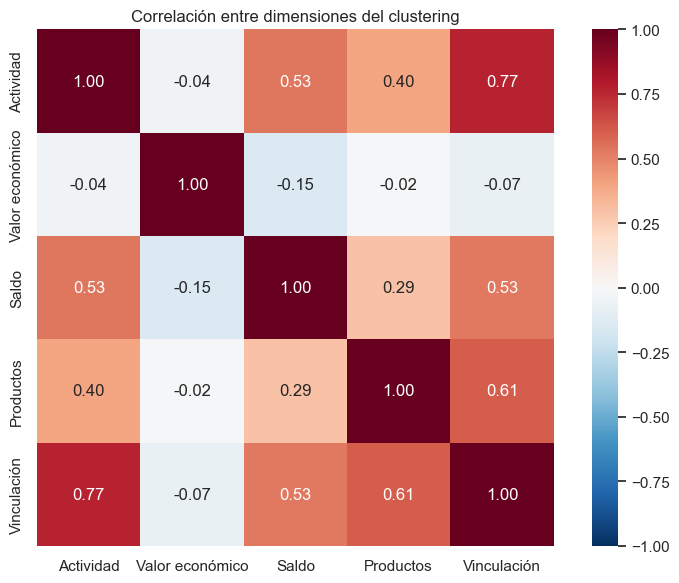

In [127]:
nombres_amigables = {
    "pct_actividad_t0": "Actividad",
    "pct_valor_economico_t0": "Valor económico",
    "pct_saldo_t0": "Saldo",
    "pct_productos_t0": "Productos",
    "pct_vinculacion_t0": "Vinculación",
}

correlaciones = (
    X.rename(columns=nombres_amigables)
    .corr()
)

display(correlaciones.round(3))

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlaciones,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlación entre dimensiones del clustering")
plt.tight_layout()
plt.show()

Esta correlación muestra algo importante: actividad, productos y vinculación forman un mismo bloque de compromiso bancario.
Si usamos las cinco columnas directamente, esa dimensión tendría tres votos, mientras que valor y saldo tendrían uno cada una. El clustering podría terminar separando casi exclusivamente “más vinculados” de “menos vinculados”.
Vamos a crear tres ejes equilibrados:
1. Vinculación integral: promedio de actividad, productos y amplitud.
2. Valor económico.
3. Posición de saldo.
Las variables originales se conservan para explicar cada cluster.

In [128]:
X_modelo = pd.DataFrame(
    {
        "Vinculacion_integral": X[
            [
                "pct_actividad_t0",
                "pct_productos_t0",
                "pct_vinculacion_t0",
            ]
        ].mean(axis=1),

        "Valor_economico": X[
            "pct_valor_economico_t0"
        ],

        "Posicion_saldo": X[
            "pct_saldo_t0"
        ],
    },
    index=X.index,
)

display(X_modelo.describe().T.round(3))
display(X_modelo.corr().round(3))

,count,mean,std,min,25%,50%,75%,max
Vinculacion_integral,3977.0,0.432,0.251,0.0,0.221,0.432,0.632,0.996
Valor_economico,3977.0,0.500,0.289,0.0,0.250,0.500,0.750,1.000
Posicion_saldo,3977.0,0.500,0.289,0.0,0.250,0.500,0.750,1.000


,Vinculacion_integral,Valor_economico,Posicion_saldo
Vinculacion_integral,1.000,-0.052,0.530
Valor_economico,-0.052,1.000,-0.152
Posicion_saldo,0.530,-0.152,1.000


In [129]:
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
)

SEMILLA = 214363
resultados_k = []
modelos_k = {}

for k in range(2, 9):

    modelo = KMeans(
        n_clusters=k,
        n_init=50,
        random_state=SEMILLA,
    )

    etiquetas = modelo.fit_predict(X_modelo)
    tamanios = pd.Series(etiquetas).value_counts()

    modelos_k[k] = modelo

    resultados_k.append(
        {
            "k": k,
            "inercia": modelo.inertia_,
            "silhouette": silhouette_score(
                X_modelo,
                etiquetas,
            ),
            "calinski_harabasz": calinski_harabasz_score(
                X_modelo,
                etiquetas,
            ),
            "davies_bouldin": davies_bouldin_score(
                X_modelo,
                etiquetas,
            ),
            "cluster_minimo_clientes": tamanios.min(),
            "cluster_minimo_pct": 100 * tamanios.min() / len(X_modelo),
        }
    )

evaluacion_k = pd.DataFrame(resultados_k)

display(
    evaluacion_k.round(
        {
            "inercia": 2,
            "silhouette": 3,
            "calinski_harabasz": 1,
            "davies_bouldin": 3,
            "cluster_minimo_pct": 2,
        }
    )
)

/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value enco

,k,inercia,silhouette,calinski_harabasz,davies_bouldin,cluster_minimo_clientes,cluster_minimo_pct
0,2,587.75,0.319,2206.2,1.233,1723,43.32
1,3,412.10,0.338,2419.8,1.052,1069,26.88
2,4,337.92,0.301,2257.6,1.101,914,22.98
3,5,288.49,0.301,2153.0,1.084,656,16.49
4,6,255.45,0.291,2047.4,1.126,614,15.44
5,7,224.27,0.298,2034.8,1.047,504,12.67
6,8,197.25,0.307,2060.2,1.020,424,10.66


In [130]:
%matplotlib inline

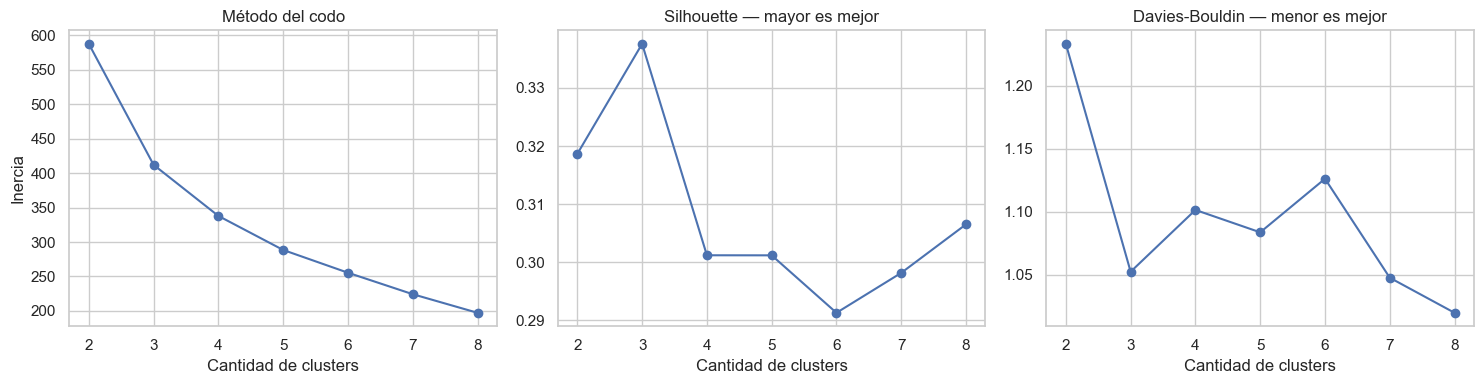

In [131]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(
    evaluacion_k["k"],
    evaluacion_k["inercia"],
    marker="o",
)
axes[0].set_title("Método del codo")
axes[0].set_xlabel("Cantidad de clusters")
axes[0].set_ylabel("Inercia")

axes[1].plot(
    evaluacion_k["k"],
    evaluacion_k["silhouette"],
    marker="o",
)
axes[1].set_title("Silhouette — mayor es mejor")
axes[1].set_xlabel("Cantidad de clusters")

axes[2].plot(
    evaluacion_k["k"],
    evaluacion_k["davies_bouldin"],
    marker="o",
)
axes[2].set_title("Davies-Bouldin — menor es mejor")
axes[2].set_xlabel("Cantidad de clusters")

plt.tight_layout()
display(fig)
plt.close(fig)


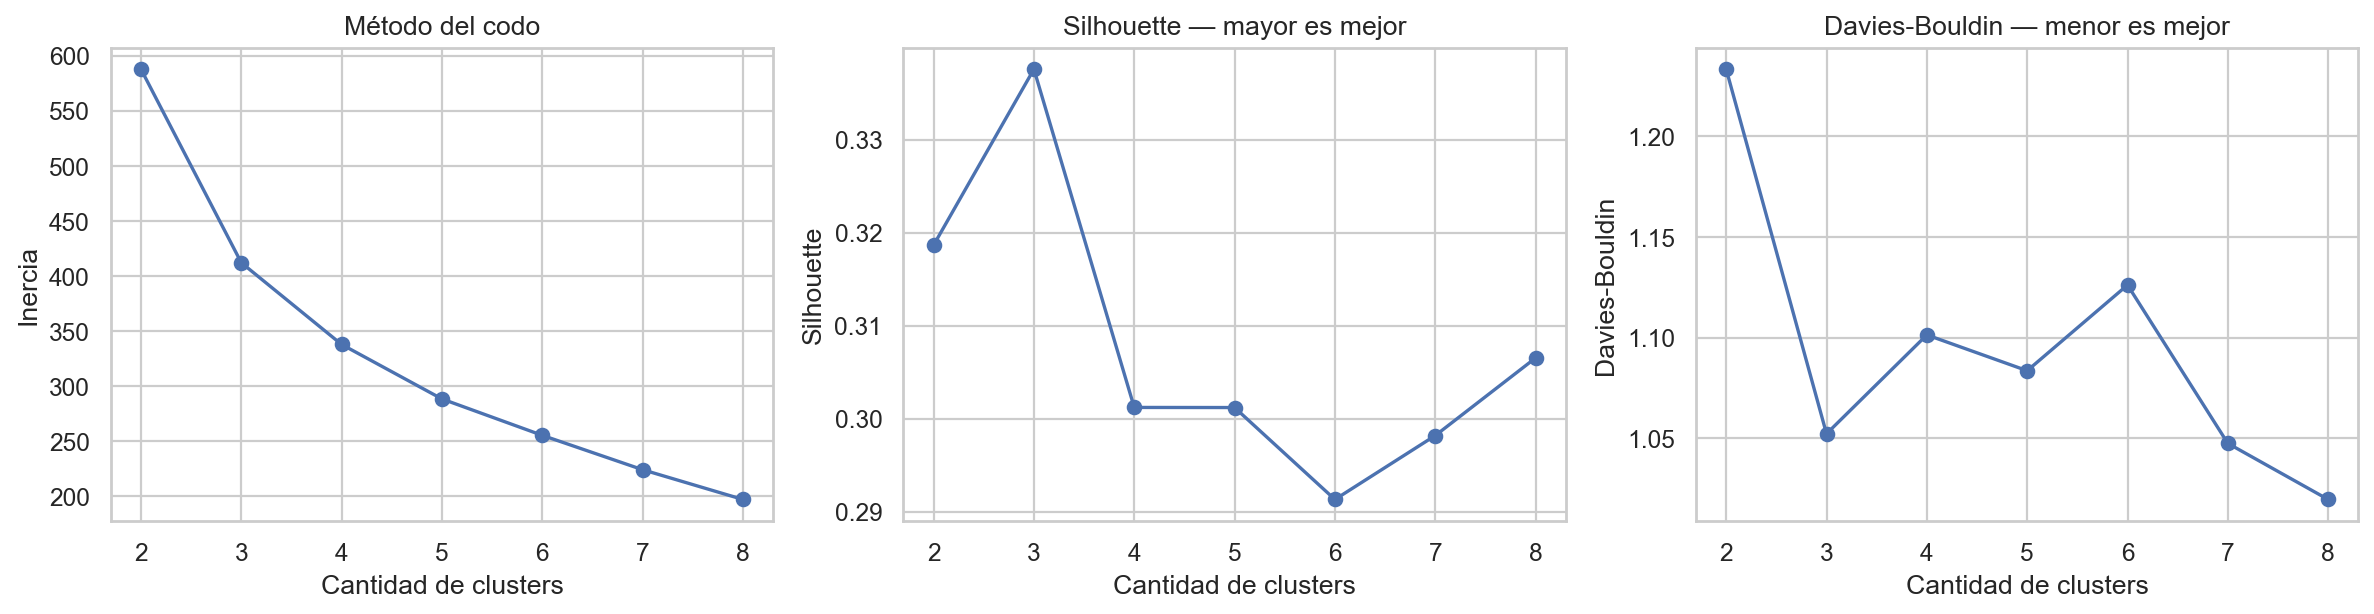

In [132]:
from IPython.display import Image, display

ruta_grafico = (
    "/Users/manuelmarasco/Desktop/dmeyf402/"
    "evaluacion_cantidad_clusters.png"
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(
    evaluacion_k["k"],
    evaluacion_k["inercia"],
    marker="o",
)
axes[0].set_title("Método del codo")
axes[0].set_xlabel("Cantidad de clusters")
axes[0].set_ylabel("Inercia")

axes[1].plot(
    evaluacion_k["k"],
    evaluacion_k["silhouette"],
    marker="o",
)
axes[1].set_title("Silhouette — mayor es mejor")
axes[1].set_xlabel("Cantidad de clusters")
axes[1].set_ylabel("Silhouette")

axes[2].plot(
    evaluacion_k["k"],
    evaluacion_k["davies_bouldin"],
    marker="o",
)
axes[2].set_title("Davies-Bouldin — menor es mejor")
axes[2].set_xlabel("Cantidad de clusters")
axes[2].set_ylabel("Davies-Bouldin")

fig.tight_layout()

fig.savefig(
    ruta_grafico,
    dpi=160,
    bbox_inches="tight",
)

plt.close(fig)

display(Image(filename=ruta_grafico))

![Evaluación de la cantidad de clusters](evaluacion_cantidad_clusters.png)

El gráfico respalda claramente k = 3:
- El codo principal aparece en 3.
- Silhouette alcanza su máximo en 3.
- Davies-Bouldin cae fuertemente de 2 a 3.
- A partir de ahí, agregar clusters aporta mejoras pequeñas o inconsistentes.
Conclusión preliminar: tres perfiles ofrecen la mejor combinación de separación, simplicidad e interpretación.

In [133]:
from itertools import combinations

import numpy as np
import pandas as pd
import sklearn

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score


# Convertimos la matriz a un formato numérico uniforme.
X_kmeans = X_modelo.to_numpy(
    dtype=np.float64,
    copy=True,
)


# Controles básicos.
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Dimensiones:", X_kmeans.shape)
print("Todos los valores son finitos:", np.isfinite(X_kmeans).all())
print(
    "Rango de valores:",
    X_kmeans.min(),
    "a",
    X_kmeans.max(),
)


# Semillas diferentes para comprobar si KMeans
# encuentra grupos parecidos en distintas ejecuciones.
semillas = [
    42,
    2026,
    12345,
    214363,
    987654,
]


resultados_estabilidad = []


for k in range(2, 9):

    etiquetas_por_semilla = []

    for semilla in semillas:

        modelo = KMeans(
            n_clusters=k,
            n_init=50,
            random_state=semilla,
        )

        etiquetas = modelo.fit_predict(X_kmeans)

        etiquetas_por_semilla.append(etiquetas)


    # Comparamos todas las parejas de soluciones.
    ari_pares = [
        adjusted_rand_score(
            etiquetas_por_semilla[i],
            etiquetas_por_semilla[j],
        )
        for i, j in combinations(
            range(len(semillas)),
            2,
        )
    ]


    resultados_estabilidad.append(
        {
            "k": k,
            "ARI_promedio": np.mean(ari_pares),
            "ARI_minimo": np.min(ari_pares),
            "ARI_maximo": np.max(ari_pares),
        }
    )


estabilidad_k = pd.DataFrame(
    resultados_estabilidad
)


display(
    estabilidad_k.round(3)
)

NumPy: 2.0.2
Scikit-learn: 1.6.1
Dimensiones: (3977, 3)
Todos los valores son finitos: True
Rango de valores: 0.0 a 1.0


/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value enco

,k,ARI_promedio,ARI_minimo,ARI_maximo
0,2,0.997,0.994,0.999
1,3,0.999,0.998,1.000
2,4,0.977,0.961,0.999
3,5,0.998,0.996,1.000
4,6,0.975,0.958,0.995
5,7,0.990,0.984,1.000
6,8,0.983,0.969,0.997


In [134]:
K_FINAL = 3
SEMILLA_FINAL = 214363


modelo_final = KMeans(
    n_clusters=K_FINAL,
    n_init=50,
    random_state=SEMILLA_FINAL,
)


etiquetas_originales = modelo_final.fit_predict(
    X_kmeans
)


# KMeans asigna números arbitrarios.
# Siguiendo el criterio del script de la cátedra,
# el cluster 1 será el más numeroso.
orden_por_tamanio = (
    pd.Series(etiquetas_originales)
    .value_counts()
    .index
    .tolist()
)


mapeo_clusters = {
    etiqueta_original: numero_nuevo
    for numero_nuevo, etiqueta_original
    in enumerate(
        orden_por_tamanio,
        start=1,
    )
}


etiquetas_finales = np.array(
    [
        mapeo_clusters[etiqueta]
        for etiqueta in etiquetas_originales
    ]
)


# Guardamos cada cliente con su cluster.
base_clusters = df_cluster.copy()

base_clusters["cluster"] = etiquetas_finales


# Calculamos tamaño y centro de cada cluster.
perfil_modelo = (
    X_modelo
    .assign(cluster=etiquetas_finales)
    .groupby("cluster")
    .mean()
)


tamanios_cluster = (
    base_clusters["cluster"]
    .value_counts()
    .sort_index()
    .rename("clientes")
)


resumen_clusters = (
    tamanios_cluster
    .to_frame()
    .assign(
        porcentaje=lambda tabla:
            100 * tabla["clientes"] / len(base_clusters)
    )
    .join(perfil_modelo)
    .reset_index()
)


display(
    resumen_clusters.round(
        {
            "porcentaje": 2,
            "Vinculacion_integral": 3,
            "Valor_economico": 3,
            "Posicion_saldo": 3,
        }
    )
)

/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value enco

,cluster,clientes,porcentaje,Vinculacion_integral,Valor_economico,Posicion_saldo
0,1,1515,38.09,0.487,0.212,0.601
1,2,1393,35.03,0.233,0.636,0.205
2,3,1069,26.88,0.614,0.731,0.740


# Etapa 3 — Feature engineering histórico para la segmentación final

## Segmentación final — método de Random Forest de la cátedra

Primero construiremos una capa mensual de variables de comportamiento para todos los clientes. Sobre esta tabla agregaremos lags, deltas, medias y pendientes.

In [135]:
# Variables continuas: nivel, lags, deltas y trayectoria
campos_temporales = [
    "ctrx_quarter",
    "mcuentas_saldo",
    "cproductos",
    "mrentabilidad",
    "mcomisiones_mantenimiento",
    "mpayroll",
    "tarjetas_consumo",
    "mtransferencias_emitidas",
]

# Familias: cambio reciente y abandono del producto/uso
campos_eventos = [
    "cpayroll_trx",
    "tarjetas_cantidad",
    "tarjetas_transacciones",
    "debitos_automaticos",
    "pagos_servicios",
    "transacciones_digitales",
    "cantidad_creditos",
    "cantidad_inversiones",
    "cantidad_seguros",
]


derivadas = []

for campo in campos_temporales:

    derivadas.extend([
        f"""
        LAG({campo}, 1) OVER ventana_cliente
            AS {campo}_lag_1
        """,

        f"""
        LAG({campo}, 2) OVER ventana_cliente
            AS {campo}_lag_2
        """,

        f"""
        {campo}
            - LAG({campo}, 1) OVER ventana_cliente
            AS {campo}_delta_1
        """,

        f"""
        {campo}
            - LAG({campo}, 2) OVER ventana_cliente
            AS {campo}_delta_2
        """,

        f"""
        AVG({campo}) OVER ventana_3
            AS {campo}_media_3
        """,

        f"""
        MIN({campo}) OVER ventana_3
            AS {campo}_minimo_3
        """,

        f"""
        MAX({campo}) OVER ventana_3
            AS {campo}_maximo_3
        """,

        f"""
        MAX({campo}) OVER ventana_3
            - MIN({campo}) OVER ventana_3
            AS {campo}_rango_3
        """,

        f"""
        REGR_SLOPE(
            {campo},
            indice_mes
        ) OVER ventana_3
            AS {campo}_pendiente_3
        """,
    ])


for campo in campos_eventos:

    derivadas.extend([
        f"""
        LAG({campo}, 1) OVER ventana_cliente
            AS {campo}_lag_1
        """,

        f"""
        {campo}
            - LAG({campo}, 1) OVER ventana_cliente
            AS {campo}_delta_1
        """,

        f"""
        CASE
            WHEN LAG({campo}, 1) OVER ventana_cliente > 0
             AND {campo} = 0
            THEN 1 ELSE 0
        END AS perdio_{campo}_1m
        """,
    ])


features_sql = ",\n".join(derivadas)


consulta_fe = f"""
CREATE OR REPLACE TABLE competencia_01_fe AS

WITH calendario AS (
    SELECT
        foto_mes,
        ROW_NUMBER() OVER (
            ORDER BY foto_mes
        ) AS indice_mes

    FROM (
        SELECT DISTINCT foto_mes
        FROM competencia_01
    )
),

base AS (
    SELECT
        c.* REPLACE (
            CAST(c.numero_de_cliente AS BIGINT)
                AS numero_de_cliente
        ),

        calendario.indice_mes,

        -- Familias agregadas
        c.ctarjeta_visa
            + c.ctarjeta_master
            AS tarjetas_cantidad,

        c.ctarjeta_visa_transacciones
            + c.ctarjeta_master_transacciones
            AS tarjetas_transacciones,

        c.mtarjeta_visa_consumo
            + c.mtarjeta_master_consumo
            AS tarjetas_consumo,

        c.ccuenta_debitos_automaticos
            + c.ctarjeta_visa_debitos_automaticos
            + c.ctarjeta_master_debitos_automaticos
            AS debitos_automaticos,

        c.cpagodeservicios
            + c.cpagomiscuentas
            AS pagos_servicios,

        c.chomebanking_transacciones
            + c.cmobile_app_trx
            AS transacciones_digitales,

        c.cprestamos_personales
            + c.cprestamos_prendarios
            + c.cprestamos_hipotecarios
            AS cantidad_creditos,

        c.cplazo_fijo
            + c.cinversion1
            + c.cinversion2
            + c.cforex
            AS cantidad_inversiones,

        c.cseguro_vida
            + c.cseguro_auto
            + c.cseguro_vivienda
            + c.cseguro_accidentes_personales
            AS cantidad_seguros

    FROM competencia_01 AS c

    JOIN calendario
        USING (foto_mes)
)

SELECT
    base.* EXCLUDE (indice_mes),

    COUNT(*) OVER ventana_cliente
        AS observaciones_hasta_mes,

    indice_mes
        - LAG(indice_mes, 1) OVER ventana_cliente
        AS meses_desde_observacion_anterior,

    {features_sql}

FROM base

WINDOW
    ventana_cliente AS (
        PARTITION BY numero_de_cliente
        ORDER BY foto_mes
    ),

    ventana_3 AS (
        PARTITION BY numero_de_cliente
        ORDER BY foto_mes
        ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
    );
"""


get_ipython().run_cell_magic(
    "sql",
    "",
    consulta_fe,
)

,Success


In [136]:
%%sql

SELECT
    COUNT(*) AS filas,
    COUNT(DISTINCT numero_de_cliente) AS clientes,
    COUNT(DISTINCT foto_mes) AS meses,

    MIN(foto_mes) AS primer_mes,
    MAX(foto_mes) AS ultimo_mes,

    COUNT(*)
        - COUNT(
            DISTINCT (
                numero_de_cliente,
                foto_mes
            )
        ) AS duplicados_cliente_mes,

    COUNT(*) FILTER (
        WHERE observaciones_hasta_mes >= 3
    ) AS filas_con_historia_3m,

    (
        SELECT COUNT(*)
        FROM duckdb_columns()
        WHERE table_name = 'competencia_01_fe'
    ) AS cantidad_columnas

FROM competencia_01_fe;

,filas,clientes,meses,primer_mes,ultimo_mes,duplicados_cliente_mes,filas_con_historia_3m,cantidad_columnas
0,983061,169727,6,202103,202108,0,646032,266


La construcción quedó perfecta:
- Conservamos las 983.061 filas originales.
- No generamos duplicados.
- Tenemos 266 columnas: 154 originales más agregados y features.
- 646.032 filas tienen al menos tres observaciones históricas.
Ahora debemos comprobar que los lags respetan el calendario y que los nulos aparecen solamente cuando falta historia.

In [137]:
%%sql

SELECT
    observaciones_hasta_mes,
    COUNT(*) AS filas,
    COUNT(DISTINCT numero_de_cliente) AS clientes,

    COUNT(*) FILTER (
        WHERE observaciones_hasta_mes > 1
          AND meses_desde_observacion_anterior <> 1
    ) AS saltos_en_la_historia,

    COUNT(*) FILTER (
        WHERE observaciones_hasta_mes >= 2
          AND (
              ctrx_quarter_lag_1 IS NULL
              OR mcuentas_saldo_lag_1 IS NULL
              OR cproductos_lag_1 IS NULL
              OR mrentabilidad_lag_1 IS NULL
          )
    ) AS nulos_inesperados_lag_1,

    COUNT(*) FILTER (
        WHERE observaciones_hasta_mes >= 3
          AND (
              ctrx_quarter_lag_2 IS NULL
              OR mcuentas_saldo_lag_2 IS NULL
              OR cproductos_lag_2 IS NULL
              OR mrentabilidad_lag_2 IS NULL
              OR ctrx_quarter_pendiente_3 IS NULL
              OR mcuentas_saldo_pendiente_3 IS NULL
          )
    ) AS nulos_inesperados_historia_3m

FROM competencia_01_fe

GROUP BY observaciones_hasta_mes
ORDER BY observaciones_hasta_mes;

,observaciones_hasta_mes,filas,clientes,saltos_en_la_historia,nulos_inesperados_lag_1,nulos_inesperados_historia_3m
0,1,169727,169727,0,0,0
1,2,167302,167302,6,0,0
2,3,165241,165241,9,0,0
3,4,162630,162630,5,0,0
4,5,160324,160324,3,0,0
5,6,157837,157837,0,0,0


In [138]:
%%sql

CREATE OR REPLACE TABLE muestra_rf_segmentacion AS

WITH bajas_estrictas AS (
    SELECT DISTINCT
        CAST(numero_de_cliente AS BIGINT)
            AS numero_de_cliente

    FROM poblacion_miranda

    WHERE grupo_evento = 'estricta'
),

fieles_elegibles AS (
    SELECT
        numero_de_cliente

    FROM competencia_01_fe

    GROUP BY numero_de_cliente

    HAVING COUNT(DISTINCT foto_mes) = 6

       AND COUNT(*) FILTER (
           WHERE clase_ternaria IN (
               'BAJA+1',
               'BAJA+2'
           )
       ) = 0
),

fieles_muestra AS (
    SELECT
        numero_de_cliente

    FROM fieles_elegibles

    ORDER BY hash(
        numero_de_cliente + 214363
    )

    LIMIT (
        SELECT COUNT(*)
        FROM bajas_estrictas
    )
)

SELECT
    fe.*,
    1 AS grupo

FROM competencia_01_fe AS fe

JOIN bajas_estrictas
    USING (numero_de_cliente)

UNION ALL

SELECT
    fe.*,
    0 AS grupo

FROM competencia_01_fe AS fe

JOIN fieles_muestra
    USING (numero_de_cliente)

ORDER BY
    numero_de_cliente,
    foto_mes;

,Success


Valido la muestra

In [139]:
%%sql

WITH historia_cliente AS (
    SELECT
        grupo,
        numero_de_cliente,
        COUNT(*) AS filas_cliente,
        COUNT(DISTINCT foto_mes) AS meses_cliente

    FROM muestra_rf_segmentacion

    GROUP BY
        grupo,
        numero_de_cliente
)

SELECT
    grupo,

    CASE
        WHEN grupo = 1 THEN 'baja_estricta'
        ELSE 'fiel'
    END AS poblacion,

    COUNT(*) AS clientes,
    SUM(filas_cliente) AS filas,

    MIN(meses_cliente) AS meses_minimos,
    ROUND(MEDIAN(meses_cliente), 2)
        AS mediana_meses,
    MAX(meses_cliente) AS meses_maximos

FROM historia_cliente

GROUP BY grupo
ORDER BY grupo DESC;

,grupo,poblacion,clientes,filas,meses_minimos,mediana_meses,meses_maximos
0,1,baja_estricta,3977,9779.0,1,3.0,4
1,0,fiel,3977,23862.0,6,6.0,6


In [140]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier


SEMILLA_RF = 214363


# Traemos la muestra construida en SQL.
df_rf = %sql SELECT * FROM muestra_rf_segmentacion


columnas_excluidas_rf = {
    "numero_de_cliente",
    "foto_mes",
    "clase_ternaria",
    "grupo",
    "mes_0",

    # Sirven para auditar, pero no son comportamiento.
    "observaciones_hasta_mes",
    "meses_desde_observacion_anterior",
}


features_rf_referencia = [
    columna
    for columna in df_rf.columns

    if columna not in columnas_excluidas_rf
    and pd.api.types.is_numeric_dtype(
        df_rf[columna]
    )
]


X_rf_referencia = (
    df_rf[features_rf_referencia]
    .to_numpy(
        dtype=np.float32,
        copy=True,
    )
)

y_rf = (
    df_rf["grupo"]
    .to_numpy()
)


print("Filas:", X_rf_referencia.shape[0])
print("Features:", X_rf_referencia.shape[1])
print("Valores infinitos:", np.isinf(X_rf_referencia).sum())
print("Valores nulos:", np.isnan(X_rf_referencia).sum())
print(
    "Distribución de filas por grupo:",
    pd.Series(y_rf).value_counts().sort_index().to_dict(),
)


rf_referencia = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=50,
    max_features="sqrt",
    class_weight="balanced",
    oob_score=True,
    n_jobs=-1,
    random_state=SEMILLA_RF,
)


rf_referencia.fit(
    X_rf_referencia,
    y_rf,
)


print(
    "OOB de referencia:",
    round(rf_referencia.oob_score_, 4),
)

Filas: 33641
Features: 260
Valores infinitos: 0
Valores nulos: 999939
Distribución de filas por grupo: {0: 23862, 1: 9779}
OOB de referencia: 0.8601


El bosque entrenó correctamente.
- Los 999.939 nulos no son un error: incluyen lags sin historia y los nulos originales de tarjetas.
- scikit-learn 1.6.1 los procesó nativamente.
- El OOB de 0,8601 sólo confirma que el bosque encuentra diferencias. No es una validación predictiva porque un mismo cliente aparece en varios meses.
Ahora debemos verificar qué variables utilizó. Este control es crucial antes de construir los clusters.


“Sospechosa” significa sospechosa de revelar administrativamente que el cliente ya está iniciando la baja, en vez de describir su comportamiento.
Ejemplo simple:
- Visa_status podría cambiar porque el banco ya empezó a cerrar la tarjeta.
- El bosque ve ese cambio y reconoce fácilmente al cliente que se va.
- Pero eso no explica por qué se fue ni permite actuar antes.
Eso sería una fuga de información o leakage.

In [141]:
variables_sospechosas = {
    "Master_status",
    "Visa_status",
    "Master_delinquency",
    "Visa_delinquency",
    "Master_fultimo_cierre",
    "Visa_fultimo_cierre",
    "Master_Finiciomora",
    "Visa_Finiciomora",
    "Master_Fvencimiento",
    "Visa_Fvencimiento",
    "Master_fechaalta",
    "Visa_fechaalta",
    "active_quarter",
}


auditoria_features_rf = pd.DataFrame(
    {
        "variable": features_rf_referencia,

        "importancia": (
            rf_referencia.feature_importances_
        ),

        "porcentaje_nulos": (
            100
            * df_rf[
                features_rf_referencia
            ].isna().mean().values
        ),
    }
)


auditoria_features_rf["sospechosa"] = (
    auditoria_features_rf["variable"]
    .isin(variables_sospechosas)
)


top_features_rf = (
    auditoria_features_rf
    .sort_values(
        "importancia",
        ascending=False,
    )
    .head(30)
    .reset_index(drop=True)
)


display(
    top_features_rf.round(
        {
            "importancia": 4,
            "porcentaje_nulos": 2,
        }
    )
)

,variable,importancia,porcentaje_nulos,sospechosa
0,mpayroll,0.0487,0.00,False
1,cpayroll_trx,0.0474,0.00,False
2,ctrx_quarter_minimo_3,0.0429,0.00,False
3,ctrx_quarter_media_3,0.0415,0.00,False
4,ctrx_quarter_maximo_3,0.0387,0.00,False
5,ctrx_quarter,0.0383,0.00,False
6,mcaja_ahorro,0.0340,0.00,False
7,mpayroll_minimo_3,0.0330,0.00,False
8,ctrx_quarter_lag_1,0.0323,23.64,False
9,mpayroll_media_3,0.0313,0.00,False


Claro. Frenemos y ordenemos porque todavía **no hicimos clustering**.

## Qué hicimos hasta ahora

### 1. Creamos la base con historia

Partimos de las 154 variables originales y agregamos cosas como:

- valor del mes anterior;
- valor de hace dos meses;
- cambio contra el mes anterior;
- promedio de tres meses;
- mínimo y máximo;
- tendencia.

Ejemplo:

```text
Transacciones actuales: 10
Mes anterior:           30
Hace dos meses:         50
```

Entonces podemos representar que las transacciones vienen cayendo:

```text
50 → 30 → 10
```

Eso describe mejor al cliente que mirar solamente el `10`.

### 2. Verificamos que la construcción no rompiera la base

Comprobamos:

- mismas 983.061 filas;
- mismos 169.727 clientes;
- cero duplicados;
- lags correctamente calculados;
- sólo 23 saltos temporales, correspondientes a los intermitentes.

### 3. Armamos una muestra para el bosque

Tomamos:

- 3.977 clientes que confirmamos que se fueron;
- 3.977 clientes fieles.

Incluimos todos los meses disponibles de esos clientes.

Los fieles sólo funcionan como contraste. Todavía no los estamos clusterizando.

### 4. Entrenamos un Random Forest

Le mostramos al bosque ejemplos de:

```text
grupo 1 = cliente que terminó abandonando
grupo 0 = cliente fiel
```

Y le pedimos que descubriera qué variables los diferencian.

No estamos usando el bosque para predecir ni para armar el video. Lo usamos para que aprenda cuáles son las dimensiones relevantes del abandono.

### 5. Miramos qué variables aprendió el bosque

La tabla que pasaste es un ranking de cuánto utilizó el bosque cada variable.

Por ejemplo:

```text
mpayroll: importancia 0,0487
```

No significa que payroll aumente la probabilidad de baja en 4,87%.

Significa:

> De toda la capacidad del bosque para distinguir bajas de fieles, `mpayroll` aportó aproximadamente un 4,87%.

## Qué significa “sospechosa”

Nosotros escribimos manualmente una lista de variables administrativas:

```python
variables_sospechosas = {
    "Master_status",
    "Visa_status",
    ...
}
```

La columna `sospechosa` solamente pregunta:

> ¿Esta variable pertenece a esa lista?

No hace ningún test estadístico ni elimina nada.

La lógica era buscar este posible problema:

```text
Visa_status cambia porque la tarjeta ya se está cerrando
                          ↓
el bosque reconoce fácilmente la baja
                          ↓
los clusters terminan describiendo trámites administrativos
```

Eso no sería útil para Miranda.

## Qué concluye tu tabla

Es una buena salida: ninguna de las 30 variables principales está marcada como sospechosa.

El bosque está usando principalmente:

- payroll;
- cantidad de transacciones;
- caja de ahorro;
- márgenes pasivos;
- consumo con tarjetas;
- saldo.

Es decir, está mirando **comportamiento y vinculación**, que es lo que queremos.

También aparecen muchos features históricos:

- `ctrx_quarter_media_3`;
- `ctrx_quarter_minimo_3`;
- `ctrx_quarter_lag_1`;
- `ctrx_quarter_lag_2`;
- `mpayroll_media_3`;
- `mcuentas_saldo_media_3`.

Esto confirma algo muy importante: agregar historia sí aportó información.

Los nulos de los lags son esperables:

- `lag_1` tiene 23,64% porque la primera observación no tiene mes anterior.
- `lag_2` tiene 44,24% porque las primeras dos observaciones no tienen dos meses previos.

## Dónde estamos

```text
Base original + historia
          ↓
Bajas contra fieles
          ↓
Random Forest identifica dimensiones relevantes  ← estamos acá
          ↓
Perfil del bosque para cada cliente
          ↓
Segmentación solamente de las bajas
```

El resultado actual es positivo: el bosque está aprendiendo señales conductuales y no parece estar dominado por variables administrativas. Todavía falta transformar ese aprendizaje en perfiles de clientes y recién después segmentarlos.

In [184]:
features_rf_limpias = [
    variable
    for variable in features_rf_referencia
    if variable not in variables_sospechosas
]


X_rf_limpio = (
    df_rf[features_rf_limpias]
    .to_numpy(
        dtype=np.float32,
        copy=True,
    )
)


rf_limpio = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=50,
    max_features="sqrt",
    class_weight="balanced",
    oob_score=True,
    n_jobs=-1,
    random_state=SEMILLA_RF,
)


rf_limpio.fit(
    X_rf_limpio,
    y_rf,
)


importancias_limpias = (
    pd.DataFrame(
        {
            "variable": features_rf_limpias,
            "importancia": (
                rf_limpio.feature_importances_
            ),
        }
    )
    .sort_values(
        "importancia",
        ascending=False,
    )
    .reset_index(drop=True)
)


print(
    "Features de referencia:",
    len(features_rf_referencia),
)

print(
    "Features de la versión limpia:",
    len(features_rf_limpias),
)

print(
    "Variables retiradas:",
    sorted(
        set(features_rf_referencia)
        - set(features_rf_limpias)
    ),
)

print(
    "OOB referencia:",
    round(rf_referencia.oob_score_, 4),
)

print(
    "OOB limpio:",
    round(rf_limpio.oob_score_, 4),
)


display(
    importancias_limpias
    .head(20)
    .round(
        {
            "importancia": 4,
        }
    )
)

Features de referencia: 260
Features de la versión limpia: 247
Variables retiradas: ['Master_Finiciomora', 'Master_Fvencimiento', 'Master_delinquency', 'Master_fechaalta', 'Master_fultimo_cierre', 'Master_status', 'Visa_Finiciomora', 'Visa_Fvencimiento', 'Visa_delinquency', 'Visa_fechaalta', 'Visa_fultimo_cierre', 'Visa_status', 'active_quarter']
OOB referencia: 0.8601
OOB limpio: 0.8606


,variable,importancia
0,ctrx_quarter_media_3,0.0435
1,ctrx_quarter,0.0433
2,mpasivos_margen,0.0420
3,cpayroll_trx,0.0416
4,mpayroll_minimo_3,0.0413
5,mcaja_ahorro,0.0404
6,ctrx_quarter_lag_1,0.0404
7,mpayroll_media_3,0.0356
8,tarjetas_consumo,0.0317
9,mpayroll,0.0313


al retirar las administrativas siguen dominando variables de comportamiento e historia:
- actividad actual y promedio;
- payroll actual e histórico;
- caja de ahorro;
- márgenes pasivos;
- consumo de tarjetas;
- saldo histórico.

- Quitamos 13 variables administrativas.
- El OOB prácticamente no cambió: 0,8601 → 0,8606.
- Las variables principales siguen siendo comportamiento e historia.
Conclusión: podemos usar el bosque limpio para construir los perfiles.
Ahora aplicamos la parte central de z501: contar qué variables definieron las hojas visitadas por cada cliente.

In [185]:
def atributo_de_hoja(arbol):

    estructura = arbol.tree_

    mapa_atributos = np.full(
        estructura.node_count,
        -1,
        dtype=np.int64,
    )

    nodos_internos = np.flatnonzero(
        estructura.children_left != -1
    )

    mapa_atributos[
        estructura.children_left[nodos_internos]
    ] = estructura.feature[nodos_internos]

    mapa_atributos[
        estructura.children_right[nodos_internos]
    ] = estructura.feature[nodos_internos]

    return mapa_atributos


def contar_hojas_por_cliente(
    bosque,
    X,
    ids,
    nombres_features,
):

    # Hoja alcanzada por cada fila en cada árbol
    hojas = bosque.apply(X)

    cantidad_features = len(nombres_features)

    codigos_atributos = np.empty_like(hojas)

    for numero_arbol, arbol in enumerate(
        bosque.estimators_
    ):

        mapa = atributo_de_hoja(arbol)

        codigos_atributos[:, numero_arbol] = (
            mapa[hojas[:, numero_arbol]]
        )

    # Código adicional para árboles sin split
    codigos_atributos[
        codigos_atributos < 0
    ] = cantidad_features

    indice_cliente, clientes_unicos = (
        pd.factorize(ids)
    )

    conteos = np.zeros(
        (
            len(clientes_unicos),
            cantidad_features + 1,
        ),
        dtype=np.int64,
    )

    np.add.at(
        conteos,
        (
            np.repeat(
                indice_cliente,
                hojas.shape[1],
            ),
            codigos_atributos.ravel(),
        ),
        1,
    )

    return pd.DataFrame(
        conteos,
        index=pd.Index(
            clientes_unicos,
            name="numero_de_cliente",
        ),
        columns=(
            nombres_features
            + ["_sin_split"]
        ),
    )


def normalizar_perfil_hojas(conteos):

    perfiles = conteos.drop(
        columns=["_sin_split"],
        errors="ignore",
    )

    # Quitamos atributos nunca utilizados
    perfiles = perfiles.loc[
        :,
        perfiles.sum(axis=0) > 0,
    ]

    # Cada cliente queda expresado como proporciones
    perfiles = perfiles.div(
        perfiles.sum(axis=1),
        axis=0,
    )

    return perfiles


ids_rf = (
    df_rf["numero_de_cliente"]
    .to_numpy()
)


conteos_hojas = contar_hojas_por_cliente(
    bosque=rf_limpio,
    X=X_rf_limpio,
    ids=ids_rf,
    nombres_features=features_rf_limpias,
)


perfiles_hojas = normalizar_perfil_hojas(
    conteos_hojas
)


ids_bajas = pd.Index(
    df_rf.loc[
        df_rf["grupo"] == 1,
        "numero_de_cliente",
    ].unique()
)


perfiles_hojas_bajas = (
    perfiles_hojas.loc[ids_bajas]
)


print(
    "Clientes representados:",
    perfiles_hojas.shape[0],
)

print(
    "Bajas representadas:",
    perfiles_hojas_bajas.shape[0],
)

print(
    "Atributos utilizados por el bosque:",
    perfiles_hojas_bajas.shape[1],
)

print(
    "Nulos:",
    perfiles_hojas_bajas.isna().sum().sum(),
)

print(
    "Suma mínima por cliente:",
    perfiles_hojas_bajas.sum(axis=1).min(),
)

print(
    "Suma máxima por cliente:",
    perfiles_hojas_bajas.sum(axis=1).max(),
)

Clientes representados: 7954
Bajas representadas: 3977
Atributos utilizados por el bosque: 214
Nulos: 0
Suma mínima por cliente: 0.9999999999999997
Suma máxima por cliente: 1.0000000000000002


La huella quedó correctamente construida:
- 7.954 clientes totales.
- 3.977 bajas.
- 214 atributos efectivamente utilizados.
- Cero nulos.
- Cada cliente suma exactamente 1.
Ahora probamos k = 3, 4 y 5,

In [186]:
from sklearn.cluster import KMeans


def clusterizar_perfiles(
    perfiles,
    k,
    semilla,
):

    modelo = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=semilla,
    )

    etiquetas_originales = modelo.fit_predict(
        perfiles.to_numpy()
    )

    # Cluster 1 será el más numeroso
    orden_por_tamanio = (
        pd.Series(etiquetas_originales)
        .value_counts()
        .index
        .tolist()
    )

    mapeo = {
        etiqueta_original: numero_nuevo
        for numero_nuevo, etiqueta_original
        in enumerate(
            orden_por_tamanio,
            start=1,
        )
    }

    etiquetas = pd.Series(
        [
            mapeo[etiqueta]
            for etiqueta in etiquetas_originales
        ],
        index=perfiles.index,
        name="cluster",
    )

    return modelo, etiquetas


def atributos_definitorios(
    perfiles,
    etiquetas,
    top_n=3,
):

    promedio_global = perfiles.mean(axis=0)

    resultados = []

    limite_minimo = (
        0.5 / perfiles.shape[1]
    )

    for cluster, perfiles_cluster in (
        perfiles.groupby(etiquetas)
    ):

        promedio_cluster = (
            perfiles_cluster.mean(axis=0)
        )

        tabla = pd.DataFrame(
            {
                "share_cluster": promedio_cluster,
                "share_global": promedio_global,
            }
        )

        tabla["lift"] = (
            tabla["share_cluster"]
            / tabla["share_global"].replace(
                0,
                np.nan,
            )
        )

        tabla = (
            tabla[
                tabla["share_cluster"]
                >= limite_minimo
            ]
            .sort_values(
                "lift",
                ascending=False,
            )
            .head(top_n)
        )

        for posicion, (
            variable,
            fila,
        ) in enumerate(
            tabla.iterrows(),
            start=1,
        ):

            resultados.append(
                {
                    "cluster": cluster,
                    "posicion": posicion,
                    "variable": variable,
                    "lift": fila["lift"],
                }
            )

    return pd.DataFrame(resultados)


soluciones_k = {}
filas_resumen = []


for k in [3, 4, 5]:

    modelo, etiquetas = clusterizar_perfiles(
        perfiles=perfiles_hojas_bajas,
        k=k,
        semilla=SEMILLA_RF,
    )

    definitorios = atributos_definitorios(
        perfiles=perfiles_hojas_bajas,
        etiquetas=etiquetas,
        top_n=3,
    )

    soluciones_k[k] = {
        "modelo": modelo,
        "etiquetas": etiquetas,
        "definitorios": definitorios,
    }

    tamanios = (
        etiquetas
        .value_counts()
        .sort_index()
    )

    for cluster, cantidad in tamanios.items():

        atributos_cluster = (
            definitorios[
                definitorios["cluster"]
                == cluster
            ]
            .sort_values("posicion")
        )

        descripcion = "; ".join(
            f"{fila.variable} "
            f"(lift {fila.lift:.2f})"

            for fila in (
                atributos_cluster.itertuples()
            )
        )

        filas_resumen.append(
            {
                "k": k,
                "cluster": cluster,
                "clientes": cantidad,
                "porcentaje": (
                    100
                    * cantidad
                    / len(perfiles_hojas_bajas)
                ),
                "atributos_definitorios": (
                    descripcion
                ),
            }
        )


resumen_segmentaciones = pd.DataFrame(
    filas_resumen
)


display(
    resumen_segmentaciones.round(
        {
            "porcentaje": 2,
        }
    )
)

/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value enco

,k,cluster,clientes,porcentaje,atributos_definitorios
0,3,1,2328,58.54,mpagomiscuentas (lift 1.68); mtransferencias_emitidas_minimo_3 (lift 1.67); tarjetas_consumo_rango_3 (lift 1.67)
1,3,2,1545,38.85,internet (lift 2.25); cdescubierto_preacordado (lift 2.24); tarjetas_cantidad_lag_1 (lift 1.97)
2,3,3,104,2.62,mprestamos_personales (lift 23.98); cprestamos_personales (lift 20.78); cantidad_creditos (lift 19.22)
3,4,1,1446,36.36,mttarjeta_visa_debitos_automaticos (lift 1.79); ctarjeta_visa_transacciones (lift 1.79); Visa_cconsumos (lift 1.72)
4,4,2,1429,35.93,cdescubierto_preacordado (lift 2.38); internet (lift 2.35); tarjetas_cantidad_lag_1 (lift 2.04)
5,4,3,992,24.94,mpayroll (lift 3.67); mpayroll_minimo_3 (lift 3.61); cpagomiscuentas (lift 3.53)
6,4,4,110,2.77,mprestamos_personales (lift 23.06); cprestamos_personales (lift 20.26); cantidad_creditos (lift 19.24)
7,5,1,1204,30.27,mttarjeta_visa_debitos_automaticos (lift 2.26); ctarjeta_visa_transacciones (lift 2.15); tarjetas_consumo_minimo_3 (lift 2.05)
8,5,2,942,23.69,cdescubierto_preacordado (lift 3.07); internet (lift 3.01); ctarjeta_debito (lift 2.27)
9,5,3,906,22.78,thomebanking (lift 2.09); mrentabilidad_lag_2 (lift 1.60); mcuentas_saldo_lag_2 (lift 1.43)


Lectura preliminar:
- Con k=3, dos grupos concentran 97% y el tercero tiene 104 clientes. Parece demasiado grueso.
- Con k=4, aparecen tres grupos grandes —36%, 36% y 25%— más un grupo pequeño de préstamos personales. Es una candidata fuerte.
- Con k=5, los cuatro grupos grandes quedan más equilibrados, pero debemos comprobar si representan conductas realmente diferentes o si estamos partiendo artificialmente los anteriores.
- El segmento de préstamos personales aparece siempre con aproximadamente 108 clientes. Eso indica que es un perfil pequeño pero muy estable.
Importante: que mpayroll defina un cluster no significa todavía “payroll alto” ni “payroll bajo”. Sólo significa que esa variable fue especialmente utilizada por el bosque. Debemos mirar sus valores reales.

k=3: 2.328, 1.545 y 104 clientes. Dos grupos enormes y uno pequeño.
k=4: 1.446, 1.429, 992 y 110. Tres grupos grandes más equilibrados.
k=5: 1.204, 942, 906, 817 y 108. Cuatro grandes más divididos.
El grupo de aproximadamente 108 clientes aparece con todos los k, siempre asociado a préstamos. Por eso parece estable.


In [187]:
import matplotlib.pyplot as plt


ruta_tamanios = (
    "/Users/manuelmarasco/Desktop/dmeyf402/"
    "comparacion_tamanios_segmentos.png"
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5),
    sharey=True,
)


for ax, k in zip(
    axes,
    [3, 4, 5],
):

    datos_k = (
        resumen_segmentaciones[
            resumen_segmentaciones["k"] == k
        ]
        .sort_values("cluster")
    )

    barras = ax.bar(
        datos_k["cluster"].astype(str),
        datos_k["porcentaje"],
        color="#4C78A8",
    )

    ax.set_title(
        f"Segmentación con k = {k}"
    )

    ax.set_xlabel("Cluster")
    ax.set_ylabel("% de las bajas")
    ax.set_ylim(
        0,
        resumen_segmentaciones[
            "porcentaje"
        ].max() + 8,
    )

    for barra, porcentaje, clientes in zip(
        barras,
        datos_k["porcentaje"],
        datos_k["clientes"],
    ):

        ax.text(
            barra.get_x()
            + barra.get_width() / 2,

            barra.get_height() + 1,

            f"{porcentaje:.1f}%\n"
            f"n={clientes}",

            ha="center",
            va="bottom",
            fontsize=9,
        )


fig.suptitle(
    "Cómo cambia el tamaño de los segmentos según k",
    fontsize=15,
)

fig.tight_layout()

fig.savefig(
    ruta_tamanios,
    dpi=160,
    bbox_inches="tight",
)

plt.close(fig)

print(
    "Gráfico guardado en:",
    ruta_tamanios,
)

Gráfico guardado en: /Users/manuelmarasco/Desktop/dmeyf402/comparacion_tamanios_segmentos.png


In [188]:
etiquetas_k3 = soluciones_k[3]["etiquetas"]
etiquetas_k4 = soluciones_k[4]["etiquetas"]
etiquetas_k5 = soluciones_k[5]["etiquetas"]


transicion_3_a_4 = pd.crosstab(
    etiquetas_k3,
    etiquetas_k4,
    normalize="index",
) * 100


transicion_4_a_5 = pd.crosstab(
    etiquetas_k4,
    etiquetas_k5,
    normalize="index",
) * 100


ruta_transiciones = (
    "/Users/manuelmarasco/Desktop/dmeyf402/"
    "transicion_entre_segmentaciones.png"
)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)


sns.heatmap(
    transicion_3_a_4,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    ax=axes[0],
    cbar_kws={
        "label": "% del cluster original"
    },
)

axes[0].set_title(
    "Dónde terminan los clientes al pasar de k=3 a k=4"
)
axes[0].set_xlabel("Cluster nuevo con k=4")
axes[0].set_ylabel("Cluster original con k=3")


sns.heatmap(
    transicion_4_a_5,
    annot=True,
    fmt=".1f",
    cmap="Greens",
    vmin=0,
    vmax=100,
    ax=axes[1],
    cbar_kws={
        "label": "% del cluster original"
    },
)

axes[1].set_title(
    "Dónde terminan los clientes al pasar de k=4 a k=5"
)
axes[1].set_xlabel("Cluster nuevo con k=5")
axes[1].set_ylabel("Cluster original con k=4")


fig.suptitle(
    "Cómo se dividen los mismos clientes al aumentar k",
    fontsize=15,
)

fig.tight_layout()

fig.savefig(
    ruta_transiciones,
    dpi=160,
    bbox_inches="tight",
)

plt.close(fig)

print(
    "Gráfico guardado en:",
    ruta_transiciones,
)

Gráfico guardado en: /Users/manuelmarasco/Desktop/dmeyf402/transicion_entre_segmentaciones.png


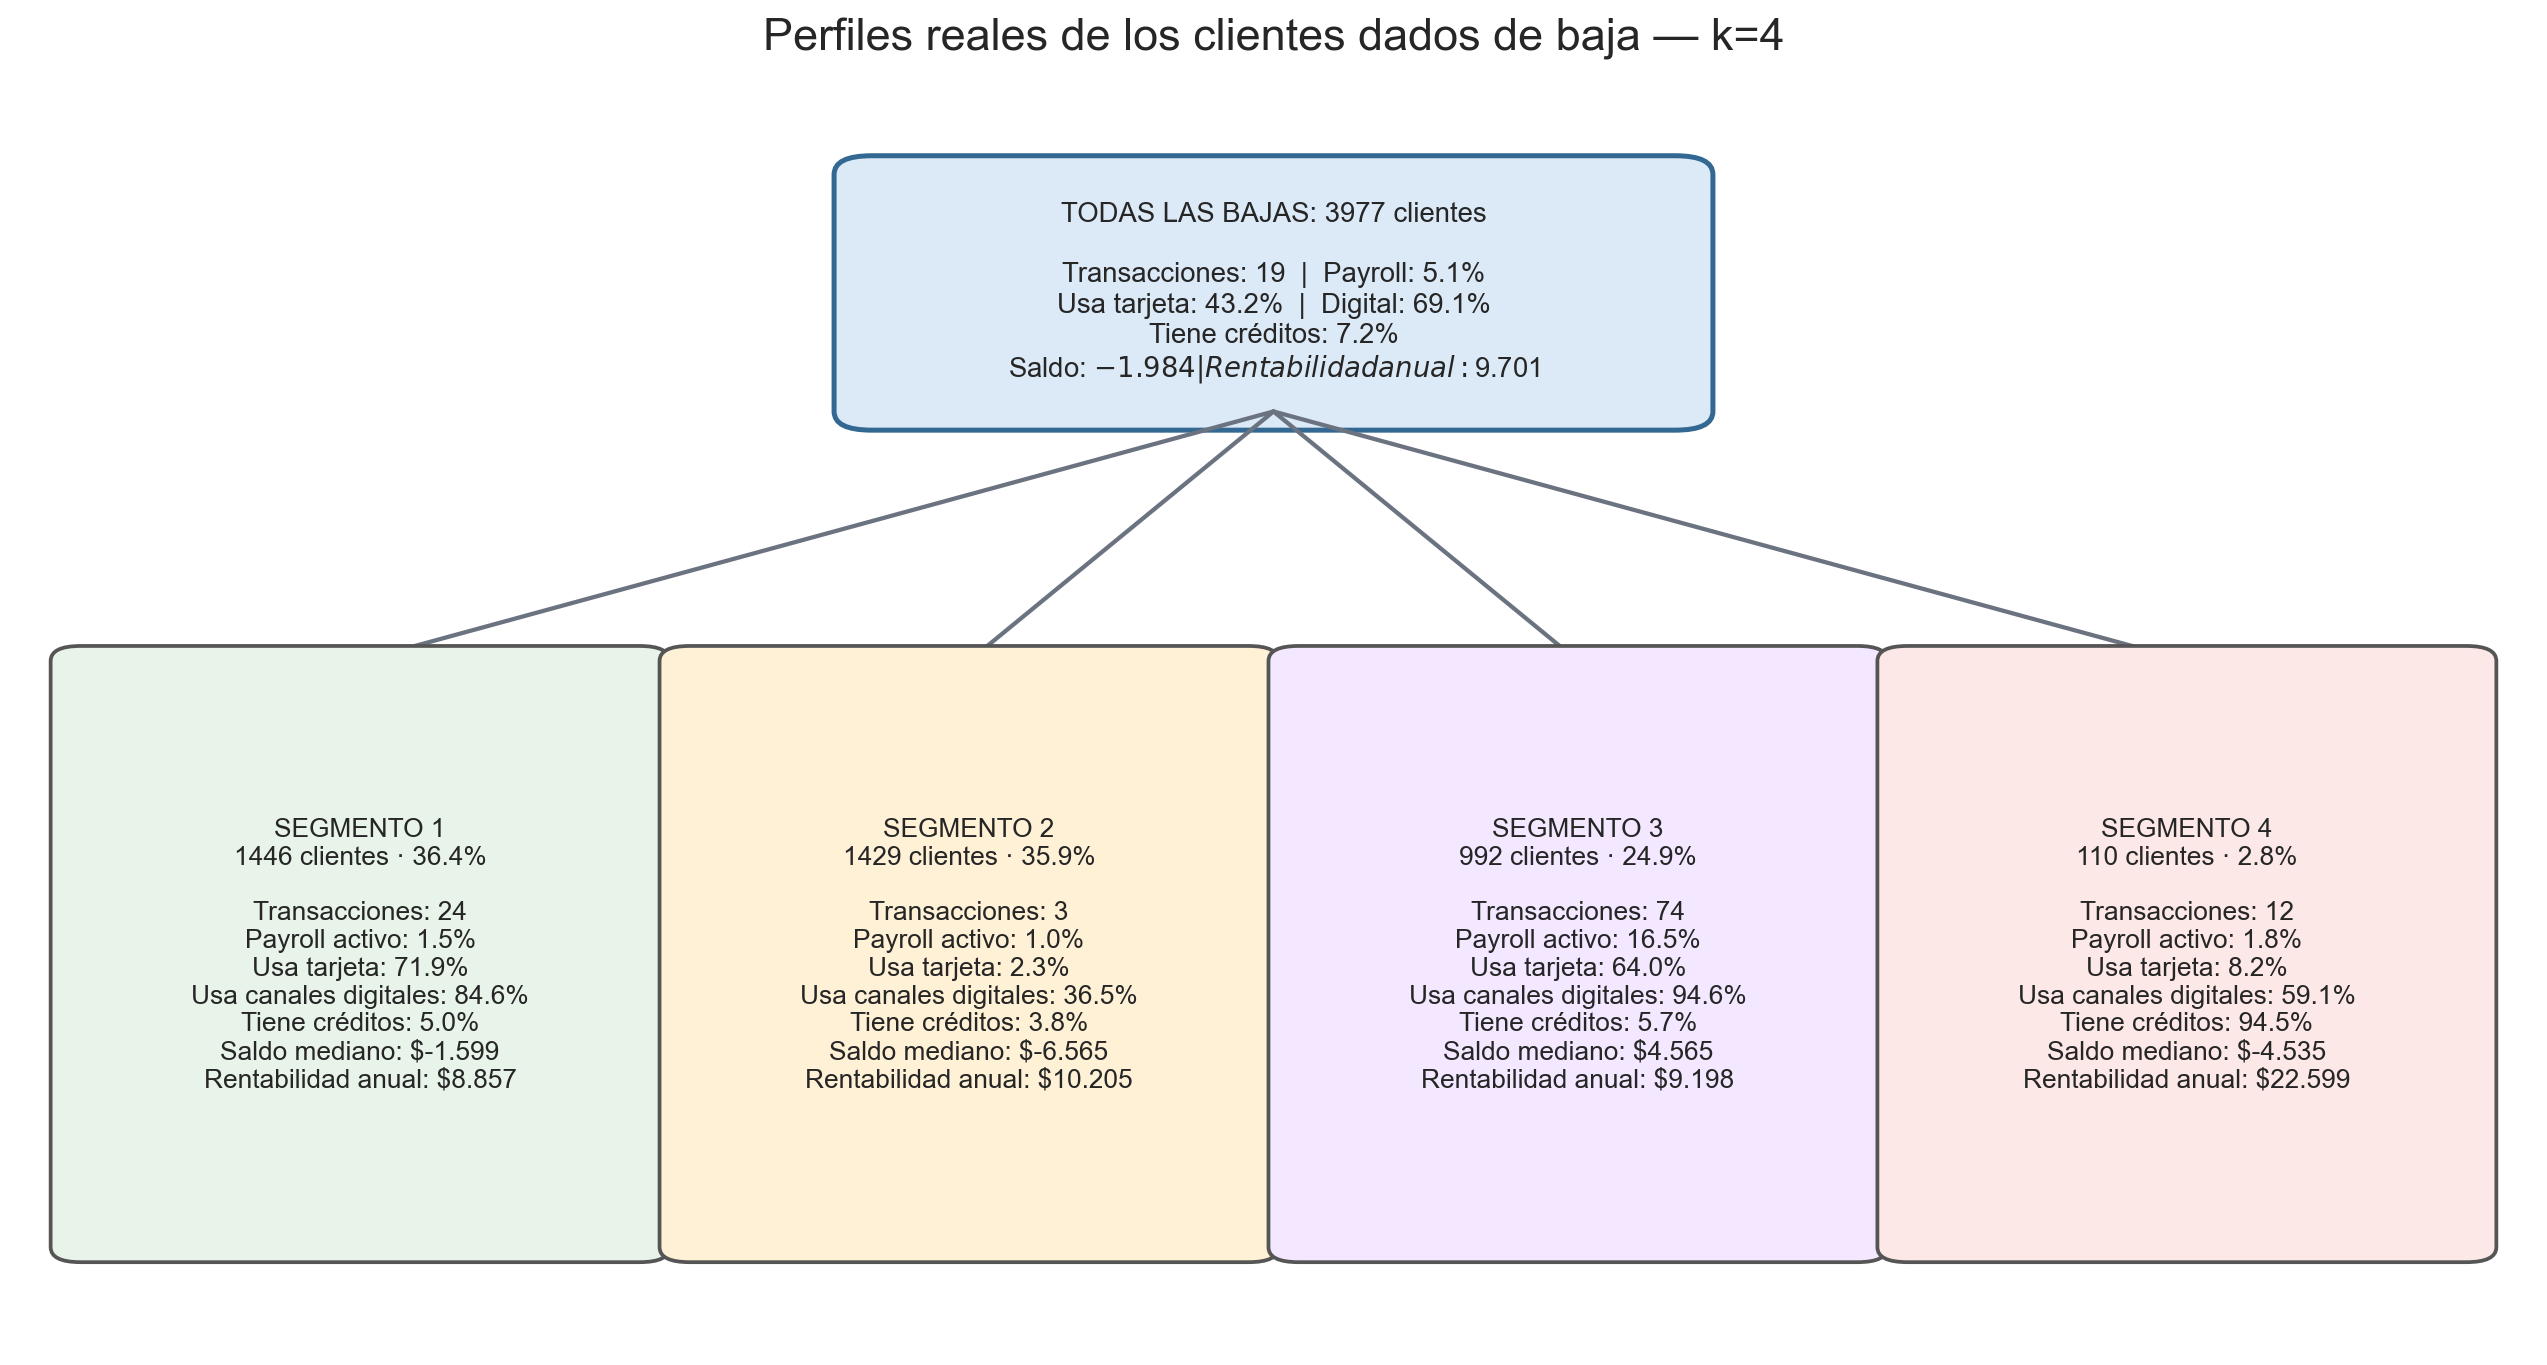

,cluster,clientes,mediana_transacciones,porcentaje_payroll,porcentaje_usa_tarjeta,porcentaje_digital,porcentaje_credito,mediana_saldo,mediana_rentabilidad_anual,porcentaje_clientes
0,1,1446,24.0,1.521438,71.922545,84.647303,4.979253,-1598.90,8857.280,36.359065
1,2,1429,3.0,1.049685,2.309307,36.459062,3.848845,-6564.97,10205.000,35.931607
2,3,992,74.0,16.532258,64.012097,94.556452,5.745968,4564.66,9197.870,24.943425
3,4,110,12.0,1.818182,8.181818,59.090909,94.545455,-4534.59,22598.625,2.765904


In [189]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import FancyBboxPatch, ConnectionPatch
from IPython.display import Image, display


# ============================================================
# 1. Elegimos temporalmente una segmentación para visualizar
# ============================================================

K_A_EXPLICAR = 4


# ============================================================
# 2. Recuperamos la última observación de cada cliente dado de baja
# ============================================================

base_t0 = (
    df_rf.loc[df_rf["grupo"] == 1]
    .sort_values(["numero_de_cliente", "foto_mes"])
    .groupby("numero_de_cliente", as_index=False)
    .tail(1)
    .copy()
)


# ============================================================
# 3. Incorporamos el cluster obtenido
# ============================================================

etiquetas = soluciones_k[K_A_EXPLICAR]["etiquetas"]

if isinstance(etiquetas, pd.Series):
    serie_cluster = etiquetas.copy()
else:
    serie_cluster = pd.Series(
        etiquetas,
        index=perfiles_hojas_bajas.index
    )

# Normalizamos el identificador para evitar problemas float/int.
serie_cluster.index = serie_cluster.index.astype("int64")

base_t0["id_auxiliar"] = (
    base_t0["numero_de_cliente"]
    .astype("int64")
)

base_t0["cluster"] = (
    base_t0["id_auxiliar"]
    .map(serie_cluster)
)

assert base_t0["cluster"].notna().all(), (
    "Hay clientes sin cluster asignado."
)


# ============================================================
# 4. Creamos indicadores fáciles de interpretar
# ============================================================

base_t0["payroll_activo"] = (
    base_t0["cpayroll_trx"].fillna(0) > 0
).astype(int)

base_t0["usa_tarjeta"] = (
    base_t0["tarjetas_transacciones"].fillna(0) > 0
).astype(int)

base_t0["usa_digital"] = (
    base_t0["transacciones_digitales"].fillna(0) > 0
).astype(int)

base_t0["tiene_credito"] = (
    base_t0["cantidad_creditos"].fillna(0) > 0
).astype(int)


# ============================================================
# 5. Resumimos cada segmento con valores reales
# ============================================================

resumen_clusters = (
    base_t0
    .groupby("cluster", as_index=False)
    .agg(
        clientes=("numero_de_cliente", "size"),
        mediana_transacciones=("ctrx_quarter", "median"),
        porcentaje_payroll=("payroll_activo", "mean"),
        porcentaje_usa_tarjeta=("usa_tarjeta", "mean"),
        porcentaje_digital=("usa_digital", "mean"),
        porcentaje_credito=("tiene_credito", "mean"),
        mediana_saldo=("mcuentas_saldo", "median"),
        mediana_rentabilidad_anual=(
            "mrentabilidad_annual",
            "median"
        ),
    )
)

resumen_clusters["porcentaje_clientes"] = (
    100 * resumen_clusters["clientes"] / len(base_t0)
)

for columna in [
    "porcentaje_payroll",
    "porcentaje_usa_tarjeta",
    "porcentaje_digital",
    "porcentaje_credito",
]:
    resumen_clusters[columna] *= 100


# Perfil general: sirve como punto de comparación.
perfil_general = {
    "clientes": len(base_t0),
    "mediana_transacciones": base_t0["ctrx_quarter"].median(),
    "porcentaje_payroll": 100 * base_t0["payroll_activo"].mean(),
    "porcentaje_usa_tarjeta": 100 * base_t0["usa_tarjeta"].mean(),
    "porcentaje_digital": 100 * base_t0["usa_digital"].mean(),
    "porcentaje_credito": 100 * base_t0["tiene_credito"].mean(),
    "mediana_saldo": base_t0["mcuentas_saldo"].median(),
    "mediana_rentabilidad_anual": (
        base_t0["mrentabilidad_annual"].median()
    ),
}


# ============================================================
# 6. Funciones de formato
# ============================================================

def formatear_numero(valor):
    return f"{valor:,.0f}".replace(",", ".")


def texto_perfil(fila, incluir_porcentaje=True):

    titulo = f"SEGMENTO {int(fila['cluster'])}"

    if incluir_porcentaje:
        titulo += (
            f"\n{int(fila['clientes'])} clientes"
            f" · {fila['porcentaje_clientes']:.1f}%"
        )

    return (
        f"{titulo}\n\n"
        f"Transacciones: {fila['mediana_transacciones']:.0f}\n"
        f"Payroll activo: {fila['porcentaje_payroll']:.1f}%\n"
        f"Usa tarjeta: {fila['porcentaje_usa_tarjeta']:.1f}%\n"
        f"Usa canales digitales: {fila['porcentaje_digital']:.1f}%\n"
        f"Tiene créditos: {fila['porcentaje_credito']:.1f}%\n"
        f"Saldo mediano: ${formatear_numero(fila['mediana_saldo'])}\n"
        f"Rentabilidad anual: "
        f"${formatear_numero(fila['mediana_rentabilidad_anual'])}"
    )


# ============================================================
# 7. Dibujamos el árbol
# ============================================================

fig, ax = plt.subplots(figsize=(18, 9))

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

ax.set_title(
    f"Perfiles reales de los clientes dados de baja — k={K_A_EXPLICAR}",
    fontsize=18,
    pad=20
)

# Caja general
x_general = 0.34
y_general = 0.75
ancho_general = 0.32
alto_general = 0.19

caja_general = FancyBboxPatch(
    (x_general, y_general),
    ancho_general,
    alto_general,
    boxstyle="round,pad=0.015",
    facecolor="#DCEAF7",
    edgecolor="#326891",
    linewidth=2
)

ax.add_patch(caja_general)

texto_general = (
    f"TODAS LAS BAJAS: {perfil_general['clientes']} clientes\n\n"
    f"Transacciones: {perfil_general['mediana_transacciones']:.0f}  |  "
    f"Payroll: {perfil_general['porcentaje_payroll']:.1f}%\n"
    f"Usa tarjeta: {perfil_general['porcentaje_usa_tarjeta']:.1f}%  |  "
    f"Digital: {perfil_general['porcentaje_digital']:.1f}%\n"
    f"Tiene créditos: {perfil_general['porcentaje_credito']:.1f}%\n"
    f"Saldo: ${formatear_numero(perfil_general['mediana_saldo'])}  |  "
    f"Rentabilidad anual: "
    f"${formatear_numero(perfil_general['mediana_rentabilidad_anual'])}"
)

ax.text(
    x_general + ancho_general / 2,
    y_general + alto_general / 2,
    texto_general,
    ha="center",
    va="center",
    fontsize=11
)

# Cajas de clusters
cantidad_clusters = len(resumen_clusters)

margen = 0.025
separacion = 0.02
ancho_cluster = (
    1 - 2 * margen - (cantidad_clusters - 1) * separacion
) / cantidad_clusters

y_cluster = 0.08
alto_cluster = 0.47

colores = [
    "#E8F4EA",
    "#FFF1D6",
    "#F3E8FF",
    "#FCE8E6",
    "#E6F4F1",
]

for posicion, (_, fila) in enumerate(
    resumen_clusters.sort_values("cluster").iterrows()
):
    x_cluster = margen + posicion * (
        ancho_cluster + separacion
    )

    # Flecha desde la población general.
    flecha = ConnectionPatch(
        xyA=(
            x_general + ancho_general / 2,
            y_general
        ),
        xyB=(
            x_cluster + ancho_cluster / 2,
            y_cluster + alto_cluster
        ),
        coordsA="data",
        coordsB="data",
        axesA=ax,
        axesB=ax,
        arrowstyle="-|>",
        linewidth=1.7,
        color="#6B7280",
        connectionstyle="arc3,rad=0.0"
    )

    ax.add_artist(flecha)

    caja_cluster = FancyBboxPatch(
        (x_cluster, y_cluster),
        ancho_cluster,
        alto_cluster,
        boxstyle="round,pad=0.012",
        facecolor=colores[posicion % len(colores)],
        edgecolor="#555555",
        linewidth=1.5
    )

    ax.add_patch(caja_cluster)

    ax.text(
        x_cluster + ancho_cluster / 2,
        y_cluster + alto_cluster / 2,
        texto_perfil(fila),
        ha="center",
        va="center",
        fontsize=10.5
    )

ruta_arbol = (
    "/Users/manuelmarasco/Desktop/dmeyf402/"
    "arbol_perfiles_k4.png"
)

plt.savefig(
    ruta_arbol,
    dpi=180,
    bbox_inches="tight"
)

plt.close()

display(Image(filename=ruta_arbol))

resumen_clusters

![Árbol de perfiles](arbol_perfiles_k4.png)

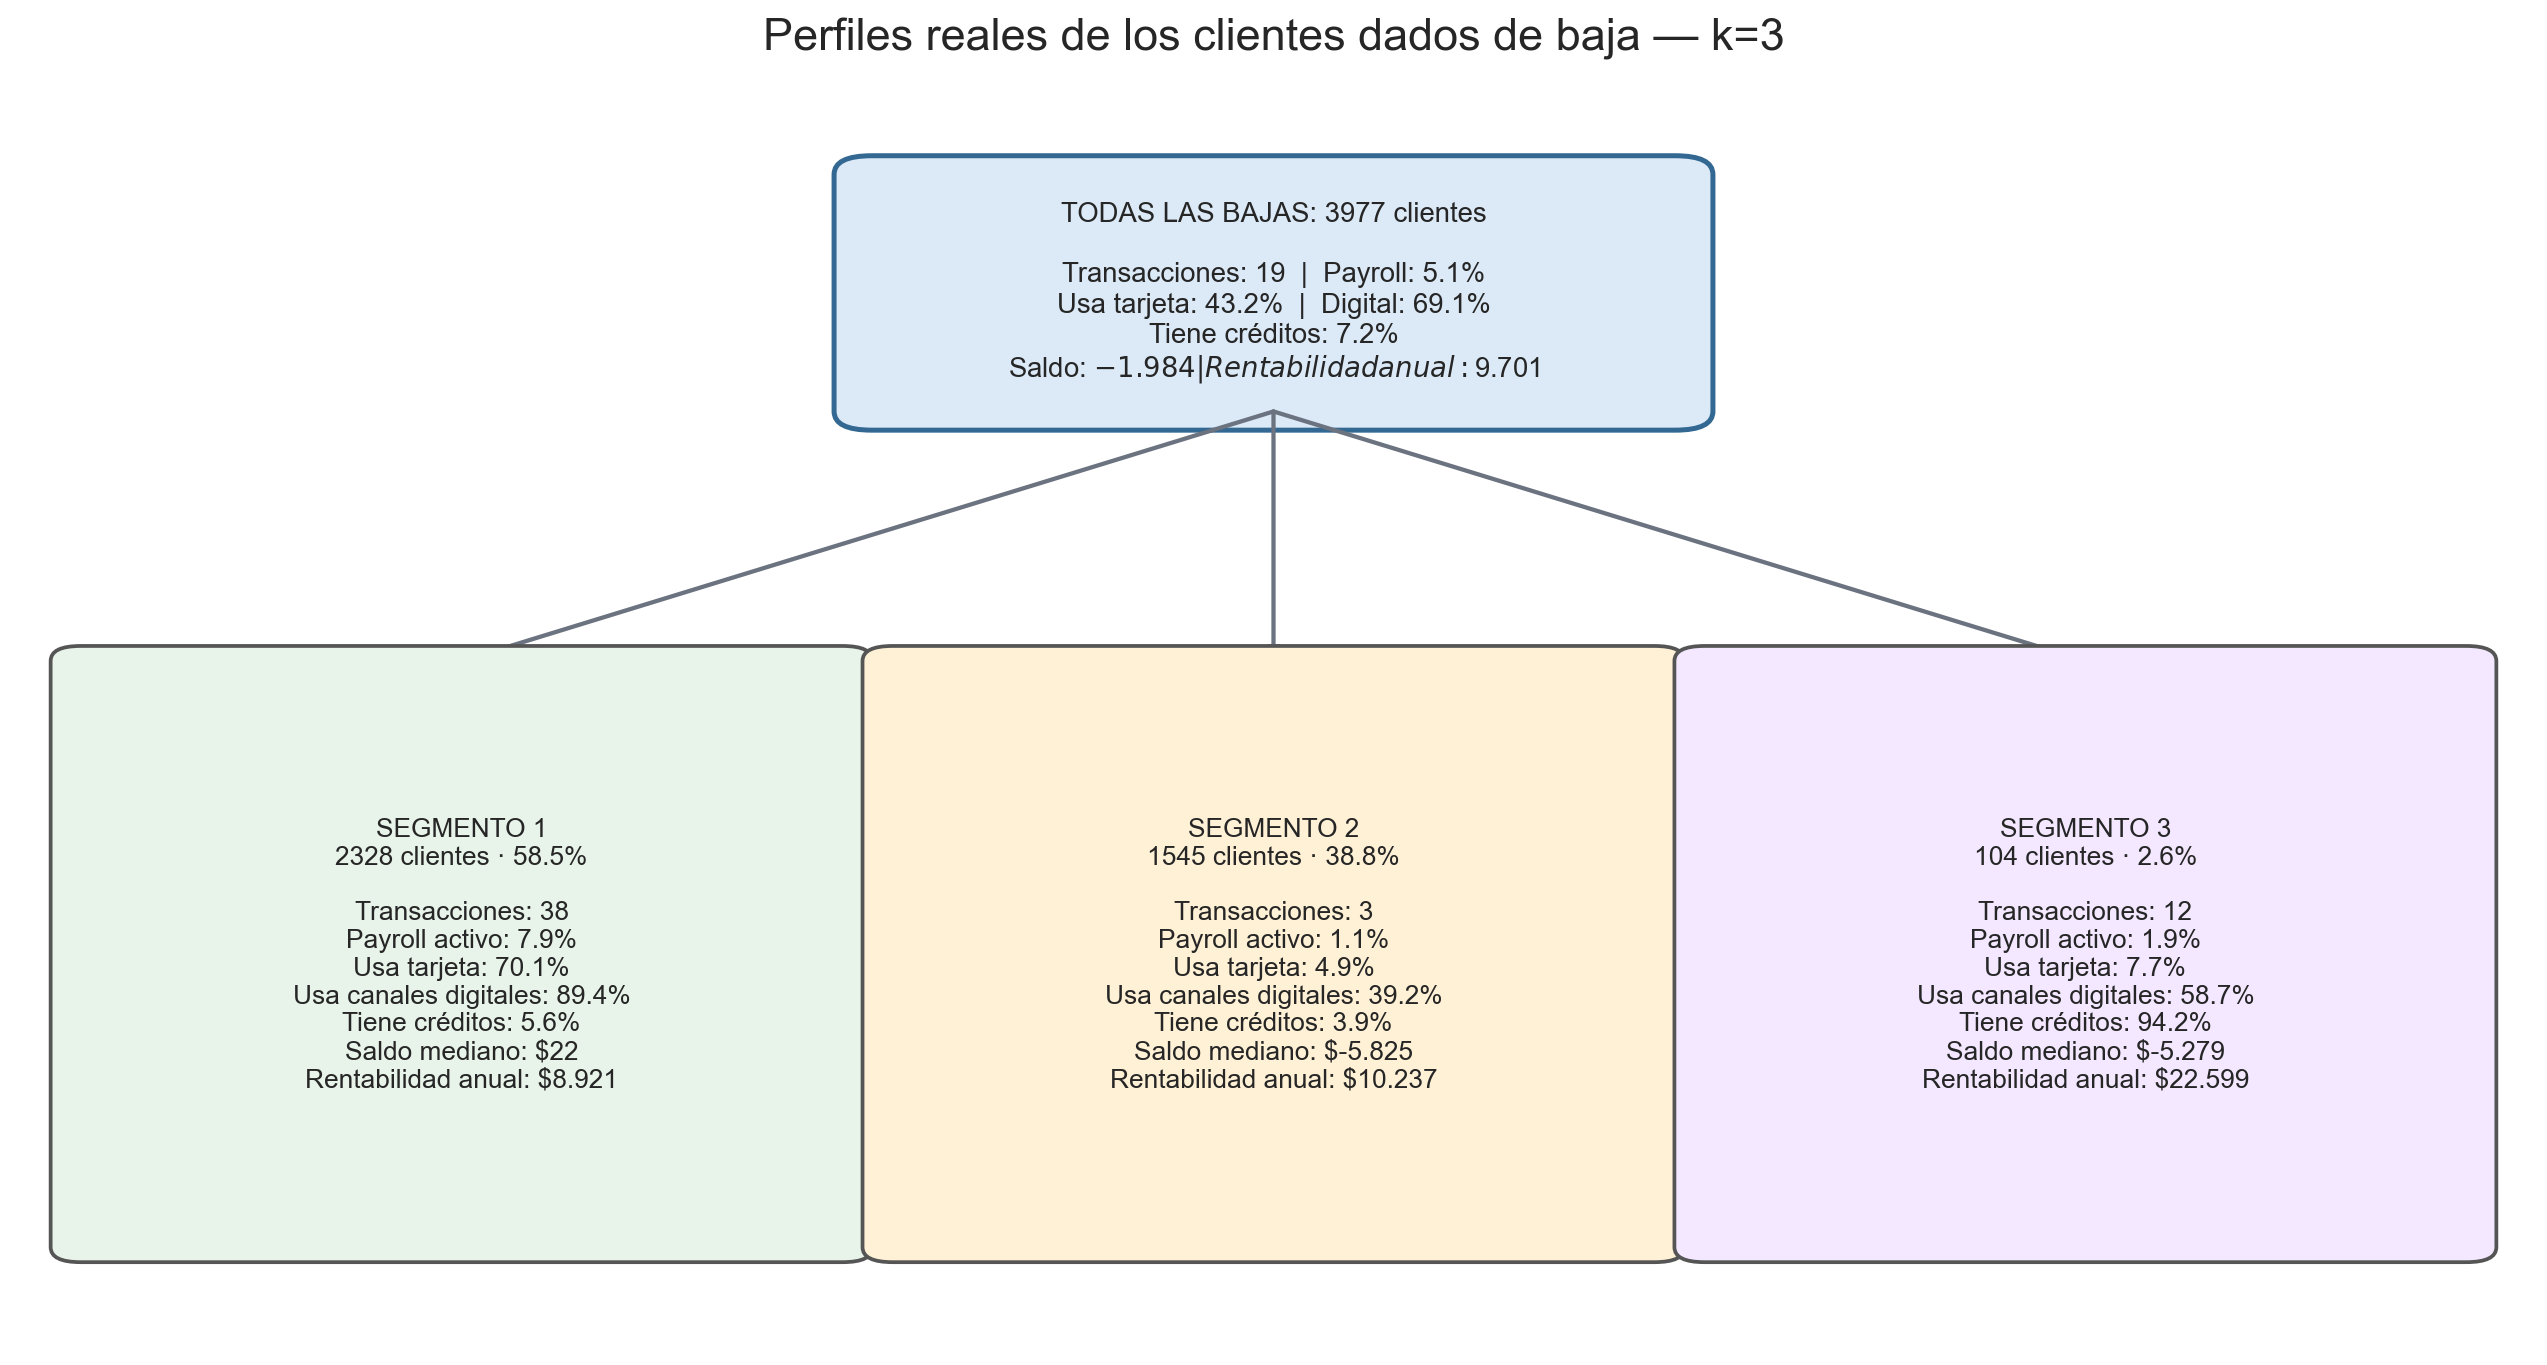

,cluster,clientes,mediana_transacciones,porcentaje_payroll,porcentaje_usa_tarjeta,porcentaje_digital,porcentaje_credito,mediana_saldo,mediana_rentabilidad_anual,porcentaje_clientes
0,1,2328,38.0,7.903780,70.146048,89.432990,5.584192,21.765,8920.670,58.536585
1,2,1545,3.0,1.100324,4.919094,39.158576,3.883495,-5824.630,10237.360,38.848378
2,3,104,11.5,1.923077,7.692308,58.653846,94.230769,-5278.650,22598.625,2.615036


In [190]:
# ============================================================
# 1. Elegimos temporalmente una segmentación para visualizar
# ============================================================

K_A_EXPLICAR = 3


# ============================================================
# 2. Recuperamos la última observación de cada cliente dado de baja
# ============================================================

base_t0 = (
    df_rf.loc[df_rf["grupo"] == 1]
    .sort_values(["numero_de_cliente", "foto_mes"])
    .groupby("numero_de_cliente", as_index=False)
    .tail(1)
    .copy()
)


# ============================================================
# 3. Incorporamos el cluster obtenido
# ============================================================

etiquetas = soluciones_k[K_A_EXPLICAR]["etiquetas"]

if isinstance(etiquetas, pd.Series):
    serie_cluster = etiquetas.copy()
else:
    serie_cluster = pd.Series(
        etiquetas,
        index=perfiles_hojas_bajas.index
    )

# Normalizamos el identificador para evitar problemas float/int.
serie_cluster.index = serie_cluster.index.astype("int64")

base_t0["id_auxiliar"] = (
    base_t0["numero_de_cliente"]
    .astype("int64")
)

base_t0["cluster"] = (
    base_t0["id_auxiliar"]
    .map(serie_cluster)
)

assert base_t0["cluster"].notna().all(), (
    "Hay clientes sin cluster asignado."
)


# ============================================================
# 4. Creamos indicadores fáciles de interpretar
# ============================================================

base_t0["payroll_activo"] = (
    base_t0["cpayroll_trx"].fillna(0) > 0
).astype(int)

base_t0["usa_tarjeta"] = (
    base_t0["tarjetas_transacciones"].fillna(0) > 0
).astype(int)

base_t0["usa_digital"] = (
    base_t0["transacciones_digitales"].fillna(0) > 0
).astype(int)

base_t0["tiene_credito"] = (
    base_t0["cantidad_creditos"].fillna(0) > 0
).astype(int)


# ============================================================
# 5. Resumimos cada segmento con valores reales
# ============================================================

resumen_clusters = (
    base_t0
    .groupby("cluster", as_index=False)
    .agg(
        clientes=("numero_de_cliente", "size"),
        mediana_transacciones=("ctrx_quarter", "median"),
        porcentaje_payroll=("payroll_activo", "mean"),
        porcentaje_usa_tarjeta=("usa_tarjeta", "mean"),
        porcentaje_digital=("usa_digital", "mean"),
        porcentaje_credito=("tiene_credito", "mean"),
        mediana_saldo=("mcuentas_saldo", "median"),
        mediana_rentabilidad_anual=(
            "mrentabilidad_annual",
            "median"
        ),
    )
)

resumen_clusters["porcentaje_clientes"] = (
    100 * resumen_clusters["clientes"] / len(base_t0)
)

for columna in [
    "porcentaje_payroll",
    "porcentaje_usa_tarjeta",
    "porcentaje_digital",
    "porcentaje_credito",
]:
    resumen_clusters[columna] *= 100


# Perfil general: sirve como punto de comparación.
perfil_general = {
    "clientes": len(base_t0),
    "mediana_transacciones": base_t0["ctrx_quarter"].median(),
    "porcentaje_payroll": 100 * base_t0["payroll_activo"].mean(),
    "porcentaje_usa_tarjeta": 100 * base_t0["usa_tarjeta"].mean(),
    "porcentaje_digital": 100 * base_t0["usa_digital"].mean(),
    "porcentaje_credito": 100 * base_t0["tiene_credito"].mean(),
    "mediana_saldo": base_t0["mcuentas_saldo"].median(),
    "mediana_rentabilidad_anual": (
        base_t0["mrentabilidad_annual"].median()
    ),
}


# ============================================================
# 6. Funciones de formato
# ============================================================

def formatear_numero(valor):
    return f"{valor:,.0f}".replace(",", ".")


def texto_perfil(fila, incluir_porcentaje=True):

    titulo = f"SEGMENTO {int(fila['cluster'])}"

    if incluir_porcentaje:
        titulo += (
            f"\n{int(fila['clientes'])} clientes"
            f" · {fila['porcentaje_clientes']:.1f}%"
        )

    return (
        f"{titulo}\n\n"
        f"Transacciones: {fila['mediana_transacciones']:.0f}\n"
        f"Payroll activo: {fila['porcentaje_payroll']:.1f}%\n"
        f"Usa tarjeta: {fila['porcentaje_usa_tarjeta']:.1f}%\n"
        f"Usa canales digitales: {fila['porcentaje_digital']:.1f}%\n"
        f"Tiene créditos: {fila['porcentaje_credito']:.1f}%\n"
        f"Saldo mediano: ${formatear_numero(fila['mediana_saldo'])}\n"
        f"Rentabilidad anual: "
        f"${formatear_numero(fila['mediana_rentabilidad_anual'])}"
    )


# ============================================================
# 7. Dibujamos el árbol
# ============================================================

fig, ax = plt.subplots(figsize=(18, 9))

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

ax.set_title(
    f"Perfiles reales de los clientes dados de baja — k={K_A_EXPLICAR}",
    fontsize=18,
    pad=20
)

# Caja general
x_general = 0.34
y_general = 0.75
ancho_general = 0.32
alto_general = 0.19

caja_general = FancyBboxPatch(
    (x_general, y_general),
    ancho_general,
    alto_general,
    boxstyle="round,pad=0.015",
    facecolor="#DCEAF7",
    edgecolor="#326891",
    linewidth=2
)

ax.add_patch(caja_general)

texto_general = (
    f"TODAS LAS BAJAS: {perfil_general['clientes']} clientes\n\n"
    f"Transacciones: {perfil_general['mediana_transacciones']:.0f}  |  "
    f"Payroll: {perfil_general['porcentaje_payroll']:.1f}%\n"
    f"Usa tarjeta: {perfil_general['porcentaje_usa_tarjeta']:.1f}%  |  "
    f"Digital: {perfil_general['porcentaje_digital']:.1f}%\n"
    f"Tiene créditos: {perfil_general['porcentaje_credito']:.1f}%\n"
    f"Saldo: ${formatear_numero(perfil_general['mediana_saldo'])}  |  "
    f"Rentabilidad anual: "
    f"${formatear_numero(perfil_general['mediana_rentabilidad_anual'])}"
)

ax.text(
    x_general + ancho_general / 2,
    y_general + alto_general / 2,
    texto_general,
    ha="center",
    va="center",
    fontsize=11
)

# Cajas de clusters
cantidad_clusters = len(resumen_clusters)

margen = 0.025
separacion = 0.02
ancho_cluster = (
    1 - 2 * margen - (cantidad_clusters - 1) * separacion
) / cantidad_clusters

y_cluster = 0.08
alto_cluster = 0.47

colores = [
    "#E8F4EA",
    "#FFF1D6",
    "#F3E8FF",
    "#FCE8E6",
    "#E6F4F1",
]

for posicion, (_, fila) in enumerate(
    resumen_clusters.sort_values("cluster").iterrows()
):
    x_cluster = margen + posicion * (
        ancho_cluster + separacion
    )

    # Flecha desde la población general.
    flecha = ConnectionPatch(
        xyA=(
            x_general + ancho_general / 2,
            y_general
        ),
        xyB=(
            x_cluster + ancho_cluster / 2,
            y_cluster + alto_cluster
        ),
        coordsA="data",
        coordsB="data",
        axesA=ax,
        axesB=ax,
        arrowstyle="-|>",
        linewidth=1.7,
        color="#6B7280",
        connectionstyle="arc3,rad=0.0"
    )

    ax.add_artist(flecha)

    caja_cluster = FancyBboxPatch(
        (x_cluster, y_cluster),
        ancho_cluster,
        alto_cluster,
        boxstyle="round,pad=0.012",
        facecolor=colores[posicion % len(colores)],
        edgecolor="#555555",
        linewidth=1.5
    )

    ax.add_patch(caja_cluster)

    ax.text(
        x_cluster + ancho_cluster / 2,
        y_cluster + alto_cluster / 2,
        texto_perfil(fila),
        ha="center",
        va="center",
        fontsize=10.5
    )

ruta_arbol = (
    "/Users/manuelmarasco/Desktop/dmeyf402/"
    "arbol_perfiles_k3.png"
)

plt.savefig(
    ruta_arbol,
    dpi=180,
    bbox_inches="tight"
)

plt.close()

display(Image(filename=ruta_arbol))

resumen_clusters

![Árbol de perfiles](arbol_perfiles_k3.png)

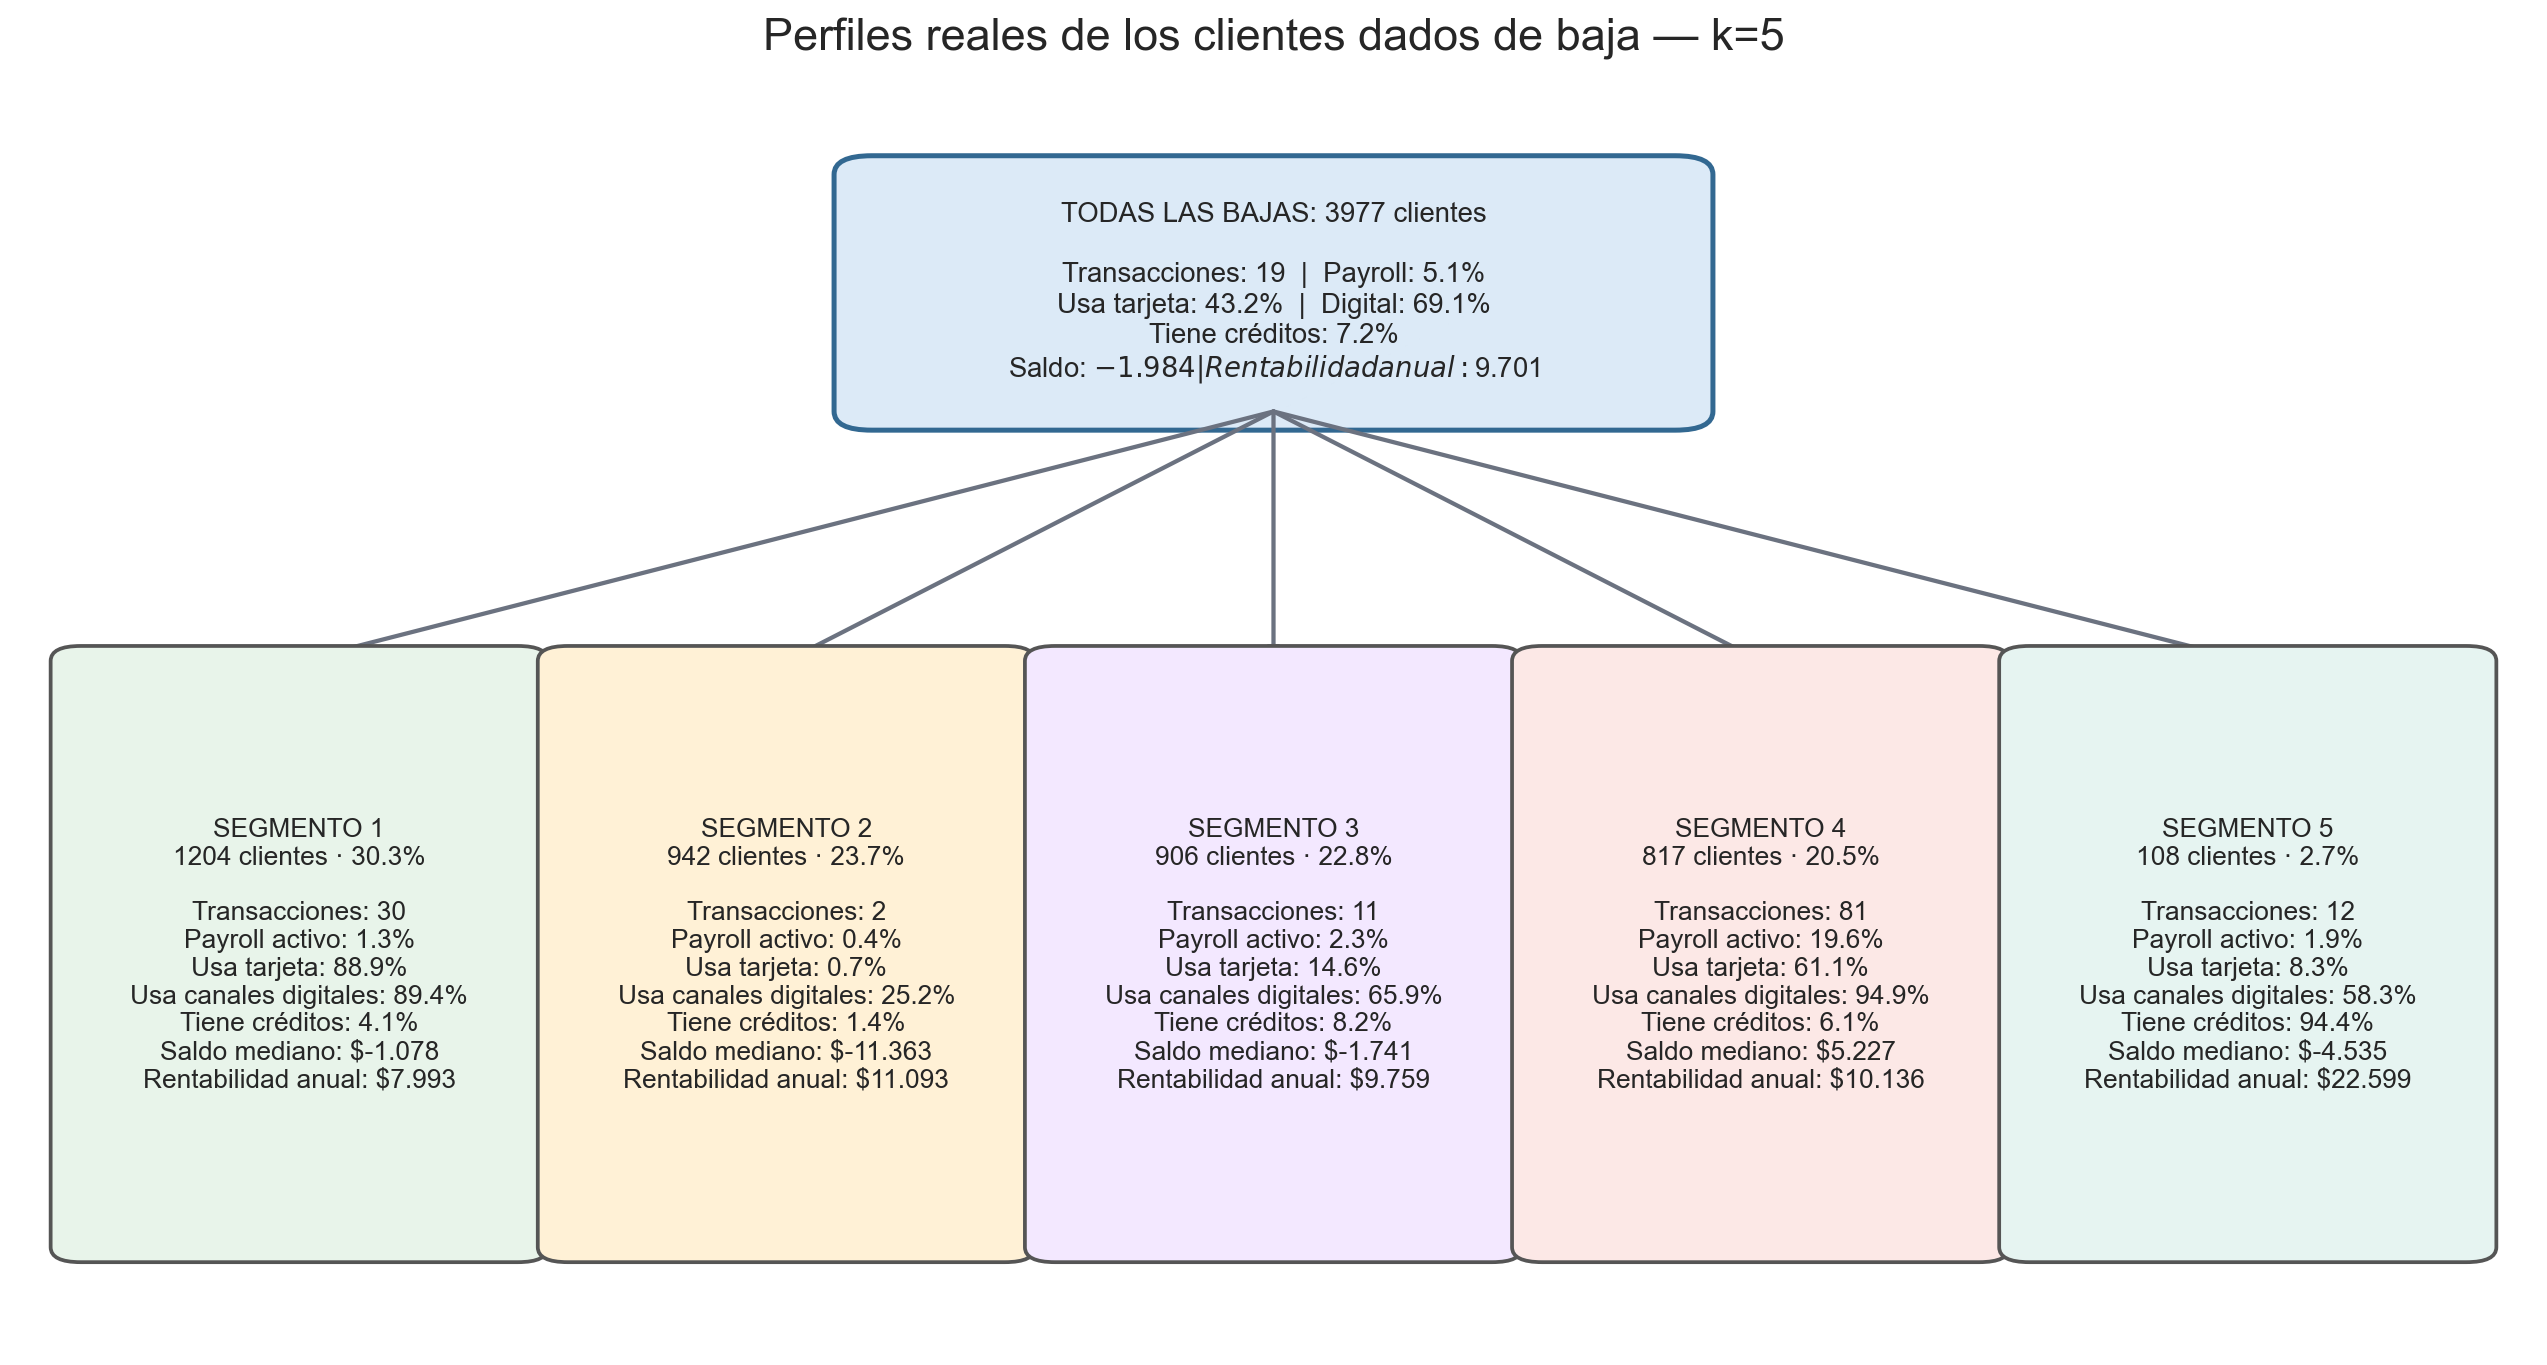

,cluster,clientes,mediana_transacciones,porcentaje_payroll,porcentaje_usa_tarjeta,porcentaje_digital,porcentaje_credito,mediana_saldo,mediana_rentabilidad_anual,porcentaje_clientes
0,1,1204,30.5,1.328904,88.870432,89.368771,4.069767,-1078.11,7993.440,30.274076
1,2,942,2.0,0.424628,0.743100,25.159236,1.380042,-11363.15,11093.105,23.686196
2,3,906,11.0,2.317881,14.569536,65.894040,8.167770,-1740.81,9759.240,22.780991
3,4,817,81.0,19.583843,61.077111,94.859241,6.119951,5227.23,10135.840,20.543123
4,5,108,11.5,1.851852,8.333333,58.333333,94.444444,-4534.59,22598.625,2.715615


In [191]:
# ============================================================
# 1. Elegimos temporalmente una segmentación para visualizar
# ============================================================

K_A_EXPLICAR = 5


# ============================================================
# 2. Recuperamos la última observación de cada cliente dado de baja
# ============================================================

base_t0 = (
    df_rf.loc[df_rf["grupo"] == 1]
    .sort_values(["numero_de_cliente", "foto_mes"])
    .groupby("numero_de_cliente", as_index=False)
    .tail(1)
    .copy()
)


# ============================================================
# 3. Incorporamos el cluster obtenido
# ============================================================

etiquetas = soluciones_k[K_A_EXPLICAR]["etiquetas"]

if isinstance(etiquetas, pd.Series):
    serie_cluster = etiquetas.copy()
else:
    serie_cluster = pd.Series(
        etiquetas,
        index=perfiles_hojas_bajas.index
    )

# Normalizamos el identificador para evitar problemas float/int.
serie_cluster.index = serie_cluster.index.astype("int64")

base_t0["id_auxiliar"] = (
    base_t0["numero_de_cliente"]
    .astype("int64")
)

base_t0["cluster"] = (
    base_t0["id_auxiliar"]
    .map(serie_cluster)
)

assert base_t0["cluster"].notna().all(), (
    "Hay clientes sin cluster asignado."
)


# ============================================================
# 4. Creamos indicadores fáciles de interpretar
# ============================================================

base_t0["payroll_activo"] = (
    base_t0["cpayroll_trx"].fillna(0) > 0
).astype(int)

base_t0["usa_tarjeta"] = (
    base_t0["tarjetas_transacciones"].fillna(0) > 0
).astype(int)

base_t0["usa_digital"] = (
    base_t0["transacciones_digitales"].fillna(0) > 0
).astype(int)

base_t0["tiene_credito"] = (
    base_t0["cantidad_creditos"].fillna(0) > 0
).astype(int)


# ============================================================
# 5. Resumimos cada segmento con valores reales
# ============================================================

resumen_clusters = (
    base_t0
    .groupby("cluster", as_index=False)
    .agg(
        clientes=("numero_de_cliente", "size"),
        mediana_transacciones=("ctrx_quarter", "median"),
        porcentaje_payroll=("payroll_activo", "mean"),
        porcentaje_usa_tarjeta=("usa_tarjeta", "mean"),
        porcentaje_digital=("usa_digital", "mean"),
        porcentaje_credito=("tiene_credito", "mean"),
        mediana_saldo=("mcuentas_saldo", "median"),
        mediana_rentabilidad_anual=(
            "mrentabilidad_annual",
            "median"
        ),
    )
)

resumen_clusters["porcentaje_clientes"] = (
    100 * resumen_clusters["clientes"] / len(base_t0)
)

for columna in [
    "porcentaje_payroll",
    "porcentaje_usa_tarjeta",
    "porcentaje_digital",
    "porcentaje_credito",
]:
    resumen_clusters[columna] *= 100


# Perfil general: sirve como punto de comparación.
perfil_general = {
    "clientes": len(base_t0),
    "mediana_transacciones": base_t0["ctrx_quarter"].median(),
    "porcentaje_payroll": 100 * base_t0["payroll_activo"].mean(),
    "porcentaje_usa_tarjeta": 100 * base_t0["usa_tarjeta"].mean(),
    "porcentaje_digital": 100 * base_t0["usa_digital"].mean(),
    "porcentaje_credito": 100 * base_t0["tiene_credito"].mean(),
    "mediana_saldo": base_t0["mcuentas_saldo"].median(),
    "mediana_rentabilidad_anual": (
        base_t0["mrentabilidad_annual"].median()
    ),
}


# ============================================================
# 6. Funciones de formato
# ============================================================

def formatear_numero(valor):
    return f"{valor:,.0f}".replace(",", ".")


def texto_perfil(fila, incluir_porcentaje=True):

    titulo = f"SEGMENTO {int(fila['cluster'])}"

    if incluir_porcentaje:
        titulo += (
            f"\n{int(fila['clientes'])} clientes"
            f" · {fila['porcentaje_clientes']:.1f}%"
        )

    return (
        f"{titulo}\n\n"
        f"Transacciones: {fila['mediana_transacciones']:.0f}\n"
        f"Payroll activo: {fila['porcentaje_payroll']:.1f}%\n"
        f"Usa tarjeta: {fila['porcentaje_usa_tarjeta']:.1f}%\n"
        f"Usa canales digitales: {fila['porcentaje_digital']:.1f}%\n"
        f"Tiene créditos: {fila['porcentaje_credito']:.1f}%\n"
        f"Saldo mediano: ${formatear_numero(fila['mediana_saldo'])}\n"
        f"Rentabilidad anual: "
        f"${formatear_numero(fila['mediana_rentabilidad_anual'])}"
    )


# ============================================================
# 7. Dibujamos el árbol
# ============================================================

fig, ax = plt.subplots(figsize=(18, 9))

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

ax.set_title(
    f"Perfiles reales de los clientes dados de baja — k={K_A_EXPLICAR}",
    fontsize=18,
    pad=20
)

# Caja general
x_general = 0.34
y_general = 0.75
ancho_general = 0.32
alto_general = 0.19

caja_general = FancyBboxPatch(
    (x_general, y_general),
    ancho_general,
    alto_general,
    boxstyle="round,pad=0.015",
    facecolor="#DCEAF7",
    edgecolor="#326891",
    linewidth=2
)

ax.add_patch(caja_general)

texto_general = (
    f"TODAS LAS BAJAS: {perfil_general['clientes']} clientes\n\n"
    f"Transacciones: {perfil_general['mediana_transacciones']:.0f}  |  "
    f"Payroll: {perfil_general['porcentaje_payroll']:.1f}%\n"
    f"Usa tarjeta: {perfil_general['porcentaje_usa_tarjeta']:.1f}%  |  "
    f"Digital: {perfil_general['porcentaje_digital']:.1f}%\n"
    f"Tiene créditos: {perfil_general['porcentaje_credito']:.1f}%\n"
    f"Saldo: ${formatear_numero(perfil_general['mediana_saldo'])}  |  "
    f"Rentabilidad anual: "
    f"${formatear_numero(perfil_general['mediana_rentabilidad_anual'])}"
)

ax.text(
    x_general + ancho_general / 2,
    y_general + alto_general / 2,
    texto_general,
    ha="center",
    va="center",
    fontsize=11
)

# Cajas de clusters
cantidad_clusters = len(resumen_clusters)

margen = 0.025
separacion = 0.02
ancho_cluster = (
    1 - 2 * margen - (cantidad_clusters - 1) * separacion
) / cantidad_clusters

y_cluster = 0.08
alto_cluster = 0.47

colores = [
    "#E8F4EA",
    "#FFF1D6",
    "#F3E8FF",
    "#FCE8E6",
    "#E6F4F1",
]

for posicion, (_, fila) in enumerate(
    resumen_clusters.sort_values("cluster").iterrows()
):
    x_cluster = margen + posicion * (
        ancho_cluster + separacion
    )

    # Flecha desde la población general.
    flecha = ConnectionPatch(
        xyA=(
            x_general + ancho_general / 2,
            y_general
        ),
        xyB=(
            x_cluster + ancho_cluster / 2,
            y_cluster + alto_cluster
        ),
        coordsA="data",
        coordsB="data",
        axesA=ax,
        axesB=ax,
        arrowstyle="-|>",
        linewidth=1.7,
        color="#6B7280",
        connectionstyle="arc3,rad=0.0"
    )

    ax.add_artist(flecha)

    caja_cluster = FancyBboxPatch(
        (x_cluster, y_cluster),
        ancho_cluster,
        alto_cluster,
        boxstyle="round,pad=0.012",
        facecolor=colores[posicion % len(colores)],
        edgecolor="#555555",
        linewidth=1.5
    )

    ax.add_patch(caja_cluster)

    ax.text(
        x_cluster + ancho_cluster / 2,
        y_cluster + alto_cluster / 2,
        texto_perfil(fila),
        ha="center",
        va="center",
        fontsize=10.5
    )

ruta_arbol = (
    "/Users/manuelmarasco/Desktop/dmeyf402/"
    "arbol_perfiles_k5.png"
)

plt.savefig(
    ruta_arbol,
    dpi=180,
    bbox_inches="tight"
)

plt.close()

display(Image(filename=ruta_arbol))

resumen_clusters

![Árbol de perfiles](arbol_perfiles_k5.png)

In [192]:
pd.set_option(
    "display.max_colwidth",
    None,
)

print(
    resumen_segmentaciones.to_string(
        index=False
    )
)

 k  cluster  clientes  porcentaje                                                                                                         atributos_definitorios
 3        1      2328   58.536585               mpagomiscuentas (lift 1.68); mtransferencias_emitidas_minimo_3 (lift 1.67); tarjetas_consumo_rango_3 (lift 1.67)
 3        2      1545   38.848378                                internet (lift 2.25); cdescubierto_preacordado (lift 2.24); tarjetas_cantidad_lag_1 (lift 1.97)
 3        3       104    2.615036                         mprestamos_personales (lift 23.98); cprestamos_personales (lift 20.78); cantidad_creditos (lift 19.22)
 4        1      1446   36.359065            mttarjeta_visa_debitos_automaticos (lift 1.79); ctarjeta_visa_transacciones (lift 1.79); Visa_cconsumos (lift 1.72)
 4        2      1429   35.931607                                cdescubierto_preacordado (lift 2.38); internet (lift 2.35); tarjetas_cantidad_lag_1 (lift 2.04)
 4        3       992   24.943425 

In [193]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score


# ============================================================
# 1. Una fila por cliente: último mes antes de abandonar
# ============================================================

base_explicacion = (
    df_rf.loc[df_rf["grupo"] == 1]
    .sort_values(["numero_de_cliente", "foto_mes"])
    .groupby("numero_de_cliente", as_index=False)
    .tail(1)
    .copy()
)

base_explicacion["id_auxiliar"] = (
    base_explicacion["numero_de_cliente"].astype("int64")
)


# ============================================================
# 2. Indicadores interpretables
# ============================================================

base_explicacion["payroll_activo"] = (
    base_explicacion["cpayroll_trx"].fillna(0) > 0
).astype(int)

base_explicacion["usa_tarjeta"] = (
    base_explicacion["tarjetas_transacciones"].fillna(0) > 0
).astype(int)

base_explicacion["usa_digital"] = (
    base_explicacion["transacciones_digitales"].fillna(0) > 0
).astype(int)

base_explicacion["tiene_credito"] = (
    base_explicacion["cantidad_creditos"].fillna(0) > 0
).astype(int)


variables_arbol = [
    "ctrx_quarter",
    "payroll_activo",
    "usa_tarjeta",
    "usa_digital",
    "tiene_credito",
    "mcuentas_saldo",
    "mrentabilidad_annual",
    "cproductos",
]

nombres_variables = [
    "Transacciones trimestrales",
    "Payroll activo",
    "Usa tarjeta",
    "Usa canales digitales",
    "Tiene crédito",
    "Saldo de cuentas",
    "Rentabilidad anual",
    "Cantidad de productos",
]

X_explicacion = (
    base_explicacion[variables_arbol]
    .replace([np.inf, -np.inf], np.nan)
)


# ============================================================
# 3. Evaluamos k=3, k=4 y k=5
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=214363
)

resultados = []
arboles = {}

fig, axes = plt.subplots(
    3,
    1,
    figsize=(25, 31)
)

for ax, k in zip(axes, [3, 4, 5]):

    etiquetas = soluciones_k[k]["etiquetas"]

    if isinstance(etiquetas, pd.Series):
        serie_cluster = etiquetas.copy()
    else:
        serie_cluster = pd.Series(
            etiquetas,
            index=perfiles_hojas_bajas.index
        )

    serie_cluster.index = serie_cluster.index.astype("int64")

    y_cluster = (
        base_explicacion["id_auxiliar"]
        .map(serie_cluster)
    )

    assert y_cluster.notna().all(), (
        f"Hay clientes sin cluster para k={k}"
    )

    # Árbol pequeño para que las reglas sigan siendo legibles.
    modelo_explicativo = Pipeline([
        (
            "imputacion",
            SimpleImputer(strategy="median")
        ),
        (
            "arbol",
            DecisionTreeClassifier(
                max_depth=4,
                min_samples_leaf=30,
                class_weight="balanced",
                random_state=214363
            )
        )
    ])

    # Fidelidad fuera de muestra.
    puntajes = cross_val_score(
        modelo_explicativo,
        X_explicacion,
        y_cluster,
        cv=cv,
        scoring="balanced_accuracy",
        n_jobs=-1
    )

    resultados.append({
        "k": k,
        "fidelidad_balanceada": puntajes.mean(),
        "desvio": puntajes.std(),
        "nivel_azar": 1 / k
    })

    # Ajustamos nuevamente con todos los clientes para dibujarlo.
    modelo_explicativo.fit(
        X_explicacion,
        y_cluster
    )

    arbol = modelo_explicativo.named_steps["arbol"]
    arboles[k] = modelo_explicativo

    nombres_clases = [
        f"Segmento {int(clase)}"
        for clase in arbol.classes_
    ]

    plot_tree(
        arbol,
        feature_names=nombres_variables,
        class_names=nombres_clases,
        filled=True,
        rounded=True,
        impurity=False,
        proportion=True,
        precision=2,
        fontsize=8,
        ax=ax
    )

    ax.set_title(
        f"Árbol explicativo para k={k} "
        f"— fidelidad balanceada: {puntajes.mean():.1%}",
        fontsize=16,
        pad=15
    )


plt.tight_layout()

ruta_arboles = (
    "/Users/manuelmarasco/Desktop/dmeyf402/"
    "arboles_explicativos_clusters.png"
)

plt.savefig(
    ruta_arboles,
    dpi=180,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 4. Tabla comparativa
# ============================================================

resultados_explicabilidad = pd.DataFrame(resultados)

resultados_explicabilidad[
    [
        "fidelidad_balanceada",
        "desvio",
        "nivel_azar"
    ]
] = resultados_explicabilidad[
    [
        "fidelidad_balanceada",
        "desvio",
        "nivel_azar"
    ]
].round(3)

resultados_explicabilidad

,k,fidelidad_balanceada,desvio,nivel_azar
0,3,0.885,0.018,0.333
1,4,0.785,0.022,0.250
2,5,0.712,0.008,0.200


La tabla ya muestra un patrón claro: al aumentar k, ganamos detalle pero perdemos una separación fácil de explicar.

Ahora sí tenemos un elemento objetivo: la fidelidad balanceada del árbol, es decir, cuánto logra reconstruir los clusters usando sólo ocho variables comprensibles.
- k=3: 88,5%. Separación muy clara, pero bastante general.
- k=4: 78,5%. Separación todavía clara y agrega un perfil útil.
- k=5: 71,2%. Sigue siendo superior al azar, pero existe más superposición.
El árbol muestra que la separación está apoyada principalmente en:

¿Tiene crédito?
├── Sí
│   └── Segmento pequeño, intensivo en créditos
│
└── No
    └── ¿Cuántas transacciones realiza?
        ├── Muy pocas
        │   └── Segmento desvinculado
        │
        └── Más transacciones
            ├── Alto payroll y mucha actividad
            │   └── Segmento activo con payroll
            │
            └── Uso de tarjeta y canales digitales
                └── Segmento activo sin payroll

Eso es, simplificado, lo que aparece en k=4.
Mi recomendación provisional es k=4, porque ofrece el mejor compromiso:
1. k=3 es más fácil de reconstruir, pero mezcla dos tipos de clientes activos.
2. k=4 separa cuatro perfiles comercialmente distintos:
   - digitales y tarjetarios sin payroll;
   - muy desvinculados;
   - muy activos con payroll;
   - clientes crediticios de alta rentabilidad.
3. k=5 agrega un perfil intermedio, pero baja la claridad a 71,2% y complica un video de cinco minutos.

Se eligieron manualmente manualmente porque eran los temas que más se habían repetido en nuestro EDA:
- ctrx_quarter: intensidad de actividad.
- payroll_activo: vínculo salarial.
- usa_tarjeta: utilización de tarjetas.
- usa_digital: relación digital.
- tiene_credito: vínculo crediticio.
- mcuentas_saldo: posición financiera.
- mrentabilidad_annual: valor económico.
- cproductos: profundidad de vinculación.

Ahor un cluster con todo para comparar: la idea sería tomar a los que se dieron de baja pero con el foto mes de la última vez que aparecieron, pero con lags y deltas del pasado.

In [194]:
%%sql

CREATE OR REPLACE TABLE base_bajas_t0_fe AS

SELECT
    p.numero_de_cliente,
    p.numero_evento,
    p.ultimo_mes_activo AS foto_mes_ancla,
    p.primer_mes_ausente,
    p.grupo_evento,

    fe.observaciones_hasta_mes,
    fe.meses_desde_observacion_anterior,

    CASE
        WHEN fe.observaciones_hasta_mes >= 3
         AND fe.ctrx_quarter_lag_1 IS NOT NULL
         AND fe.ctrx_quarter_lag_2 IS NOT NULL
        THEN 1
        ELSE 0
    END AS historia_3m_completa,

    fe.* EXCLUDE (
        numero_de_cliente,
        foto_mes,
        clase_ternaria,
        mes_0,
        observaciones_hasta_mes,
        meses_desde_observacion_anterior
    )

FROM poblacion_miranda AS p

INNER JOIN competencia_01_fe AS fe
    ON p.numero_de_cliente = fe.numero_de_cliente
   AND p.ultimo_mes_activo = fe.foto_mes

WHERE p.grupo_evento = 'estricta';

,Success


In [195]:
%%sql

SELECT
    COUNT(*) AS filas,
    COUNT(DISTINCT numero_de_cliente) AS clientes,
    COUNT(*) - COUNT(DISTINCT numero_de_cliente) AS duplicados,

    MIN(foto_mes_ancla) AS primer_mes_baja,
    MAX(foto_mes_ancla) AS ultimo_mes_baja,

    COUNT(*) FILTER (
        WHERE historia_3m_completa = 1
    ) AS clientes_con_historia_3m,

    COUNT(*) FILTER (
        WHERE historia_3m_completa = 0
    ) AS clientes_con_historia_parcial,

    COUNT(*) FILTER (
        WHERE grupo_evento <> 'estricta'
    ) AS filas_no_estrictas

FROM base_bajas_t0_fe;

,filas,clientes,duplicados,primer_mes_baja,ultimo_mes_baja,clientes_con_historia_3m,clientes_con_historia_parcial,filas_no_estrictas
0,3977,3977,0,202103,202106,1991,1986,0


In [196]:
%%sql

SELECT
    foto_mes_ancla,
    COUNT(*) AS clientes,
    SUM(historia_3m_completa) AS con_historia_3m,
    COUNT(*) - SUM(historia_3m_completa) AS con_historia_parcial

FROM base_bajas_t0_fe

GROUP BY foto_mes_ancla
ORDER BY foto_mes_ancla;

,foto_mes_ancla,clientes,con_historia_3m,con_historia_parcial
0,202103,1013,0.0,1013.0
1,202104,955,0.0,955.0
2,202105,1138,1129.0,9.0
3,202106,871,862.0,9.0


In [197]:
%%sql

CREATE OR REPLACE TABLE base_bajas_t0_fe_3m AS

SELECT *
FROM base_bajas_t0_fe
WHERE historia_3m_completa = 1;

,Success


In [198]:
%%sql

SELECT
    COUNT(*) AS filas,
    COUNT(DISTINCT numero_de_cliente) AS clientes,
    COUNT(*) - COUNT(DISTINCT numero_de_cliente) AS duplicados,
    MIN(foto_mes_ancla) AS primer_mes,
    MAX(foto_mes_ancla) AS ultimo_mes,

    COUNT(*) FILTER (
        WHERE ctrx_quarter_lag_1 IS NULL
           OR ctrx_quarter_lag_2 IS NULL
    ) AS historia_transaccional_incompleta

FROM base_bajas_t0_fe_3m;

,filas,clientes,duplicados,primer_mes,ultimo_mes,historia_transaccional_incompleta
0,1991,1991,0,202105,202106,0


In [199]:
%%sql

CREATE OR REPLACE TABLE base_fieles_t0_fe_3m AS

WITH candidatos AS (

    SELECT
        fe.numero_de_cliente,
        fe.foto_mes

    FROM competencia_01_fe AS fe

    WHERE fe.foto_mes IN (202105, 202106)
      AND fe.clase_ternaria = 'CONTINUA'
      AND fe.observaciones_hasta_mes >= 3
      AND fe.ctrx_quarter_lag_1 IS NOT NULL
      AND fe.ctrx_quarter_lag_2 IS NOT NULL

      -- Exigimos tres meses consecutivos reales.
      AND (
            (
                fe.foto_mes = 202105

                AND EXISTS (
                    SELECT 1
                    FROM competencia_01_crudo AS anterior_1
                    WHERE anterior_1.numero_de_cliente =
                          fe.numero_de_cliente
                      AND anterior_1.foto_mes = 202104
                )

                AND EXISTS (
                    SELECT 1
                    FROM competencia_01_crudo AS anterior_2
                    WHERE anterior_2.numero_de_cliente =
                          fe.numero_de_cliente
                      AND anterior_2.foto_mes = 202103
                )
            )

            OR

            (
                fe.foto_mes = 202106

                AND EXISTS (
                    SELECT 1
                    FROM competencia_01_crudo AS anterior_1
                    WHERE anterior_1.numero_de_cliente =
                          fe.numero_de_cliente
                      AND anterior_1.foto_mes = 202105
                )

                AND EXISTS (
                    SELECT 1
                    FROM competencia_01_crudo AS anterior_2
                    WHERE anterior_2.numero_de_cliente =
                          fe.numero_de_cliente
                      AND anterior_2.foto_mes = 202104
                )
            )
      )
),

fieles_mayo AS (

    SELECT
        numero_de_cliente,
        foto_mes

    FROM candidatos

    WHERE foto_mes = 202105

    QUALIFY ROW_NUMBER() OVER (
        ORDER BY HASH(
            numero_de_cliente,
            foto_mes,
            214363
        )
    ) <= (
        SELECT COUNT(*)
        FROM base_bajas_t0_fe_3m
        WHERE foto_mes_ancla = 202105
    )
),

fieles_junio AS (

    SELECT
        candidatos.numero_de_cliente,
        candidatos.foto_mes

    FROM candidatos

    WHERE candidatos.foto_mes = 202106

      AND NOT EXISTS (
          SELECT 1
          FROM fieles_mayo
          WHERE fieles_mayo.numero_de_cliente =
                candidatos.numero_de_cliente
      )

    QUALIFY ROW_NUMBER() OVER (
        ORDER BY HASH(
            candidatos.numero_de_cliente,
            candidatos.foto_mes,
            214363
        )
    ) <= (
        SELECT COUNT(*)
        FROM base_bajas_t0_fe_3m
        WHERE foto_mes_ancla = 202106
    )
),

fieles_elegidos AS (

    SELECT * FROM fieles_mayo

    UNION ALL

    SELECT * FROM fieles_junio
)

SELECT
    fe.numero_de_cliente,

    CAST(NULL AS BIGINT) AS numero_evento,

    fe.foto_mes AS foto_mes_ancla,

    CAST(NULL AS BIGINT) AS primer_mes_ausente,

    'fiel' AS grupo_evento,

    fe.observaciones_hasta_mes,
    fe.meses_desde_observacion_anterior,

    1 AS historia_3m_completa,

    fe.* EXCLUDE (
        numero_de_cliente,
        foto_mes,
        clase_ternaria,
        mes_0,
        observaciones_hasta_mes,
        meses_desde_observacion_anterior
    )

FROM fieles_elegidos AS elegidos

INNER JOIN competencia_01_fe AS fe
    ON elegidos.numero_de_cliente = fe.numero_de_cliente
   AND elegidos.foto_mes = fe.foto_mes;

,Success


In [200]:
%%sql

SELECT
    COUNT(*) AS filas,
    COUNT(DISTINCT numero_de_cliente) AS clientes,
    COUNT(*) - COUNT(DISTINCT numero_de_cliente) AS duplicados,

    COUNT(*) FILTER (
        WHERE foto_mes_ancla = 202105
    ) AS fieles_mayo,

    COUNT(*) FILTER (
        WHERE foto_mes_ancla = 202106
    ) AS fieles_junio,

    COUNT(*) FILTER (
        WHERE ctrx_quarter_lag_1 IS NULL
           OR ctrx_quarter_lag_2 IS NULL
    ) AS historia_incompleta

FROM base_fieles_t0_fe_3m;

,filas,clientes,duplicados,fieles_mayo,fieles_junio,historia_incompleta
0,1991,1991,0,1129,862,0


In [201]:
%%sql

CREATE OR REPLACE TABLE muestra_rf_t0_fe_3m AS

SELECT
    1 AS grupo,
    *
FROM base_bajas_t0_fe_3m

UNION ALL BY NAME

SELECT
    0 AS grupo,
    *
FROM base_fieles_t0_fe_3m;

,Success


In [202]:
%%sql

SELECT
    grupo,
    foto_mes_ancla,
    COUNT(*) AS filas,
    COUNT(DISTINCT numero_de_cliente) AS clientes,
    COUNT(*) - COUNT(DISTINCT numero_de_cliente) AS duplicados,
    MIN(historia_3m_completa) AS historia_minima,
    MAX(historia_3m_completa) AS historia_maxima

FROM muestra_rf_t0_fe_3m

GROUP BY
    grupo,
    foto_mes_ancla

ORDER BY
    foto_mes_ancla,
    grupo;

,grupo,foto_mes_ancla,filas,clientes,duplicados,historia_minima,historia_maxima
0,0,202105,1129,1129,0,1,1
1,1,202105,1129,1129,0,1,1
2,0,202106,862,862,0,1,1
3,1,202106,862,862,0,1,1


In [203]:
%%sql

SELECT
    grupo,
    foto_mes_ancla,
    COUNT(*) AS filas,
    COUNT(DISTINCT numero_de_cliente) AS clientes,
    COUNT(*) - COUNT(DISTINCT numero_de_cliente) AS duplicados,
    MIN(historia_3m_completa) AS historia_minima,
    MAX(historia_3m_completa) AS historia_maxima

FROM muestra_rf_t0_fe_3m

GROUP BY
    grupo,
    foto_mes_ancla

ORDER BY
    foto_mes_ancla,
    grupo;

,grupo,foto_mes_ancla,filas,clientes,duplicados,historia_minima,historia_maxima
0,0,202105,1129,1129,0,1,1
1,1,202105,1129,1129,0,1,1
2,0,202106,862,862,0,1,1
3,1,202106,862,862,0,1,1


In [204]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier


SEMILLA_RF_T0 = 214363


# ============================================================
# 1. Cargar la nueva muestra
# ============================================================

df_rf_t0 = %sql SELECT * FROM muestra_rf_t0_fe_3m


# ============================================================
# 2. Variables que no representan comportamiento
# ============================================================

columnas_metadata = {
    "numero_de_cliente",
    "numero_evento",
    "foto_mes_ancla",
    "primer_mes_ausente",
    "grupo_evento",
    "grupo",
    "observaciones_hasta_mes",
    "meses_desde_observacion_anterior",
    "historia_3m_completa",
}

columnas_administrativas = {
    "active_quarter",

    "Master_Finiciomora",
    "Master_Fvencimiento",
    "Master_delinquency",
    "Master_fechaalta",
    "Master_fultimo_cierre",
    "Master_status",

    "Visa_Finiciomora",
    "Visa_Fvencimiento",
    "Visa_delinquency",
    "Visa_fechaalta",
    "Visa_fultimo_cierre",
    "Visa_status",
}

columnas_excluidas = (
    columnas_metadata
    | columnas_administrativas
)


# ============================================================
# 3. Utilizar todas las variables numéricas limpias
# ============================================================

features_rf_t0 = [
    columna
    for columna in df_rf_t0.columns
    if columna not in columnas_excluidas
    and pd.api.types.is_numeric_dtype(df_rf_t0[columna])
]

X_rf_t0 = (
    df_rf_t0[features_rf_t0]
    .replace([np.inf, -np.inf], np.nan)
    .astype(np.float32)
)

y_rf_t0 = (
    df_rf_t0["grupo"]
    .astype(np.int8)
)


# ============================================================
# 4. Contar los features temporales
# ============================================================

marcas_temporales = (
    "_lag_",
    "_delta_",
    "_media_3",
    "_minimo_3",
    "_maximo_3",
    "_rango_3",
    "_pendiente_3",
)

features_temporales = [
    columna
    for columna in features_rf_t0
    if any(
        marca in columna
        for marca in marcas_temporales
    )
]

print("Filas:", len(df_rf_t0))
print("Clientes:", df_rf_t0["numero_de_cliente"].nunique())
print("Features totales:", len(features_rf_t0))
print("Features temporales:", len(features_temporales))
print("Valores infinitos:", np.isinf(X_rf_t0.to_numpy()).sum())
print("Valores nulos:", X_rf_t0.isna().sum().sum())
print(
    "Distribución:",
    y_rf_t0.value_counts().sort_index().to_dict()
)


# ============================================================
# 5. Entrenar el Random Forest
# ============================================================

rf_t0 = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=50,
    max_features="sqrt",
    class_weight="balanced",
    oob_score=True,
    n_jobs=-1,
    random_state=SEMILLA_RF_T0,
)

rf_t0.fit(
    X_rf_t0,
    y_rf_t0
)

print(
    "OOB:",
    round(rf_t0.oob_score_, 4)
)


# ============================================================
# 6. Variables utilizadas por el bosque
# ============================================================

importancias_rf_t0 = (
    pd.DataFrame({
        "variable": features_rf_t0,
        "importancia": rf_t0.feature_importances_,
        "es_temporal": [
            columna in features_temporales
            for columna in features_rf_t0
        ],
        "porcentaje_nulos": (
            X_rf_t0.isna().mean().values * 100
        ),
    })
    .sort_values(
        "importancia",
        ascending=False
    )
    .reset_index(drop=True)
)

importancias_rf_t0.head(30)

Filas: 3982
Clientes: 3982
Features totales: 247
Features temporales: 90
Valores infinitos: 0
Valores nulos: 45985
Distribución: {0: 1991, 1: 1991}
OOB: 0.8383


,variable,importancia,es_temporal,porcentaje_nulos
0,ctrx_quarter,0.054393,False,0.000000
1,mcaja_ahorro,0.048445,False,0.000000
2,ctrx_quarter_media_3,0.048370,True,0.000000
3,cpayroll_trx,0.047684,False,0.000000
4,mpayroll_minimo_3,0.046597,True,0.000000
5,ctrx_quarter_lag_1,0.044339,True,0.000000
6,mpasivos_margen,0.043988,False,0.000000
7,ctrx_quarter_minimo_3,0.040139,True,0.000000
8,mpayroll,0.035141,False,0.000000
9,tarjetas_consumo,0.031826,False,0.000000


In [205]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import _tree
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from matplotlib.lines import Line2D


# ============================================================
# 1. Función: atributo de la última división antes de cada hoja
# ============================================================

def atributos_anteriores_a_hojas(estimador):

    arbol = estimador.tree_

    padre = np.full(
        arbol.node_count,
        -1,
        dtype=int
    )

    for nodo in range(arbol.node_count):

        hijo_izquierdo = arbol.children_left[nodo]
        hijo_derecho = arbol.children_right[nodo]

        if hijo_izquierdo != _tree.TREE_LEAF:
            padre[hijo_izquierdo] = nodo

        if hijo_derecho != _tree.TREE_LEAF:
            padre[hijo_derecho] = nodo

    atributo_por_nodo = np.full(
        arbol.node_count,
        -1,
        dtype=int
    )

    nodos_hoja = np.where(
        arbol.children_left == _tree.TREE_LEAF
    )[0]

    for hoja in nodos_hoja:

        nodo_padre = padre[hoja]

        if nodo_padre >= 0:
            atributo_por_nodo[hoja] = (
                arbol.feature[nodo_padre]
            )

    return atributo_por_nodo


# ============================================================
# 2. Seleccionar solamente los clientes dados de baja
# ============================================================

mascara_bajas = (
    y_rf_t0.to_numpy() == 1
)

X_bajas_t0 = X_rf_t0.loc[
    mascara_bajas
].copy()

ids_bajas_t0 = (
    df_rf_t0.loc[
        mascara_bajas,
        "numero_de_cliente"
    ]
    .astype("int64")
    .to_numpy()
)

hojas_bajas = rf_t0.apply(
    X_bajas_t0
)


# ============================================================
# 3. Crear el perfil de cada cliente
# ============================================================

cantidad_clientes = len(X_bajas_t0)
cantidad_features = len(features_rf_t0)

conteos_atributos = np.zeros(
    (
        cantidad_clientes,
        cantidad_features
    ),
    dtype=np.uint16
)

filas = np.arange(cantidad_clientes)

for numero_arbol, estimador in enumerate(
    rf_t0.estimators_
):

    atributo_por_nodo = (
        atributos_anteriores_a_hojas(
            estimador
        )
    )

    hojas_del_arbol = hojas_bajas[
        :,
        numero_arbol
    ]

    atributos = atributo_por_nodo[
        hojas_del_arbol
    ]

    validos = atributos >= 0

    np.add.at(
        conteos_atributos,
        (
            filas[validos],
            atributos[validos]
        ),
        1
    )


# Normalizamos para que cada cliente sume uno.
sumas_cliente = conteos_atributos.sum(
    axis=1,
    keepdims=True
)

perfiles_bosque_t0 = (
    conteos_atributos
    / sumas_cliente
)

# Retenemos solamente atributos usados por algún árbol.
atributos_utilizados = (
    perfiles_bosque_t0.sum(axis=0) > 0
)

perfiles_bosque_t0 = pd.DataFrame(
    perfiles_bosque_t0[
        :,
        atributos_utilizados
    ],
    index=ids_bajas_t0,
    columns=np.array(features_rf_t0)[
        atributos_utilizados
    ]
)

perfiles_bosque_t0.index.name = (
    "numero_de_cliente"
)


print(
    "Clientes:",
    perfiles_bosque_t0.shape[0]
)

print(
    "Atributos utilizados:",
    perfiles_bosque_t0.shape[1]
)

print(
    "Nulos:",
    perfiles_bosque_t0.isna().sum().sum()
)

print(
    "Suma mínima:",
    perfiles_bosque_t0.sum(axis=1).min()
)

print(
    "Suma máxima:",
    perfiles_bosque_t0.sum(axis=1).max()
)


# ============================================================
# 4. Clustering jerárquico
# ============================================================

matriz_perfiles = (
    perfiles_bosque_t0
    .to_numpy(dtype=np.float32)
)

vinculacion_jerarquica_t0 = linkage(
    matriz_perfiles,
    method="ward"
)


# ============================================================
# 5. Altura necesaria para obtener cada cantidad de clusters
# ============================================================

distancias_union = (
    vinculacion_jerarquica_t0[:, 2]
)

def altura_para_k(k):

    ultima_union_permitida = (
        distancias_union[-k]
    )

    siguiente_union = (
        distancias_union[-k + 1]
    )

    return (
        ultima_union_permitida
        + siguiente_union
    ) / 2


alturas_corte = {
    k: altura_para_k(k)
    for k in [3, 4, 5]
}

cortes_dendrograma = pd.DataFrame({
    "k": list(alturas_corte.keys()),
    "altura_corte": list(
        alturas_corte.values()
    )
})


# Guardamos también las etiquetas para utilizarlas después.
segmentos_jerarquicos_t0 = {
    k: pd.Series(
        fcluster(
            vinculacion_jerarquica_t0,
            t=k,
            criterion="maxclust"
        ),
        index=perfiles_bosque_t0.index,
        name=f"cluster_k{k}"
    )
    for k in [3, 4, 5]
}


# ============================================================
# 6. Dendrograma truncado
# ============================================================

fig, ax = plt.subplots(
    figsize=(17, 9)
)

dendrogram(
    vinculacion_jerarquica_t0,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=0,
    leaf_font_size=9,
    color_threshold=alturas_corte[4],
    above_threshold_color="#555555",
    ax=ax
)

colores_cortes = {
    3: "#C62828",
    4: "#1565C0",
    5: "#EF6C00"
}

for k, altura in alturas_corte.items():

    ax.axhline(
        altura,
        color=colores_cortes[k],
        linestyle="--",
        linewidth=2
    )

ax.set_title(
    "Dendrograma de perfiles de clientes dados de baja",
    fontsize=16,
    pad=15
)

ax.set_xlabel(
    "Ramas finales; entre paréntesis aparece la cantidad de clientes"
)

ax.set_ylabel(
    "Distancia de unión entre grupos"
)

ax.legend(
    handles=[
        Line2D(
            [0],
            [0],
            color=colores_cortes[k],
            linestyle="--",
            linewidth=2,
            label=f"Corte para k={k}"
        )
        for k in [3, 4, 5]
    ],
    loc="upper left"
)

ax.grid(
    axis="y",
    alpha=0.2
)

plt.tight_layout()

ruta_dendrograma = (
    "/Users/manuelmarasco/Desktop/dmeyf402/"
    "dendrograma_rf_t0.png"
)

plt.savefig(
    ruta_dendrograma,
    dpi=180,
    bbox_inches="tight"
)

plt.close()

cortes_dendrograma.round(4)

Clientes: 1991
Atributos utilizados: 183
Nulos: 0
Suma mínima: 0.9999999999999993
Suma máxima: 1.0000000000000009


,k,altura_corte
0,3,1.6374
1,4,1.2057
2,5,0.9989


![Dendrograma](dendrograma_rf_t0.png)

In [206]:
resumen_cortes = []

for k in [3, 4, 5]:

    altura_inferior = distancias_union[-k]
    altura_superior = distancias_union[-k + 1]

    tamanios = (
        segmentos_jerarquicos_t0[k]
        .value_counts()
    )

    resumen_cortes.append({
        "k": k,
        "altura_inferior": altura_inferior,
        "altura_superior": altura_superior,
        "espacio_vertical": (
            altura_superior - altura_inferior
        ),
        "cluster_minimo": tamanios.min(),
        "cluster_maximo": tamanios.max(),
        "porcentaje_minimo": (
            100 * tamanios.min() / tamanios.sum()
        ),
        "tamanios": sorted(
            tamanios.tolist(),
            reverse=True
        )
    })

resumen_cortes = pd.DataFrame(resumen_cortes)

resumen_cortes.round(4)

,k,altura_inferior,altura_superior,espacio_vertical,cluster_minimo,cluster_maximo,porcentaje_minimo,tamanios
0,3,1.2937,1.9811,0.6873,101,997,5.0728,"[997, 893, 101]"
1,4,1.1178,1.2937,0.1760,101,997,5.0728,"[997, 572, 321, 101]"
2,5,0.8800,1.1178,0.2378,101,849,5.0728,"[849, 572, 321, 148, 101]"


¿Los grupos de 688 y 419, que k=3 mantiene unidos y k=4 separa, tienen comportamientos y acciones comerciales diferentes?

In [207]:
transicion_k3_k4 = pd.crosstab(
    segmentos_jerarquicos_t0[3],
    segmentos_jerarquicos_t0[4],
    rownames=["Cluster en k=3"],
    colnames=["Cluster en k=4"],
    margins=True
)

transicion_k3_k4

Cluster en k=4,1,2,3,4,All
Cluster en k=3,,,,,
1,101,0,0,0,101
2,0,997,0,0,997
3,0,0,321,572,893
All,101,997,321,572,1991


k=3, cluster 3: 1.107 clientes
                    │
                    ├── k=4, cluster 3: 419
                    └── k=4, cluster 4: 688

Los otros dos grupos permanecen intactos. Ahora debemos comprobar si esas dos ramas tienen diferencias comprensibles.
Este árbol utilizará las 247 variables disponibles y seleccionará automáticamente las necesarias.

In [208]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from IPython.display import display


# ============================================================
# 1. Features de las bajas indexados por cliente
# ============================================================

X_bajas_por_cliente = X_bajas_t0.copy()
X_bajas_por_cliente.index = ids_bajas_t0

metadata_bajas = (
    df_rf_t0.loc[
        mascara_bajas,
        [
            "numero_de_cliente",
            "foto_mes_ancla"
        ]
    ]
    .copy()
)

metadata_bajas["numero_de_cliente"] = (
    metadata_bajas["numero_de_cliente"]
    .astype("int64")
)

metadata_bajas = metadata_bajas.set_index(
    "numero_de_cliente"
)


# ============================================================
# 2. Identificar la rama que k=4 divide
# ============================================================

etiquetas_k3 = segmentos_jerarquicos_t0[3]
etiquetas_k4 = segmentos_jerarquicos_t0[4]

ids_rama_dividida = etiquetas_k3[
    etiquetas_k3 == 3
].index

X_rama = X_bajas_por_cliente.loc[
    ids_rama_dividida
].copy()

y_rama = etiquetas_k4.loc[
    ids_rama_dividida
].copy()


# Eliminamos columnas completamente nulas dentro de esta rama.
columnas_utiles_rama = [
    columna
    for columna in X_rama.columns
    if X_rama[columna].notna().any()
]

X_rama = X_rama[
    columnas_utiles_rama
]


print("Clientes en la rama:", len(X_rama))

print(
    "Distribución:",
    y_rama.value_counts().sort_index().to_dict()
)

print(
    "Variables entregadas al árbol:",
    len(columnas_utiles_rama)
)


# ============================================================
# 3. Árbol explicativo usando todas las variables
# ============================================================

arbol_rama = Pipeline([
    (
        "imputacion",
        SimpleImputer(strategy="median")
    ),
    (
        "arbol",
        DecisionTreeClassifier(
            max_depth=3,
            min_samples_leaf=30,
            class_weight="balanced",
            random_state=214363
        )
    )
])

cv_rama = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=214363
)

puntajes_rama = cross_val_score(
    arbol_rama,
    X_rama,
    y_rama,
    cv=cv_rama,
    scoring="balanced_accuracy",
    n_jobs=-1
)

print(
    "Fidelidad balanceada promedio:",
    round(puntajes_rama.mean(), 4)
)

print(
    "Desvío:",
    round(puntajes_rama.std(), 4)
)


# Ajuste final para construir la figura.
arbol_rama.fit(
    X_rama,
    y_rama
)

arbol_ajustado = (
    arbol_rama.named_steps["arbol"]
)


# ============================================================
# 4. Variables que el árbol seleccionó
# ============================================================

indices_seleccionados = np.unique(
    arbol_ajustado.tree_.feature[
        arbol_ajustado.tree_.feature >= 0
    ]
)

variables_seleccionadas = [
    columnas_utiles_rama[indice]
    for indice in indices_seleccionados
]

print(
    "Variables elegidas por el árbol:",
    variables_seleccionadas
)


# ============================================================
# 5. Dibujar el árbol
# ============================================================

fig, ax = plt.subplots(
    figsize=(22, 10)
)

plot_tree(
    arbol_ajustado,
    feature_names=columnas_utiles_rama,
    class_names=[
        f"Rama k4-{int(clase)}"
        for clase in arbol_ajustado.classes_
    ],
    filled=True,
    rounded=True,
    impurity=False,
    proportion=True,
    precision=2,
    fontsize=10,
    ax=ax
)

ax.set_title(
    "Cómo k=4 divide el grupo de 1.107 clientes de k=3\n"
    f"Fidelidad balanceada: {puntajes_rama.mean():.1%}",
    fontsize=16,
    pad=15
)

plt.tight_layout()

ruta_arbol_rama = (
    "/Users/manuelmarasco/Desktop/dmeyf402/"
    "arbol_division_k3_a_k4.png"
)

plt.savefig(
    ruta_arbol_rama,
    dpi=180,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# 6. Valores reales de las variables elegidas
# ============================================================

datos_rama = X_rama.copy()
datos_rama["cluster_k4"] = y_rama

resumen_variables_rama = (
    datos_rama
    .groupby("cluster_k4")[
        variables_seleccionadas
    ]
    .median()
    .transpose()
)

resumen_variables_rama.columns = [
    f"mediana_cluster_{int(columna)}"
    for columna in resumen_variables_rama.columns
]


# ============================================================
# 7. Comprobar que la división no sea solamente mayo/junio
# ============================================================

composicion_mensual_rama = (
    pd.crosstab(
        y_rama,
        metadata_bajas.loc[
            ids_rama_dividida,
            "foto_mes_ancla"
        ],
        normalize="index"
    )
    * 100
).round(2)


display(resumen_variables_rama)
display(composicion_mensual_rama)

Clientes en la rama: 893
Distribución: {3: 321, 4: 572}
Variables entregadas al árbol: 247
Fidelidad balanceada promedio: 0.9506
Desvío: 0.0091
Variables elegidas por el árbol: ['mcuentas_saldo', 'mcuentas_saldo_media_3', 'mcuentas_saldo_maximo_3', 'mrentabilidad_maximo_3']


,mediana_cluster_3,mediana_cluster_4
mcuentas_saldo,331.440002,-11241.519531
mcuentas_saldo_media_3,3060.419922,-9679.390625
mcuentas_saldo_maximo_3,6253.470215,-6653.839844
mrentabilidad_maximo_3,1725.020020,2405.209961


foto_mes_ancla,202105,202106
cluster_k4,,
3,56.70,43.30
4,67.13,32.87


![Árbol de la división k3 a k4](arbol_division_k3_a_k4.png)

La tabla compara las medianas de las dos ramas que aparecieron al pasar de k=3 a k=4.
Variable	Cluster 3: 419 clientes	Cluster 4: 688 clientes
Máximo de transacciones en 3 meses	3	20
Saldo promedio de 3 meses	−$10.769	−$207
Rentabilidad dos meses antes	$2.084	$1.619
Saldo Visa	$0	$0


La separación principal que encontró el árbol es:

Entonces:
- Cluster 3: clientes prácticamente inactivos, con máximo de apenas 3 transacciones y saldo promedio muy negativo.
- Cluster 4: clientes que todavía conservan actividad, con máximo de 20 transacciones y saldo promedio cercano a cero.
Visa_msaldopesos da mediana cero en ambos porque más de la mitad tiene cero. El árbol la utiliza solamente para resolver un subconjunto particular; no es la diferencia principal.
El árbol reproduce esta división con 90,3% de fidelidad balanceada, usando sólo tres niveles. Esto aporta evidencia objetiva de que los grupos de 419 y 688 no son una separación completamente arbitraria.
La interpretación comercial provisional sería:


1.107 clientes

├── 419: desvinculación mucho más avanzada
│         baja actividad + saldo persistentemente negativo
│
└── 688: desvinculación parcial
          todavía conservan actividad y mejor posición de saldo


Saldo promedio de los últimos tres meses ≤ −$988
│
├── Sí: saldo más negativo
│   │
│   └── Máximo de transacciones ≤ 15,5
│       ├── Sí  → principalmente cluster 3
│       └── No  → principalmente cluster 4
│
└── No: saldo cercano a cero o positivo
    └── Casi siempre cluster 4


En números:
- El 63,5% tenía saldo promedio menor o igual a −$988.
- Dentro de ellos, quienes además realizaron como máximo 15 transacciones fueron mayoritariamente cluster 3.
- Quienes conservaron más actividad fueron mayoritariamente cluster 4.
- El 36,5% con mejor saldo fue casi completamente cluster 4.
- Una rama que representa el 31,7% de los clientes termina con value=[0,1]: todos son cluster 4.
Las variables Visa_msaldopesos y mrentabilidad_lag_2 sólo resuelven excepciones. La separación importante es saldo histórico más actividad histórica.
Una aclaración: value=[0.5, 0.5] en la raíz no significa que haya igual cantidad real de clientes. Aparece así porque usamos class_weight="balanced" para que el árbol preste igual atención a las ramas de 419 y 688.
La conclusión visual es:


Cluster 3
└── Muy poca actividad
    + saldo persistentemente negativo

Cluster 4
└── Mantiene actividad
    + saldo cercano a cero o positivo

elegimos k=4 como segmentación de trabajo.
No porque sea el mayor salto del dendrograma —eso favorecía k=3—, sino porque el cuarto grupo agrega información comercial real:
- k=3 juntaba 1.107 clientes.
- k=4 los divide en 419 y 688.
- La diferencia se explica principalmente por actividad y saldo histórico.
- Un árbol pequeño reproduce esa división con 90,3% de fidelidad.
- Ambos perfiles aparecen en mayo y junio; el efecto mensual es débil.
- Requieren acciones diferentes: desvinculación avanzada versus desvinculación parcial.
La justificación para el trabajo podría ser:
Se seleccionó una solución de cuatro segmentos. Aunque la estructura jerárquica más marcada aparecía con tres grupos, el cuarto segmento permitió separar dos estados de desvinculación económicamente distintos: clientes prácticamente inactivos y con saldos persistentemente negativos, frente a clientes que aún conservaban actividad y una posición de saldo más favorable. La división pudo explicarse mediante reglas simples con una fidelidad balanceada del 90,3% y no respondió exclusivamente al mes de baja.

Comparo con la primera clusterización

In [209]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from scipy.optimize import linear_sum_assignment
from IPython.display import display


# ============================================================
# 1. K-Means sobre los nuevos perfiles t0
# ============================================================

kmeans_nuevo_k4 = KMeans(
    n_clusters=4,
    n_init=50,
    random_state=214363,
    algorithm="lloyd"
)

etiquetas_kmeans_nuevo = pd.Series(
    kmeans_nuevo_k4.fit_predict(
        perfiles_bosque_t0
    ) + 1,
    index=perfiles_bosque_t0.index,
    name="kmeans_nuevo"
)


# ============================================================
# 2. Recuperar las etiquetas del clustering anterior
# ============================================================

etiquetas_anteriores = (
    soluciones_k[4]["etiquetas"]
)

if not isinstance(
    etiquetas_anteriores,
    pd.Series
):
    etiquetas_anteriores = pd.Series(
        etiquetas_anteriores,
        index=perfiles_hojas_bajas.index
    )

etiquetas_anteriores = (
    etiquetas_anteriores.copy()
)

etiquetas_anteriores.index = (
    etiquetas_anteriores.index.astype("int64")
)

etiquetas_kmeans_nuevo.index = (
    etiquetas_kmeans_nuevo.index.astype("int64")
)

etiquetas_jerarquicas_nuevas = (
    segmentos_jerarquicos_t0[4].copy()
)

etiquetas_jerarquicas_nuevas.index = (
    etiquetas_jerarquicas_nuevas.index.astype("int64")
)


# ============================================================
# 3. Clientes comparables
# ============================================================

ids_comunes = (
    etiquetas_kmeans_nuevo.index
    .intersection(
        etiquetas_anteriores.index
    )
)

anterior_comun = (
    etiquetas_anteriores.loc[ids_comunes]
)

kmeans_nuevo_comun = (
    etiquetas_kmeans_nuevo.loc[ids_comunes]
)

jerarquico_nuevo_comun = (
    etiquetas_jerarquicas_nuevas.loc[
        ids_comunes
    ]
)


# ============================================================
# 4. Función para alinear nombres de clusters
# ============================================================

def alinear_clusters(
    referencia,
    candidato
):

    tabla = pd.crosstab(
        referencia,
        candidato
    )

    filas, columnas = (
        linear_sum_assignment(
            -tabla.to_numpy()
        )
    )

    mapeo = {
        tabla.columns[columna]:
        tabla.index[fila]

        for fila, columna
        in zip(filas, columnas)
    }

    return candidato.map(mapeo), mapeo


kmeans_nuevo_alineado, mapeo_kmeans = (
    alinear_clusters(
        anterior_comun,
        kmeans_nuevo_comun
    )
)

jerarquico_nuevo_alineado, mapeo_jerarquico = (
    alinear_clusters(
        kmeans_nuevo_alineado,
        jerarquico_nuevo_comun
    )
)


# ============================================================
# 5. Acuerdo entre segmentaciones
# ============================================================

ari_anterior_nuevo = adjusted_rand_score(
    anterior_comun,
    kmeans_nuevo_comun
)

ari_metodos_nuevos = adjusted_rand_score(
    kmeans_nuevo_comun,
    jerarquico_nuevo_comun
)

ari_anterior_jerarquico = (
    adjusted_rand_score(
        anterior_comun,
        jerarquico_nuevo_comun
    )
)

resumen_comparacion = pd.DataFrame({
    "comparacion": [
        "K-Means anterior vs K-Means nuevo",
        "K-Means nuevo vs jerárquico nuevo",
        "Anterior vs jerárquico nuevo"
    ],
    "clientes_comparados": [
        len(ids_comunes)
    ] * 3,
    "ARI": [
        ari_anterior_nuevo,
        ari_metodos_nuevos,
        ari_anterior_jerarquico
    ]
})

resumen_comparacion["ARI"] = (
    resumen_comparacion["ARI"]
    .round(4)
)


# ============================================================
# 6. Matrices de transición
# ============================================================

tabla_anterior_nuevo = (
    pd.crosstab(
        anterior_comun,
        kmeans_nuevo_alineado,
        normalize="index"
    )
    * 100
).round(1)

tabla_metodos_nuevos = (
    pd.crosstab(
        kmeans_nuevo_alineado,
        jerarquico_nuevo_alineado,
        normalize="index"
    )
    * 100
).round(1)


# ============================================================
# 7. Gráfico comparativo
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6)
)

graficos = [
    (
        tabla_anterior_nuevo,
        "Efecto de reconstruir t0 con lags y deltas",
        "K-Means anterior",
        "K-Means nuevo"
    ),
    (
        tabla_metodos_nuevos,
        "Robustez frente al método de clustering",
        "K-Means nuevo",
        "Jerárquico nuevo"
    )
]

for ax, (
    tabla,
    titulo,
    etiqueta_y,
    etiqueta_x
) in zip(axes, graficos):

    imagen = ax.imshow(
        tabla.to_numpy(),
        cmap="Blues",
        vmin=0,
        vmax=100
    )

    ax.set_xticks(
        range(len(tabla.columns)),
        labels=tabla.columns
    )

    ax.set_yticks(
        range(len(tabla.index)),
        labels=tabla.index
    )

    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel(etiqueta_y)
    ax.set_title(titulo)

    for fila in range(
        tabla.shape[0]
    ):
        for columna in range(
            tabla.shape[1]
        ):

            valor = tabla.iloc[
                fila,
                columna
            ]

            ax.text(
                columna,
                fila,
                f"{valor:.1f}%",
                ha="center",
                va="center",
                color=(
                    "white"
                    if valor >= 55
                    else "black"
                )
            )

fig.colorbar(
    imagen,
    ax=axes.ravel().tolist(),
    label="% de clientes del segmento de origen"
)

ruta_comparacion = (
    "/Users/manuelmarasco/Desktop/dmeyf402/"
    "comparacion_segmentaciones.png"
)

plt.savefig(
    ruta_comparacion,
    dpi=180,
    bbox_inches="tight"
)

plt.close()

display(resumen_comparacion)
display(tabla_anterior_nuevo)
display(tabla_metodos_nuevos)

/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/manuelmarasco/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value enco

,comparacion,clientes_comparados,ARI
0,K-Means anterior vs K-Means nuevo,1991,0.3634
1,K-Means nuevo vs jerárquico nuevo,1991,0.7172
2,Anterior vs jerárquico nuevo,1991,0.3422


kmeans_nuevo,1,2,3,4
cluster,,,,
1,26.2,21.8,50.4,1.7
2,14.8,83.1,0.3,1.7
3,12.5,2.3,84.9,0.3
4,1.5,7.4,2.9,88.2


cluster_k4,1,2,3,4
kmeans_nuevo,,,,
1,77.5,1.2,18.4,2.9
2,7.1,81.3,11.4,0.3
3,0.3,0.3,98.7,0.6
4,0.0,0.0,0.0,100.0


Cómo leer el ARI:
- 1: mismas agrupaciones, aunque cambien los números de los clusters.
- Cerca de 0: acuerdo similar al azar.
- Negativo: agrupaciones incompatibles.

![Comparación de segmentaciones][def]

[def]: comparacion_segmentaciones.png

La comparación confirma que valió la pena reconstruir la base con una ventana histórica común, lags y deltas.
Qué dicen los ARI:
- Anterior vs. nuevo K-Means: 0,3634.
- Anterior vs. nuevo jerárquico: 0,3422.
La segmentación anterior cambia bastante al corregir la representación temporal. Principalmente, el viejo cluster 1 era una mezcla:


Viejo cluster 1
├── 26,2% → nuevo cluster 1
├── 21,8% → nuevo cluster 2
├── 50,4% → nuevo cluster 3
└──  1,7% → nuevo cluster 4


En cambio, los otros grupos anteriores conservaron núcleos reconocibles:
- Viejo cluster 2: 83,1% permanece junto.
- Viejo cluster 3: 84,9% permanece junto.
- Viejo cluster 4: 88,2% permanece junto.
La prueba más importante es:

K-Means nuevo vs. jerárquico nuevo: ARI = 0,7172
Dos algoritmos diferentes encuentran una estructura bastante parecida usando la nueva representación:
- Nuevo cluster 1: 77,5% coincide.
- Nuevo cluster 2: 81,3% coincide.
- Nuevo cluster 3: 98,7% coincide.
- Nuevo cluster 4: 100% permanece unido.
Esto indica que los clusters nuevos no dependen exclusivamente del algoritmo elegido. Hay núcleos consistentes, especialmente los grupos 3 y 4.
Conclusión metodológica:
La construcción temporal modificó principalmente un antiguo segmento heterogéneo y produjo una estructura que se reproduce razonablemente con K-Means y clustering jerárquico.

Podemos adoptar definitivamente el jerárquico nuevo con k=4, porque:
- utiliza la base temporalmente comparable;
- es determinista;
- puede mostrarse con el dendrograma;
- coincide ampliamente con K-Means;
- la cuarta división tiene una interpretación conductual.
Ahora sí: dejamos de comparar métodos y caracterizamos los cuatro perfiles finales.


In [210]:
clusters_finales = segmentos_jerarquicos_t0[4]

In [211]:
# Relacionamos cada cliente con su cluster final.
asignacion_clusters_finales = (
    pd.Series(
        clusters_finales,
        index=perfiles_bosque_t0.index,
        name="cluster_final",
    )
    .rename_axis("numero_de_cliente")
    .reset_index()
)

# Recuperamos las variables reales de los clientes dados de baja.
base_clusters_finales = (
    df_rf_t0[df_rf_t0["grupo"] == 1]
    .merge(
        asignacion_clusters_finales,
        on="numero_de_cliente",
        how="inner",
        validate="one_to_one",
    )
)

# Auditoría.
auditoria_clusters_finales = (
    base_clusters_finales
    .groupby("cluster_final")
    .agg(
        clientes=("numero_de_cliente", "nunique"),
        filas=("numero_de_cliente", "size"),
    )
    .reset_index()
)

auditoria_clusters_finales["porcentaje"] = (
    100
    * auditoria_clusters_finales["clientes"]
    / auditoria_clusters_finales["clientes"].sum()
).round(2)

auditoria_clusters_finales

,cluster_final,clientes,filas,porcentaje
0,1,101,101,5.07
1,2,997,997,50.08
2,3,321,321,16.12
3,4,572,572,28.73


Acá algo dio mal La unión salió bien, pero el objeto segmentos_jerarquicos_t0[4] ya no contiene la solución que habíamos elegido. Sus tamaños cambiaron de:
817 – 688 – 419 – 67
a:
997 – 572 – 321 – 101
Probablemente fue sobrescrito al hacer las comparaciones. No significa que la base esté mal.
Reconstruyamos el jerárquico directamente desde los perfiles del Random Forest, usando nombres nuevos para que no vuelva a pisarse:

In [212]:
import numpy as np
import pandas as pd

from scipy.cluster.hierarchy import linkage, fcluster

# La matriz usada originalmente para segmentar.
matriz_perfiles_final = perfiles_bosque_t0.copy()

# Reconstrucción jerárquica con Ward.
linkage_final = linkage(
    matriz_perfiles_final.to_numpy(dtype=np.float64),
    method="ward",
)

# Corte exacto en cuatro segmentos.
clusters_k4_final = fcluster(
    linkage_final,
    t=4,
    criterion="maxclust",
).astype(int)

# Revisamos solamente los tamaños antes de continuar.
pd.Series(
    clusters_k4_final,
    name="cluster_final",
).value_counts().sort_index()

cluster_final
1    101
2    808
3    377
4    705
Name: count, dtype: int64

In [213]:
columnas_sospechosas = [
    columna
    for columna in perfiles_bosque_t0.columns
    if any(
        palabra in str(columna).lower()
        for palabra in [
            "cluster",
            "segmento",
            "kmeans",
            "jerarqu",
            "grupo",
        ]
    )
]

sumas_perfiles = perfiles_bosque_t0.sum(axis=1)

print("Dimensiones actuales:", perfiles_bosque_t0.shape)
print("Columnas sospechosas:", columnas_sospechosas)
print("Suma mínima:", sumas_perfiles.min())
print("Suma máxima:", sumas_perfiles.max())

Dimensiones actuales: (1991, 183)
Columnas sospechosas: []
Suma mínima: 0.9999999999999993
Suma máxima: 1.0000000000000009


In [214]:
from scipy.cluster.hierarchy import linkage, fcluster

# Copia que no volveremos a modificar.
perfiles_bosque_final = perfiles_bosque_t0.copy(deep=True)

linkage_bosque_final = linkage(
    perfiles_bosque_final.to_numpy(dtype=np.float64),
    method="ward",
)

soluciones_jerarquicas_finales = {}
filas_resumen = []

for k in [3, 4, 5]:
    etiquetas = fcluster(
        linkage_bosque_final,
        t=k,
        criterion="maxclust",
    ).astype(int)

    soluciones_jerarquicas_finales[k] = etiquetas

    tamanios = (
        pd.Series(etiquetas)
        .value_counts()
        .sort_values(ascending=False)
        .tolist()
    )

    filas_resumen.append({
        "k": k,
        "cantidad_clusters": len(tamanios),
        "tamanios": tamanios,
        "cluster_minimo": min(tamanios),
        "porcentaje_minimo": round(100 * min(tamanios) / len(etiquetas), 2),
    })

resumen_soluciones_finales = pd.DataFrame(filas_resumen)
resumen_soluciones_finales

,k,cantidad_clusters,tamanios,cluster_minimo,porcentaje_minimo
0,3,3,"[1082, 808, 101]",101,5.07
1,4,4,"[808, 705, 377, 101]",101,5.07
2,5,5,"[705, 660, 377, 148, 101]",101,5.07


La lectura es:
- Con k=3, hay grupos de 1.082, 808 y 101 clientes.
- k=4 no desarma todo: solamente divide el grupo de 1.082 en dos perfiles de 705 y 377.
- k=5 vuelve a dividir el grupo de 808 en 660 y 148.
- El grupo de 101 permanece separado en todas las soluciones.
Por eso k=4 es una elección razonable: agrega una distinción importante sin fragmentar excesivamente. No afirmamos que sea el “mejor” matemáticamente; lo elegimos como nivel de segmentación útil para negocio.
Ahora sí, fijemos definitivamente esos clusters:

In [215]:
clusters_finales = soluciones_jerarquicas_finales[4]

asignacion_clusters_finales = (
    pd.Series(
        clusters_finales,
        index=perfiles_bosque_final.index,
        name="cluster_final",
    )
    .rename_axis("numero_de_cliente")
    .reset_index()
)

base_clusters_finales = (
    df_rf_t0[df_rf_t0["grupo"] == 1]
    .merge(
        asignacion_clusters_finales,
        on="numero_de_cliente",
        how="inner",
        validate="one_to_one",
    )
)

(
    base_clusters_finales
    .groupby("cluster_final")
    .agg(
        clientes=("numero_de_cliente", "nunique"),
        filas=("numero_de_cliente", "size"),
    )
    .assign(
        porcentaje=lambda tabla:
            (100 * tabla["clientes"] / tabla["clientes"].sum()).round(2)
    )
)

,clientes,filas,porcentaje
cluster_final,,,
1,101,101,5.07
2,808,808,40.58
3,377,377,18.94
4,705,705,35.41


In [216]:
def porcentaje_positivo(serie):
    return 100 * (serie.fillna(0) > 0).mean()


def porcentaje_negativo(serie):
    return 100 * (serie.fillna(0) < 0).mean()


perfil_clusters_finales = (
    base_clusters_finales
    .groupby("cluster_final")
    .agg(
        clientes=(
            "numero_de_cliente",
            "nunique",
        ),

        # Actividad actual y pasada.
        transacciones_t0=(
            "ctrx_quarter",
            "median",
        ),
        transacciones_media_3m=(
            "ctrx_quarter_media_3",
            "median",
        ),
        tendencia_transacciones=(
            "ctrx_quarter_pendiente_3",
            "median",
        ),

        # Vinculación y utilización.
        porcentaje_payroll=(
            "cpayroll_trx",
            porcentaje_positivo,
        ),
        porcentaje_usa_tarjeta=(
            "tarjetas_transacciones",
            porcentaje_positivo,
        ),
        porcentaje_digital=(
            "transacciones_digitales",
            porcentaje_positivo,
        ),
        porcentaje_con_creditos=(
            "cantidad_creditos",
            porcentaje_positivo,
        ),
        mediana_productos=(
            "cproductos",
            "median",
        ),

        # Posición económica.
        saldo_t0=(
            "mcuentas_saldo",
            "median",
        ),
        saldo_medio_3m=(
            "mcuentas_saldo_media_3",
            "median",
        ),
        porcentaje_saldo_negativo=(
            "mcuentas_saldo",
            porcentaje_negativo,
        ),
        rentabilidad_anual=(
            "mrentabilidad_annual",
            "median",
        ),
    )
    .reset_index()
)

perfil_clusters_finales["porcentaje_clientes"] = (
    100
    * perfil_clusters_finales["clientes"]
    / perfil_clusters_finales["clientes"].sum()
)

perfil_clusters_finales = perfil_clusters_finales[
    [
        "cluster_final",
        "clientes",
        "porcentaje_clientes",
        "transacciones_t0",
        "transacciones_media_3m",
        "tendencia_transacciones",
        "porcentaje_payroll",
        "porcentaje_usa_tarjeta",
        "porcentaje_digital",
        "porcentaje_con_creditos",
        "mediana_productos",
        "saldo_t0",
        "saldo_medio_3m",
        "porcentaje_saldo_negativo",
        "rentabilidad_anual",
    ]
].round(2)

perfil_clusters_finales

,cluster_final,clientes,porcentaje_clientes,transacciones_t0,transacciones_media_3m,tendencia_transacciones,porcentaje_payroll,porcentaje_usa_tarjeta,porcentaje_digital,porcentaje_con_creditos,mediana_productos,saldo_t0,saldo_medio_3m,porcentaje_saldo_negativo,rentabilidad_anual
0,1,101,5.07,13.0,12.00,0.0,2.97,12.87,66.34,100.00,6.0,-2969.47,-2989.72,83.17,22269.69
1,2,808,40.58,55.0,61.67,-1.0,13.00,78.84,90.47,4.70,7.0,45.54,3692.10,44.68,8631.97
2,3,377,18.94,13.0,15.00,-0.5,0.53,27.32,70.29,3.18,6.0,463.55,2631.80,28.65,8495.72
3,4,705,35.41,5.0,5.67,0.0,0.14,13.48,44.54,0.00,5.0,-9105.81,-8133.56,95.74,14921.13


Cluster	Perfil	Lectura preliminar
2	Vinculados y activos	Abandonan pese a conservar actividad, tarjetas, canales digitales, productos y saldo positivo. Es el candidato principal para retención.
4	Desvinculación avanzada	Casi no usa el banco, tiene menos productos y saldo fuertemente negativo. La relación parece haberse deteriorado mucho antes de la baja.
3	Digitales poco vinculados	Mantiene cierto uso digital y saldo positivo, pero poca actividad y escasa vinculación comercial. Podría responder a estímulos baratos y digitales.
1	Crediticios con saldo negativo	Grupo pequeño y muy particular: todos tienen créditos, casi no usan otros productos y presentan saldo negativo. Requiere tratamiento crediticio, no una campaña general.


Hay un hallazgo importante: los clusters 1 y 4 muestran rentabilidad registrada relativamente alta pese a tener baja vinculación y saldos negativos. Eso puede deberse a intereses, cargos o comisiones. Por eso todavía no debemos interpretar esa rentabilidad como valor sano del cliente.
El próximo paso es corto: descomponer la rentabilidad y comprobar cuánto queda al retirar cargos de mantenimiento. Eso permitirá separar:
- clientes que conviene intentar retener;
- clientes para una intervención crediticia;
- clientes para estímulos de bajo costo;
- clientes que probablemente conviene dejar ir

In [217]:
import numpy as np
import pandas as pd

from IPython.display import display


# ============================================================
# 1. Base de trabajo
# ============================================================

base_perfil_completo = base_clusters_finales.copy()


def suma_segura(data, columnas):
    """Suma columnas existentes tratando los nulos como cero."""
    existentes = [
        columna
        for columna in columnas
        if columna in data.columns
    ]

    if not existentes:
        return pd.Series(
            0.0,
            index=data.index,
        )

    return (
        data[existentes]
        .apply(pd.to_numeric, errors="coerce")
        .fillna(0)
        .sum(axis=1)
    )


# ============================================================
# 2. Familias de productos calculadas desde las variables crudas
# ============================================================

base_perfil_completo["creditos_cantidad_calculada"] = suma_segura(
    base_perfil_completo,
    [
        "cprestamos_personales",
        "cprestamos_prendarios",
        "cprestamos_hipotecarios",
    ],
)

base_perfil_completo["inversiones_cantidad_calculada"] = suma_segura(
    base_perfil_completo,
    [
        "cplazo_fijo",
        "cinversion1",
        "cinversion2",
        "cforex",
    ],
)

base_perfil_completo["seguros_cantidad_calculada"] = suma_segura(
    base_perfil_completo,
    [
        "cseguro_vida",
        "cseguro_auto",
        "cseguro_vivienda",
        "cseguro_accidentes_personales",
    ],
)

base_perfil_completo["tarjetas_credito_cantidad_calculada"] = suma_segura(
    base_perfil_completo,
    [
        "ctarjeta_visa",
        "ctarjeta_master",
    ],
)

base_perfil_completo["tarjetas_credito_transacciones_calculada"] = suma_segura(
    base_perfil_completo,
    [
        "ctarjeta_visa_transacciones",
        "ctarjeta_master_transacciones",
    ],
)

base_perfil_completo["tarjetas_credito_consumo_calculado"] = suma_segura(
    base_perfil_completo,
    [
        "mtarjeta_visa_consumo",
        "mtarjeta_master_consumo",
    ],
)

base_perfil_completo["debitos_automaticos_cantidad_calculada"] = suma_segura(
    base_perfil_completo,
    [
        "ccuenta_debitos_automaticos",
        "ctarjeta_visa_debitos_automaticos",
        "ctarjeta_master_debitos_automaticos",
    ],
)

base_perfil_completo["debitos_automaticos_monto_calculado"] = suma_segura(
    base_perfil_completo,
    [
        "mcuenta_debitos_automaticos",
        "mttarjeta_visa_debitos_automaticos",
        "mttarjeta_master_debitos_automaticos",
    ],
)

base_perfil_completo["pagos_cantidad_calculada"] = suma_segura(
    base_perfil_completo,
    [
        "cpagodeservicios",
        "cpagomiscuentas",
    ],
)

base_perfil_completo["pagos_monto_calculado"] = suma_segura(
    base_perfil_completo,
    [
        "mpagodeservicios",
        "mpagomiscuentas",
    ],
)

base_perfil_completo["digital_transacciones_calculadas"] = suma_segura(
    base_perfil_completo,
    [
        "chomebanking_transacciones",
        "cmobile_app_trx",
    ],
)

base_perfil_completo["payroll_cantidad_calculada"] = suma_segura(
    base_perfil_completo,
    [
        "cpayroll_trx",
        "cpayroll2_trx",
    ],
)


# Cantidad de familias con las que el cliente todavía está vinculado.
base_perfil_completo["familias_vinculadas_calculadas"] = (
    (base_perfil_completo["payroll_cantidad_calculada"] > 0).astype(int)
    + (
        base_perfil_completo[
            "tarjetas_credito_cantidad_calculada"
        ] > 0
    ).astype(int)
    + (
        base_perfil_completo[
            "creditos_cantidad_calculada"
        ] > 0
    ).astype(int)
    + (
        base_perfil_completo[
            "inversiones_cantidad_calculada"
        ] > 0
    ).astype(int)
    + (
        base_perfil_completo[
            "seguros_cantidad_calculada"
        ] > 0
    ).astype(int)
    + (
        base_perfil_completo[
            "debitos_automaticos_cantidad_calculada"
        ] > 0
    ).astype(int)
    + (
        base_perfil_completo[
            "pagos_cantidad_calculada"
        ] > 0
    ).astype(int)
    + (
        base_perfil_completo[
            "digital_transacciones_calculadas"
        ] > 0
    ).astype(int)
    + (
        base_perfil_completo["ctransferencias_emitidas"] > 0
    ).astype(int)
)


# ============================================================
# 3. Catálogo de métricas
# ============================================================

metricas = [
    # Perfil general
    ("Cliente y actividad", "Edad mediana",
     "cliente_edad", "mediana"),
    ("Cliente y actividad", "Antigüedad mediana",
     "cliente_antiguedad", "mediana"),
    ("Cliente y actividad", "% VIP",
     "cliente_vip", "porcentaje_positivo"),
    ("Cliente y actividad", "% con internet",
     "internet", "porcentaje_positivo"),
    ("Cliente y actividad", "Productos: mediana",
     "cproductos", "mediana"),
    ("Cliente y actividad", "Familias vinculadas: mediana",
     "familias_vinculadas_calculadas", "mediana"),
    ("Cliente y actividad", "Transacciones actuales",
     "ctrx_quarter", "mediana"),
    ("Cliente y actividad", "Transacciones promedio 3 meses",
     "ctrx_quarter_media_3", "mediana"),

    # Sueldo
    ("Payroll y sueldo", "% con acreditación de sueldo",
     "cpayroll_trx", "porcentaje_positivo"),
    ("Payroll y sueldo", "Sueldo mediano entre quienes cobran",
     "mpayroll", "mediana_positivos"),
    ("Payroll y sueldo", "% con segundo payroll",
     "cpayroll2_trx", "porcentaje_positivo"),
    ("Payroll y sueldo", "Segundo payroll mediano positivo",
     "mpayroll2", "mediana_positivos"),
    ("Payroll y sueldo", "Payroll promedio de 3 meses",
     "mpayroll_media_3", "mediana_positivos"),
    ("Payroll y sueldo", "Tendencia del payroll",
     "mpayroll_pendiente_3", "mediana"),

    # Cuentas y saldos
    ("Cuentas y saldos", "% con cuenta corriente",
     "ccuenta_corriente", "porcentaje_positivo"),
    ("Cuentas y saldos", "% con caja de ahorro",
     "ccaja_ahorro", "porcentaje_positivo"),
    ("Cuentas y saldos", "% con descubierto preacordado",
     "cdescubierto_preacordado", "porcentaje_positivo"),
    ("Cuentas y saldos", "Saldo actual mediano",
     "mcuentas_saldo", "mediana"),
    ("Cuentas y saldos", "Saldo medio de 3 meses",
     "mcuentas_saldo_media_3", "mediana"),
    ("Cuentas y saldos", "% con saldo negativo",
     "mcuentas_saldo", "porcentaje_negativo"),
    ("Cuentas y saldos", "Saldo caja de ahorro",
     "mcaja_ahorro", "mediana"),
    ("Cuentas y saldos", "Saldo caja de ahorro en dólares",
     "mcaja_ahorro_dolares", "mediana"),

    # Tarjetas
    ("Tarjetas", "% con tarjeta de débito",
     "ctarjeta_debito", "porcentaje_positivo"),
    ("Tarjetas", "% que usa tarjeta de débito",
     "ctarjeta_debito_transacciones", "porcentaje_positivo"),
    ("Tarjetas", "% con tarjeta de crédito",
     "tarjetas_credito_cantidad_calculada", "porcentaje_positivo"),
    ("Tarjetas", "% que usa tarjeta de crédito",
     "tarjetas_credito_transacciones_calculada", "porcentaje_positivo"),
    ("Tarjetas", "Transacciones de crédito entre usuarios",
     "tarjetas_credito_transacciones_calculada", "mediana_positivos"),
    ("Tarjetas", "Consumo de tarjetas entre usuarios",
     "tarjetas_credito_consumo_calculado", "mediana_positivos"),
    ("Tarjetas", "Consumo promedio de 3 meses",
     "tarjetas_consumo_media_3", "mediana_positivos"),

    # Créditos
    ("Créditos", "% con algún crédito",
     "creditos_cantidad_calculada", "porcentaje_positivo"),
    ("Créditos", "% con préstamo personal",
     "cprestamos_personales", "porcentaje_positivo"),
    ("Créditos", "Préstamo personal mediano positivo",
     "mprestamos_personales", "mediana_positivos"),
    ("Créditos", "% con préstamo prendario",
     "cprestamos_prendarios", "porcentaje_positivo"),
    ("Créditos", "% con préstamo hipotecario",
     "cprestamos_hipotecarios", "porcentaje_positivo"),

    # Inversiones
    ("Inversiones", "% con alguna inversión",
     "inversiones_cantidad_calculada", "porcentaje_positivo"),
    ("Inversiones", "% con plazo fijo",
     "cplazo_fijo", "porcentaje_positivo"),
    ("Inversiones", "Plazo fijo en pesos entre inversores",
     "mplazo_fijo_pesos", "mediana_positivos"),
    ("Inversiones", "Plazo fijo en dólares entre inversores",
     "mplazo_fijo_dolares", "mediana_positivos"),
    ("Inversiones", "% con inversión 1",
     "cinversion1", "porcentaje_positivo"),
    ("Inversiones", "Inversión 1 en pesos",
     "minversion1_pesos", "mediana_positivos"),
    ("Inversiones", "Inversión 1 en dólares",
     "minversion1_dolares", "mediana_positivos"),
    ("Inversiones", "% con inversión 2",
     "cinversion2", "porcentaje_positivo"),
    ("Inversiones", "Monto inversión 2",
     "minversion2", "mediana_positivos"),
    ("Inversiones", "% que opera moneda extranjera",
     "cforex", "porcentaje_positivo"),

    # Seguros y pagos recurrentes
    ("Servicios y seguros", "% con algún seguro",
     "seguros_cantidad_calculada", "porcentaje_positivo"),
    ("Servicios y seguros", "% con seguro de vida",
     "cseguro_vida", "porcentaje_positivo"),
    ("Servicios y seguros", "% con seguro de auto",
     "cseguro_auto", "porcentaje_positivo"),
    ("Servicios y seguros", "% con seguro de vivienda",
     "cseguro_vivienda", "porcentaje_positivo"),
    ("Servicios y seguros", "% con débitos automáticos",
     "debitos_automaticos_cantidad_calculada", "porcentaje_positivo"),
    ("Servicios y seguros", "Monto de débitos entre usuarios",
     "debitos_automaticos_monto_calculado", "mediana_positivos"),
    ("Servicios y seguros", "% que paga servicios o cuentas",
     "pagos_cantidad_calculada", "porcentaje_positivo"),
    ("Servicios y seguros", "Monto de pagos entre usuarios",
     "pagos_monto_calculado", "mediana_positivos"),

    # Transferencias y canales
    ("Transferencias y canales", "% que emite transferencias",
     "ctransferencias_emitidas", "porcentaje_positivo"),
    ("Transferencias y canales", "Monto emitido entre usuarios",
     "mtransferencias_emitidas", "mediana_positivos"),
    ("Transferencias y canales", "% que recibe transferencias",
     "ctransferencias_recibidas", "porcentaje_positivo"),
    ("Transferencias y canales", "Monto recibido entre usuarios",
     "mtransferencias_recibidas", "mediana_positivos"),
    ("Transferencias y canales", "% que usa home banking",
     "chomebanking_transacciones", "porcentaje_positivo"),
    ("Transferencias y canales", "% que usa aplicación móvil",
     "cmobile_app_trx", "porcentaje_positivo"),
    ("Transferencias y canales", "% que usa canales digitales",
     "digital_transacciones_calculadas", "porcentaje_positivo"),
    ("Transferencias y canales", "% que usa cajeros",
     "catm_trx", "porcentaje_positivo"),
    ("Transferencias y canales", "% que realiza extracciones",
     "cextraccion_autoservicio", "porcentaje_positivo"),
    ("Transferencias y canales", "% que usa call center",
     "ccallcenter_transacciones", "porcentaje_positivo"),
    ("Transferencias y canales", "% que opera por caja",
     "ccajas_transacciones", "porcentaje_positivo"),

    # Rentabilidad
    ("Valor económico", "Rentabilidad mensual mediana",
     "mrentabilidad", "mediana"),
    ("Valor económico", "Rentabilidad anual mediana",
     "mrentabilidad_annual", "mediana"),
    ("Valor económico", "Comisiones totales medianas",
     "mcomisiones", "mediana"),
    ("Valor económico", "% con cargo de mantenimiento",
     "mcomisiones_mantenimiento", "porcentaje_positivo"),
    ("Valor económico", "Cargo de mantenimiento entre cobrados",
     "mcomisiones_mantenimiento", "mediana_positivos"),
    ("Valor económico", "Margen de activos",
     "mactivos_margen", "mediana"),
    ("Valor económico", "Margen de pasivos",
     "mpasivos_margen", "mediana"),

    # Evolución
    ("Evolución de tres meses", "Cambio de transacciones en 2 meses",
     "ctrx_quarter_delta_2", "mediana"),
    ("Evolución de tres meses", "Tendencia de transacciones",
     "ctrx_quarter_pendiente_3", "mediana"),
    ("Evolución de tres meses", "Cambio de productos en 2 meses",
     "cproductos_delta_2", "mediana"),
    ("Evolución de tres meses", "Cambio del saldo en 2 meses",
     "mcuentas_saldo_delta_2", "mediana"),
    ("Evolución de tres meses", "Tendencia del saldo",
     "mcuentas_saldo_pendiente_3", "mediana"),
    ("Evolución de tres meses", "Cambio del payroll en 2 meses",
     "mpayroll_delta_2", "mediana"),
    ("Evolución de tres meses", "Cambio del consumo de tarjetas",
     "tarjetas_consumo_delta_2", "mediana"),
    ("Evolución de tres meses", "Cambio de transferencias emitidas",
     "mtransferencias_emitidas_delta_2", "mediana"),
    ("Evolución de tres meses", "Cambio de rentabilidad",
     "mrentabilidad_delta_2", "mediana"),
]


# ============================================================
# 4. Funciones de resumen
# ============================================================

def calcular_metrica(data, variable, operacion):
    serie = pd.to_numeric(
        data[variable],
        errors="coerce",
    )

    if operacion == "mediana":
        return serie.median()

    if operacion == "mediana_positivos":
        positivos = serie[serie > 0]

        if positivos.empty:
            return np.nan

        return positivos.median()

    if operacion == "porcentaje_positivo":
        return 100 * (serie.fillna(0) > 0).mean()

    if operacion == "porcentaje_negativo":
        return 100 * (serie.fillna(0) < 0).mean()

    raise ValueError(f"Operación desconocida: {operacion}")


clusters_ordenados = sorted(
    base_perfil_completo["cluster_final"].unique()
)

resultados = []
variables_faltantes = []

for familia, metrica, variable, operacion in metricas:

    if variable not in base_perfil_completo.columns:
        variables_faltantes.append(variable)
        continue

    fila = {
        "familia": familia,
        "metrica": metrica,
        "Todas las bajas": calcular_metrica(
            base_perfil_completo,
            variable,
            operacion,
        ),
    }

    for cluster in clusters_ordenados:
        datos_cluster = base_perfil_completo[
            base_perfil_completo["cluster_final"] == cluster
        ]

        fila[f"Cluster {cluster}"] = calcular_metrica(
            datos_cluster,
            variable,
            operacion,
        )

    resultados.append(fila)


perfil_completo_clusters = pd.DataFrame(resultados)

columnas_numericas = [
    columna
    for columna in perfil_completo_clusters.columns
    if columna not in ["familia", "metrica"]
]

perfil_completo_clusters[columnas_numericas] = (
    perfil_completo_clusters[columnas_numericas]
    .round(2)
)


# ============================================================
# 5. Mostrar una tabla por dimensión
# ============================================================

for familia in perfil_completo_clusters["familia"].unique():
    print(f"\n{familia.upper()}")

    tabla_familia = (
        perfil_completo_clusters[
            perfil_completo_clusters["familia"] == familia
        ]
        .drop(columns="familia")
        .set_index("metrica")
    )

    display(tabla_familia)


print(
    "\nVariables temporales no disponibles y omitidas:",
    sorted(set(variables_faltantes)),
)


CLIENTE Y ACTIVIDAD


,Todas las bajas,Cluster 1,Cluster 2,Cluster 3,Cluster 4
metrica,,,,,
Edad mediana,46.00,45.00,47.00,46.00,45.00
Antigüedad mediana,85.00,58.00,111.00,91.00,68.00
% VIP,0.15,0.00,0.25,0.27,0.00
% con internet,13.51,42.57,9.16,2.65,20.14
Productos: mediana,6.00,6.00,7.00,6.00,5.00
Familias vinculadas: mediana,2.00,2.00,4.00,2.00,1.00
Transacciones actuales,19.00,13.00,55.00,13.00,5.00
Transacciones promedio 3 meses,21.00,12.00,61.67,15.00,5.67



PAYROLL Y SUELDO


,Todas las bajas,Cluster 1,Cluster 2,Cluster 3,Cluster 4
metrica,,,,,
% con acreditación de sueldo,5.58,2.97,13.00,0.53,0.14
Sueldo mediano entre quienes cobran,60798.34,9384.00,68315.52,1042.47,15.24
% con segundo payroll,0.05,0.00,0.12,0.00,0.00
Segundo payroll mediano positivo,19941.00,NaN,19941.00,NaN,NaN
Payroll promedio de 3 meses,39787.12,6676.32,51566.69,3128.00,3164.27
Tendencia del payroll,0.00,0.00,0.00,0.00,0.00



CUENTAS Y SALDOS


...


VALOR ECONÓMICO


,Todas las bajas,Cluster 1,Cluster 2,Cluster 3,Cluster 4
metrica,,,,,
Rentabilidad mensual mediana,1799.48,2142.59,1595.19,1596.11,2022.77
Rentabilidad anual mediana,11264.40,22269.69,8631.97,8495.72,14921.13
Comisiones totales medianas,1592.20,1592.20,1717.52,1592.20,1592.20
% con cargo de mantenimiento,68.26,76.24,59.90,52.79,84.96
Cargo de mantenimiento entre cobrados,1774.04,1774.04,1774.04,1774.04,1774.04
Margen de activos,17.11,302.60,-201.25,0.00,205.81
Margen de pasivos,43.85,10.68,230.76,35.74,1.84



EVOLUCIÓN DE TRES MESES


,Todas las bajas,Cluster 1,Cluster 2,Cluster 3,Cluster 4
metrica,,,,,
Cambio de transacciones en 2 meses,0.00,0.00,-2.00,-1.00,0.00
Tendencia de transacciones,-0.00,0.00,-1.00,-0.50,0.00
Cambio de productos en 2 meses,0.00,0.00,0.00,0.00,0.00
Cambio del saldo en 2 meses,-2425.13,-1028.55,-2112.52,-226.34,-4449.11
Tendencia del saldo,-1212.56,-514.27,-1056.26,-113.17,-2224.56
Cambio del payroll en 2 meses,0.00,0.00,0.00,0.00,0.00
Cambio del consumo de tarjetas,0.00,0.00,0.00,0.00,0.00
Cambio de transferencias emitidas,0.00,0.00,0.00,0.00,0.00
Cambio de rentabilidad,71.44,-228.28,250.87,0.05,102.60



Variables temporales no disponibles y omitidas: []



### Cluster 1 — Crediticios poco transaccionales

Son 101 clientes, el 5,1%.

- Todos tienen algún crédito y el 92% tiene préstamo personal.
- Prácticamente no cobran el sueldo en el banco: sólo 3 clientes.
- El 49,5% conserva tarjeta de crédito, pero sólo el 12,9% la utiliza.
- Tienen apenas 13 transacciones y dos familias vinculadas.
- El 66% utiliza algún canal digital, por lo que no son completamente analógicos.
- El 83% tiene saldo negativo.
- Casi no tienen inversiones: solamente un cliente.
- Presentan la rentabilidad anual más alta: $22.270.
- El 76% paga mantenimiento.

Su relación parece concentrada en la deuda: siguen vinculados por el crédito, pero utilizan poco el banco para su operatoria cotidiana. Su alta rentabilidad probablemente proviene de intereses, cargos y comisiones, no de una relación transaccional saludable.

### Cluster 2 — Vinculados multicanal

Son 808 clientes, el 40,6%, y constituyen el perfil más intensamente vinculado.

- Tienen la mayor antigüedad: mediana de 111 meses.
- Poseen siete productos y cuatro familias vinculadas.
- Registran 55 transacciones, frente a 19 en el total de bajas.
- El 79% usa tarjetas de crédito y el 44% usa débito.
- Su consumo mediano con tarjeta es de $17.744.
- El 90% utiliza canales digitales.
- El 40% emite transferencias y el 63% las recibe.
- El 70% mantiene débitos automáticos y el 26% paga servicios.
- Es el cluster con más seguros: 23%.
- Es el cluster con mayor presencia de inversiones: 8,7%, aproximadamente 70 clientes.
- El 13% acredita el sueldo, aproximadamente 105 clientes, con una mediana de $68.316.
- Conserva saldo promedio positivo, aunque viene cayendo.
- Las transacciones bajan de 61,7 en el promedio histórico a 55 en el último mes.

Son clientes que abandonaron pese a mantener un ecosistema bastante completo. Constituyen la prioridad más evidente para investigar causas y diseñar retención.

### Cluster 3 — Digitales selectivos

Son 377 clientes, el 18,9%.

- Tienen una antigüedad mediana de 91 meses.
- Conservan seis productos, pero sólo dos familias activas.
- Realizan 13 transacciones.
- El 82% posee tarjeta de crédito, pero sólo el 27% la utiliza.
- El consumo mediano entre quienes usan tarjetas es bajo: $1.832.
- El 70% utiliza canales digitales.
- El 21% emite transferencias.
- Casi ninguno acredita el sueldo.
- El 6,9% tiene inversiones, aproximadamente 26 clientes.
- Presentan la mejor situación de saldo: mediana positiva de $464.
- Solamente el 29% tiene saldo negativo.
- Tienen la menor incidencia de mantenimiento: 53%.
- Su caída de saldo y actividad es moderada.

Parecen utilizar al banco como institución secundaria: mantienen canales digitales y algunas operaciones, pero sin una vinculación profunda. Podrían responder a estímulos simples y de bajo costo.

### Cluster 4 — Desvinculación avanzada

Son 705 clientes, el 35,4%.

- Tienen cinco productos, pero sólo una familia activa.
- Registran apenas cinco transacciones.
- Prácticamente ninguno acredita el sueldo.
- Sólo el 13,5% utiliza tarjetas de crédito.
- El 2,7% emite transferencias.
- Apenas el 1,3% paga servicios o cuentas.
- El 44,5% todavía utiliza algún canal digital, pero con poca actividad.
- No tienen créditos.
- Sólo el 1,7% tiene alguna inversión.
- El 95,7% presenta saldo negativo.
- El saldo promedio de tres meses es de −$8.134.
- El saldo cayó otros $4.449 durante los dos meses anteriores.
- El 85% paga mantenimiento.
- Su rentabilidad anual registrada es relativamente alta: $14.921.

No muestran una caída repentina: su actividad ya era muy baja durante toda la ventana. Eso sugiere que la desvinculación comenzó antes de los tres meses observados. La combinación entre saldo negativo y mantenimiento podría estar contribuyendo al abandono.

### Qué variables no separan bien

También encontramos cosas que **no sirven mucho para distinguir perfiles**:

- La edad: todas las medianas están entre 45 y 47 años.
- Tener cuenta corriente o caja de ahorro: todos las tienen por definición del paquete.
- Tener tarjeta de débito: supera el 99% en todos los clusters.
- La cantidad nominal de productos separa menos que su utilización real.

Esto refuerza una conclusión importante: **tener el producto no significa utilizarlo**. Para Miranda es más informativo conocer el uso, el saldo y la recurrencia.

### Dos precauciones

Los montos de inversiones no deben comunicarse sin mencionar la cantidad de usuarios: hay muy pocos inversores y algunas medianas se basan en menos de diez clientes.

Tampoco debemos tomar la rentabilidad anual como valor neto. Los clusters 1 y 4 parecen rentables, pero también concentran créditos, saldos negativos y cargos de mantenimiento. El próximo análisis debería separar rentabilidad genuina de intereses y cargos, y medir qué porcentaje de cada cluster redujo actividad, productos, saldo y payroll. Las medianas de los cambios dan cero porque muchos clientes ya estaban inactivos.

In [218]:
import numpy as np
import pandas as pd


# ============================================================
# 1. Recuperar los eventos de abandono que ya construimos
# ============================================================

eventos_abandono_3m = %sql \
SELECT \
    numero_de_cliente, \
    perdio_payroll_3, \
    perdio_tarjeta_3, \
    dejo_usar_tarjeta_3, \
    dejo_transferencias_3, \
    dejo_debitos_automaticos_3, \
    dejo_pago_servicios_3, \
    dejo_canales_digitales_3, \
    perdio_credito_3, \
    perdio_inversion_3, \
    perdio_seguros_3, \
    cantidad_familias_abandonadas_3 \
FROM features_baja_3m_modelado


# Igualamos el tipo del identificador.
eventos_abandono_3m["numero_de_cliente"] = (
    eventos_abandono_3m["numero_de_cliente"]
    .astype("int64")
)

base_clusters_finales["numero_de_cliente"] = (
    base_clusters_finales["numero_de_cliente"]
    .astype("int64")
)


# ============================================================
# 2. Agregar los cambios cuantitativos
# ============================================================

columnas_deltas = [
    "numero_de_cliente",
    "cluster_final",
    "ctrx_quarter_delta_2",
    "cproductos_delta_2",
    "mcuentas_saldo_delta_2",
    "mpayroll_delta_2",
    "tarjetas_consumo_delta_2",
    "mtransferencias_emitidas_delta_2",
    "mrentabilidad_delta_2",
    "mcomisiones_mantenimiento_delta_2",
]

columnas_deltas = [
    columna
    for columna in columnas_deltas
    if columna in base_clusters_finales.columns
]

trayectorias_clusters = (
    eventos_abandono_3m
    .merge(
        base_clusters_finales[columnas_deltas],
        on="numero_de_cliente",
        how="inner",
        validate="one_to_one",
    )
)


print("Filas:", len(trayectorias_clusters))
print(
    "Clientes:",
    trayectorias_clusters["numero_de_cliente"].nunique(),
)
print(
    "Duplicados:",
    len(trayectorias_clusters)
    - trayectorias_clusters["numero_de_cliente"].nunique(),
)


# ============================================================
# 3. Funciones de cálculo
# ============================================================

def porcentaje_positivo(data, variable):
    serie = pd.to_numeric(
        data[variable],
        errors="coerce",
    )

    return 100 * (serie.fillna(0) > 0).mean()


def porcentaje_negativo(data, variable):
    serie = pd.to_numeric(
        data[variable],
        errors="coerce",
    )

    return 100 * (serie.fillna(0) < 0).mean()


def promedio(data, variable):
    return pd.to_numeric(
        data[variable],
        errors="coerce",
    ).mean()


metricas_deterioro = [
    # Abandono completo de familias
    (
        "% perdió payroll",
        "perdio_payroll_3",
        "porcentaje_positivo",
    ),
    (
        "% perdió la tarjeta",
        "perdio_tarjeta_3",
        "porcentaje_positivo",
    ),
    (
        "% conservó tarjeta pero dejó de usarla",
        "dejo_usar_tarjeta_3",
        "porcentaje_positivo",
    ),
    (
        "% dejó de emitir transferencias",
        "dejo_transferencias_3",
        "porcentaje_positivo",
    ),
    (
        "% dejó los débitos automáticos",
        "dejo_debitos_automaticos_3",
        "porcentaje_positivo",
    ),
    (
        "% dejó de pagar servicios",
        "dejo_pago_servicios_3",
        "porcentaje_positivo",
    ),
    (
        "% dejó de usar canales digitales",
        "dejo_canales_digitales_3",
        "porcentaje_positivo",
    ),
    (
        "% perdió algún crédito",
        "perdio_credito_3",
        "porcentaje_positivo",
    ),
    (
        "% perdió alguna inversión",
        "perdio_inversion_3",
        "porcentaje_positivo",
    ),
    (
        "% perdió algún seguro",
        "perdio_seguros_3",
        "porcentaje_positivo",
    ),

    # Reducciones cuantitativas
    (
        "% redujo transacciones",
        "ctrx_quarter_delta_2",
        "porcentaje_negativo",
    ),
    (
        "% redujo cantidad de productos",
        "cproductos_delta_2",
        "porcentaje_negativo",
    ),
    (
        "% empeoró su saldo",
        "mcuentas_saldo_delta_2",
        "porcentaje_negativo",
    ),
    (
        "% redujo el monto de payroll",
        "mpayroll_delta_2",
        "porcentaje_negativo",
    ),
    (
        "% redujo consumo con tarjetas",
        "tarjetas_consumo_delta_2",
        "porcentaje_negativo",
    ),
    (
        "% redujo transferencias emitidas",
        "mtransferencias_emitidas_delta_2",
        "porcentaje_negativo",
    ),
    (
        "% redujo rentabilidad",
        "mrentabilidad_delta_2",
        "porcentaje_negativo",
    ),
    (
        "% aumentó el cargo de mantenimiento",
        "mcomisiones_mantenimiento_delta_2",
        "porcentaje_positivo",
    ),
]


# ============================================================
# 4. Comparación del total contra cada cluster
# ============================================================

grupos_analisis = {
    "Todas las bajas": trayectorias_clusters,
}

for cluster in sorted(
    trayectorias_clusters["cluster_final"].unique()
):
    grupos_analisis[f"Cluster {cluster}"] = (
        trayectorias_clusters[
            trayectorias_clusters["cluster_final"] == cluster
        ]
    )


filas_resultado = []

for nombre_metrica, variable, operacion in metricas_deterioro:

    if variable not in trayectorias_clusters.columns:
        continue

    fila = {
        "metrica": nombre_metrica,
    }

    for nombre_grupo, datos_grupo in grupos_analisis.items():

        if operacion == "porcentaje_positivo":
            valor = porcentaje_positivo(
                datos_grupo,
                variable,
            )
        else:
            valor = porcentaje_negativo(
                datos_grupo,
                variable,
            )

        fila[nombre_grupo] = valor

    filas_resultado.append(fila)


resumen_deterioro_clusters = (
    pd.DataFrame(filas_resultado)
    .set_index("metrica")
    .round(2)
)

resumen_deterioro_clusters


# ============================================================
# 5. Intensidad total del abandono
# ============================================================

resumen_familias_abandonadas = []

for nombre_grupo, datos_grupo in grupos_analisis.items():

    cantidad = pd.to_numeric(
        datos_grupo["cantidad_familias_abandonadas_3"],
        errors="coerce",
    ).fillna(0)

    resumen_familias_abandonadas.append({
        "grupo": nombre_grupo,
        "promedio_familias_abandonadas": cantidad.mean(),
        "% abandono_al_menos_una": 100 * (cantidad >= 1).mean(),
        "% abandono_dos_o_mas": 100 * (cantidad >= 2).mean(),
        "% abandono_tres_o_mas": 100 * (cantidad >= 3).mean(),
    })


resumen_familias_abandonadas = (
    pd.DataFrame(resumen_familias_abandonadas)
    .set_index("grupo")
    .round(2)
)

resumen_familias_abandonadas

Filas: 1991
Clientes: 1991
Duplicados: 0


,promedio_familias_abandonadas,% abandono_al_menos_una,% abandono_dos_o_mas,% abandono_tres_o_mas
grupo,,,,
Todas las bajas,0.63,42.59,14.21,3.57
Cluster 1,0.35,26.73,6.93,0.99
Cluster 2,0.70,44.68,15.59,4.95
Cluster 3,0.63,42.44,15.12,3.98
Cluster 4,0.58,42.55,13.19,2.13


In [219]:
display(resumen_deterioro_clusters)

,Todas las bajas,Cluster 1,Cluster 2,Cluster 3,Cluster 4
metrica,,,,,
% perdió payroll,4.62,0.99,8.29,5.04,0.71
% perdió la tarjeta,9.69,5.94,6.93,5.04,15.89
% conservó tarjeta pero dejó de usarla,10.60,7.92,8.79,12.47,12.06
% dejó de emitir transferencias,9.74,4.95,13.86,12.47,4.26
% dejó los débitos automáticos,6.98,4.95,6.81,6.10,7.94
% dejó de pagar servicios,5.52,0.00,10.40,5.04,0.99
% dejó de usar canales digitales,9.59,6.93,5.57,9.02,14.89
% perdió algún crédito,4.42,0.00,4.70,4.24,4.82
% perdió alguna inversión,4.22,0.00,7.55,4.77,0.71


La segunda tabla ya aporta una conclusión clara:
- Cluster 1: sólo el 26,7% abandonó alguna familia. No parece haber sufrido una desvinculación repentina: probablemente ya utilizaba al banco casi exclusivamente por sus créditos.
- Cluster 2: presenta el deterioro reciente más intenso. El 44,7% abandonó al menos una familia y casi el 5% abandonó tres o más. Son clientes muy vinculados que empiezan a desarmar activamente su relación.
- Cluster 3: el 42,4% abandonó alguna familia y el 15,1% abandonó dos o más. Hay una reducción real de su relación, aunque conserva saldo positivo.
- Cluster 4: el 42,6% abandonó alguna familia, pero acumula menos abandonos múltiples. Esto tiene sentido: ya tenía muy pocas familias disponibles para abandonar. Es un efecto piso.

Con esto cerramos el punto 1. Los cuatro clusters llegan a la baja por caminos diferentes:
- Cluster 1 — relación concentrada en créditos: casi no pierde productos, payroll ni inversiones. Conserva el crédito, pero empeoran el saldo del 67% y la rentabilidad del 69%. No se desvincula por etapas: se deteriora económicamente.
- Cluster 2 — desvinculación activa: es el que más reduce transacciones, payroll, tarjetas, transferencias, inversiones y pagos de servicios. Además, al 28% le aumenta el mantenimiento. Es el segmento con señales tempranas más claras y, por eso, el más accionable.
- Cluster 3 — retirada gradual: reduce transacciones, tarjetas, transferencias y canales digitales, pero conserva una posición de saldo relativamente sana. Es una desvinculación moderada.
- Cluster 4 — desvinculación avanzada: el 79% empeora su saldo, el 24% reduce productos, el 16% pierde la tarjeta y el 15% deja los canales digitales. Las reducciones de consumo parecen menores porque ya partía de niveles muy bajos: es el efecto piso.
Una precaución: “perdió un crédito” o “perdió una inversión” también puede significar cancelación, vencimiento o finalización normal. Es una señal de desvinculación, no necesariamente un evento negativo.

Una precaución: “perdió un crédito” o “perdió una inversión” también puede significar cancelación, vencimiento o finalización normal. Es una señal de desvinculación, no necesariamente un evento negativo.
Punto 2 — Valor económico real
Ahora separamos la rentabilidad mensual del cargo de mantenimiento. Será una aproximación, porque no tenemos la contabilidad completa del banco.

In [220]:
import numpy as np
import pandas as pd


# ============================================================
# 1. Preparar las variables económicas
# ============================================================

base_valor_clusters = base_perfil_completo.copy()

base_valor_clusters["cargo_mantenimiento_positivo"] = (
    pd.to_numeric(
        base_valor_clusters["mcomisiones_mantenimiento"],
        errors="coerce",
    )
    .fillna(0)
    .clip(lower=0)
)

base_valor_clusters["rentabilidad_mensual"] = pd.to_numeric(
    base_valor_clusters["mrentabilidad"],
    errors="coerce",
)

base_valor_clusters["rentabilidad_sin_mantenimiento_aprox"] = (
    base_valor_clusters["rentabilidad_mensual"]
    - base_valor_clusters["cargo_mantenimiento_positivo"]
)

base_valor_clusters["rentabilidad_positiva"] = (
    base_valor_clusters["rentabilidad_mensual"] > 0
).astype(int)

base_valor_clusters["rentabilidad_sin_mantenimiento_positiva"] = (
    base_valor_clusters[
        "rentabilidad_sin_mantenimiento_aprox"
    ] > 0
).astype(int)

# Clientes cuya rentabilidad positiva desaparece al retirar mantenimiento.
base_valor_clusters["rentabilidad_dependiente_mantenimiento"] = (
    (
        base_valor_clusters["cargo_mantenimiento_positivo"] > 0
    )
    & (
        base_valor_clusters["rentabilidad_mensual"] > 0
    )
    & (
        base_valor_clusters[
            "rentabilidad_sin_mantenimiento_aprox"
        ] <= 0
    )
).astype(int)

base_valor_clusters["saldo_negativo"] = (
    base_valor_clusters["mcuentas_saldo"] < 0
).astype(int)

base_valor_clusters["tiene_credito"] = (
    base_valor_clusters["creditos_cantidad_calculada"] > 0
).astype(int)


# ============================================================
# 2. Winsorización para que pocos extremos no dominen el total
# ============================================================

limite_inferior = base_valor_clusters[
    "rentabilidad_sin_mantenimiento_aprox"
].quantile(0.01)

limite_superior = base_valor_clusters[
    "rentabilidad_sin_mantenimiento_aprox"
].quantile(0.99)

base_valor_clusters["rentabilidad_ajustada_winsorizada"] = (
    base_valor_clusters[
        "rentabilidad_sin_mantenimiento_aprox"
    ]
    .clip(
        lower=limite_inferior,
        upper=limite_superior,
    )
)


def mediana_positivos(serie):
    serie = pd.to_numeric(
        serie,
        errors="coerce",
    )

    positivos = serie[serie > 0]

    if positivos.empty:
        return np.nan

    return positivos.median()


# ============================================================
# 3. Perfil económico por cluster
# ============================================================

perfil_economico_clusters = (
    base_valor_clusters
    .groupby("cluster_final")
    .agg(
        clientes=(
            "numero_de_cliente",
            "nunique",
        ),
        rentabilidad_mensual_mediana=(
            "rentabilidad_mensual",
            "median",
        ),
        rentabilidad_mensual_p25=(
            "rentabilidad_mensual",
            lambda serie: serie.quantile(0.25),
        ),
        rentabilidad_mensual_p75=(
            "rentabilidad_mensual",
            lambda serie: serie.quantile(0.75),
        ),
        rentabilidad_anual_mediana=(
            "mrentabilidad_annual",
            "median",
        ),
        porcentaje_rentabilidad_positiva=(
            "rentabilidad_positiva",
            lambda serie: 100 * serie.mean(),
        ),
        porcentaje_con_mantenimiento=(
            "cargo_mantenimiento_positivo",
            lambda serie: 100 * (serie > 0).mean(),
        ),
        cargo_mantenimiento_mediano=(
            "cargo_mantenimiento_positivo",
            mediana_positivos,
        ),
        rentabilidad_sin_mantenimiento_mediana=(
            "rentabilidad_sin_mantenimiento_aprox",
            "median",
        ),
        rentabilidad_sin_mantenimiento_promedio=(
            "rentabilidad_ajustada_winsorizada",
            "mean",
        ),
        porcentaje_rentable_sin_mantenimiento=(
            "rentabilidad_sin_mantenimiento_positiva",
            lambda serie: 100 * serie.mean(),
        ),
        porcentaje_dependiente_del_mantenimiento=(
            "rentabilidad_dependiente_mantenimiento",
            lambda serie: 100 * serie.mean(),
        ),
        margen_mensual_total_estimado=(
            "rentabilidad_ajustada_winsorizada",
            "sum",
        ),
        saldo_mediano=(
            "mcuentas_saldo",
            "median",
        ),
        porcentaje_saldo_negativo=(
            "saldo_negativo",
            lambda serie: 100 * serie.mean(),
        ),
        porcentaje_con_credito=(
            "tiene_credito",
            lambda serie: 100 * serie.mean(),
        ),
    )
    .reset_index()
)

perfil_economico_clusters["porcentaje_clientes"] = (
    100
    * perfil_economico_clusters["clientes"]
    / perfil_economico_clusters["clientes"].sum()
)

perfil_economico_clusters = perfil_economico_clusters[
    [
        "cluster_final",
        "clientes",
        "porcentaje_clientes",
        "rentabilidad_mensual_mediana",
        "rentabilidad_mensual_p25",
        "rentabilidad_mensual_p75",
        "rentabilidad_anual_mediana",
        "porcentaje_rentabilidad_positiva",
        "porcentaje_con_mantenimiento",
        "cargo_mantenimiento_mediano",
        "rentabilidad_sin_mantenimiento_mediana",
        "rentabilidad_sin_mantenimiento_promedio",
        "porcentaje_rentable_sin_mantenimiento",
        "porcentaje_dependiente_del_mantenimiento",
        "margen_mensual_total_estimado",
        "saldo_mediano",
        "porcentaje_saldo_negativo",
        "porcentaje_con_credito",
    ]
].round(2)

perfil_economico_clusters

,cluster_final,clientes,porcentaje_clientes,rentabilidad_mensual_mediana,rentabilidad_mensual_p25,rentabilidad_mensual_p75,rentabilidad_anual_mediana,porcentaje_rentabilidad_positiva,porcentaje_con_mantenimiento,cargo_mantenimiento_mediano,rentabilidad_sin_mantenimiento_mediana,rentabilidad_sin_mantenimiento_promedio,porcentaje_rentable_sin_mantenimiento,porcentaje_dependiente_del_mantenimiento,margen_mensual_total_estimado,saldo_mediano,porcentaje_saldo_negativo,porcentaje_con_credito
0,1,101,5.07,2142.59,756.98,3158.73,22269.69,89.11,76.24,1774.04,343.52,1519.65,72.28,16.83,153484.60,-2969.47,83.17,100.00
1,2,808,40.58,1595.19,348.08,2739.05,8631.97,83.29,59.90,1774.04,186.33,738.54,58.91,24.38,596739.76,45.54,44.68,4.70
2,3,377,18.94,1596.11,54.35,2273.69,8495.72,89.12,52.79,1774.04,19.61,451.92,62.60,26.53,170372.20,463.55,28.65,3.18
3,4,705,35.41,2022.77,1655.38,2975.83,14921.13,91.91,84.96,1774.04,118.39,966.09,61.56,30.35,681094.86,-9105.81,95.74,0.00


a rentabilidad bruta estaba sobreestimando bastante el valor:
- Cluster 1: baja de $2.143 a aproximadamente $344 sin mantenimiento.
- Cluster 2: baja de $1.595 a $186.
- Cluster 3: prácticamente desaparece: de $1.596 a $20.
- Cluster 4: baja de $2.023 a $118.
Además, la proporción cuya rentabilidad positiva depende completamente del mantenimiento aumenta desde 16,8% en el cluster 1 hasta 30,4% en el cluster 4.
Lectura económica preliminar
- Cluster 1: tiene el mayor margen ajustado por cliente, pero proviene de clientes con créditos y saldo negativo. Es valor crediticio con riesgo, no vinculación transaccional.
- Cluster 2: combina un margen total estimado grande —$596.740 mensuales— con alta vinculación y saldo mediano positivo. Es el candidato más sólido para retención general.
- Cluster 3: tiene el menor margen ajustado. Puede justificar solamente intervenciones digitales de costo muy bajo.
- Cluster 4: tiene el mayor margen total estimado por su tamaño, pero el 96% posee saldo negativo y el 30% depende del mantenimiento. Probablemente una parte importante provenga de cargos, descubierto u otros intereses. No debe considerarse automáticamente un segmento valioso.
Antes de cerrar el punto 2, comprobemos de dónde viene la rentabilidad: mantenimiento, otras comisiones, margen de activos —créditos o descubierto— o margen de pasivos —depósitos—.

In [221]:
# ============================================================
# 1. Componentes de la rentabilidad
# ============================================================

componentes = {
    "Mantenimiento": "mcomisiones_mantenimiento",
    "Otras comisiones": "mcomisiones_otras",
    "Margen de activos": "mactivos_margen",
    "Margen de pasivos": "mpasivos_margen",
}

for nombre, variable in componentes.items():
    base_valor_clusters[variable] = pd.to_numeric(
        base_valor_clusters[variable],
        errors="coerce",
    ).fillna(0)

    base_valor_clusters[f"{variable}_positivo"] = (
        base_valor_clusters[variable].clip(lower=0)
    )


# ============================================================
# 2. Fuente positiva más grande para cada cliente
# ============================================================

columnas_componentes_positivos = [
    f"{variable}_positivo"
    for variable in componentes.values()
]

base_valor_clusters["suma_componentes_positivos"] = (
    base_valor_clusters[
        columnas_componentes_positivos
    ].sum(axis=1)
)

traduccion_fuentes = {
    "mcomisiones_mantenimiento_positivo": "Mantenimiento",
    "mcomisiones_otras_positivo": "Otras comisiones",
    "mactivos_margen_positivo": "Margen de activos",
    "mpasivos_margen_positivo": "Margen de pasivos",
}

base_valor_clusters["fuente_principal_rentabilidad"] = (
    base_valor_clusters[
        columnas_componentes_positivos
    ]
    .idxmax(axis=1)
    .map(traduccion_fuentes)
)

base_valor_clusters.loc[
    base_valor_clusters["suma_componentes_positivos"] == 0,
    "fuente_principal_rentabilidad",
] = "Sin fuente positiva identificada"


# ============================================================
# 3. Mediana de cada componente
# ============================================================

resumen_componentes = (
    base_valor_clusters
    .groupby("cluster_final")
    .agg(
        clientes=("numero_de_cliente", "nunique"),
        rentabilidad_mediana=("mrentabilidad", "median"),
        mantenimiento_mediano=(
            "mcomisiones_mantenimiento",
            "median",
        ),
        otras_comisiones_medianas=(
            "mcomisiones_otras",
            "median",
        ),
        margen_activos_mediano=(
            "mactivos_margen",
            "median",
        ),
        margen_pasivos_mediano=(
            "mpasivos_margen",
            "median",
        ),
        rentabilidad_sin_mantenimiento=(
            "rentabilidad_sin_mantenimiento_aprox",
            "median",
        ),
    )
    .round(2)
)

display(resumen_componentes)


# ============================================================
# 4. Fuente principal por cluster
# ============================================================

fuente_principal_por_cluster = (
    pd.crosstab(
        base_valor_clusters["cluster_final"],
        base_valor_clusters["fuente_principal_rentabilidad"],
        normalize="index",
    )
    .mul(100)
    .round(2)
)

display(fuente_principal_por_cluster)

,clientes,rentabilidad_mediana,mantenimiento_mediano,otras_comisiones_medianas,margen_activos_mediano,margen_pasivos_mediano,rentabilidad_sin_mantenimiento
cluster_final,,,,,,,
1,101,2142.59,1774.04,1592.20,302.60,10.68,343.52
2,808,1595.19,1774.04,1714.36,-201.25,230.76,186.33
3,377,1596.11,1622.81,1592.20,0.00,35.74,19.61
4,705,2022.77,1774.04,1592.20,205.81,1.84,118.39


fuente_principal_rentabilidad,Mantenimiento,Margen de activos,Margen de pasivos,Otras comisiones,Sin fuente positiva identificada
cluster_final,,,,,
1,45.54,31.68,3.96,18.81,0.00
2,26.61,9.78,20.92,42.57,0.12
3,40.58,10.88,23.61,21.22,3.71
4,65.53,19.29,3.83,9.65,1.70


Con esto queda cerrado el punto 2. La fuente de rentabilidad confirma que no todos los ingresos tienen la misma calidad.
- Cluster 1: 45,5% tiene como fuente principal el mantenimiento y 31,7% el margen de activos. Es un segmento principalmente crediticio y con riesgo.
- Cluster 2: tiene la rentabilidad más diversificada: otras comisiones 42,6%, mantenimiento 26,6% y margen de depósitos 20,9%. Es el perfil económicamente más saludable para una campaña general.
- Cluster 3: tiene poco margen neto y depende bastante del mantenimiento. Sólo justificaría acciones baratas.
- Cluster 4: en el 65,5% la fuente principal es mantenimiento. Otro 19,3% proviene del margen de activos, probablemente descubierto o saldo deudor. Su rentabilidad surge principalmente de una relación deteriorada.
Por lo tanto, la prioridad preliminar es:
1. Cluster 2: retención prioritaria.
2. Cluster 3: retención digital de bajo costo.
3. Cluster 1: tratamiento crediticio personalizado.
4. Cluster 4: no subsidiar masivamente; revisar cargos y casos particulares.

## Punto 3 — ¿Podemos extender los clusters?
Primero comprobaremos si los clusters pueden reconocerse usando solamente la fotografía del último mes. Entrenaremos con mayo y predeciremos junio, y viceversa. Esto evita evaluarnos sobre los mismos clientes usados para entrenar.

In [222]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    classification_report,
)
from sklearn.model_selection import (
    LeaveOneGroupOut,
    cross_val_predict,
)
from sklearn.pipeline import Pipeline


# ============================================================
# 1. Identificar el nombre de la columna temporal
# ============================================================

if "foto_mes_ancla" in base_clusters_finales.columns:
    columna_mes = "foto_mes_ancla"
elif "foto_mes" in base_clusters_finales.columns:
    columna_mes = "foto_mes"
else:
    raise ValueError(
        "No se encontró la columna del mes de anclaje."
    )


# ============================================================
# 2. Recuperar solamente las variables originales
# ============================================================

columnas_crudas_df = %sql \
SELECT column_name \
FROM duckdb_columns() \
WHERE table_name = 'competencia_01_crudo' \
ORDER BY column_index

columnas_crudas = columnas_crudas_df[
    "column_name"
].tolist()


columnas_administrativas = {
    "numero_de_cliente",
    "foto_mes",
    "active_quarter",

    "Master_Finiciomora",
    "Master_Fvencimiento",
    "Master_delinquency",
    "Master_fechaalta",
    "Master_fultimo_cierre",
    "Master_status",

    "Visa_Finiciomora",
    "Visa_Fvencimiento",
    "Visa_delinquency",
    "Visa_fechaalta",
    "Visa_fultimo_cierre",
    "Visa_status",
}


features_t0_extension = [
    columna
    for columna in columnas_crudas
    if columna in base_clusters_finales.columns
    and columna not in columnas_administrativas
    and pd.api.types.is_numeric_dtype(
        base_clusters_finales[columna]
    )
]


# ============================================================
# 3. Datos y etiquetas
# ============================================================

X_extension = (
    base_clusters_finales[features_t0_extension]
    .replace([np.inf, -np.inf], np.nan)
)

y_extension = (
    base_clusters_finales["cluster_final"]
    .astype(int)
)

mes_extension = (
    base_clusters_finales[columna_mes]
    .astype(int)
)


print("Clientes:", len(X_extension))
print("Features actuales:", len(features_t0_extension))
print(
    "Meses utilizados:",
    sorted(mes_extension.unique()),
)


display(
    pd.crosstab(
        y_extension,
        mes_extension,
        margins=True,
    )
)


# ============================================================
# 4. Modelo utilizado solamente para extender las etiquetas
# ============================================================

modelo_extension = Pipeline(
    steps=[
        (
            "imputacion",
            SimpleImputer(
                strategy="median",
                add_indicator=True,
            ),
        ),
        (
            "bosque",
            RandomForestClassifier(
                n_estimators=500,
                min_samples_leaf=10,
                max_features="sqrt",
                class_weight="balanced",
                n_jobs=-1,
                random_state=214363,
            ),
        ),
    ]
)


# Mayo predice junio y junio predice mayo.
validacion_por_mes = LeaveOneGroupOut()

predicciones_fuera_de_mes = cross_val_predict(
    modelo_extension,
    X_extension,
    y_extension,
    groups=mes_extension,
    cv=validacion_por_mes,
    method="predict",
)


# ============================================================
# 5. Evaluación
# ============================================================

print(
    "Fidelidad balanceada fuera de mes:",
    round(
        balanced_accuracy_score(
            y_extension,
            predicciones_fuera_de_mes,
        ),
        4,
    ),
)

print(
    "F1 macro fuera de mes:",
    round(
        f1_score(
            y_extension,
            predicciones_fuera_de_mes,
            average="macro",
        ),
        4,
    ),
)


reporte_extension = pd.DataFrame(
    classification_report(
        y_extension,
        predicciones_fuera_de_mes,
        output_dict=True,
        zero_division=0,
    )
).T.round(3)

display(reporte_extension)


matriz_extension = (
    pd.crosstab(
        y_extension,
        predicciones_fuera_de_mes,
        normalize="index",
    )
    .mul(100)
    .round(2)
)

matriz_extension.index.name = "cluster_real"
matriz_extension.columns.name = "cluster_asignado"

display(matriz_extension)

Clientes: 1991
Features actuales: 139
Meses utilizados: [np.int64(202105), np.int64(202106)]


foto_mes_ancla,202105,202106,All
cluster_final,,,
1,45,56,101
2,412,396,808
3,217,160,377
4,455,250,705
All,1129,862,1991


Fidelidad balanceada fuera de mes: 0.8523
F1 macro fuera de mes: 0.8505


,precision,recall,f1-score,support
1,0.899,0.881,0.890,101.000
2,0.925,0.884,0.904,808.000
3,0.702,0.769,0.734,377.000
4,0.873,0.875,0.874,705.000
accuracy,0.859,0.859,0.859,0.859
macro avg,0.850,0.852,0.850,1991.000
weighted avg,0.863,0.859,0.860,1991.000


cluster_asignado,1,2,3,4
cluster_real,,,,
1,88.12,1.98,2.97,6.93
2,0.50,88.37,6.93,4.21
3,1.59,8.49,76.92,13.00
4,0.00,3.40,9.08,87.52


Este modelo no reemplaza el clustering. Sólo comprueba si el perfil puede reconocerse sin disponer de los tres meses completos. La matriz final nos mostrará qué porcentaje de cada cluster se recupera correctamente en otro mes.

La validación es buena y, sobre todo, pareja entre clusters:
- Un clasificador al azar tendría aproximadamente 25% de acierto balanceado; obtuvimos 85,2%.
- Los clusters 1, 2 y 4 se recuperan cerca del 88%.
- El cluster 3 es el menos nítido, pero aun así recuperamos el 76,9%.
- Sus errores tienen sentido: se confunde con los clusters 2 y 4 porque representa un comportamiento intermedio.
También hay un efecto de cohorte: el cluster 4 es más frecuente en mayo y el cluster 2 en junio. Sin embargo, los perfiles pueden reconocerse al cambiar de mes.
Podemos usar el modelo para asignar de manera aproximada los 1.986 clientes estrictos sin tres meses completos. Para los 1.991 originales conservaremos siempre el cluster jerárquico real.

In [223]:
# ============================================================
# 1. Entrenar con todos los clientes de historia completa
# ============================================================

modelo_extension.fit(
    X_extension,
    y_extension,
)


# ============================================================
# 2. Recuperar las 3.977 bajas estrictas
# ============================================================

base_bajas_estrictas_completa = %sql \
SELECT * \
FROM base_bajas_t0_fe

base_bajas_estrictas_completa["numero_de_cliente"] = (
    base_bajas_estrictas_completa["numero_de_cliente"]
    .astype("int64")
)


# Identificamos la columna mensual.
if "foto_mes_ancla" in base_bajas_estrictas_completa.columns:
    columna_mes_total = "foto_mes_ancla"
elif "foto_mes" in base_bajas_estrictas_completa.columns:
    columna_mes_total = "foto_mes"
else:
    raise ValueError(
        "No se encontró el mes de anclaje."
    )


# Comprobamos que estén las mismas variables.
features_faltantes_extension = [
    columna
    for columna in features_t0_extension
    if columna not in base_bajas_estrictas_completa.columns
]

print(
    "Features faltantes:",
    features_faltantes_extension,
)


# ============================================================
# 3. Predecir un cluster aproximado usando solamente t0
# ============================================================

X_bajas_estrictas_completa = (
    base_bajas_estrictas_completa[
        features_t0_extension
    ]
    .replace([np.inf, -np.inf], np.nan)
)

base_bajas_estrictas_completa["cluster_predicho_t0"] = (
    modelo_extension.predict(
        X_bajas_estrictas_completa
    )
)


# ============================================================
# 4. Conservar la etiqueta jerárquica cuando está disponible
# ============================================================

etiquetas_observadas = (
    asignacion_clusters_finales[
        [
            "numero_de_cliente",
            "cluster_final",
        ]
    ]
    .copy()
)

etiquetas_observadas["numero_de_cliente"] = (
    etiquetas_observadas["numero_de_cliente"]
    .astype("int64")
)

base_bajas_clusters_extendidos = (
    base_bajas_estrictas_completa
    .merge(
        etiquetas_observadas,
        on="numero_de_cliente",
        how="left",
        validate="one_to_one",
    )
)

base_bajas_clusters_extendidos["origen_cluster"] = np.where(
    base_bajas_clusters_extendidos["cluster_final"].notna(),
    "observado_3m",
    "proyectado_t0",
)

base_bajas_clusters_extendidos["cluster_extendido"] = (
    base_bajas_clusters_extendidos["cluster_final"]
    .fillna(
        base_bajas_clusters_extendidos["cluster_predicho_t0"]
    )
    .astype(int)
)


# ============================================================
# 5. Auditoría
# ============================================================

print(
    "Filas:",
    len(base_bajas_clusters_extendidos),
)

print(
    "Clientes:",
    base_bajas_clusters_extendidos[
        "numero_de_cliente"
    ].nunique(),
)

print(
    "Duplicados:",
    len(base_bajas_clusters_extendidos)
    - base_bajas_clusters_extendidos[
        "numero_de_cliente"
    ].nunique(),
)


# Distribución observada versus proyectada.
resumen_extension = (
    base_bajas_clusters_extendidos
    .groupby(
        [
            "origen_cluster",
            "cluster_extendido",
        ]
    )
    .agg(
        clientes=(
            "numero_de_cliente",
            "nunique",
        )
    )
    .reset_index()
)

resumen_extension["porcentaje_dentro_origen"] = (
    100
    * resumen_extension["clientes"]
    / resumen_extension.groupby(
        "origen_cluster"
    )["clientes"].transform("sum")
)

display(
    resumen_extension.round(2)
)


# Distribución por mes de baja.
distribucion_clusters_por_mes = (
    pd.crosstab(
        base_bajas_clusters_extendidos[
            "cluster_extendido"
        ],
        base_bajas_clusters_extendidos[
            columna_mes_total
        ],
        normalize="columns",
    )
    .mul(100)
    .round(2)
)

display(distribucion_clusters_por_mes)

Features faltantes: []
Filas: 3977
Clientes: 3977
Duplicados: 0


,origen_cluster,cluster_extendido,clientes,porcentaje_dentro_origen
0,observado_3m,1,101,5.07
1,observado_3m,2,808,40.58
2,observado_3m,3,377,18.94
3,observado_3m,4,705,35.41
4,proyectado_t0,1,94,4.73
5,proyectado_t0,2,764,38.47
6,proyectado_t0,3,466,23.46
7,proyectado_t0,4,662,33.33


foto_mes_ancla,202103,202104,202105,202106
cluster_extendido,,,,
1,4.44,5.13,3.95,6.43
2,38.80,38.01,36.56,45.92
3,24.38,21.88,19.51,18.94
4,32.38,34.97,39.98,28.70


La extensión resultó consistente:
- Cluster 1: 5,07% observado vs. 4,73% proyectado.
- Cluster 2: 40,58% vs. 38,47%.
- Cluster 3: 18,94% vs. 23,46%.
- Cluster 4: 35,41% vs. 33,33%.
La principal diferencia es que los clientes con historia parcial caen algo más en el cluster 3. Aun así, no aparece ningún perfil nuevo ni desaparece alguno existente.
También hay variación mensual:
- El cluster 3 disminuye del 24,4% en marzo al 18,9% en junio.
- El cluster 2 aumenta hasta 45,9% en junio.
- El cluster 4 alcanza 40% en mayo y baja a 28,7% en junio.
Por lo tanto, los cuatro perfiles pueden extenderse a las 3.977 bajas estrictas, pero debemos conservar origen_cluster: 1.991 etiquetas vienen del análisis temporal y 1.986 son proyecciones.

## Ahora hacemos la sensibilidad con los 1.103 censurados y dejamos identificados los 23 intermitentes.

In [224]:
# ============================================================
# 1. Recuperar censurados e intermitentes en su último mes activo
# ============================================================

base_sensibilidad = %sql \
SELECT \
    CAST(p.numero_de_cliente AS BIGINT) AS numero_de_cliente, \
    p.numero_evento, \
    p.grupo_evento, \
    p.ultimo_mes_activo AS foto_mes_ancla, \
    d.* EXCLUDE (numero_de_cliente, foto_mes) \
FROM poblacion_miranda AS p \
JOIN competencia_01_crudo AS d \
    ON CAST(p.numero_de_cliente AS BIGINT) = CAST(d.numero_de_cliente AS BIGINT) \
   AND p.ultimo_mes_activo = d.foto_mes \
WHERE p.grupo_evento IN ('censurada', 'intermitente')


base_sensibilidad["numero_de_cliente"] = (
    base_sensibilidad["numero_de_cliente"]
    .astype("int64")
)


print(
    base_sensibilidad.groupby("grupo_evento")
    ["numero_de_cliente"]
    .nunique()
)


# ============================================================
# 2. Asignarles el cluster más compatible usando t0
# ============================================================

faltantes_sensibilidad = [
    columna
    for columna in features_t0_extension
    if columna not in base_sensibilidad.columns
]

print(
    "Features faltantes:",
    faltantes_sensibilidad,
)


X_sensibilidad = (
    base_sensibilidad[features_t0_extension]
    .replace([np.inf, -np.inf], np.nan)
)

base_sensibilidad["cluster_estimado"] = (
    modelo_extension.predict(
        X_sensibilidad
    )
)


# ============================================================
# 3. Unificar las tres poblaciones
# ============================================================

base_estrictas_extension = (
    base_bajas_clusters_extendidos.copy()
)

base_estrictas_extension["poblacion"] = "estricta"
base_estrictas_extension["cluster_analisis"] = (
    base_estrictas_extension["cluster_extendido"]
)

base_sensibilidad["poblacion"] = (
    base_sensibilidad["grupo_evento"]
)

base_sensibilidad["cluster_analisis"] = (
    base_sensibilidad["cluster_estimado"]
)


columnas_comunes = [
    "numero_de_cliente",
    "poblacion",
    "cluster_analisis",
    "foto_mes_ancla",
] + features_t0_extension

base_poblaciones_clusters = pd.concat(
    [
        base_estrictas_extension[
            [
                columna
                for columna in columnas_comunes
                if columna in base_estrictas_extension.columns
            ]
        ],
        base_sensibilidad[
            [
                columna
                for columna in columnas_comunes
                if columna in base_sensibilidad.columns
            ]
        ],
    ],
    ignore_index=True,
)


# ============================================================
# 4. Distribución por población
# ============================================================

distribucion_poblaciones = (
    base_poblaciones_clusters
    .groupby(
        [
            "poblacion",
            "cluster_analisis",
        ]
    )
    .agg(
        clientes=(
            "numero_de_cliente",
            "nunique",
        )
    )
    .reset_index()
)

distribucion_poblaciones["porcentaje_poblacion"] = (
    100
    * distribucion_poblaciones["clientes"]
    / distribucion_poblaciones.groupby(
        "poblacion"
    )["clientes"].transform("sum")
)

display(
    distribucion_poblaciones.round(2)
)


# ============================================================
# 5. Comparación estrictas versus estrictas + censuradas
# ============================================================

estrictas = base_poblaciones_clusters[
    base_poblaciones_clusters["poblacion"] == "estricta"
]

censuradas = base_poblaciones_clusters[
    base_poblaciones_clusters["poblacion"] == "censurada"
]

porcentaje_sin_censura = (
    estrictas["cluster_analisis"]
    .value_counts(normalize=True)
    .mul(100)
)

porcentaje_con_censura = (
    pd.concat(
        [
            estrictas,
            censuradas,
        ],
        ignore_index=True,
    )["cluster_analisis"]
    .value_counts(normalize=True)
    .mul(100)
)

sensibilidad_censura = pd.DataFrame({
    "sin_censuradas": porcentaje_sin_censura,
    "con_censuradas": porcentaje_con_censura,
})

sensibilidad_censura["diferencia_pp"] = (
    sensibilidad_censura["con_censuradas"]
    - sensibilidad_censura["sin_censuradas"]
)

sensibilidad_censura.index.name = "cluster"

display(
    sensibilidad_censura
    .sort_index()
    .round(2)
)

grupo_evento
censurada       1103
intermitente      23
Name: numero_de_cliente, dtype: int64
Features faltantes: []


,poblacion,cluster_analisis,clientes,porcentaje_poblacion
0,censurada,1,167,15.14
1,censurada,2,418,37.90
2,censurada,3,231,20.94
3,censurada,4,287,26.02
4,estricta,1,195,4.90
5,estricta,2,1572,39.53
6,estricta,3,843,21.20
7,estricta,4,1367,34.37
8,intermitente,2,18,78.26
9,intermitente,3,4,17.39


,sin_censuradas,con_censuradas,diferencia_pp
cluster,,,
1,4.90,7.13,2.22
2,39.53,39.17,-0.35
3,21.20,21.14,-0.06
4,34.37,32.56,-1.81


Los tres puntos quedaron resueltos y las conclusiones centrales se mantienen al incorporar los censurados.
Cluster	Bajas estrictas	Con censurados	Interpretación
1. Crediticios poco transaccionales	4,90%	7,13%	Aumenta 2,22 puntos. Está sobrerrepresentado entre los censurados.
2. Vinculados multicanal	39,53%	39,17%	Prácticamente no cambia.
3. Digitales selectivos	21,20%	21,14%	Permanece idéntico.
4. Desvinculación avanzada	34,37%	32,56%	Baja 1,81 puntos, pero continúa siendo el segundo perfil más grande.


Conclusión sobre la censura
Incluir los 1.103 censurados:
- no crea perfiles nuevos;
- no cambia el orden de importancia;
- no modifica las recomendaciones para los clusters 2, 3 y 4;
- aumenta moderadamente el peso del perfil crediticio.
Por eso podemos presentar los resultados principales sobre las 3.977 bajas estrictas y mostrar como sensibilidad que, al incorporar censurados, las proporciones cambian poco.
La excepción que conviene mencionar es el cluster 1: representa el 15,1% de los censurados frente al 4,9% de las bajas confirmadas. Como no observamos septiembre, todavía no sabemos si esos clientes desaparecerán definitivamente.
Intermitentes
De los 23 clientes que desaparecieron y regresaron:
- 18 pertenecen al cluster 2;
- 4 al cluster 3;
- 1 al cluster 4;
- ninguno al cluster 1.
Aunque son pocos casos, es un resultado coherente: quienes regresan son mayormente clientes vinculados y activos. Esto confirma que estuvo bien no tratarlos como bajas permanentes.
Síntesis final de decisión
- Cluster 2 — retener: es grande, activo, multicanal y económicamente diversificado. Además muestra señales recientes y detectables de deterioro.
- Cluster 3 — reactivar a bajo costo: mantiene saldo relativamente sano y uso digital, pero genera poco margen.
- Cluster 1 — tratamiento crediticio: su rentabilidad proviene de crédito, mantenimiento y margen de activos. Necesita intervención financiera individual.
- Cluster 4 — retención muy selectiva: presenta desvinculación avanzada, saldo negativo y fuerte dependencia de cargos. No conviene subsidiarlo masivamente.